<a href="https://colab.research.google.com/github/sumaiiiyyah/code/blob/master/ALDH1A1_QSAR_PACKAGING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ============================================================
# STEP 00 — PROJECT INITIALISATION
# ALDH1A1 QSAR FINAL AUDIT AND PACKAGING
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

# Original project directory (read-only source)
ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_SCAFFOLD_SPLIT_20261117_112049"
)

assert ROOT.exists(), f"Project folder not found: {ROOT}"

# New directory for final audit outputs
FINAL = ROOT / "STEP00_FINAL_AUDIT_AND_PACKAGING_20261124"
FINAL.mkdir(parents=True, exist_ok=True)

print("STEP 00 — INITIALISATION COMPLETE")
print("-" * 60)
print("Original project:", ROOT)
print("Finalisation folder:", FINAL)
print("Project accessible:", ROOT.exists())
print("Finalisation folder accessible:", FINAL.exists())

Mounted at /content/drive
STEP 00 — INITIALISATION COMPLETE
------------------------------------------------------------
Original project: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049
Finalisation folder: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124
Project accessible: True
Finalisation folder accessible: True


In [3]:
# ============================================================
# STEP 01 — SOURCE FILE INVENTORY
# Identify original notebooks, scripts and analysis outputs
# ============================================================

import os
import pandas as pd

SEARCH_DIRS = {
    "STEP07_MODEL_DEVELOPMENT":
        ROOT / "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT",

    "STEP08_TEST_SET_EVALUATION":
        ROOT / "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT" / "STEP08",

    "STEP12_MORGAN_SVR_REANALYSIS":
        ROOT / "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS",

    "STEP13_RESIDUAL_ANALYSIS":
        ROOT / "STEP13_RESIDUAL_ERROR_ANALYSIS",
}

records = []

for section, folder in SEARCH_DIRS.items():
    print(f"\n{'='*70}")
    print(section)
    print(f"Folder exists: {folder.exists()}")
    print("="*70)

    if not folder.exists():
        continue

    for path in sorted(folder.rglob("*")):
        if path.is_file():
            records.append({
                "Section": section,
                "Filename": path.name,
                "Extension": path.suffix.lower(),
                "Size_MB": round(path.stat().st_size / (1024**2), 3),
                "Full_Path": str(path)
            })

inventory = pd.DataFrame(records)

display(inventory)

# Save inventory in the new finalisation folder
inventory.to_csv(
    FINAL / "STEP01_SOURCE_FILE_INVENTORY.csv",
    index=False
)

print("\nSTEP 01 COMPLETE")
print("Total files found:", len(inventory))
print("Inventory saved:", FINAL / "STEP01_SOURCE_FILE_INVENTORY.csv")

print("\nNOTEBOOKS FOUND:")
display(inventory[inventory["Extension"] == ".ipynb"])


STEP07_MODEL_DEVELOPMENT
Folder exists: True

STEP08_TEST_SET_EVALUATION
Folder exists: False

STEP12_MORGAN_SVR_REANALYSIS
Folder exists: True

STEP13_RESIDUAL_ANALYSIS
Folder exists: True


,Section,Filename,Extension,Size_MB,Full_Path
0,STEP07_MODEL_DEVELOPMENT,01_nested_CV_fold_results.csv,.csv,0.007,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
1,STEP07_MODEL_DEVELOPMENT,02_nested_CV_model_comparison.csv,.csv,0.001,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
2,STEP07_MODEL_DEVELOPMENT,03_final_training_CV_search_results.csv,.csv,0.003,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
3,STEP07_MODEL_DEVELOPMENT,04_STEP07_manifest.json,.json,0.000,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
4,STEP07_MODEL_DEVELOPMENT,DESCRIPTORS_ExtraTrees.joblib,.joblib,3.061,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
5,STEP07_MODEL_DEVELOPMENT,DESCRIPTORS_GradientBoosting.joblib,.joblib,0.056,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
6,STEP07_MODEL_DEVELOPMENT,DESCRIPTORS_RandomForest.joblib,.joblib,2.061,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
7,STEP07_MODEL_DEVELOPMENT,DESCRIPTORS_Ridge.joblib,.joblib,0.009,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
8,STEP07_MODEL_DEVELOPMENT,DESCRIPTORS_SVR_RBF.joblib,.joblib,0.089,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
9,STEP07_MODEL_DEVELOPMENT,MORGAN_FINGERPRINTS_ExtraTrees.joblib,.joblib,7.086,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...



STEP 01 COMPLETE
Total files found: 56
Inventory saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP01_SOURCE_FILE_INVENTORY.csv

NOTEBOOKS FOUND:


,Section,Filename,Extension,Size_MB,Full_Path


In [4]:
# ============================================================
# STEP 02 — ORIGINAL NOTEBOOK AND CODE DISCOVERY
# ============================================================

PROJECT_PARENT = ROOT.parent

code_records = []

for path in PROJECT_PARENT.rglob("*"):
    if path.is_file() and path.suffix.lower() in [".ipynb", ".py"]:
        # Exclude temporary/checkpoint files
        if ".ipynb_checkpoints" in str(path):
            continue

        code_records.append({
            "Filename": path.name,
            "Type": path.suffix.lower(),
            "Size_MB": round(path.stat().st_size / (1024**2), 3),
            "Full_Path": str(path)
        })

code_inventory = pd.DataFrame(code_records)

if not code_inventory.empty:
    code_inventory = code_inventory.sort_values(
        ["Type", "Filename"]
    ).reset_index(drop=True)

display(code_inventory)

code_inventory.to_csv(
    FINAL / "STEP02_ORIGINAL_CODE_INVENTORY.csv",
    index=False
)

print("\nSTEP 02 COMPLETE")
print("Notebooks:", (code_inventory["Type"] == ".ipynb").sum()
      if not code_inventory.empty else 0)
print("Python scripts:", (code_inventory["Type"] == ".py").sum()
      if not code_inventory.empty else 0)
print("Inventory saved:", FINAL / "STEP02_ORIGINAL_CODE_INVENTORY.csv")

""



STEP 02 COMPLETE
Notebooks: 0
Python scripts: 0
Inventory saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP02_ORIGINAL_CODE_INVENTORY.csv


In [5]:
# ============================================================
# STEP 03 — FULL ALDH1A1 PROJECT CODE SEARCH
# ============================================================

ALDH1A1_BASE = Path("/content/drive/MyDrive/qsar/aldh1a1")

assert ALDH1A1_BASE.exists(), "ALDH1A1 project directory not found"

code_records = []

for path in ALDH1A1_BASE.rglob("*"):
    if not path.is_file():
        continue

    if path.suffix.lower() not in [".ipynb", ".py"]:
        continue

    if ".ipynb_checkpoints" in str(path):
        continue

    code_records.append({
        "Filename": path.name,
        "Type": path.suffix.lower(),
        "Size_MB": round(path.stat().st_size / (1024**2), 3),
        "Full_Path": str(path)
    })

code_inventory = pd.DataFrame(code_records)

if not code_inventory.empty:
    code_inventory = code_inventory.sort_values(
        ["Type", "Filename"]
    ).reset_index(drop=True)

display(code_inventory)

code_inventory.to_csv(
    FINAL / "STEP03_FULL_PROJECT_CODE_INVENTORY.csv",
    index=False
)

print("\nSTEP 03 COMPLETE")
print("Total notebooks:",
      (code_inventory["Type"] == ".ipynb").sum()
      if not code_inventory.empty else 0)

print("Total Python scripts:",
      (code_inventory["Type"] == ".py").sum()
      if not code_inventory.empty else 0)

print("Inventory saved:",
      FINAL / "STEP03_FULL_PROJECT_CODE_INVENTORY.csv")

,Filename,Type,Size_MB,Full_Path
0,ALDH1A1_QSAR_backup_20261117_045025.ipynb,.ipynb,0.732,/content/drive/MyDrive/qsar/aldh1a1/11_backups...
1,ALDH1A1_QSAR_progress_20261117_045436.ipynb,.ipynb,0.635,/content/drive/MyDrive/qsar/aldh1a1/11_backups...
2,ALDH1A1_Top1_backup_20261117_045025.ipynb,.ipynb,0.170,/content/drive/MyDrive/qsar/aldh1a1/11_backups...



STEP 03 COMPLETE
Total notebooks: 3
Total Python scripts: 0
Inventory saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP03_FULL_PROJECT_CODE_INVENTORY.csv


In [6]:
# ============================================================
# STEP 04 — ORIGINAL NOTEBOOK CODE RECOVERY
# ============================================================

import json
import re

notebook_paths = list(ALDH1A1_BASE.rglob("*.ipynb"))

keywords = [
    "Nested CV",
    "GroupKFold",
    "GridSearchCV",
    "SVR",
    "Morgan",
    "RandomForest",
    "GradientBoosting",
    "Ridge",
    "ExtraTrees",
    "cross_val_score",
    "StandardScaler",
    "MorganGenerator",
    "GetMorganFingerprintAsBitVect"
]

recovered_cells = []

for notebook_path in notebook_paths:
    with open(notebook_path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    print("\n" + "=" * 75)
    print("NOTEBOOK:", notebook_path.name)
    print("=" * 75)

    for cell_number, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        matched = [
            keyword for keyword in keywords
            if keyword.lower() in source.lower()
        ]

        if matched:
            recovered_cells.append({
                "Notebook": notebook_path.name,
                "Cell_Number": cell_number,
                "Matched_Keywords": ", ".join(matched),
                "Code": source
            })

            print(
                f"\nCell {cell_number} | Matches: {', '.join(matched)}"
            )
            print(source[:2500])
            print("\n[Cell preview truncated if longer than 2500 characters]")

print("\n" + "=" * 75)
print("STEP 04 SUMMARY")
print("=" * 75)
print("Relevant code cells found:", len(recovered_cells))

# Preserve recovered source code in the finalisation folder
recovery_file = FINAL / "STEP04_RECOVERED_MODELLING_CODE.txt"

with open(recovery_file, "w", encoding="utf-8") as f:
    for item in recovered_cells:
        f.write("\n" + "=" * 90 + "\n")
        f.write(f"NOTEBOOK: {item['Notebook']}\n")
        f.write(f"CELL: {item['Cell_Number']}\n")
        f.write(f"KEYWORDS: {item['Matched_Keywords']}\n")
        f.write("=" * 90 + "\n\n")
        f.write(item["Code"] + "\n")

print("Recovered code saved:", recovery_file)


NOTEBOOK: ALDH1A1_Top1_backup_20261117_045025.ipynb

NOTEBOOK: ALDH1A1_QSAR_backup_20261117_045025.ipynb

Cell 28 | Matches: Morgan, MorganGenerator

# STEP 02.26: MOLECULAR SIMILARITY AND ACTIVITY-CLIFF ANALYSIS
# Project: ALDH1A1 Inhibitor QSAR
# Database: ChEMBL
# Priority Assay: CHEMBL4189991

import pandas as pd
import numpy as np
import json
import os

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

ANALYSIS_DIR = os.path.join(
    BASE_DIR,
    "04_dataset_analysis"
)

OUTPUT_DIR = ANALYSIS_DIR

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 2. Load exact pIC50 dataset

input_file = os.path.join(
    ANALYSIS_DIR,
    "ALDH1A1_CHEMBL4189991_pIC50_dataset.csv"
)

df = pd.read_csv(
    input_file,
    low_memory=False
)

# 3. Load molecular descriptor dataset

descriptor_file = os.path.join(
    ANALYSIS_DIR,
    "ALDH1A1_CHEMBL4189991_molecular_descriptors.csv"
)

des

In [7]:
# ============================================================
# STEP 04.1 — NOTEBOOK STRUCTURE AND MODELLING CELL SEARCH
# ============================================================

import json
import re

search_terms = [
    "nested", "groupkfold", "gridsearch", "randomizedsearch",
    "cross_validate", "cross_val_score", "scaffold",
    "train_test_split", "scaffoldsplitter", "svr",
    "standardscaler", "pipeline", "hyperparameter",
    "morgan", "fingerprint", "randomforest",
    "extratrees", "gradientboosting", "ridge"
]

notebook_paths = [
    p for p in ALDH1A1_BASE.rglob("*.ipynb")
    if ".ipynb_checkpoints" not in str(p)
]

for notebook_path in notebook_paths:

    with open(notebook_path, "r", encoding="utf-8") as f:
        nb = json.load(f)

    print("\n" + "=" * 90)
    print("NOTEBOOK:", notebook_path.name)
    print("Total cells:", len(nb.get("cells", [])))
    print("=" * 90)

    for i, cell in enumerate(nb.get("cells", [])):

        source = "".join(cell.get("source", []))
        if not source.strip():
            continue

        matches = [
            term for term in search_terms
            if term in source.lower()
        ]

        # Show markdown headings and potentially relevant code cells
        is_heading = (
            cell.get("cell_type") == "markdown"
            and ("#" in source[:100] or len(source) < 180)
        )

        if matches or is_heading:
            preview = " ".join(source.strip().split())[:450]

            print(
                f"\nCell {i} | {cell.get('cell_type')} "
                f"| Matches: {', '.join(matches) if matches else 'Heading'}"
            )
            print(preview)

print("\nSTEP 04.1 COMPLETE")


NOTEBOOK: ALDH1A1_Top1_backup_20261117_045025.ipynb
Total cells: 30

Cell 0 | markdown | Matches: scaffold
# ALDH1A1 (PDB: 4X4L) — Top-10 to Top-1 Candidate Evaluation **Workflow template:** PAPSS2 Top-1 New Derivatives notebook, adapted to the supplied ALDH1A1 Top-10 workbook and exact SDF. **Purpose:** audit the authoritative docking results and ligand structures; calculate RDKit descriptors; run ADMET-AI; retrieve exact-compound and scaffold literature; integrate evidence; prepare the selected-candidate decision records, reports, methodology, and o

Cell 1 | markdown | Matches: Heading
## 0. Upload the two ALDH1A1 source files

Cell 3 | markdown | Matches: Heading
## 1. Install and import core dependencies

Cell 5 | markdown | Matches: Heading
## 2. Authoritative docking workbook audit

Cell 7 | markdown | Matches: Heading
## 3. Validate SDF records and match structures to CIDs

Cell 9 | markdown | Matches: Heading
## 4. RDKit molecular properties and structural alerts

Cell 11 | m

In [8]:
# ============================================================
# STEP 04.2 — MODEL DEVELOPMENT RECORD INSPECTION
# ============================================================

import json
import pandas as pd
from pathlib import Path

MODEL_DIR = ROOT / "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT"
SVR_DIR = ROOT / "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS"

files_to_inspect = {
    "STEP07_MANIFEST": (
        MODEL_DIR / "04_STEP07_manifest.json"
    ),
    "ORIGINAL_MODEL_COMPARISON": (
        MODEL_DIR / "02_nested_CV_model_comparison.csv"
    ),
    "ORIGINAL_FOLD_RESULTS": (
        MODEL_DIR / "01_nested_CV_fold_results.csv"
    ),
    "DEDICATED_SVR_METRICS": (
        SVR_DIR / "OBSERVED_METRICS.json"
    ),
    "DEDICATED_SVR_PREDICTIONS": (
        SVR_DIR / "OBSERVED_MORGAN_SVR_NESTED_CV.csv"
    ),
    "REPRODUCED_MODEL_COMPARISON": (
        SVR_DIR / "STEP14N_REPRODUCED_OBSERVED_MODEL_COMPARISON.csv"
    ),
    "FOLD_RECONCILIATION": (
        SVR_DIR / "STEP14V_FOLD_LEVEL_RECONCILIATION.csv"
    )
}

for label, filepath in files_to_inspect.items():

    print("\n" + "=" * 85)
    print(label)
    print("File:", filepath.name)
    print("Exists:", filepath.exists())
    print("=" * 85)

    if not filepath.exists():
        continue

    if filepath.suffix == ".json":
        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)
        print(json.dumps(data, indent=2, default=str))

    elif filepath.suffix == ".csv":
        df = pd.read_csv(filepath)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(12))

print("\nSTEP 04.2 COMPLETE")


STEP07_MANIFEST
File: 04_STEP07_manifest.json
Exists: True
{
  "step": 7,
  "method": "Nested scaffold-aware cross-validation",
  "outer_cv": "5-fold GroupKFold",
  "inner_cv": "GroupKFold hyperparameter search",
  "training_compounds": 85,
  "unique_scaffolds": 40,
  "descriptor_features": 169,
  "fingerprint_features": 2048,
  "models_per_representation": 5,
  "test_set_used": false,
  "target": "pIC50",
  "model_selection_metric": "RMSE",
  "random_state": 42
}

ORIGINAL_MODEL_COMPARISON
File: 02_nested_CV_model_comparison.csv
Exists: True
Shape: (10, 8)
Columns: ['Representation', 'Model', 'Nested_CV_RMSE_Mean', 'Nested_CV_RMSE_SD', 'Nested_CV_MAE_Mean', 'Nested_CV_MAE_SD', 'Nested_CV_R2_Mean', 'Nested_CV_R2_SD']


,Representation,Model,Nested_CV_RMSE_Mean,Nested_CV_RMSE_SD,Nested_CV_MAE_Mean,Nested_CV_MAE_SD,Nested_CV_R2_Mean,Nested_CV_R2_SD
0,DESCRIPTORS,Ridge,0.655447,0.178705,0.455671,0.064769,-0.212770,0.423758
1,DESCRIPTORS,RandomForest,0.670525,0.142344,0.507395,0.098065,-0.563104,1.320251
2,DESCRIPTORS,ExtraTrees,0.699781,0.196450,0.530660,0.190239,-0.970443,2.385909
3,DESCRIPTORS,SVR_RBF,0.714467,0.239660,0.503606,0.163887,-0.525739,0.996012
4,DESCRIPTORS,GradientBoosting,0.753227,0.144696,0.560316,0.105496,-0.962633,1.658908
5,MORGAN_FINGERPRINTS,SVR_RBF,0.636888,0.232445,0.450840,0.127214,-0.166139,0.700832
6,MORGAN_FINGERPRINTS,Ridge,0.660020,0.134360,0.476305,0.087309,-0.365725,0.814525
7,MORGAN_FINGERPRINTS,GradientBoosting,0.668431,0.221131,0.486950,0.118026,-0.255755,0.641515
8,MORGAN_FINGERPRINTS,RandomForest,0.692976,0.175570,0.522631,0.127308,-0.529654,1.047411
9,MORGAN_FINGERPRINTS,ExtraTrees,0.722353,0.199762,0.520806,0.100953,-0.492519,0.533477



ORIGINAL_FOLD_RESULTS
File: 01_nested_CV_fold_results.csv
Exists: True
Shape: (50, 9)
Columns: ['Representation', 'Model', 'Outer_Fold', 'N_Train', 'N_Validation', 'RMSE', 'MAE', 'R2', 'Best_Parameters']


,Representation,Model,Outer_Fold,N_Train,N_Validation,RMSE,MAE,R2,Best_Parameters
0,DESCRIPTORS,Ridge,1,68,17,0.441308,0.357889,-0.431943,{'model__alpha': 100}
1,DESCRIPTORS,Ridge,2,68,17,0.742723,0.471006,-0.034070,{'model__alpha': 100}
2,DESCRIPTORS,Ridge,3,68,17,0.505802,0.431766,-0.841644,{'model__alpha': 100}
3,DESCRIPTORS,Ridge,4,68,17,0.876307,0.528293,0.218902,{'model__alpha': 100}
4,DESCRIPTORS,Ridge,5,68,17,0.711096,0.489403,0.024906,{'model__alpha': 100}
5,DESCRIPTORS,SVR_RBF,1,68,17,0.655671,0.614096,-2.160926,"{'model__C': 1, 'model__epsilon': 0.1, 'model_..."
6,DESCRIPTORS,SVR_RBF,2,68,17,0.977695,0.682794,-0.791854,"{'model__C': 0.1, 'model__epsilon': 0.2, 'mode..."
7,DESCRIPTORS,SVR_RBF,3,68,17,0.373290,0.281324,-0.003083,"{'model__C': 0.1, 'model__epsilon': 0.1, 'mode..."
8,DESCRIPTORS,SVR_RBF,4,68,17,0.907839,0.545535,0.161678,"{'model__C': 10, 'model__epsilon': 0.1, 'model..."
9,DESCRIPTORS,SVR_RBF,5,68,17,0.657840,0.394281,0.165491,"{'model__C': 0.1, 'model__epsilon': 0.1, 'mode..."



DEDICATED_SVR_METRICS
File: OBSERVED_METRICS.json
Exists: True
{
  "metrics": {
    "RMSE": 0.6333171065961334,
    "MAE": 0.4368426345698561,
    "R2": 0.25139981849106774,
    "Pearson_r": 0.5022496980825233,
    "Spearman_r": 0.5450102475732445
  },
  "selected_models": [
    "SVR_RBF",
    "SVR_RBF",
    "SVR_RBF",
    "SVR_RBF",
    "SVR_RBF"
  ],
  "best_parameters_by_outer_fold": [
    {
      "C": 100,
      "epsilon": 0.05,
      "gamma": "auto"
    },
    {
      "C": 100,
      "epsilon": 0.05,
      "gamma": "auto"
    },
    {
      "C": 100,
      "epsilon": 0.05,
      "gamma": "auto"
    },
    {
      "C": 100,
      "epsilon": 0.05,
      "gamma": "auto"
    },
    {
      "C": 100,
      "epsilon": 0.05,
      "gamma": "auto"
    }
  ]
}

DEDICATED_SVR_PREDICTIONS
File: OBSERVED_MORGAN_SVR_NESTED_CV.csv
Exists: True
Shape: (85, 4)
Columns: ['InChIKey', 'Observed_pIC50', 'Predicted_pIC50', 'Residual']


,InChIKey,Observed_pIC50,Predicted_pIC50,Residual
0,XWWGQKZEWGNOAE-UHFFFAOYSA-N,8.045757,7.964067,0.081690
1,YYGZIDIXCKXQKP-UHFFFAOYSA-N,8.096910,8.010794,0.086116
2,LTYICVOXPDVDMD-UHFFFAOYSA-N,8.301030,7.949475,0.351555
3,RUQWMJKTMUWGIU-UHFFFAOYSA-N,8.154902,8.092102,0.062800
4,QHKKUEBSRRDZMN-UHFFFAOYSA-N,7.769551,7.713449,0.056103
5,MDRAXOMAROCJHK-UHFFFAOYSA-N,7.698970,7.890325,-0.191355
6,AAARORKNKJOILL-UHFFFAOYSA-N,7.886057,8.067620,-0.181563
7,MIVWUIQZCQTJER-UHFFFAOYSA-N,8.154902,7.940700,0.214202
8,UNZSRHGCDYYXCH-UHFFFAOYSA-N,8.096910,8.431354,-0.334444
9,BUJDICBPYGHUSZ-UHFFFAOYSA-N,8.221849,8.062925,0.158924



REPRODUCED_MODEL_COMPARISON
File: STEP14N_REPRODUCED_OBSERVED_MODEL_COMPARISON.csv
Exists: True
Shape: (10, 4)
Columns: ['Representation', 'Model', 'Mean_Outer_RMSE', 'SD_Outer_RMSE']


,Representation,Model,Mean_Outer_RMSE,SD_Outer_RMSE
0,Morgan,SVR_RBF,0.636888,0.232445
1,Descriptor,Ridge,0.655447,0.178705
2,Morgan,Ridge,0.660020,0.134360
3,Morgan,GradientBoosting,0.668431,0.221131
4,Descriptor,RandomForest,0.670525,0.142344
5,Morgan,RandomForest,0.692976,0.175570
6,Descriptor,ExtraTrees,0.699781,0.196450
7,Descriptor,SVR_RBF,0.714467,0.239660
8,Morgan,ExtraTrees,0.722353,0.199762
9,Descriptor,GradientBoosting,0.753227,0.144696



FOLD_RECONCILIATION
File: STEP14V_FOLD_LEVEL_RECONCILIATION.csv
Exists: True
Shape: (5, 5)
Columns: ['Outer_Fold', 'N', 'RMSE', 'MAE', 'R2']


,Outer_Fold,N,RMSE,MAE,R2
0,1,17,0.516307,0.433182,-0.960011
1,2,17,0.750284,0.535230,-0.055230
2,3,17,0.302443,0.258602,0.341534
3,4,17,0.827699,0.480135,0.303152
4,5,17,0.631978,0.477064,0.229816



STEP 04.2 COMPLETE


In [9]:
# ============================================================
# STEP 04.3 — ORIGINAL VS DEDICATED MORGAN-SVR COMPARISON
# ============================================================

import pandas as pd
import json

original_folds = pd.read_csv(
    MODEL_DIR / "01_nested_CV_fold_results.csv"
)

dedicated_folds = pd.read_csv(
    SVR_DIR / "STEP14N_REPRODUCED_OBSERVED_FOLD_RESULTS.csv"
)

print("ORIGINAL MORGAN-SVR FOLD RESULTS")
original_svr = original_folds[
    (original_folds["Representation"] == "MORGAN_FINGERPRINTS") &
    (original_folds["Model"] == "SVR_RBF")
].copy()

display(original_svr)

print("\nDEDICATED MORGAN-SVR FOLD RESULTS")
display(dedicated_folds)

print("\nDEDICATED ANALYSIS MANIFEST")
manifest_path = SVR_DIR / "Y_RANDOMISATION_MANIFEST.json"

with open(manifest_path, "r") as f:
    dedicated_manifest = json.load(f)

print(json.dumps(dedicated_manifest, indent=2))

print("\nSTEP 04.3 COMPLETE")

ORIGINAL MORGAN-SVR FOLD RESULTS


,Representation,Model,Outer_Fold,N_Train,N_Validation,RMSE,MAE,R2,Best_Parameters
30,MORGAN_FINGERPRINTS,SVR_RBF,1,68,17,0.551489,0.467958,-1.236232,"{'C': 100, 'epsilon': 0.1, 'gamma': 'auto'}"
31,MORGAN_FINGERPRINTS,SVR_RBF,2,68,17,0.901513,0.617660,-0.523488,"{'C': 10, 'epsilon': 0.1, 'gamma': 'auto'}"
32,MORGAN_FINGERPRINTS,SVR_RBF,3,68,17,0.299541,0.260179,0.354112,"{'C': 100, 'epsilon': 0.1, 'gamma': 'auto'}"
33,MORGAN_FINGERPRINTS,SVR_RBF,4,68,17,0.795006,0.443309,0.357113,"{'C': 100, 'epsilon': 0.2, 'gamma': 'auto'}"
34,MORGAN_FINGERPRINTS,SVR_RBF,5,68,17,0.636889,0.465095,0.217800,"{'C': 100, 'epsilon': 0.1, 'gamma': 'auto'}"



DEDICATED MORGAN-SVR FOLD RESULTS


,Representation,Model,Outer_Fold,RMSE,Best_Params
0,Descriptor,Ridge,1,0.441308,{'model__alpha': 100}
1,Descriptor,Ridge,2,0.742723,{'model__alpha': 100}
2,Descriptor,Ridge,3,0.505802,{'model__alpha': 100}
3,Descriptor,Ridge,4,0.876307,{'model__alpha': 100}
4,Descriptor,Ridge,5,0.711096,{'model__alpha': 100}
5,Descriptor,SVR_RBF,1,0.655671,"{'model__C': 1, 'model__epsilon': 0.1, 'model_..."
6,Descriptor,SVR_RBF,2,0.977695,"{'model__C': 0.1, 'model__epsilon': 0.2, 'mode..."
7,Descriptor,SVR_RBF,3,0.373290,"{'model__C': 0.1, 'model__epsilon': 0.1, 'mode..."
8,Descriptor,SVR_RBF,4,0.907839,"{'model__C': 10, 'model__epsilon': 0.1, 'model..."
9,Descriptor,SVR_RBF,5,0.657840,"{'model__C': 0.1, 'model__epsilon': 0.1, 'mode..."



DEDICATED ANALYSIS MANIFEST
{
  "analysis": "Morgan fingerprint SVR-RBF Y-randomisation",
  "training_compounds": 85,
  "fingerprint_features": 2048,
  "unique_scaffolds": 40,
  "representation": "Morgan fingerprints",
  "model": "SVR-RBF",
  "outer_cv": "5-fold GroupKFold",
  "inner_cv": "4-fold GroupKFold",
  "scoring": "negative RMSE",
  "parameter_grid": {
    "C": [
      1,
      10,
      100
    ],
    "gamma": [
      "scale",
      "auto"
    ],
    "epsilon": [
      0.05,
      0.1,
      0.2
    ]
  },
  "permutations": 100,
  "random_seed": 20261119,
  "parallel_jobs": 1
}

STEP 04.3 COMPLETE


In [11]:
# ============================================================
# STEP 04.4 — CORRECTED OOF PREDICTION TRACEABILITY AUDIT
# ============================================================

import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

assignments = pd.read_csv(
    SVR_DIR / "ORIGINAL_STEP07_OUTER_FOLD_ASSIGNMENTS.csv"
)

predictions = pd.read_csv(
    SVR_DIR / "OBSERVED_MORGAN_SVR_NESTED_CV.csv"
)

original_svr = pd.read_csv(
    MODEL_DIR / "01_nested_CV_fold_results.csv"
)

original_svr = original_svr[
    (original_svr["Representation"] == "MORGAN_FINGERPRINTS") &
    (original_svr["Model"] == "SVR_RBF")
].copy()

# 1. Inspect assignment roles
print("Assignment role counts:")
display(assignments["Role"].value_counts(dropna=False).to_frame())

# 2. Identify validation-role records
validation_roles = [
    str(x).strip().lower()
    for x in assignments["Role"].dropna().unique()
]

print("Available roles:", validation_roles)

validation = assignments[
    assignments["Role"].astype(str).str.strip().str.lower()
    .isin(["validation", "valid", "test"])
].copy()

assert len(validation) == 85, (
    f"Expected 85 validation assignments; found {len(validation)}. "
    "Inspect the role labels before proceeding."
)

# 3. Verify one validation fold per compound
assert not validation["InChIKey"].duplicated().any(), (
    "Duplicate validation assignments remain."
)

fold_map = validation[["InChIKey", "Outer_Fold"]]

# 4. Match dedicated predictions to original validation folds
audit = predictions.merge(
    fold_map,
    on="InChIKey",
    how="left",
    validate="one_to_one"
)

print("\nPrediction-to-fold matching:")
print("Predictions:", len(audit))
print("Matched:", audit["Outer_Fold"].notna().sum())
print("Unmatched:", audit["Outer_Fold"].isna().sum())

assert audit["Outer_Fold"].notna().all()

# 5. Recalculate dedicated metrics by fold
fold_metrics = []

for fold, group in audit.groupby("Outer_Fold"):

    y_true = group["Observed_pIC50"]
    y_pred = group["Predicted_pIC50"]

    fold_metrics.append({
        "Outer_Fold": int(fold),
        "N_Dedicated": len(group),
        "RMSE_Dedicated": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE_Dedicated": mean_absolute_error(y_true, y_pred),
        "R2_Dedicated": r2_score(y_true, y_pred)
    })

dedicated_fold_metrics = pd.DataFrame(fold_metrics)

# 6. Compare against original STEP07 fold metrics
comparison = original_svr[
    ["Outer_Fold", "RMSE", "MAE", "R2", "Best_Parameters"]
].merge(
    dedicated_fold_metrics,
    on="Outer_Fold",
    validate="one_to_one"
)

comparison = comparison.rename(columns={
    "RMSE": "RMSE_Original",
    "MAE": "MAE_Original",
    "R2": "R2_Original"
})

print("\nFOLD-LEVEL COMPARISON:")
display(comparison)

# 7. Verify residual calculations
audit["Recalculated_Residual"] = (
    audit["Observed_pIC50"] - audit["Predicted_pIC50"]
)

audit["Residual_Matches"] = np.isclose(
    audit["Residual"],
    audit["Recalculated_Residual"],
    atol=1e-8
)

print("\nResidual verification:")
print(
    "Matching residuals:",
    audit["Residual_Matches"].sum(),
    "/",
    len(audit)
)

# 8. Save new audit outputs
comparison.to_csv(
    FINAL / "STEP04_4_FOLD_METRIC_COMPARISON.csv",
    index=False
)

audit.to_csv(
    FINAL / "STEP04_4_PREDICTION_FOLD_TRACEABILITY.csv",
    index=False
)

print("\nSTEP 04.4 COMPLETE")
print("Outputs saved in:", FINAL)

Assignment role counts:


,count
Role,
TRAIN,340
VALIDATION,85


Available roles: ['train', 'validation']

Prediction-to-fold matching:
Predictions: 85
Matched: 85
Unmatched: 0

FOLD-LEVEL COMPARISON:


,Outer_Fold,RMSE_Original,MAE_Original,R2_Original,Best_Parameters,N_Dedicated,RMSE_Dedicated,MAE_Dedicated,R2_Dedicated
0,1,0.551489,0.467958,-1.236232,"{'C': 100, 'epsilon': 0.1, 'gamma': 'auto'}",17,0.516307,0.433182,-0.960011
1,2,0.901513,0.617660,-0.523488,"{'C': 10, 'epsilon': 0.1, 'gamma': 'auto'}",17,0.750284,0.535230,-0.055230
2,3,0.299541,0.260179,0.354112,"{'C': 100, 'epsilon': 0.1, 'gamma': 'auto'}",17,0.302443,0.258602,0.341534
3,4,0.795006,0.443309,0.357113,"{'C': 100, 'epsilon': 0.2, 'gamma': 'auto'}",17,0.827699,0.480135,0.303152
4,5,0.636889,0.465095,0.217800,"{'C': 100, 'epsilon': 0.1, 'gamma': 'auto'}",17,0.631978,0.477064,0.229816



Residual verification:
Matching residuals: 85 / 85

STEP 04.4 COMPLETE
Outputs saved in: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124


In [12]:
# ============================================================
# STEP 04.5 — MODEL-SELECTION HISTORY AND PROVENANCE AUDIT
# ============================================================

import pandas as pd
import json

files_to_check = [
    SVR_DIR / "Y_RANDOMISATION_100_PROGRESS.csv",
    SVR_DIR / "Y_RANDOMISATION_FINAL_SUMMARY.json",
    SVR_DIR / "OBSERVED_METRICS.json",
    SVR_DIR / "STEP14O_SELECTION_AWARE_Y_RANDOMISATION_PROGRESS.csv",
    SVR_DIR / "STEP14O_SELECTION_AWARE_Y_RANDOMISATION_SUMMARY.csv",
    SVR_DIR / "STEP14Q_PERMUTATION_PROGRESS.csv",
    SVR_DIR / "STEP14Q_PERMUTATION_SUMMARY.csv",
]

for filepath in files_to_check:

    print("\n" + "=" * 85)
    print(filepath.name)
    print("Exists:", filepath.exists())
    print("=" * 85)

    if not filepath.exists():
        continue

    if filepath.suffix == ".csv":
        df = pd.read_csv(filepath)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(8))

    elif filepath.suffix == ".json":
        with open(filepath, "r") as f:
            data = json.load(f)

        print(json.dumps(data, indent=2, default=str))

print("\nSTEP 04.5 COMPLETE")


Y_RANDOMISATION_100_PROGRESS.csv
Exists: True
Shape: (100, 8)
Columns: ['Permutation', 'RMSE', 'MAE', 'R2', 'Pearson_r', 'Spearman_r', 'Selected_models', 'Best_parameters']


,Permutation,RMSE,MAE,R2,Pearson_r,Spearman_r,Selected_models,Best_parameters
0,1,0.748803,0.529403,-0.046507,0.073256,-0.045516,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF,"[{""C"": 10, ""epsilon"": 0.2, ""gamma"": ""auto""}, {..."
1,2,0.784941,0.536754,-0.149956,-0.018782,-0.105012,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF,"[{""C"": 1, ""epsilon"": 0.2, ""gamma"": ""auto""}, {""..."
2,3,0.786645,0.543131,-0.154956,-0.178160,-0.328183,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF,"[{""C"": 1, ""epsilon"": 0.2, ""gamma"": ""auto""}, {""..."
3,4,0.732586,0.530025,-0.001671,0.218689,0.276020,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF,"[{""C"": 1, ""epsilon"": 0.2, ""gamma"": ""scale""}, {..."
4,5,0.812752,0.554028,-0.232886,-0.143960,-0.110652,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF,"[{""C"": 1, ""epsilon"": 0.2, ""gamma"": ""scale""}, {..."
5,6,0.747108,0.514893,-0.041777,0.133668,0.234903,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF,"[{""C"": 1, ""epsilon"": 0.2, ""gamma"": ""scale""}, {..."
6,7,0.767035,0.522148,-0.098090,-0.068494,-0.029689,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF,"[{""C"": 1, ""epsilon"": 0.2, ""gamma"": ""auto""}, {""..."
7,8,0.775393,0.532058,-0.122150,-0.041496,0.045037,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF,"[{""C"": 100, ""epsilon"": 0.2, ""gamma"": ""auto""}, ..."



Y_RANDOMISATION_FINAL_SUMMARY.json
Exists: True
{
  "Observed_RMSE": 0.6333171065961334,
  "Mean_randomised_RMSE": 0.7672320769237421,
  "SD_randomised_RMSE": 0.024842325043551935,
  "Permutations_completed": 100,
  "Empirical_p_value_RMSE": 0.009900990099009901,
  "Interpretation": "Compare observed RMSE against the randomised null distribution. Lower empirical p-values indicate stronger evidence that the observed structure-activity relationship exceeds randomised results."
}

OBSERVED_METRICS.json
Exists: True
{
  "metrics": {
    "RMSE": 0.6333171065961334,
    "MAE": 0.4368426345698561,
    "R2": 0.25139981849106774,
    "Pearson_r": 0.5022496980825233,
    "Spearman_r": 0.5450102475732445
  },
  "selected_models": [
    "SVR_RBF",
    "SVR_RBF",
    "SVR_RBF",
    "SVR_RBF",
    "SVR_RBF"
  ],
  "best_parameters_by_outer_fold": [
    {
      "C": 100,
      "epsilon": 0.05,
      "gamma": "auto"
    },
    {
      "C": 100,
      "epsilon": 0.05,
      "gamma": "auto"
    },
    

,Permutation,Best_Of_10_RMSE,Selected_Representation,Selected_Model,Observed_Best_Of_10_RMSE
0,1,0.731951,Morgan,Ridge,0.636888
1,2,0.743299,Morgan,Ridge,0.636888
2,3,0.731046,Descriptor,SVR_RBF,0.636888
3,4,0.710182,Morgan,SVR_RBF,0.636888
4,5,0.709272,Morgan,Ridge,0.636888
5,6,0.735849,Descriptor,SVR_RBF,0.636888
6,7,0.743440,Morgan,SVR_RBF,0.636888
7,8,0.706645,Morgan,RandomForest,0.636888



STEP14O_SELECTION_AWARE_Y_RANDOMISATION_SUMMARY.csv
Exists: True
Shape: (1, 9)
Columns: ['Observed_Best_Of_10_RMSE', 'Number_of_Permutations', 'Null_Mean_RMSE', 'Null_SD_RMSE', 'Null_Min_RMSE', 'Null_Max_RMSE', 'Permutations_As_Good_or_Better', 'Empirical_P_Value', 'Random_Seed']


,Observed_Best_Of_10_RMSE,Number_of_Permutations,Null_Mean_RMSE,Null_SD_RMSE,Null_Min_RMSE,Null_Max_RMSE,Permutations_As_Good_or_Better,Empirical_P_Value,Random_Seed
0,0.636888,10,0.729484,0.015334,0.706645,0.748149,0,0.090909,20261119



STEP14Q_PERMUTATION_PROGRESS.csv
Exists: False

STEP14Q_PERMUTATION_SUMMARY.csv
Exists: False

STEP 04.5 COMPLETE


In [13]:
# ============================================================
# STEP 04.6 — SAVED MODEL ARTEFACT INSPECTION
# ============================================================

import joblib
import json
import pandas as pd

model_path = MODEL_DIR / "MORGAN_FINGERPRINTS_SVR_RBF.joblib"

print("Model exists:", model_path.exists())

if model_path.exists():

    saved_model = joblib.load(model_path)

    print("\nMODEL TYPE:")
    print(type(saved_model))

    print("\nMODEL PARAMETERS:")
    if hasattr(saved_model, "get_params"):
        print(json.dumps(
            saved_model.get_params(deep=True),
            indent=2,
            default=str
        ))

    print("\nPIPELINE STEPS:")
    if hasattr(saved_model, "steps"):
        for step_name, step_object in saved_model.steps:
            print(step_name, ":", type(step_object))

    print("\nMODEL FEATURE INFORMATION:")
    if hasattr(saved_model, "n_features_in_"):
        print("Input features:", saved_model.n_features_in_)

    if hasattr(saved_model, "named_steps"):
        for name, obj in saved_model.named_steps.items():
            print("\nStep:", name)
            if hasattr(obj, "n_features_in_"):
                print("Input features:", obj.n_features_in_)
            if hasattr(obj, "mean_"):
                print("Scaler mean dimensions:", len(obj.mean_))
            if hasattr(obj, "scale_"):
                print("Scaler scale dimensions:", len(obj.scale_))

else:
    print("Saved Morgan-SVR model not found.")

print("\nSTEP 04.6 COMPLETE")

Model exists: True

MODEL TYPE:
<class 'sklearn.svm._classes.SVR'>

MODEL PARAMETERS:
{
  "C": 100,
  "cache_size": 200,
  "coef0": 0.0,
  "degree": 3,
  "epsilon": 0.1,
  "gamma": "auto",
  "kernel": "rbf",
  "max_iter": -1,
  "shrinking": true,
  "tol": 0.001,
  "verbose": false
}

PIPELINE STEPS:

MODEL FEATURE INFORMATION:
Input features: 2048

STEP 04.6 COMPLETE


In [14]:
# ============================================================
# STEP 05 — DATA LEAKAGE AUDIT: SOURCE FILE DISCOVERY
# ============================================================

# Search for model-development input files and split records
search_terms = [
    "feature", "descriptor", "fingerprint",
    "matrix", "scaffold", "split",
    "train", "test", "inchi", "dataset"
]

candidate_files = []

for path in ROOT.rglob("*"):
    if not path.is_file():
        continue

    if path.suffix.lower() not in [".csv", ".parquet", ".pkl", ".joblib"]:
        continue

    name = path.name.lower()

    if any(term in name for term in search_terms):
        candidate_files.append({
            "Filename": path.name,
            "Extension": path.suffix.lower(),
            "Size_MB": round(path.stat().st_size / (1024**2), 3),
            "Full_Path": str(path)
        })

candidate_df = pd.DataFrame(candidate_files)

if not candidate_df.empty:
    candidate_df = candidate_df.sort_values(
        ["Extension", "Filename"]
    ).reset_index(drop=True)

display(candidate_df)

candidate_df.to_csv(
    FINAL / "STEP05_MODEL_INPUT_FILE_DISCOVERY.csv",
    index=False
)

print("\nSTEP 05 SOURCE DISCOVERY COMPLETE")
print("Candidate files:", len(candidate_df))
print("Saved:", FINAL / "STEP05_MODEL_INPUT_FILE_DISCOVERY.csv")

,Filename,Extension,Size_MB,Full_Path
0,01_STEP08_test_set_metrics.csv,.csv,0.000,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
1,01_test_compound_AD_assessment.csv,.csv,0.003,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
2,01_training_set_80_percent.csv,.csv,0.511,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
3,02_scaffold_group_sizes.csv,.csv,0.003,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
4,02_test_set_20_percent.csv,.csv,0.138,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
5,02_training_LOO_similarity_reference.csv,.csv,0.004,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
6,03_descriptor_distribution_audit.csv,.csv,0.010,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
7,03_final_training_CV_search_results.csv,.csv,0.003,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
8,03_training_descriptors.csv,.csv,0.140,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
9,04_test_descriptors.csv,.csv,0.035,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...



STEP 05 SOURCE DISCOVERY COMPLETE
Candidate files: 24
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP05_MODEL_INPUT_FILE_DISCOVERY.csv


In [15]:
# ============================================================
# STEP 05.1 — TRAINING/TEST INPUT STRUCTURE AUDIT
# ============================================================

import pandas as pd
from pathlib import Path

# Locate files by exact filename
def locate_file(filename):
    matches = list(ROOT.rglob(filename))
    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected one file named {filename}; found {len(matches)}"
        )
    return matches[0]

files = {
    "train": "01_training_set_80_percent.csv",
    "test": "02_test_set_20_percent.csv",
    "train_desc": "03_training_descriptors.csv",
    "test_desc": "04_test_descriptors.csv",
    "train_fp": "05_training_fingerprints.csv",
    "test_fp": "06_test_fingerprints.csv",
    "scaffold_split": "07_scaffold_split_assignment.csv",
}

loaded = {}

for label, filename in files.items():
    path = locate_file(filename)
    df = pd.read_csv(path, low_memory=False)
    loaded[label] = df

    print("\n" + "=" * 75)
    print(label.upper(), "|", filename)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist()[:15])
    print("First 3 rows:")
    display(df.head(3))

# ------------------------------------------------------------
# Check compound identifier columns
# ------------------------------------------------------------

def find_id_column(df):
    candidates = [
        c for c in df.columns
        if any(x in c.lower() for x in [
            "inchikey", "chembl_id", "molecule_id", "compound_id"
        ])
    ]
    return candidates

print("\nIDENTIFIER COLUMN AUDIT")

for label, df in loaded.items():
    print(label, ":", find_id_column(df))

# ------------------------------------------------------------
# Save structural inspection summary
# ------------------------------------------------------------

summary = []

for label, df in loaded.items():
    summary.append({
        "Dataset": label,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Identifier_columns": ", ".join(find_id_column(df))
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

summary_df.to_csv(
    FINAL / "STEP05_1_INPUT_STRUCTURE_SUMMARY.csv",
    index=False
)

print("\nSTEP 05.1 COMPLETE")
print("Summary saved:", FINAL / "STEP05_1_INPUT_STRUCTURE_SUMMARY.csv")


TRAIN | 01_training_set_80_percent.csv
Shape: (85, 2236)
Columns: ['InChIKey', 'SMILES', 'molecule_chembl_id', 'activity_id', 'assay_chembl_id', 'document_chembl_id', 'target_chembl_id', 'target_organism', 'standard_type', 'standard_relation', 'IC50_nM', 'IC50_unit', 'pIC50', 'Activity_source', 'Evidence_status']
First 3 rows:


,InChIKey,SMILES,molecule_chembl_id,activity_id,assay_chembl_id,document_chembl_id,target_chembl_id,target_organism,standard_type,standard_relation,...,FP_2039,FP_2040,FP_2041,FP_2042,FP_2043,FP_2044,FP_2045,FP_2046,FP_2047,Murcko_scaffold
0,XWWGQKZEWGNOAE-UHFFFAOYSA-N,CS(=O)(=O)N1CCN(C(=O)c2cnc3c(F)cc(F)cc3c2-c2cc...,CHEMBL4213604,18504734,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,...,0,0,0,0,0,0,0,0,0,O=C(c1cnc2ccccc2c1-c1ccc(C2CC2)cc1)N1CCNCC1
1,YYGZIDIXCKXQKP-UHFFFAOYSA-N,CS(=O)(=O)N1CCN(C(=O)c2cnc3cc(F)c(F)cc3c2-c2cc...,CHEMBL4212891,18504735,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,...,0,0,0,0,0,0,0,0,0,O=C(c1cnc2ccccc2c1-c1ccc(C2CC2)cc1)N1CCNCC1
2,LTYICVOXPDVDMD-UHFFFAOYSA-N,COc1ccc2c(-c3ccc(C4(C#N)CC4)cc3)c(C(=O)N3CCN(S...,CHEMBL4207222,18504736,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,...,0,0,0,0,0,0,0,0,0,O=C(c1cnc2ccccc2c1-c1ccc(C2CC2)cc1)N1CCNCC1



TEST | 02_test_set_20_percent.csv
Shape: (21, 2236)
Columns: ['InChIKey', 'SMILES', 'molecule_chembl_id', 'activity_id', 'assay_chembl_id', 'document_chembl_id', 'target_chembl_id', 'target_organism', 'standard_type', 'standard_relation', 'IC50_nM', 'IC50_unit', 'pIC50', 'Activity_source', 'Evidence_status']
First 3 rows:


,InChIKey,SMILES,molecule_chembl_id,activity_id,assay_chembl_id,document_chembl_id,target_chembl_id,target_organism,standard_type,standard_relation,...,FP_2039,FP_2040,FP_2041,FP_2042,FP_2043,FP_2044,FP_2045,FP_2046,FP_2047,Murcko_scaffold
0,ROVLJQANKWYHAE-UHFFFAOYSA-N,N#CC1(c2ccccc2)CCN(c2c(C(=O)N3CCN(C(=O)C4CC4)C...,CHEMBL4203073,18504750,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,...,0,0,0,0,0,0,0,0,0,O=C(c1cnc2ccccc2c1N1CCC(c2ccccc2)CC1)N1CCN(C(=...
1,UKFBZCGDIKGSML-UHFFFAOYSA-N,CC(C)(C#N)c1ccc(-c2c(C(=O)N3CCN(C(=O)C4CC4)CC3...,CHEMBL4215704,18504778,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,...,0,0,0,0,0,0,0,0,0,O=C(c1cnc2ccccc2c1-c1ccccc1)N1CCN(C(=O)C2CC2)CC1
2,GWVMSTFAQOHEOM-UHFFFAOYSA-N,CC(C)(C)c1ccc(-c2c(C(=O)N3CCN(C(=O)C4CC4)CC3)c...,CHEMBL4214162,18504779,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,...,0,0,0,0,0,0,0,0,0,O=C(c1cnc2ccccc2c1-c1ccccc1)N1CCN(C(=O)C2CC2)CC1



TRAIN_DESC | 03_training_descriptors.csv
Shape: (85, 171)
Columns: ['InChIKey', 'pIC50', 'MaxAbsEStateIndex', 'MinAbsEStateIndex', 'MinEStateIndex', 'qed', 'SPS', 'MolWt', 'HeavyAtomMolWt', 'ExactMolWt', 'NumValenceElectrons', 'FpDensityMorgan1', 'FpDensityMorgan2', 'FpDensityMorgan3', 'AvgIpc']
First 3 rows:


,InChIKey,pIC50,MaxAbsEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,...,fr_priamide,fr_pyridine,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,XWWGQKZEWGNOAE-UHFFFAOYSA-N,8.045757,14.563159,0.055916,-3.365730,0.551569,17.828571,496.539,474.363,496.138068,...,0,1,0,1,0,0,0,0,0,0
1,YYGZIDIXCKXQKP-UHFFFAOYSA-N,8.096910,14.264497,0.172317,-3.358893,0.551569,17.828571,496.539,474.363,496.138068,...,0,1,0,1,0,0,0,0,0,0
2,LTYICVOXPDVDMD-UHFFFAOYSA-N,8.301030,13.649752,0.182284,-3.291358,0.544202,17.685714,490.585,464.377,490.167476,...,0,1,0,1,0,0,0,0,0,0


... (7 outputs left out)

,InChIKey,pIC50,Murcko_scaffold,Split
0,XWWGQKZEWGNOAE-UHFFFAOYSA-N,8.045757,O=C(c1cnc2ccccc2c1-c1ccc(C2CC2)cc1)N1CCNCC1,TRAIN
1,YYGZIDIXCKXQKP-UHFFFAOYSA-N,8.096910,O=C(c1cnc2ccccc2c1-c1ccc(C2CC2)cc1)N1CCNCC1,TRAIN
2,LTYICVOXPDVDMD-UHFFFAOYSA-N,8.301030,O=C(c1cnc2ccccc2c1-c1ccc(C2CC2)cc1)N1CCNCC1,TRAIN



IDENTIFIER COLUMN AUDIT
train : ['InChIKey', 'molecule_chembl_id', 'assay_chembl_id', 'document_chembl_id', 'target_chembl_id']
test : ['InChIKey', 'molecule_chembl_id', 'assay_chembl_id', 'document_chembl_id', 'target_chembl_id']
train_desc : ['InChIKey']
test_desc : ['InChIKey']
train_fp : ['InChIKey']
test_fp : ['InChIKey']
scaffold_split : ['InChIKey']


,Dataset,Rows,Columns,Identifier_columns
0,train,85,2236,"InChIKey, molecule_chembl_id, assay_chembl_id,..."
1,test,21,2236,"InChIKey, molecule_chembl_id, assay_chembl_id,..."
2,train_desc,85,171,InChIKey
3,test_desc,21,171,InChIKey
4,train_fp,85,2050,InChIKey
5,test_fp,21,2050,InChIKey
6,scaffold_split,106,4,InChIKey



STEP 05.1 COMPLETE
Summary saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP05_1_INPUT_STRUCTURE_SUMMARY.csv


In [16]:
# ============================================================
# STEP 05.2 — COMPOUND, SCAFFOLD AND FEATURE LEAKAGE AUDIT
# ============================================================

import pandas as pd
import numpy as np

train = loaded["train"].copy()
test = loaded["test"].copy()
train_desc = loaded["train_desc"].copy()
test_desc = loaded["test_desc"].copy()
train_fp = loaded["train_fp"].copy()
test_fp = loaded["test_fp"].copy()
split = loaded["scaffold_split"].copy()

results = []

def record_check(name, passed, detail):
    results.append({
        "Audit": name,
        "Status": "PASS" if passed else "REVIEW",
        "Detail": detail
    })

# ------------------------------------------------------------
# 1. Compound identity overlap
# ------------------------------------------------------------

train_ids = set(train["InChIKey"].dropna())
test_ids = set(test["InChIKey"].dropna())

overlap = train_ids.intersection(test_ids)

record_check(
    "Train-test InChIKey overlap",
    len(overlap) == 0,
    f"{len(overlap)} shared structures"
)

# ------------------------------------------------------------
# 2. Duplicate structures within each split
# ------------------------------------------------------------

record_check(
    "Duplicate training InChIKeys",
    not train["InChIKey"].duplicated().any(),
    f"{train['InChIKey'].duplicated().sum()} duplicates"
)

record_check(
    "Duplicate test InChIKeys",
    not test["InChIKey"].duplicated().any(),
    f"{test['InChIKey'].duplicated().sum()} duplicates"
)

# ------------------------------------------------------------
# 3. Scaffold overlap
# ------------------------------------------------------------

train_scaffolds = set(
    train["Murcko_scaffold"].dropna()
)

test_scaffolds = set(
    test["Murcko_scaffold"].dropna()
)

shared_scaffolds = train_scaffolds.intersection(test_scaffolds)

record_check(
    "Train-test Murcko scaffold overlap",
    len(shared_scaffolds) == 0,
    f"{len(shared_scaffolds)} shared scaffolds"
)

# ------------------------------------------------------------
# 4. Verify split assignment against master datasets
# ------------------------------------------------------------

split_map = split.set_index("InChIKey")["Split"]

train_split_correct = train["InChIKey"].map(split_map).eq("TRAIN").all()
test_split_correct = test["InChIKey"].map(split_map).eq("TEST").all()

record_check(
    "Training split assignment",
    train_split_correct,
    "All training records labelled TRAIN"
)

record_check(
    "Test split assignment",
    test_split_correct,
    "All test records labelled TEST"
)

# ------------------------------------------------------------
# 5. Verify descriptor matrix identities and targets
# ------------------------------------------------------------

def compare_feature_records(master, feature_df, feature_name):
    master_check = master[["InChIKey", "pIC50"]].copy()

    merged = master_check.merge(
        feature_df[["InChIKey", "pIC50"]],
        on="InChIKey",
        how="outer",
        suffixes=("_master", "_features"),
        indicator=True,
        validate="one_to_one"
    )

    ids_match = (
        len(merged) == len(master)
        and (merged["_merge"] == "both").all()
    )

    targets_match = (
        np.allclose(
            merged["pIC50_master"],
            merged["pIC50_features"],
            equal_nan=True
        )
    )

    record_check(
        f"{feature_name} compound identity",
        ids_match,
        f"{len(merged)} matched rows"
    )

    record_check(
        f"{feature_name} pIC50 consistency",
        targets_match,
        "Feature-matrix targets match master records"
    )

compare_feature_records(train, train_desc, "Training descriptors")
compare_feature_records(test, test_desc, "Test descriptors")
compare_feature_records(train, train_fp, "Training fingerprints")
compare_feature_records(test, test_fp, "Test fingerprints")

# ------------------------------------------------------------
# 6. Verify feature counts and exclude target/ID columns
# ------------------------------------------------------------

descriptor_columns = [
    c for c in train_desc.columns
    if c not in ["InChIKey", "pIC50"]
]

fingerprint_columns = [
    c for c in train_fp.columns
    if c not in ["InChIKey", "pIC50"]
]

record_check(
    "Descriptor feature count",
    len(descriptor_columns) == 169,
    f"{len(descriptor_columns)} descriptor columns"
)

record_check(
    "Morgan fingerprint feature count",
    len(fingerprint_columns) == 2048,
    f"{len(fingerprint_columns)} fingerprint columns"
)

record_check(
    "Target excluded from descriptor feature columns",
    "pIC50" not in descriptor_columns,
    "pIC50 excluded from descriptor predictors"
)

record_check(
    "Target excluded from fingerprint feature columns",
    "pIC50" not in fingerprint_columns,
    "pIC50 excluded from fingerprint predictors"
)

# ------------------------------------------------------------
# 7. Verify matching feature columns
# ------------------------------------------------------------

test_descriptor_columns = [
    c for c in test_desc.columns
    if c not in ["InChIKey", "pIC50"]
]

test_fingerprint_columns = [
    c for c in test_fp.columns
    if c not in ["InChIKey", "pIC50"]
]

record_check(
    "Train-test descriptor column consistency",
    descriptor_columns == test_descriptor_columns,
    "Training and test descriptor columns have identical order"
)

record_check(
    "Train-test fingerprint column consistency",
    fingerprint_columns == test_fingerprint_columns,
    "Training and test fingerprint columns have identical order"
)

# ------------------------------------------------------------
# 8. Save audit report
# ------------------------------------------------------------

audit_report = pd.DataFrame(results)

display(audit_report)

audit_report.to_csv(
    FINAL / "STEP05_2_COMPOUND_SCAFFOLD_FEATURE_AUDIT.csv",
    index=False
)

print("\nSTEP 05.2 COMPLETE")
print("Checks passed:", (audit_report["Status"] == "PASS").sum())
print("Checks requiring review:", (audit_report["Status"] == "REVIEW").sum())
print("Report saved:", FINAL / "STEP05_2_COMPOUND_SCAFFOLD_FEATURE_AUDIT.csv")

,Audit,Status,Detail
0,Train-test InChIKey overlap,PASS,0 shared structures
1,Duplicate training InChIKeys,PASS,0 duplicates
2,Duplicate test InChIKeys,PASS,0 duplicates
3,Train-test Murcko scaffold overlap,PASS,0 shared scaffolds
4,Training split assignment,PASS,All training records labelled TRAIN
5,Test split assignment,PASS,All test records labelled TEST
6,Training descriptors compound identity,PASS,85 matched rows
7,Training descriptors pIC50 consistency,PASS,Feature-matrix targets match master records
8,Test descriptors compound identity,PASS,21 matched rows
9,Test descriptors pIC50 consistency,PASS,Feature-matrix targets match master records



STEP 05.2 COMPLETE
Checks passed: 20
Checks requiring review: 0
Report saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP05_2_COMPOUND_SCAFFOLD_FEATURE_AUDIT.csv


In [17]:
# ============================================================
# STEP 05.3 — MODEL PIPELINE AND PREPROCESSING AUDIT
# ============================================================

import joblib
import json
import pandas as pd
from pathlib import Path
from sklearn.pipeline import Pipeline

# ------------------------------------------------------------
# 1. Locate saved model files
# ------------------------------------------------------------

model_files = list(MODEL_DIR.rglob("*.joblib"))

print("SAVED MODEL FILES:", len(model_files))

model_audit = []

for path in sorted(model_files):
    model = joblib.load(path)

    row = {
        "Model_file": path.name,
        "Object_type": type(model).__name__,
        "Is_pipeline": isinstance(model, Pipeline),
        "Pipeline_steps": "",
        "Estimator_parameters": str(model.get_params())[:500]
    }

    if isinstance(model, Pipeline):
        row["Pipeline_steps"] = " -> ".join(
            f"{name}:{type(step).__name__}"
            for name, step in model.steps
        )

    model_audit.append(row)

model_audit_df = pd.DataFrame(model_audit)
display(model_audit_df)

model_audit_df.to_csv(
    FINAL / "STEP05_3_SAVED_MODEL_PIPELINE_AUDIT.csv",
    index=False
)

# ------------------------------------------------------------
# 2. Inspect final training CV search results
# ------------------------------------------------------------

cv_path = locate_file("03_final_training_CV_search_results.csv")
cv_results = pd.read_csv(cv_path, low_memory=False)

print("\nCV SEARCH RESULTS")
print("Shape:", cv_results.shape)
print("Columns:", cv_results.columns.tolist())
display(cv_results.head(10))

# ------------------------------------------------------------
# 3. Inspect nested CV fold results
# ------------------------------------------------------------

fold_path = locate_file("01_nested_CV_fold_results.csv")
fold_results = pd.read_csv(fold_path, low_memory=False)

print("\nNESTED CV FOLD RESULTS")
print("Shape:", fold_results.shape)
print("Columns:", fold_results.columns.tolist())
display(fold_results.head(10))

# ------------------------------------------------------------
# 4. Inspect model-development manifest
# ------------------------------------------------------------

manifest_path = locate_file("04_STEP07_manifest.json")

with open(manifest_path, "r") as f:
    manifest = json.load(f)

print("\nSTEP07 MANIFEST")
print(json.dumps(manifest, indent=2))

# ------------------------------------------------------------
# 5. Save source inspection summary
# ------------------------------------------------------------

inspection = {
    "saved_model_count": len(model_files),
    "pipeline_model_count": int(model_audit_df["Is_pipeline"].sum()),
    "bare_estimator_count": int((~model_audit_df["Is_pipeline"]).sum()),
    "cv_search_rows": len(cv_results),
    "fold_result_rows": len(fold_results),
    "training_code_recovered": False
}

with open(
    FINAL / "STEP05_3_MODEL_PIPELINE_INSPECTION.json",
    "w"
) as f:
    json.dump(inspection, f, indent=2)

print("\nSTEP 05.3 COMPLETE")
print("Inspection saved:", FINAL / "STEP05_3_MODEL_PIPELINE_INSPECTION.json")

SAVED MODEL FILES: 10


,Model_file,Object_type,Is_pipeline,Pipeline_steps,Estimator_parameters
0,DESCRIPTORS_ExtraTrees.joblib,ExtraTreesRegressor,False,,"{'bootstrap': False, 'ccp_alpha': 0.0, 'criter..."
1,DESCRIPTORS_GradientBoosting.joblib,GradientBoostingRegressor,False,,"{'alpha': 0.9, 'ccp_alpha': 0.0, 'criterion': ..."
2,DESCRIPTORS_RandomForest.joblib,RandomForestRegressor,False,,"{'bootstrap': True, 'ccp_alpha': 0.0, 'criteri..."
3,DESCRIPTORS_Ridge.joblib,Pipeline,True,scale:StandardScaler -> model:Ridge,"{'memory': None, 'steps': [('scale', StandardS..."
4,DESCRIPTORS_SVR_RBF.joblib,Pipeline,True,scale:StandardScaler -> model:SVR,"{'memory': None, 'steps': [('scale', StandardS..."
5,MORGAN_FINGERPRINTS_ExtraTrees.joblib,ExtraTreesRegressor,False,,"{'bootstrap': False, 'ccp_alpha': 0.0, 'criter..."
6,MORGAN_FINGERPRINTS_GradientBoosting.joblib,GradientBoostingRegressor,False,,"{'alpha': 0.9, 'ccp_alpha': 0.0, 'criterion': ..."
7,MORGAN_FINGERPRINTS_RandomForest.joblib,RandomForestRegressor,False,,"{'bootstrap': True, 'ccp_alpha': 0.0, 'criteri..."
8,MORGAN_FINGERPRINTS_Ridge.joblib,Ridge,False,,"{'alpha': 10, 'copy_X': True, 'fit_intercept':..."
9,MORGAN_FINGERPRINTS_SVR_RBF.joblib,SVR,False,,"{'C': 100, 'cache_size': 200, 'coef0': 0.0, 'd..."



CV SEARCH RESULTS
Shape: (10, 5)
Columns: ['Representation', 'Model', 'Final_Training_CV_RMSE', 'Best_Parameters', 'Saved_Model']


,Representation,Model,Final_Training_CV_RMSE,Best_Parameters,Saved_Model
0,DESCRIPTORS,Ridge,0.655447,{'model__alpha': 100},/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
1,DESCRIPTORS,SVR_RBF,0.668237,"{'model__C': 1, 'model__epsilon': 0.1, 'model_...",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
2,DESCRIPTORS,RandomForest,0.658223,"{'max_features': 'sqrt', 'min_samples_leaf': 2...",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
3,DESCRIPTORS,ExtraTrees,0.671014,"{'max_features': 'sqrt', 'min_samples_leaf': 2...",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
4,DESCRIPTORS,GradientBoosting,0.709891,"{'learning_rate': 0.03, 'max_depth': 1, 'n_est...",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
5,MORGAN_FINGERPRINTS,Ridge,0.636380,{'alpha': 10},/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
6,MORGAN_FINGERPRINTS,SVR_RBF,0.614298,"{'C': 100, 'epsilon': 0.1, 'gamma': 'auto'}",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
7,MORGAN_FINGERPRINTS,RandomForest,0.636265,"{'max_features': 'sqrt', 'min_samples_leaf': 1...",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
8,MORGAN_FINGERPRINTS,ExtraTrees,0.618004,"{'max_features': 'sqrt', 'min_samples_leaf': 1...",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
9,MORGAN_FINGERPRINTS,GradientBoosting,0.672408,"{'learning_rate': 0.1, 'max_depth': 1, 'n_esti...",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...



NESTED CV FOLD RESULTS
Shape: (50, 9)
Columns: ['Representation', 'Model', 'Outer_Fold', 'N_Train', 'N_Validation', 'RMSE', 'MAE', 'R2', 'Best_Parameters']


,Representation,Model,Outer_Fold,N_Train,N_Validation,RMSE,MAE,R2,Best_Parameters
0,DESCRIPTORS,Ridge,1,68,17,0.441308,0.357889,-0.431943,{'model__alpha': 100}
1,DESCRIPTORS,Ridge,2,68,17,0.742723,0.471006,-0.034070,{'model__alpha': 100}
2,DESCRIPTORS,Ridge,3,68,17,0.505802,0.431766,-0.841644,{'model__alpha': 100}
3,DESCRIPTORS,Ridge,4,68,17,0.876307,0.528293,0.218902,{'model__alpha': 100}
4,DESCRIPTORS,Ridge,5,68,17,0.711096,0.489403,0.024906,{'model__alpha': 100}
5,DESCRIPTORS,SVR_RBF,1,68,17,0.655671,0.614096,-2.160926,"{'model__C': 1, 'model__epsilon': 0.1, 'model_..."
6,DESCRIPTORS,SVR_RBF,2,68,17,0.977695,0.682794,-0.791854,"{'model__C': 0.1, 'model__epsilon': 0.2, 'mode..."
7,DESCRIPTORS,SVR_RBF,3,68,17,0.373290,0.281324,-0.003083,"{'model__C': 0.1, 'model__epsilon': 0.1, 'mode..."
8,DESCRIPTORS,SVR_RBF,4,68,17,0.907839,0.545535,0.161678,"{'model__C': 10, 'model__epsilon': 0.1, 'model..."
9,DESCRIPTORS,SVR_RBF,5,68,17,0.657840,0.394281,0.165491,"{'model__C': 0.1, 'model__epsilon': 0.1, 'mode..."



STEP07 MANIFEST
{
  "step": 7,
  "method": "Nested scaffold-aware cross-validation",
  "outer_cv": "5-fold GroupKFold",
  "inner_cv": "GroupKFold hyperparameter search",
  "training_compounds": 85,
  "unique_scaffolds": 40,
  "descriptor_features": 169,
  "fingerprint_features": 2048,
  "models_per_representation": 5,
  "test_set_used": false,
  "target": "pIC50",
  "model_selection_metric": "RMSE",
  "random_state": 42
}

STEP 05.3 COMPLETE
Inspection saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP05_3_MODEL_PIPELINE_INSPECTION.json


In [18]:
# ============================================================
# STEP 05.4 — NESTED CV VS FINAL TRAINING CV RECONCILIATION
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Validate nested CV fold structure
# ------------------------------------------------------------

fold_checks = []

for (representation, model), group in fold_results.groupby(
    ["Representation", "Model"]
):
    fold_checks.append({
        "Representation": representation,
        "Model": model,
        "Fold_count": group["Outer_Fold"].nunique(),
        "Rows": len(group),
        "All_folds_once": (
            sorted(group["Outer_Fold"].tolist()) == [1, 2, 3, 4, 5]
        ),
        "Training_sizes_correct": (group["N_Train"] == 68).all(),
        "Validation_sizes_correct": (group["N_Validation"] == 17).all()
    })

fold_checks_df = pd.DataFrame(fold_checks)

# ------------------------------------------------------------
# 2. Summarise outer-fold performance
# ------------------------------------------------------------

nested_summary = (
    fold_results
    .groupby(["Representation", "Model"])
    .agg(
        Nested_outer_RMSE_mean=("RMSE", "mean"),
        Nested_outer_RMSE_SD=("RMSE", "std"),
        Nested_outer_MAE_mean=("MAE", "mean"),
        Nested_outer_R2_mean=("R2", "mean"),
        Outer_folds=("Outer_Fold", "nunique")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 3. Join separate final-training CV results
# ------------------------------------------------------------

comparison = nested_summary.merge(
    cv_results[
        [
            "Representation",
            "Model",
            "Final_Training_CV_RMSE",
            "Best_Parameters"
        ]
    ],
    on=["Representation", "Model"],
    how="outer",
    validate="one_to_one"
)

comparison["RMSE_difference_final_minus_nested"] = (
    comparison["Final_Training_CV_RMSE"]
    - comparison["Nested_outer_RMSE_mean"]
)

comparison["Interpretation"] = (
    "Separate CV procedures; do not treat as equivalent estimates"
)

# ------------------------------------------------------------
# 4. Display audit
# ------------------------------------------------------------

print("NESTED CV STRUCTURE CHECK")
display(fold_checks_df)

print("\nNESTED CV VS FINAL TRAINING CV")
display(
    comparison.sort_values(
        ["Representation", "Nested_outer_RMSE_mean"]
    )
)

# ------------------------------------------------------------
# 5. Save reports
# ------------------------------------------------------------

fold_checks_df.to_csv(
    FINAL / "STEP05_4_NESTED_CV_STRUCTURE_AUDIT.csv",
    index=False
)

comparison.to_csv(
    FINAL / "STEP05_4_NESTED_VS_FINAL_CV_COMPARISON.csv",
    index=False
)

print("\nSTEP 05.4 COMPLETE")
print(
    "Configurations with five valid folds:",
    (
        fold_checks_df["All_folds_once"]
        & fold_checks_df["Training_sizes_correct"]
        & fold_checks_df["Validation_sizes_correct"]
    ).sum(),
    "/",
    len(fold_checks_df)
)
print("Reports saved in:", FINAL)

NESTED CV STRUCTURE CHECK


,Representation,Model,Fold_count,Rows,All_folds_once,Training_sizes_correct,Validation_sizes_correct
0,DESCRIPTORS,ExtraTrees,5,5,True,True,True
1,DESCRIPTORS,GradientBoosting,5,5,True,True,True
2,DESCRIPTORS,RandomForest,5,5,True,True,True
3,DESCRIPTORS,Ridge,5,5,True,True,True
4,DESCRIPTORS,SVR_RBF,5,5,True,True,True
5,MORGAN_FINGERPRINTS,ExtraTrees,5,5,True,True,True
6,MORGAN_FINGERPRINTS,GradientBoosting,5,5,True,True,True
7,MORGAN_FINGERPRINTS,RandomForest,5,5,True,True,True
8,MORGAN_FINGERPRINTS,Ridge,5,5,True,True,True
9,MORGAN_FINGERPRINTS,SVR_RBF,5,5,True,True,True



NESTED CV VS FINAL TRAINING CV


,Representation,Model,Nested_outer_RMSE_mean,Nested_outer_RMSE_SD,Nested_outer_MAE_mean,Nested_outer_R2_mean,Outer_folds,Final_Training_CV_RMSE,Best_Parameters,RMSE_difference_final_minus_nested,Interpretation
3,DESCRIPTORS,Ridge,0.655447,0.178705,0.455671,-0.212770,5,0.655447,{'model__alpha': 100},0.000000,Separate CV procedures; do not treat as equiva...
2,DESCRIPTORS,RandomForest,0.670525,0.142344,0.507395,-0.563104,5,0.658223,"{'max_features': 'sqrt', 'min_samples_leaf': 2...",-0.012303,Separate CV procedures; do not treat as equiva...
0,DESCRIPTORS,ExtraTrees,0.699781,0.196450,0.530660,-0.970443,5,0.671014,"{'max_features': 'sqrt', 'min_samples_leaf': 2...",-0.028767,Separate CV procedures; do not treat as equiva...
4,DESCRIPTORS,SVR_RBF,0.714467,0.239660,0.503606,-0.525739,5,0.668237,"{'model__C': 1, 'model__epsilon': 0.1, 'model_...",-0.046230,Separate CV procedures; do not treat as equiva...
1,DESCRIPTORS,GradientBoosting,0.753227,0.144696,0.560316,-0.962633,5,0.709891,"{'learning_rate': 0.03, 'max_depth': 1, 'n_est...",-0.043336,Separate CV procedures; do not treat as equiva...
9,MORGAN_FINGERPRINTS,SVR_RBF,0.636888,0.232445,0.450840,-0.166139,5,0.614298,"{'C': 100, 'epsilon': 0.1, 'gamma': 'auto'}",-0.022589,Separate CV procedures; do not treat as equiva...
8,MORGAN_FINGERPRINTS,Ridge,0.660020,0.134360,0.476305,-0.365725,5,0.636380,{'alpha': 10},-0.023640,Separate CV procedures; do not treat as equiva...
6,MORGAN_FINGERPRINTS,GradientBoosting,0.668431,0.221131,0.486950,-0.255755,5,0.672408,"{'learning_rate': 0.1, 'max_depth': 1, 'n_esti...",0.003977,Separate CV procedures; do not treat as equiva...
7,MORGAN_FINGERPRINTS,RandomForest,0.692976,0.175570,0.522631,-0.529654,5,0.636265,"{'max_features': 'sqrt', 'min_samples_leaf': 1...",-0.056711,Separate CV procedures; do not treat as equiva...
5,MORGAN_FINGERPRINTS,ExtraTrees,0.722353,0.199762,0.520806,-0.492519,5,0.618004,"{'max_features': 'sqrt', 'min_samples_leaf': 1...",-0.104348,Separate CV procedures; do not treat as equiva...



STEP 05.4 COMPLETE
Configurations with five valid folds: 10 / 10
Reports saved in: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124


In [19]:
# ============================================================
# STEP 05.5 — TEST-SET AND VALIDATION FILE INVENTORY
# ============================================================

from pathlib import Path
import pandas as pd

# Search the project root, including nested step folders
search_roots = [ROOT]

keywords = [
    "prediction",
    "test",
    "baseline",
    "residual",
    "permutation",
    "randomisation",
    "randomization",
    "applicability",
    "domain",
    "similarity",
    "external",
    "validation",
    "metric"
]

matched_files = []

for search_root in search_roots:
    for path in search_root.rglob("*"):
        if path.is_file() and path.suffix.lower() in [
            ".csv", ".json", ".joblib", ".png", ".pdf"
        ]:
            name = path.name.lower()

            if any(word in name for word in keywords):
                matched_files.append({
                    "File": path.name,
                    "Extension": path.suffix.lower(),
                    "Size_KB": round(path.stat().st_size / 1024, 2),
                    "Full_path": str(path)
                })

inventory = (
    pd.DataFrame(matched_files)
    .drop_duplicates(subset=["Full_path"])
    .sort_values(["Extension", "File"])
    .reset_index(drop=True)
)

display(inventory)

inventory.to_csv(
    FINAL / "STEP05_5_TEST_VALIDATION_FILE_INVENTORY.csv",
    index=False
)

print("\nSTEP 05.5 COMPLETE")
print("Matching files:", len(inventory))
print("Inventory saved:", FINAL / "STEP05_5_TEST_VALIDATION_FILE_INVENTORY.csv")

,File,Extension,Size_KB,Full_path
0,01_Muricatetrocin_B_QSAR_prediction.csv,.csv,0.89,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
1,01_STEP08_test_set_metrics.csv,.csv,0.35,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
2,01_compound_residual_analysis.csv,.csv,12.52,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
3,01_test_compound_AD_assessment.csv,.csv,2.91,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
4,02_STEP08_observed_predicted_residuals.csv,.csv,2.85,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
5,02_residual_summary_statistics.csv,.csv,0.48,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
6,02_test_set_20_percent.csv,.csv,141.32,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
7,02_training_LOO_similarity_reference.csv,.csv,3.80,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
8,03_largest_prediction_errors.csv,.csv,1.55,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
9,04_test_descriptors.csv,.csv,36.15,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...



STEP 05.5 COMPLETE
Matching files: 33
Inventory saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP05_5_TEST_VALIDATION_FILE_INVENTORY.csv


In [20]:
# ============================================================
# STEP 05.6 — HELD-OUT TEST RESULT VERIFICATION
# ============================================================

import pandas as pd
import json

# ------------------------------------------------------------
# 1. Identify exact source paths
# ------------------------------------------------------------

terms = [
    "01_STEP08_test_set_metrics.csv",
    "02_STEP08_observed_predicted_residuals.csv",
    "03_observed_vs_predicted_training_mean_baseline",
    "01_test_compound_AD_assessment.csv",
    "05_test_nearest_training_similarity.csv",
    "01_Muricatetrocin_B_QSAR_prediction.csv"
]

selected_paths = {}

for term in terms:
    matches = [
        Path(p) for p in inventory["Full_path"].tolist()
        if Path(p).name == term
    ]

    if not matches:
        matches = [
            Path(p) for p in inventory["Full_path"].tolist()
            if Path(p).name.startswith(term)
        ]

    selected_paths[term] = matches

    print(f"\n{term}")
    for path in matches:
        print(" ", path)

# ------------------------------------------------------------
# 2. Inspect test metrics
# ------------------------------------------------------------

metrics_path = selected_paths[
    "01_STEP08_test_set_metrics.csv"
][0]

test_metrics = pd.read_csv(metrics_path)

print("\nHELD-OUT TEST METRICS")
display(test_metrics)

# ------------------------------------------------------------
# 3. Inspect test predictions and residuals
# ------------------------------------------------------------

pred_path = selected_paths[
    "02_STEP08_observed_predicted_residuals.csv"
][0]

test_predictions = pd.read_csv(pred_path)

print("\nTEST PREDICTION FILE")
print("Shape:", test_predictions.shape)
print("Columns:", test_predictions.columns.tolist())
display(test_predictions.head(10))

# ------------------------------------------------------------
# 4. Inspect applicability-domain assessment
# ------------------------------------------------------------

ad_path = selected_paths[
    "01_test_compound_AD_assessment.csv"
][0]

ad_data = pd.read_csv(ad_path)

print("\nAPPLICABILITY-DOMAIN FILE")
print("Shape:", ad_data.shape)
print("Columns:", ad_data.columns.tolist())
display(ad_data.head(10))

# ------------------------------------------------------------
# 5. Inspect nearest-training similarity
# ------------------------------------------------------------

similarity_path = selected_paths[
    "05_test_nearest_training_similarity.csv"
][0]

similarity_data = pd.read_csv(similarity_path)

print("\nNEAREST-TRAINING SIMILARITY")
print("Shape:", similarity_data.shape)
print("Columns:", similarity_data.columns.tolist())
display(similarity_data.head(10))

# ------------------------------------------------------------
# 6. Inspect training-mean baseline plot source filename
# ------------------------------------------------------------

baseline_matches = selected_paths[
    "03_observed_vs_predicted_training_mean_baseline"
]

print("\nTRAINING-MEAN BASELINE FILES")
for path in baseline_matches:
    print(path)

# ------------------------------------------------------------
# 7. Save inspection summary
# ------------------------------------------------------------

summary = {
    "test_metrics_rows": len(test_metrics),
    "test_prediction_rows": len(test_predictions),
    "AD_assessment_rows": len(ad_data),
    "nearest_similarity_rows": len(similarity_data),
    "test_prediction_columns": test_predictions.columns.tolist(),
    "AD_columns": ad_data.columns.tolist(),
    "similarity_columns": similarity_data.columns.tolist()
}

with open(
    FINAL / "STEP05_6_TEST_RESULT_INSPECTION.json",
    "w"
) as f:
    json.dump(summary, f, indent=2)

print("\nSTEP 05.6 COMPLETE")
print("Inspection summary saved.")


01_STEP08_test_set_metrics.csv
  /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/STEP08_INDEPENDENT_TEST_EVALUATION/01_STEP08_test_set_metrics.csv

02_STEP08_observed_predicted_residuals.csv
  /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/STEP08_INDEPENDENT_TEST_EVALUATION/02_STEP08_observed_predicted_residuals.csv

03_observed_vs_predicted_training_mean_baseline
  /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/STEP08_INDEPENDENT_TEST_EVALUATION/03_observed_vs_predicted_training_mean_baseline.png

01_test_compound_AD_as

,Model,RMSE,MAE,R2,Pearson_r,Spearman_rho
0,Morgan + SVR-RBF,0.770259,0.570997,0.370904,0.618466,0.594349
1,Descriptors + Ridge,1.191667,0.875304,-0.505749,0.063246,0.174083
2,Training-mean baseline,1.085962,0.832106,-0.250467,NaN,NaN



TEST PREDICTION FILE
Shape: (21, 7)
Columns: ['Observed_pIC50', 'Morgan_plus_SVR-RBF', 'Morgan_plus_SVR-RBF_Residual', 'Descriptors_plus_Ridge', 'Descriptors_plus_Ridge_Residual', 'Training-mean_baseline', 'Training-mean_baseline_Residual']


,Observed_pIC50,Morgan_plus_SVR-RBF,Morgan_plus_SVR-RBF_Residual,Descriptors_plus_Ridge,Descriptors_plus_Ridge_Residual,Training-mean_baseline,Training-mean_baseline_Residual
0,7.853872,7.814764,0.039108,8.075535,-0.221663,7.448006,0.405866
1,8.221849,7.834068,0.387780,7.878026,0.343822,7.448006,0.773843
2,7.853872,7.706466,0.147406,8.133443,-0.279571,7.448006,0.405866
3,7.886057,7.467825,0.418231,7.618924,0.267132,7.448006,0.438051
4,6.115205,6.890283,-0.775079,8.125390,-2.010185,7.448006,-1.332801
5,8.096910,7.809183,0.287727,7.957045,0.139865,7.448006,0.648904
6,7.823909,7.719322,0.104587,7.195508,0.628400,7.448006,0.375903
7,4.631155,6.200776,-1.569621,6.947422,-2.316266,7.448006,-2.816851
8,5.600326,6.348961,-0.748635,8.052236,-2.451909,7.448006,-1.847680
9,6.224026,6.577501,-0.353476,7.986781,-1.762755,7.448006,-1.223980



APPLICABILITY-DOMAIN FILE
Shape: (21, 6)
Columns: ['InChIKey', 'Observed_pIC50', 'Nearest_Training_InChIKey', 'Nearest_Training_Tanimoto', 'AD_Status_5th_Percentile', 'AD_Status_10th_Percentile']


,InChIKey,Observed_pIC50,Nearest_Training_InChIKey,Nearest_Training_Tanimoto,AD_Status_5th_Percentile,AD_Status_10th_Percentile
0,ROVLJQANKWYHAE-UHFFFAOYSA-N,7.853872,WNUQVFZYOLIJDY-UHFFFAOYSA-N,0.771429,Within reference range,Within reference range
1,UKFBZCGDIKGSML-UHFFFAOYSA-N,8.221849,IFKUKAGVXCPLLG-UHFFFAOYSA-N,0.772727,Within reference range,Within reference range
2,GWVMSTFAQOHEOM-UHFFFAOYSA-N,7.853872,ROWBIGRSLCNQEI-UHFFFAOYSA-N,0.754098,Within reference range,Within reference range
3,RTDHTQYSRGBIEK-UHFFFAOYSA-N,7.886057,ACSXYVBEJQOTGI-UHFFFAOYSA-N,0.765625,Within reference range,Within reference range
4,CAGSBCWJZUNSRZ-UHFFFAOYSA-N,6.115205,IOXNMWMNNXUJHI-UHFFFAOYSA-N,0.785714,Within reference range,Within reference range
5,FOUWVAHUAQGPHA-UHFFFAOYSA-N,8.096910,PPBCUUQKHUQVHT-UHFFFAOYSA-N,0.782609,Within reference range,Within reference range
6,WWNYGWVXNBKAJJ-UHFFFAOYSA-N,7.823909,IOXNMWMNNXUJHI-UHFFFAOYSA-N,0.833333,Within reference range,Within reference range
7,GWTFJTMAIBMVQU-UHFFFAOYSA-N,4.631155,QYPYPGAQNSLSMG-UHFFFAOYSA-N,0.774194,Within reference range,Within reference range
8,HNYMSNLTGLZUSF-UHFFFAOYSA-N,5.600326,ZASQGHBAOUULCL-UHFFFAOYSA-N,0.687500,Below reference range,Below reference range
9,INXXRSNYXBXNJI-UHFFFAOYSA-N,6.224026,ZASQGHBAOUULCL-UHFFFAOYSA-N,0.721311,Within reference range,Below reference range



NEAREST-TRAINING SIMILARITY
Shape: (21, 3)
Columns: ['Test_InChIKey', 'pIC50', 'Nearest_training_Tanimoto']


,Test_InChIKey,pIC50,Nearest_training_Tanimoto
0,ROVLJQANKWYHAE-UHFFFAOYSA-N,7.853872,0.771429
1,UKFBZCGDIKGSML-UHFFFAOYSA-N,8.221849,0.772727
2,GWVMSTFAQOHEOM-UHFFFAOYSA-N,7.853872,0.754098
3,RTDHTQYSRGBIEK-UHFFFAOYSA-N,7.886057,0.765625
4,CAGSBCWJZUNSRZ-UHFFFAOYSA-N,6.115205,0.785714
5,FOUWVAHUAQGPHA-UHFFFAOYSA-N,8.096910,0.782609
6,WWNYGWVXNBKAJJ-UHFFFAOYSA-N,7.823909,0.833333
7,GWTFJTMAIBMVQU-UHFFFAOYSA-N,4.631155,0.774194
8,HNYMSNLTGLZUSF-UHFFFAOYSA-N,5.600326,0.687500
9,INXXRSNYXBXNJI-UHFFFAOYSA-N,6.224026,0.721311



TRAINING-MEAN BASELINE FILES
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/STEP08_INDEPENDENT_TEST_EVALUATION/03_observed_vs_predicted_training_mean_baseline.png

STEP 05.6 COMPLETE
Inspection summary saved.


In [21]:
# ============================================================
# STEP 05.7 — TEST METRIC RECOMPUTATION AND ALIGNMENT AUDIT
# ============================================================

import numpy as np
import pandas as pd
import json

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import pearsonr, spearmanr

# ------------------------------------------------------------
# 1. Load original test set with compound identifiers
# ------------------------------------------------------------

test_master = pd.read_csv(
    locate_file("02_test_set_20_percent.csv"),
    low_memory=False
)

print("Original test set:", test_master.shape)
print("Columns:", test_master.columns.tolist())

# ------------------------------------------------------------
# 2. Recalculate metrics from saved predictions
# ------------------------------------------------------------

observed = test_predictions["Observed_pIC50"].to_numpy()

prediction_columns = {
    "Morgan + SVR-RBF": "Morgan_plus_SVR-RBF",
    "Descriptors + Ridge": "Descriptors_plus_Ridge",
    "Training-mean baseline": "Training-mean_baseline"
}

metric_rows = []

for model_name, column in prediction_columns.items():
    predicted = test_predictions[column].to_numpy()

    metric_rows.append({
        "Model": model_name,
        "RMSE_recalculated": np.sqrt(
            mean_squared_error(observed, predicted)
        ),
        "MAE_recalculated": mean_absolute_error(observed, predicted),
        "R2_recalculated": r2_score(observed, predicted),
        "Pearson_r_recalculated": (
            pearsonr(observed, predicted).statistic
            if np.std(predicted) > 0 else np.nan
        ),
        "Spearman_rho_recalculated": (
            spearmanr(observed, predicted).statistic
            if np.std(predicted) > 0 else np.nan
        )
    })

recalculated_metrics = pd.DataFrame(metric_rows)

print("\nRECALCULATED TEST METRICS")
display(recalculated_metrics)

# ------------------------------------------------------------
# 3. Check residual calculations
# ------------------------------------------------------------

residual_checks = []

for model_name, prediction_column in prediction_columns.items():
    residual_column = {
        "Morgan + SVR-RBF": "Morgan_plus_SVR-RBF_Residual",
        "Descriptors + Ridge": "Descriptors_plus_Ridge_Residual",
        "Training-mean baseline": "Training-mean_baseline_Residual"
    }[model_name]

    expected = (
        test_predictions["Observed_pIC50"]
        - test_predictions[prediction_column]
    )

    difference = (
        expected - test_predictions[residual_column]
    ).abs()

    residual_checks.append({
        "Model": model_name,
        "Residual_definition_correct": bool(
            np.allclose(
                expected,
                test_predictions[residual_column],
                atol=1e-6
            )
        ),
        "Maximum_absolute_difference": difference.max()
    })

residual_audit = pd.DataFrame(residual_checks)

print("\nRESIDUAL AUDIT")
display(residual_audit)

# ------------------------------------------------------------
# 4. Check prediction row order against original test set
# ------------------------------------------------------------

target_column = "pIC50"

if target_column not in test_master.columns:
    raise KeyError(
        "pIC50 not found in original test set. Inspect its column names."
    )

same_order = (
    len(test_master) == len(test_predictions)
    and np.allclose(
        test_master[target_column].to_numpy(),
        observed,
        atol=1e-6
    )
)

print("\nPREDICTION ROW-ORDER CHECK")
print("Same number of rows:", len(test_master) == len(test_predictions))
print("Observed pIC50 matches original test order:", same_order)

# ------------------------------------------------------------
# 5. Check AD and similarity compound identity
# ------------------------------------------------------------

ad_ids = set(ad_data["InChIKey"].dropna())
similarity_ids = set(similarity_data["Test_InChIKey"].dropna())

ad_similarity_overlap = ad_ids.intersection(similarity_ids)

ad_similarity_check = (
    len(ad_data) == len(similarity_data) == 21
    and ad_ids == similarity_ids
)

similarity_merge = ad_data.merge(
    similarity_data,
    left_on="InChIKey",
    right_on="Test_InChIKey",
    how="outer",
    indicator=True,
    validate="one_to_one"
)

similarity_values_match = (
    (similarity_merge["_merge"] == "both").all()
    and np.allclose(
        similarity_merge["Nearest_Training_Tanimoto"],
        similarity_merge["Nearest_training_Tanimoto"],
        atol=1e-8
    )
)

print("\nAD / SIMILARITY ALIGNMENT")
print("AD records:", len(ad_data))
print("Similarity records:", len(similarity_data))
print("Shared compound IDs:", len(ad_similarity_overlap))
print("Same 21 compound IDs:", ad_similarity_check)
print("Nearest similarity values match:", similarity_values_match)

# ------------------------------------------------------------
# 6. Compare recalculated metrics with reported metrics
# ------------------------------------------------------------

reported = test_metrics.copy()

reported_column_map = {
    "RMSE": "RMSE_recalculated",
    "MAE": "MAE_recalculated",
    "R2": "R2_recalculated",
    "Pearson_r": "Pearson_r_recalculated",
    "Spearman_rho": "Spearman_rho_recalculated"
}

metric_comparison = reported.merge(
    recalculated_metrics,
    on="Model",
    how="inner",
    validate="one_to_one"
)

for reported_col, recalculated_col in reported_column_map.items():
    metric_comparison[f"{reported_col}_matches"] = np.isclose(
        metric_comparison[reported_col],
        metric_comparison[recalculated_col],
        atol=1e-5,
        equal_nan=True
    )

print("\nREPORTED VS RECALCULATED METRICS")
display(metric_comparison)

# ------------------------------------------------------------
# 7. Save audit reports
# ------------------------------------------------------------

recalculated_metrics.to_csv(
    FINAL / "STEP05_7_RECALCULATED_TEST_METRICS.csv",
    index=False
)

residual_audit.to_csv(
    FINAL / "STEP05_7_RESIDUAL_AUDIT.csv",
    index=False
)

metric_comparison.to_csv(
    FINAL / "STEP05_7_REPORTED_VS_RECALCULATED_METRICS.csv",
    index=False
)

summary = {
    "prediction_rows": len(test_predictions),
    "original_test_rows": len(test_master),
    "prediction_observed_order_matches_test": bool(same_order),
    "all_residuals_correct": bool(
        residual_audit["Residual_definition_correct"].all()
    ),
    "AD_similarity_ids_match": bool(ad_similarity_check),
    "AD_similarity_values_match": bool(similarity_values_match),
    "all_reported_metrics_match": bool(
        metric_comparison[
            [f"{c}_matches" for c in reported_column_map]
        ].all().all()
    )
}

with open(
    FINAL / "STEP05_7_TEST_ALIGNMENT_AUDIT.json",
    "w"
) as f:
    json.dump(summary, f, indent=2)

print("\nSTEP 05.7 COMPLETE")
print(json.dumps(summary, indent=2))
print("Reports saved in:", FINAL)

Original test set: (21, 2236)
Columns: ['InChIKey', 'SMILES', 'molecule_chembl_id', 'activity_id', 'assay_chembl_id', 'document_chembl_id', 'target_chembl_id', 'target_organism', 'standard_type', 'standard_relation', 'IC50_nM', 'IC50_unit', 'pIC50', 'Activity_source', 'Evidence_status', 'Endpoint_class', 'Target', 'Dataset_role', 'MaxAbsEStateIndex', 'MinAbsEStateIndex', 'MinEStateIndex', 'qed', 'SPS', 'MolWt', 'HeavyAtomMolWt', 'ExactMolWt', 'NumValenceElectrons', 'FpDensityMorgan1', 'FpDensityMorgan2', 'FpDensityMorgan3', 'AvgIpc', 'BalabanJ', 'BertzCT', 'Chi0', 'Chi0n', 'Chi0v', 'Chi1', 'Chi1n', 'Chi1v', 'Chi2n', 'Chi2v', 'Chi3n', 'Chi3v', 'Chi4n', 'Chi4v', 'HallKierAlpha', 'Ipc', 'Kappa1', 'Kappa2', 'Kappa3', 'LabuteASA', 'PEOE_VSA1', 'PEOE_VSA10', 'PEOE_VSA11', 'PEOE_VSA12', 'PEOE_VSA13', 'PEOE_VSA14', 'PEOE_VSA2', 'PEOE_VSA3', 'PEOE_VSA4', 'PEOE_VSA5', 'PEOE_VSA6', 'PEOE_VSA7', 'PEOE_VSA8', 'PEOE_VSA9', 'SMR_VSA1', 'SMR_VSA10', 'SMR_VSA2', 'SMR_VSA3', 'SMR_VSA4', 'SMR_VSA5', 'SMR

/tmp/ipykernel_2803/4031922298.py:49: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  pearsonr(observed, predicted).statistic
/tmp/ipykernel_2803/4031922298.py:53: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearmanr(observed, predicted).statistic


,Model,RMSE_recalculated,MAE_recalculated,R2_recalculated,Pearson_r_recalculated,Spearman_rho_recalculated
0,Morgan + SVR-RBF,0.770259,0.570997,0.370904,0.618466,0.594349
1,Descriptors + Ridge,1.191667,0.875304,-0.505749,0.063246,0.174083
2,Training-mean baseline,1.085962,0.832106,-0.250467,NaN,NaN



RESIDUAL AUDIT


,Model,Residual_definition_correct,Maximum_absolute_difference
0,Morgan + SVR-RBF,True,1.110223e-16
1,Descriptors + Ridge,True,1.110223e-15
2,Training-mean baseline,True,4.440892e-16



PREDICTION ROW-ORDER CHECK
Same number of rows: True
Observed pIC50 matches original test order: True

AD / SIMILARITY ALIGNMENT
AD records: 21
Similarity records: 21
Shared compound IDs: 21
Same 21 compound IDs: True
Nearest similarity values match: True

REPORTED VS RECALCULATED METRICS


,Model,RMSE,MAE,R2,Pearson_r,Spearman_rho,RMSE_recalculated,MAE_recalculated,R2_recalculated,Pearson_r_recalculated,Spearman_rho_recalculated,RMSE_matches,MAE_matches,R2_matches,Pearson_r_matches,Spearman_rho_matches
0,Morgan + SVR-RBF,0.770259,0.570997,0.370904,0.618466,0.594349,0.770259,0.570997,0.370904,0.618466,0.594349,True,True,True,True,True
1,Descriptors + Ridge,1.191667,0.875304,-0.505749,0.063246,0.174083,1.191667,0.875304,-0.505749,0.063246,0.174083,True,True,True,True,True
2,Training-mean baseline,1.085962,0.832106,-0.250467,NaN,NaN,1.085962,0.832106,-0.250467,NaN,NaN,True,True,True,True,True



STEP 05.7 COMPLETE
{
  "prediction_rows": 21,
  "original_test_rows": 21,
  "prediction_observed_order_matches_test": true,
  "all_residuals_correct": true,
  "AD_similarity_ids_match": true,
  "AD_similarity_values_match": true,
  "all_reported_metrics_match": true
}
Reports saved in: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124


In [37]:
# ============================================================
# STEP 05.8 — COMPOUND-TRACEABLE TEST PREDICTIONS (CORRECTED)
# ============================================================

import pandas as pd
import numpy as np
import json

# ------------------------------------------------------------
# 1. Verify original row-order alignment
# ------------------------------------------------------------

assert len(test_master) == len(test_predictions) == 21

assert np.allclose(
    test_master["pIC50"].to_numpy(),
    test_predictions["Observed_pIC50"].to_numpy(),
    atol=1e-6
), "STOP: original test-set row order does not match."

# ------------------------------------------------------------
# 2. Attach compound identifiers
# ------------------------------------------------------------

identity_columns = [
    "InChIKey",
    "molecule_chembl_id",
    "SMILES",
    "assay_chembl_id",
    "document_chembl_id",
    "IC50_nM",
    "pIC50"
]

identity = test_master[identity_columns].reset_index(drop=True)

predictions = test_predictions.drop(
    columns=["Observed_pIC50"]
).reset_index(drop=True)

traceable = pd.concat(
    [identity, predictions],
    axis=1
)

# ------------------------------------------------------------
# 3. Merge applicability-domain information
# ------------------------------------------------------------

ad_columns = [
    "InChIKey",
    "Nearest_Training_InChIKey",
    "Nearest_Training_Tanimoto",
    "AD_Status_5th_Percentile",
    "AD_Status_10th_Percentile"
]

traceable = traceable.merge(
    ad_data[ad_columns],
    on="InChIKey",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 4. Merge independent similarity records
# ------------------------------------------------------------

traceable = traceable.merge(
    similarity_data[
        ["Test_InChIKey", "Nearest_training_Tanimoto"]
    ],
    left_on="InChIKey",
    right_on="Test_InChIKey",
    how="left",
    validate="one_to_one"
)

traceable.drop(columns=["Test_InChIKey"], inplace=True)

# ------------------------------------------------------------
# 5. Integrity checks
# ------------------------------------------------------------

checks = {
    "21_compounds": len(traceable) == 21,
    "unique_InChIKeys": traceable["InChIKey"].is_unique,
    "predictions_complete": (
        traceable["Morgan_plus_SVR-RBF"].notna().all()
        and traceable["Descriptors_plus_Ridge"].notna().all()
        and traceable["Training-mean_baseline"].notna().all()
    ),
    "AD_records_complete": (
        traceable["AD_Status_5th_Percentile"].notna().all()
        and traceable["AD_Status_10th_Percentile"].notna().all()
    ),
    "similarity_sources_agree": np.allclose(
        traceable["Nearest_Training_Tanimoto"],
        traceable["Nearest_training_Tanimoto"],
        atol=1e-8
    ),
    "observed_values_preserved": np.allclose(
        traceable["pIC50"],
        test_predictions["Observed_pIC50"].to_numpy(),
        atol=1e-6
    )
}

print("TRACEABILITY CHECKS")
for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values()), "Traceability audit failed."

# ------------------------------------------------------------
# 6. Save verified compound-level predictions
# ------------------------------------------------------------

output_path = FINAL / "STEP05_8_TRACEABLE_TEST_SET_PREDICTIONS.csv"

traceable.to_csv(output_path, index=False)

with open(
    FINAL / "STEP05_8_TRACEABILITY_AUDIT.json",
    "w"
) as f:
    json.dump(checks, f, indent=2)

print("\nSTEP 05.8 COMPLETE")
print("Rows:", len(traceable))
print("Columns:", len(traceable.columns))
print("Saved:", output_path)

display(traceable.head(10))

TRACEABILITY CHECKS
21_compounds: PASS
unique_InChIKeys: PASS
predictions_complete: PASS
AD_records_complete: PASS
similarity_sources_agree: PASS
observed_values_preserved: PASS


TypeError: Object of type bool is not JSON serializable

In [38]:
# ============================================================
# STEP 05.8.1 — SAVE TRACEABILITY AUDIT (JSON FIX)
# ============================================================

import json

# Convert NumPy/Python boolean values to native Python bool
checks_json = {
    str(key): bool(value)
    for key, value in checks.items()
}

# Save the audit
with open(
    FINAL / "STEP05_8_TRACEABILITY_AUDIT.json",
    "w"
) as f:
    json.dump(checks_json, f, indent=2)

# Save the compound-level predictions
output_path = FINAL / "STEP05_8_TRACEABLE_TEST_SET_PREDICTIONS.csv"
traceable.to_csv(output_path, index=False)

print("STEP 05.8.1 COMPLETE")
print("All checks passed:", all(checks_json.values()))
print("Prediction file:", output_path)
print("Audit file:", FINAL / "STEP05_8_TRACEABILITY_AUDIT.json")
print("Rows:", len(traceable))

STEP 05.8.1 COMPLETE
All checks passed: True
Prediction file: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP05_8_TRACEABLE_TEST_SET_PREDICTIONS.csv
Audit file: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP05_8_TRACEABILITY_AUDIT.json
Rows: 21


In [39]:
# STEP 05.8.2 — Repair JSON serialization

import json
import numpy as np
from pathlib import Path

audit_json = FINAL / "STEP05_8_TRACEABILITY_AUDIT.json"
prediction_csv = FINAL / "STEP05_8_TRACEABLE_TEST_SET_PREDICTIONS.csv"

# Convert NumPy scalar types to native Python types
def json_safe(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(f"Unsupported JSON type: {type(value).__name__}")

# Preserve the existing checks dictionary
with open(audit_json, "w") as f:
    json.dump(checks, f, indent=2, default=json_safe)

# Verify both output files
assert prediction_csv.exists(), "Prediction CSV missing"
assert audit_json.exists(), "Audit JSON missing"

with open(audit_json, "r") as f:
    verified_checks = json.load(f)

print("STEP 05.8.2 COMPLETE")
print("Prediction CSV:", prediction_csv.exists())
print("Audit JSON:", audit_json.exists())
print("Audit JSON readable:", isinstance(verified_checks, dict))
print("All traceability checks:", all(bool(v) for v in verified_checks.values()))
print("Prediction rows:", len(pd.read_csv(prediction_csv)))

STEP 05.8.2 COMPLETE
Prediction CSV: True
Audit JSON: True
Audit JSON readable: True
All traceability checks: True
Prediction rows: 21


In [25]:
# ============================================================
# STEP 05.9 — INDEPENDENT SAVED-FILE VERIFICATION
# ============================================================

import json
import pandas as pd

prediction_path = FINAL / "STEP05_8_TRACEABLE_TEST_SET_PREDICTIONS.csv"
audit_path = FINAL / "STEP05_8_TRACEABILITY_AUDIT.json"

# Reload saved files
saved_predictions = pd.read_csv(prediction_path)

with open(audit_path, "r") as f:
    saved_audit = json.load(f)

# Independent verification
verification = {
    "prediction_file_exists": prediction_path.exists(),
    "audit_file_exists": audit_path.exists(),
    "prediction_rows_21": len(saved_predictions) == 21,
    "unique_InChIKeys_21": (
        "InChIKey" in saved_predictions.columns
        and saved_predictions["InChIKey"].nunique() == 21
    ),
    "no_missing_InChIKeys": (
        "InChIKey" in saved_predictions.columns
        and saved_predictions["InChIKey"].notna().all()
    ),
    "all_traceability_checks_passed": (
        bool(saved_audit)
        and all(value is True for value in saved_audit.values())
    ),
}

for key, value in verification.items():
    print(f"{key}: {'PASS' if value else 'FAIL'}")

assert all(verification.values()), "Saved-file verification failed."

print("\nSTEP 05.9 COMPLETE")
print("Verified rows:", len(saved_predictions))
print("Columns:", len(saved_predictions.columns))

prediction_file_exists: PASS
audit_file_exists: PASS
prediction_rows_21: PASS
unique_InChIKeys_21: PASS
no_missing_InChIKeys: PASS
all_traceability_checks_passed: PASS

STEP 05.9 COMPLETE
Verified rows: 21
Columns: 18


In [26]:
# ============================================================
# STEP 06.0 — SOURCE-MATERIAL INVENTORY
# ============================================================

from pathlib import Path
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/qsar/aldh1a1")

extensions = {
    ".pdf", ".docx", ".xlsx", ".xls",
    ".tif", ".tiff", ".png", ".jpg", ".jpeg",
    ".svg", ".eps"
}

keywords = [
    "yang", "supplement", "supporting", "si_",
    "article", "publication", "figure",
    "aldh1a1", "4189991", "4184337"
]

records = []

for path in PROJECT.rglob("*"):
    if not path.is_file():
        continue

    if path.suffix.lower() not in extensions:
        continue

    name = path.name.lower()
    if any(keyword in name for keyword in keywords):
        records.append({
            "filename": path.name,
            "extension": path.suffix.lower(),
            "size_MB": round(path.stat().st_size / (1024**2), 3),
            "full_path": str(path)
        })

source_inventory = pd.DataFrame(records)

if not source_inventory.empty:
    source_inventory = source_inventory.sort_values(
        ["extension", "filename"]
    ).reset_index(drop=True)

display(source_inventory)

inventory_path = FINAL / "STEP06_0_SOURCE_MATERIAL_INVENTORY.csv"
source_inventory.to_csv(inventory_path, index=False)

print("\nSTEP 06.0 COMPLETE")
print("Matching files:", len(source_inventory))
print("Inventory:", inventory_path)

,filename,extension,size_MB,full_path
0,jm8b00270_si_002.pdf,.pdf,2.280,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
1,34_ALDH1A1_assay_evidence_review.xlsx,.xlsx,0.047,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
2,38_publication_to_ChEMBL_assay_mapping.xlsx,.xlsx,0.052,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
3,41_assay_publication_evidence_review.xlsx,.xlsx,0.024,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
4,45_deduplicated_publication_paragraph_review.xlsx,.xlsx,0.080,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
5,47_publication_protocol_evidence_ledger.xlsx,.xlsx,0.007,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
6,49_publication_protocol_evidence_ledger_correc...,.xlsx,0.007,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...



STEP 06.0 COMPLETE
Matching files: 7
Inventory: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_0_SOURCE_MATERIAL_INVENTORY.csv


In [27]:
# ============================================================
# STEP 06.1 — COMPLETE PDF AND SVG DISCOVERY
# ============================================================

from pathlib import Path
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/qsar/aldh1a1")

records = []

for path in PROJECT.rglob("*"):
    if path.is_file() and path.suffix.lower() in {".pdf", ".svg"}:
        records.append({
            "filename": path.name,
            "type": path.suffix.lower(),
            "size_MB": round(path.stat().st_size / (1024**2), 3),
            "full_path": str(path)
        })

all_sources = pd.DataFrame(records)

if not all_sources.empty:
    all_sources = all_sources.sort_values(
        ["type", "filename"]
    ).reset_index(drop=True)

display(all_sources)

output = FINAL / "STEP06_1_COMPLETE_PDF_SVG_INVENTORY.csv"
all_sources.to_csv(output, index=False)

print("\nSTEP 06.1 COMPLETE")
print("Total PDF/SVG files:", len(all_sources))
print("PDF files:", (all_sources["type"] == ".pdf").sum())
print("SVG files:", (all_sources["type"] == ".svg").sum())
print("Saved:", output)

,filename,type,size_MB,full_path
0,jm8b00270_si_002.pdf,.pdf,2.28,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...



STEP 06.1 COMPLETE
Total PDF/SVG files: 1
PDF files: 1
SVG files: 0
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_1_COMPLETE_PDF_SVG_INVENTORY.csv


In [29]:
# STEP 06.2 — SI PDF EXTRACTION

import sys, subprocess, importlib.util
from pathlib import Path
import pandas as pd

if importlib.util.find_spec("pypdf") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pypdf"])

from pypdf import PdfReader

pdfs = pd.read_csv(FINAL / "STEP06_1_COMPLETE_PDF_SVG_INVENTORY.csv")
si_path = Path(pdfs.loc[pdfs["type"] == ".pdf", "full_path"].iloc[0])

reader = PdfReader(str(si_path))
pages = [page.extract_text() or "" for page in reader.pages]

text_path = FINAL / "STEP06_2_SUPPLEMENTARY_INFORMATION_EXTRACTED.txt"
text_path.write_text(
    "\n\n".join(f"--- PAGE {i+1} ---\n{text}" for i, text in enumerate(pages)),
    encoding="utf-8"
)

print("STEP 06.2 COMPLETE")
print("File:", si_path.name, "| Pages:", len(pages))
print("Metadata:", reader.metadata)
print("\n".join(pages[:3])[:7000])
print("Saved:", text_path)

STEP 06.2 COMPLETE
File: jm8b00270_si_002.pdf | Pages: 90
Metadata: {'/Author': 'Yang, Shyh-Ming (NIH/NCATS) [C]', '/Creator': 'Microsoft® Word 2010', '/CreationDate': "D:20180530114942-04'00'", '/ModDate': "D:20180530114942-04'00'", '/Producer': 'Microsoft® Word 2010'}
S1 
 
  
Supporting information 
Discovery of Orally Bioavailable, Quinoline-based Aldehyde 
Dehydrogenase 1A1 (ALDH1A1) Inhibitors with Potent Cellular Activity  
Shyh-Ming Yang, Natalia J. Martinez, Adam Yasgar, Carina Danchik, Catrine Johansson, 
Yuhong Wang, Bolormaa Baljinnyam, Amy Q. Wang, Xin Xu, Pranav Shah, Dorian Cheff, 
Xinran S. Wang, Jacob Roth, Madhu Lal-Nag, James E. Dunford, Udo Oppermann, Vasilis 
Vasiliou, Anton Simeonov, Ajit Jadhav, and David J. Maloney 
 
Table of Contents: 
 
Table S1. Selectivity against other ALDH isozymes and dehydrogenases……….………… S2-S3 
Table S2. Inhibitory activities of Aldefluor cell-based assays……………………………… S4-S7 
Table S3. Pharmacokinetics (PK) of 78, 108, 109, 118 and 119

In [30]:
# STEP 06.3 — SI ASSAY AND COMPOUND CROSS-REFERENCE

text = (FINAL / "STEP06_2_SUPPLEMENTARY_INFORMATION_EXTRACTED.txt").read_text(
    encoding="utf-8"
)

terms = [
    "ALDH1A1 assay",
    "IC50 determination",
    "IC50 values",
    "compound 43",
    "Compound 43",
    "biochemical assay",
    "inhibitory activity",
    "Experimental Procedures"
]

for term in terms:
    positions = []
    start = 0
    while True:
        pos = text.lower().find(term.lower(), start)
        if pos == -1:
            break
        positions.append(pos)
        start = pos + len(term)

    print(f"\n{term}: {len(positions)} occurrence(s)")
    for pos in positions[:3]:
        print(text[max(0, pos-350):pos+1000].replace("\n", " ")[:1350])


ALDH1A1 assay: 0 occurrence(s)

IC50 determination: 0 occurrence(s)

IC50 values: 2 occurrence(s)
f  paclitaxel  with 78  IC50 (nM)a of  paclitaxel  with 108  IC50 (nM)a of  paclitaxel  with 109  IC50 (nM)a of  paclitaxel  with 118  IC50 (nM)a of  paclitaxel  with 119  0 (DMSO) 1202 1202 1202 1202 1202  1 M 447 678 482 889 640  3 M 125 187 81.2 692 422  10 M 25.3 39.7 13.5 172 52.4  20 M 9.9 12.8 6.8 55.4 12.3  30 M 6.7 7.3 6.0 28.4 7.1  aIC50 values represent the average of three experiments.  Figure S7. Cell viability of SKOV-3-TR (paclitaxel-resistant) cells in combination treatments of  paclitaxel (dose dependent) and ALDH1A1 inhibitor (fixed concentration at 0 (DMSO), 1, 3, 10,  20, 30 M, respectively).        --- PAGE 17 --- S17      -9 -8 -7 -6 -5 -4 0 5 0 1 0 0 L o g   [P a c lita x e l], (M ) %  V ia b ility K B -3 -1  (W T ) +  D M S O K B -8 -5 -1 1  (P -g p ) +  T a riq u id a r K B -8 -5 -1 1  (P -g p ) +  D M S O K B -8 -5 -1 1  (P -g p ) + 60 K B -8 -5 -1 1  (P -g

In [31]:
# STEP 06.3 — TARGETED SI METHODS AUDIT

import re

pages = text.split("========== PAGE ")

terms = [
    "aldehyde dehydrogenase",
    "NAD+",
    "NADH",
    "propionaldehyde",
    "acetaldehyde",
    "enzyme activity",
    "inhibition",
    "compound 43",
    "compound 78",
    "compound 108"
]

for term in terms:
    hits = []
    for page in pages:
        if term.lower() in page.lower():
            page_no = page.split(" ==========", 1)[0].strip()
            hits.append(page_no)

    print(f"{term}: pages {', '.join(hits[:15]) if hits else 'not found'}")

aldehyde dehydrogenase: pages not found
NAD+: pages not found
NADH: pages not found
propionaldehyde: pages not found
acetaldehyde: pages not found
enzyme activity: pages not found
inhibition: pages --- PAGE 1 ---
S1 
 
  
Supporting information 
Discovery of Orally Bioavailable, Quinoline-based Aldehyde 
Dehydrogenase 1A1 (ALDH1A1) Inhibitors with Potent Cellular Activity  
Shyh-Ming Yang, Natalia J. Martinez, Adam Yasgar, Carina Danchik, Catrine Johansson, 
Yuhong Wang, Bolormaa Baljinnyam, Amy Q. Wang, Xin Xu, Pranav Shah, Dorian Cheff, 
Xinran S. Wang, Jacob Roth, Madhu Lal-Nag, James E. Dunford, Udo Oppermann, Vasilis 
Vasiliou, Anton Simeonov, Ajit Jadhav, and David J. Maloney 
 
Table of Contents: 
 
Table S1. Selectivity against other ALDH isozymes and dehydrogenases……….………… S2-S3 
Table S2. Inhibitory activities of Aldefluor cell-based assays……………………………… S4-S7 
Table S3. Pharmacokinetics (PK) of 78, 108, 109, 118 and 119 in CD-1 mouse ……..………. S8 
Figure S1. Western blotting of

In [32]:
# STEP 06.4 — EXTRACT BIOCHEMICAL ASSAY PROTOCOL

import re

matches = list(re.finditer(
    r"ALDH1A1|aldehyde dehydrogenase|enzymatic assay|enzyme assay",
    text,
    flags=re.IGNORECASE
))

for m in matches:
    snippet = text[max(0, m.start()-250):m.start()+1200]
    if "PAGE 18" in snippet or m.start() > text.find("Experimental Procedures"):
        print("\n", snippet[:1450].replace("\n", " "))


 ………. S15-S16  Figure S8. P-gp assays…………………………………………………………………………S17  Experimental Procedures and Compound Characterization…………………..…….. S18-S90          --- PAGE 2 --- S2    Table S1. Selectivity Against Other ALDH Isozymes and Dehydrogenases  Cpd.  ALDH1A1  IC50 (M)a  hALDH1A2  IC50 (M)b  hALDH1A3  IC50 (M)b  hALDH2  IC50 (M)b  hALDH3A1  IC50 (M)b  HPGD  IC50 (M)b  HSD174  IC50 (M)b  1c 0.010 0.46 ± 0.11 10.8 ± 1.74 13.4 ± 8.18 2.59 ± 0.62 23.1 ± 5.55 >57  2c 6.89 >57 32.7 ± 7.95 18.1 ± 8.48 24.3 ± 3.89 >57 >57  3c 0.119 20.6 ± 5.0 31.2 ± 10.0 27.3 ± 4.46 >57 35.0 ± 11.3 >57  4c 0.041 17.1 ± 0.03 17.5 ± 5.64 17.1d >57 >57 >57  5c 0.017 22.8 ± 1.82 22.8 ± 1.82 16.4 ± 3.99 >57 27.1d >57  78 0.008 20.3 ± 1.62 7.39 ± 6.62 8.42 ± 3.35 25.6 ± 2.04 19.2d >57  80 0.013 27.1d 13.8 ± 14.6 13.7 ± 2.19 21.5d 34.1d >57  81 0.014 38.3d 11.4 ± 5.35 17.0d 19.2d 24.1 ± 0.04 >57  83 0.006 >57 24.8 ± 7.88 22.8 ± 1.82 >57 >57 >57  86 0.007 >57 22.8 ± 1.90 20.1d >57 >57 >57  88 0.021 10.2 ± 0.85

In [33]:
# STEP 06.5 — ASSAY PROTOCOL PRESENCE CHECK

import re

start = text.find("Experimental Procedures")
methods_text = text[start:] if start >= 0 else text

terms = [
    "ALDH1A1", "Aldefluor", "enzyme assay",
    "enzymatic assay", "fluorescence", "substrate",
    "NAD", "absorbance", "reaction mixture",
    "recombinant", "protein concentration"
]

for term in terms:
    matches = list(re.finditer(re.escape(term), methods_text, re.I))
    print(f"\n{term}: {len(matches)} occurrence(s)")
    for m in matches[:2]:
        print(methods_text[max(0, m.start()-180):m.start()+500]
              .replace("\n", " ")[:680])


ALDH1A1: 23 occurrence(s)
xperimental Procedures and Compound Characterization…………………..…….. S18-S90          --- PAGE 2 --- S2    Table S1. Selectivity Against Other ALDH Isozymes and Dehydrogenases  Cpd.  ALDH1A1  IC50 (M)a  hALDH1A2  IC50 (M)b  hALDH1A3  IC50 (M)b  hALDH2  IC50 (M)b  hALDH3A1  IC50 (M)b  HPGD  IC50 (M)b  HSD174  IC50 (M)b  1c 0.010 0.46 ± 0.11 10.8 ± 1.74 13.4 ± 8.18 2.59 ± 0.62 23.1 ± 5.55 >57  2c 6.89 >57 32.7 ± 7.95 18.1 ± 8.48 24.3 ± 3.89 >57 >57  3c 0.119 20.6 ± 5.0 31.2 ± 10.0 27.3 ± 4.46 >57 35.0 ± 11.3 >57  4c 0.041 17.1 ± 0.03 17.5 ± 5.64 17.1d >57 >57 >57  5c 0.017 22.8 ± 1.82 22.8 ± 1.82 16.4 ± 3.99 >57 27.1d >57  78 0.008 20.3 ± 1.62 7.39 ± 6.62 8.42 ± 3.35 2
50% of full inhibition at highest tested concentration (57 M)]. cIn  internal re-screened data. dSingle experiment.        --- PAGE 4 --- S4    Table S2. Inhibitory Activities in ALDH1A1 Enzymatic Assay and Aldefluor Cell-Based  Assays  Cpd. hALDH1A1  IC50 (M)a  MIA PaCa-2  IC50 (M)a  OV-

In [34]:
# STEP 06.7 — Assay protocol evidence and provenance audit

import json
from pathlib import Path
from datetime import datetime, timezone

FINAL = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_SCAFFOLD_SPLIT_20261117_112049/"
    "STEP00_FINAL_AUDIT_AND_PACKAGING_20261124"
)
FINAL.mkdir(parents=True, exist_ok=True)

audit = {
    "audit_step": "STEP06.7",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "target": "Human ALDH1A1",
    "primary_dataset": {
        "publication": "Yang et al., Journal of Medicinal Chemistry, 2018",
        "doi": "10.1021/acs.jmedchem.8b00270",
        "dataset_context": "106 biochemical human ALDH1A1 IC50 records",
        "si_evidence": (
            "Supporting Information Table S2 reports hALDH1A1 "
            "enzymatic IC50 values and Aldefluor cell-based IC50 values."
        ),
        "protocol_status": (
            "Detailed biochemical assay conditions not established "
            "from the inspected Supporting Information."
        )
    },
    "methodological_reference": {
        "publication": "Yasgar et al., PLOS ONE, 2017",
        "doi": "10.1371/journal.pone.0170937",
        "section": "1,536-well enzymatic assays",
        "documented_conditions": {
            "enzyme": "Human ALDH1A1",
            "enzyme_final_concentration": "20 nM",
            "buffer": "100 mM HEPES, pH 7.5, 0.01% Tween 20",
            "compound_incubation": "15 min, room temperature, protected from light",
            "NAD_plus": "1 mM",
            "propionaldehyde": "80 µM",
            "plate": "1,536-well solid-bottom black plate",
            "readout": "Kinetic fluorescence",
            "excitation": "340 nm",
            "emission": "450 nm",
            "analysis": "Percent inhibition fitted to a four-parameter Hill equation"
        },
        "transferability_status": (
            "Methodological reference only. Exact use of these conditions "
            "for the 2018 primary dataset has not been verified."
        )
    },
    "interpretation": {
        "permitted": (
            "Describe the 2018 measurements as biochemical ALDH1A1 IC50 "
            "data reported in the publication."
        ),
        "not_permitted": (
            "Attribute every 2017 assay parameter to the 2018 dataset "
            "without direct confirmation."
        ),
        "remaining_question": (
            "Verify the exact biochemical assay protocol used for the "
            "2018 IC50 measurements, including whether it follows the "
            "2017 method or another cited protocol."
        )
    },
    "sources": [
        "https://doi.org/10.1021/acs.jmedchem.8b00270",
        "https://doi.org/10.1371/journal.pone.0170937"
    ]
}

out = FINAL / "STEP06_7_ASSAY_PROTOCOL_EVIDENCE_AUDIT.json"
out.write_text(json.dumps(audit, indent=2, ensure_ascii=False))

print("STEP 06.7 COMPLETE")
print("Saved:", out)
print("2018 assay protocol verified:", False)
print("2017 methodological protocol documented:", True)
print("Transfer of 2017 conditions to 2018 dataset:", "NOT VERIFIED")

STEP 06.7 COMPLETE
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_7_ASSAY_PROTOCOL_EVIDENCE_AUDIT.json
2018 assay protocol verified: False
2017 methodological protocol documented: True
Transfer of 2017 conditions to 2018 dataset: NOT VERIFIED


In [35]:
# STEP 06.9 — Trace the original biochemical assay reference

import json
from datetime import datetime, timezone

audit_path = FINAL / "STEP06_7_ASSAY_PROTOCOL_EVIDENCE_AUDIT.json"

with open(audit_path, "r") as f:
    audit = json.load(f)

audit["citation_trail"] = {
    "intermediate_methodological_source": {
        "publication": "Yasgar et al., PLOS ONE, 2017",
        "doi": "10.1371/journal.pone.0170937",
        "relevant_section": "1,536-well enzymatic assays",
        "explicit_statement": (
            "The inhibitory activity of compounds against ALDHs "
            "was measured according to previously described protocols."
        ),
        "cited_method_reference": 28
    },
    "upstream_methodological_source": {
        "publication": (
            "Yang et al., Discovery of NCT-501, a Potent and Selective "
            "Theophylline-Based Inhibitor of ALDH1A1"
        ),
        "journal": "Journal of Medicinal Chemistry",
        "year": 2015,
        "doi": "10.1021/acs.jmedchem.5b00991",
        "pmid": "26207746",
        "status": "NEXT SOURCE TO INSPECT"
    },
    "interpretation": (
        "The 2017 biochemical assay cites the 2015 NCT-501 paper "
        "as its methodological source. The exact relationship between "
        "this protocol and the 2018 primary dataset remains to be verified."
    )
}

audit["last_updated_utc"] = datetime.now(timezone.utc).isoformat()

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=2, ensure_ascii=False)

print("STEP 06.9 COMPLETE")
print("Updated:", audit_path)
print("2017 -> 2015 citation trail recorded.")
print("2018 protocol equivalence: NOT YET VERIFIED")

STEP 06.9 COMPLETE
Updated: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_7_ASSAY_PROTOCOL_EVIDENCE_AUDIT.json
2017 -> 2015 citation trail recorded.
2018 protocol equivalence: NOT YET VERIFIED


In [36]:
# STEP 06.11 — Correct the 2015 methodological reference

import json
from datetime import datetime, timezone

audit_path = FINAL / "STEP06_7_ASSAY_PROTOCOL_EVIDENCE_AUDIT.json"

with open(audit_path, "r") as f:
    audit = json.load(f)

audit["citation_trail"]["upstream_methodological_source"] = {
    "publication": (
        "Yang et al. (2015), Discovery of NCT-501, a Potent and "
        "Selective Theophylline-Based Inhibitor of ALDH1A1"
    ),
    "journal": "Journal of Medicinal Chemistry",
    "year": 2015,
    "volume": 58,
    "issue": 15,
    "pages": "5967–5978",
    "doi": "10.1021/acs.jmedchem.5b00577",
    "pmid": "26207746",
    "pmcid": "PMC5185321",
    "url": "https://pmc.ncbi.nlm.nih.gov/articles/PMC5185321/",
    "status": "CORRECT REFERENCE 28 IDENTIFIED; METHODS INSPECTION PENDING"
}

audit["citation_correction_history"] = [{
    "incorrect_doi": "10.1021/acs.jmedchem.5b00991",
    "reason": "Belongs to an unrelated mTOR inhibitor publication.",
    "correct_doi": "10.1021/acs.jmedchem.5b00577",
    "correct_reference": "Yang et al. (2015), NCT-501 ALDH1A1 inhibitor paper."
}]

audit["last_updated_utc"] = datetime.now(timezone.utc).isoformat()

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=2, ensure_ascii=False)

print("STEP 06.11 COMPLETE")
print("Correct DOI:", audit["citation_trail"]["upstream_methodological_source"]["doi"])
print("Incorrect DOI retained only in correction history.")
print("2015 assay-method details: PENDING INSPECTION")
print("2018 protocol equivalence: NOT VERIFIED")

STEP 06.11 COMPLETE
Correct DOI: 10.1021/acs.jmedchem.5b00577
Incorrect DOI retained only in correction history.
2015 assay-method details: PENDING INSPECTION
2018 protocol equivalence: NOT VERIFIED


In [40]:
# STEP 06.12 — Extract 2015 ALDH1A1 assay methodology

import requests
import xml.etree.ElementTree as ET
from pathlib import Path
import json
from datetime import datetime, timezone

FINAL.mkdir(parents=True, exist_ok=True)

PMCID = "PMC5185321"
URL = (
    "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/"
    f"efetch.fcgi?db=pmc&id={PMCID}&retmode=xml"
)

response = requests.get(URL, timeout=60)
response.raise_for_status()

xml_path = FINAL / "STEP06_12_2015_FULLTEXT.xml"
xml_path.write_bytes(response.content)

root = ET.fromstring(response.content)

def get_text(element):
    return " ".join(
        t.strip() for t in element.itertext() if t.strip()
    )

keywords = [
    "general protocol for aldh enzymatic assays",
    "enzymatic assay",
    "protein expression",
    "activity measurement",
    "aldehyde dehydrogenase",
    "ic50"
]

sections = []

for sec in root.findall(".//sec"):
    title = sec.find("title")
    heading = get_text(title) if title is not None else "Untitled section"
    content = get_text(sec)

    if any(k in (heading + " " + content).lower()
           for k in keywords):
        sections.append({
            "heading": heading,
            "content": content
        })

# Save extracted sections
text_path = FINAL / "STEP06_12_2015_ASSAY_METHODS_EXTRACTED.txt"

with open(text_path, "w", encoding="utf-8") as f:
    for i, section in enumerate(sections, 1):
        f.write(f"\n{'='*80}\n")
        f.write(f"SECTION {i}: {section['heading']}\n")
        f.write(f"{'='*80}\n")
        f.write(section["content"] + "\n")

# Print relevant sections for manual inspection
print("STEP 06.12 — EXTRACTION COMPLETE")
print("PMCID:", PMCID)
print("HTTP status:", response.status_code)
print("Sections extracted:", len(sections))
print("XML saved:", xml_path)
print("Methods text saved:", text_path)

for i, section in enumerate(sections, 1):
    print(f"\n--- SECTION {i}: {section['heading']} ---")
    print(section["content"][:7000])

STEP 06.12 — EXTRACTION COMPLETE
PMCID: PMC5185321
HTTP status: 200
Sections extracted: 5
XML saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_12_2015_FULLTEXT.xml
Methods text saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_12_2015_ASSAY_METHODS_EXTRACTED.txt

--- SECTION 1: INTRODUCTION ---
INTRODUCTION The human genome encodes 19 aldehyde dehydrogenase (ALDH) enzymes that metabolize reactive aldehydes to their corresponding carboxylic acid derivatives. 1 Unbalanced biological activity of ALDHs and specific contribution to their metabolism pathway have been associated in a variety of disease states, including alcoholic liver disease, Sjögren–Larss

In [41]:
# STEP 06.13 — Save verified 2015 biochemical assay protocol

import json
from datetime import datetime, timezone

audit_path = FINAL / "STEP06_7_ASSAY_PROTOCOL_EVIDENCE_AUDIT.json"

with open(audit_path, "r") as f:
    audit = json.load(f)

audit["citation_trail"]["upstream_methodological_source"].update({
    "status": "FULL TEXT INSPECTED; ASSAY PROTOCOL VERIFIED",
    "assay_section": "General Protocol for ALDH Enzymatic Assays",
    "protocol": {
        "enzyme": "Human ALDH1A1",
        "enzyme_final_concentration": "20 nM",
        "enzyme_volume": "3 µL",
        "buffer": "100 mM HEPES, pH 7.5, 0.01% Tween 20",
        "plate": "1536-well solid-bottom black plate",
        "compound_transfer": "23 nL",
        "compound_concentration_range": "968 pM–57.2 µM",
        "incubation": "15 min, room temperature, protected from light",
        "NAD_plus": "1 mM",
        "propionaldehyde": "80 µM",
        "substrate_volume": "1 µL",
        "centrifugation": "1000 rpm for 15 seconds",
        "instrument": "ViewLux high-throughput CCD imager",
        "readout": "Kinetic fluorescence",
        "excitation": "340 nm",
        "emission": "450 nm",
        "measurement_duration": "10 min",
        "normalisation_controls": [
            "No-inhibitor control",
            "No-enzyme control"
        ],
        "internal_standard": "Disulfiram",
        "control_inhibitor": "Bay 11-7085"
    },
    "protein_expression": (
        "Human ALDH1A1 was expressed and purified as described in "
        "references 34–36. Detailed expression conditions not "
        "established from this extracted section."
    )
})

audit["method_comparison"] = {
    "2015_protocol": "VERIFIED FROM FULL TEXT",
    "2017_protocol_comparison": "PENDING DIRECT COMPARISON",
    "2018_protocol_equivalence": "NOT VERIFIED"
}

audit["last_updated_utc"] = datetime.now(timezone.utc).isoformat()

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=2, ensure_ascii=False)

print("STEP 06.13 COMPLETE")
print("2015 protocol:", "VERIFIED")
print("2017 comparison:", "PENDING")
print("2018 equivalence:", "NOT VERIFIED")
print("Saved:", audit_path)

STEP 06.13 COMPLETE
2015 protocol: VERIFIED
2017 comparison: PENDING
2018 equivalence: NOT VERIFIED
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_7_ASSAY_PROTOCOL_EVIDENCE_AUDIT.json


In [42]:
# STEP 06.14 — Extract 2017 ALDH1A1 assay methodology

import requests
import xml.etree.ElementTree as ET
import json
from datetime import datetime, timezone

PMCID_2017 = "PMC5271370"

url = (
    "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/"
    f"efetch.fcgi?db=pmc&id={PMCID_2017}&retmode=xml"
)

response = requests.get(url, timeout=60)
response.raise_for_status()

xml_path = FINAL / "STEP06_14_2017_FULLTEXT.xml"
xml_path.write_bytes(response.content)

root = ET.fromstring(response.content)

sections = []

for sec in root.findall(".//sec"):
    title = sec.find("title")
    heading = (
        " ".join(title.itertext()).strip()
        if title is not None else "Untitled"
    )
    content = " ".join(
        t.strip() for t in sec.itertext() if t.strip()
    )

    if any(term in (heading + " " + content).lower()
           for term in [
               "enzymatic assay",
               "biochemical assay",
               "aldehyde dehydrogenase assay",
               "assay protocol"
           ]):
        sections.append({
            "heading": heading,
            "content": content
        })

text_path = FINAL / "STEP06_14_2017_ASSAY_METHODS.txt"

with open(text_path, "w", encoding="utf-8") as f:
    for section in sections:
        f.write("\n" + "=" * 80 + "\n")
        f.write(section["heading"] + "\n")
        f.write("=" * 80 + "\n")
        f.write(section["content"] + "\n")

print("STEP 06.14 EXTRACTION COMPLETE")
print("PMCID:", PMCID_2017)
print("Sections found:", len(sections))
print("Saved:", text_path)

for section in sections:
    print("\n---", section["heading"], "---")
    print(section["content"][:8000])

STEP 06.14 EXTRACTION COMPLETE
PMCID: PMC5271370
Sections found: 8
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_14_2017_ASSAY_METHODS.txt

--- Introduction ---
Introduction The superfamily of human Aldehyde dehydrogenase (ALDH) enzymes comprises 19 putative functional isozymes that catalyze the NAD(P)+-dependent oxidation of an aldehyde to its corresponding carboxylic acid [ 1 , 2 ]. ALDHs have a surprisingly broad spectrum of biological activities through the metabolism of both endogenous and exogenous aldehydes. For instance, they are involved in the biosynthesis and metabolism of the developmental regulator retinoic acid and the neurotransmitters GABA and dopamine, as well as in cellular homeostasis via the elimination of reactive aldehydes that arise as by-products of oxidative stress[ 3 – 5 ]. From a therapeu

In [43]:
# STEP 06.15 — 2015 vs 2017 assay protocol comparison

import json
from datetime import datetime, timezone

audit_path = FINAL / "STEP06_7_ASSAY_PROTOCOL_EVIDENCE_AUDIT.json"

with open(audit_path, "r") as f:
    audit = json.load(f)

comparison = {
    "source_2015": {
        "doi": "10.1021/acs.jmedchem.5b00577",
        "read_duration": "10 min",
        "curve_fitting": "Biological activity fitting",
        "internal_standard": "Disulfiram",
        "control_inhibitor": "Bay 11-7085"
    },
    "source_2017": {
        "doi": "10.1371/journal.pone.0170937",
        "method_section": "1,536-well enzymatic assays",
        "read_duration": "5 min for ALDH1A1",
        "curve_fitting": "Four-parameter Hill equation",
        "intraplate_control": "Bay 11-7085",
        "orthogonal_assay": {
            "type": "Resorufin assay",
            "excitation": "525 nm",
            "emission": "598 nm",
            "diaphorase": "133 µg/mL",
            "resazurin": "37 µM"
        },
        "protocol_citation": "2015 paper, reference 28"
    },
    "matching_core_conditions": [
        "Human ALDH1A1",
        "20 nM enzyme",
        "100 mM HEPES, pH 7.5",
        "0.01% Tween 20",
        "15 min compound incubation",
        "1 mM NAD+",
        "80 µM propionaldehyde",
        "340 nm excitation",
        "450 nm emission"
    ],
    "documented_differences": [
        "2015 measurement duration: 10 min",
        "2017 measurement duration: 5 min",
        "2017 explicitly reports four-parameter Hill fitting",
        "2017 describes an orthogonal resorufin assay"
    ],
    "conclusion": (
        "The 2017 paper explicitly cites the 2015 paper as its "
        "previously described biochemical assay protocol. Core "
        "ALDH1A1 assay conditions match, but read duration and "
        "some analytical details differ."
    ),
    "2018_dataset_equivalence": "NOT YET VERIFIED"
}

audit["method_comparison"] = comparison
audit["last_updated_utc"] = datetime.now(timezone.utc).isoformat()

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=2, ensure_ascii=False)

comparison_path = FINAL / "STEP06_15_2015_2017_ASSAY_COMPARISON.json"

with open(comparison_path, "w") as f:
    json.dump(comparison, f, indent=2, ensure_ascii=False)

print("STEP 06.15 COMPLETE")
print("Core conditions match:", True)
print("Read duration differs:", True)
print("2017 cites 2015 protocol:", True)
print("2018 equivalence:", "NOT YET VERIFIED")
print("Audit updated:", audit_path)
print("Comparison saved:", comparison_path)

STEP 06.15 COMPLETE
Core conditions match: True
Read duration differs: True
2017 cites 2015 protocol: True
2018 equivalence: NOT YET VERIFIED
Audit updated: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_7_ASSAY_PROTOCOL_EVIDENCE_AUDIT.json
Comparison saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_15_2015_2017_ASSAY_COMPARISON.json


In [44]:
# STEP 06.16 — Correct 2015 vs 2017 protocol comparison

import json
from datetime import datetime, timezone

audit_path = FINAL / "STEP06_7_ASSAY_PROTOCOL_EVIDENCE_AUDIT.json"
comparison_path = FINAL / "STEP06_15_2015_2017_ASSAY_COMPARISON.json"

with open(audit_path, "r") as f:
    audit = json.load(f)

comparison = {
    "source_2015": {
        "doi": "10.1021/acs.jmedchem.5b00577",
        "enzyme_concentration": "20 nM ALDH1A1",
        "buffer": "100 mM HEPES, pH 7.5, 0.01% Tween 20",
        "incubation": "15 min, room temperature",
        "NAD_plus": "1 mM",
        "propionaldehyde": "80 µM",
        "read_duration": "10 min",
        "excitation_emission": "340/450 nm"
    },
    "source_2017": {
        "doi": "10.1371/journal.pone.0170937",
        "enzyme_concentration": "20 nM ALDH1A1",
        "buffer": "100 mM HEPES, pH 7.5, 0.01% Tween 20",
        "incubation": "15 min, room temperature, protected from light",
        "NAD_plus": "1 mM",
        "propionaldehyde": "80 µM",
        "read_duration": "10 min for ALDH1A1; 4 min for ALDH3A1",
        "excitation_emission": "340/450 nm",
        "normalisation": "No-inhibitor and no-enzyme controls"
    },
    "matching_core_conditions": [
        "Human ALDH1A1",
        "20 nM enzyme",
        "100 mM HEPES, pH 7.5, 0.01% Tween 20",
        "15 min compound incubation",
        "1 mM NAD+",
        "80 µM propionaldehyde",
        "10 min ALDH1A1 kinetic read",
        "340 nm excitation / 450 nm emission"
    ],
    "documented_differences": [
        "2017 explicitly states protected-from-light incubation.",
        "2017 describes Bay 11-7085 as a control inhibitor.",
        "The 2015 and 2017 papers differ in some procedural descriptions."
    ],
    "correction_history": [{
        "previous_claim": "2017 ALDH1A1 read duration was 5 min",
        "corrected_claim": "2017 ALDH1A1 read duration is 10 min",
        "reason": "Full-text methods extraction confirms 10 min."
    }],
    "conclusion": (
        "The 2015 and 2017 publications document matching core "
        "ALDH1A1 biochemical assay conditions, including the "
        "10-minute kinetic fluorescence read."
    ),
    "2018_protocol_equivalence": "PENDING DIRECT VERIFICATION"
}

audit["method_comparison"] = comparison
audit["last_updated_utc"] = datetime.now(timezone.utc).isoformat()

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=2, ensure_ascii=False)

with open(comparison_path, "w") as f:
    json.dump(comparison, f, indent=2, ensure_ascii=False)

print("STEP 06.16 COMPLETE")
print("2015–2017 core conditions:", "MATCH")
print("ALDH1A1 read duration:", "10 min in both papers")
print("Previous 5-minute claim:", "CORRECTED")
print("2018 equivalence:", "PENDING")
print("Audit updated:", audit_path)
print("Comparison updated:", comparison_path
)

STEP 06.16 COMPLETE
2015–2017 core conditions: MATCH
ALDH1A1 read duration: 10 min in both papers
Previous 5-minute claim: CORRECTED
2018 equivalence: PENDING
Audit updated: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_7_ASSAY_PROTOCOL_EVIDENCE_AUDIT.json
Comparison updated: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_15_2015_2017_ASSAY_COMPARISON.json


In [45]:
# STEP 06.17 — Extract 2018 ALDH1A1 assay methods and citations

import requests
import xml.etree.ElementTree as ET
import re
from pathlib import Path

PMCID = "PMC6004562"
url = (
    "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/"
    f"efetch.fcgi?db=pmc&id={PMCID}&retmode=xml"
)

response = requests.get(url, timeout=60)
response.raise_for_status()

xml_path = FINAL / "STEP06_17_2018_FULLTEXT.xml"
xml_path.write_bytes(response.content)

root = ET.fromstring(response.content)

def get_text(element):
    return " ".join(
        t.strip() for t in element.itertext() if t.strip()
    )

keywords = [
    "enzymatic assay",
    "aldh1a1 assay",
    "ic50",
    "recombinant human aldh1a1",
    "inhibitory activity",
    "biochemical assay",
    "yasgar",
    "previously described",
    "reference 25"
]

matches = []

for element in root.iter():
    if element.tag.split("}")[-1] not in ("p", "title"):
        continue

    content = get_text(element)
    if content and any(k in content.lower() for k in keywords):
        matches.append(content)

out_path = FINAL / "STEP06_17_2018_ASSAY_METHODS_EXTRACTED.txt"

with open(out_path, "w", encoding="utf-8") as f:
    for i, content in enumerate(matches, 1):
        f.write(f"\n--- MATCH {i} ---\n{content}\n")

print("STEP 06.17 EXTRACTION COMPLETE")
print("PMCID:", PMCID)
print("HTTP status:", response.status_code)
print("Matching paragraphs:", len(matches))
print("XML saved:", xml_path)
print("Methods saved:", out_path)

for i, content in enumerate(matches, 1):
    print(f"\n--- MATCH {i} ---")
    print(content[:5000])

STEP 06.17 EXTRACTION COMPLETE
PMCID: PMC6004562
HTTP status: 200
Matching paragraphs: 9
XML saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_17_2018_FULLTEXT.xml
Methods saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_17_2018_ASSAY_METHODS_EXTRACTED.txt

--- MATCH 1 ---
Among the list of known
ALDH1A1 inhibitors, 17 indolinedione-based
analogs (e.g., 1 , Figure 1 ) 18 and tricyclic pyrimidinone 2 ( 19 , 20 ) reported by Hurley and co-workers exhibit
significant hALDH1A1 inhibitory activity (0.02 μM and 4.6 μM
for 1 and 2 , respectively). These were reported
to be substrate competitive and selective ALDH1A1 inhibitors against
other ALDH isozymes, su

In [46]:
# STEP 06.18 — Resolve 2018 assay-method references 23 and 25

import xml.etree.ElementTree as ET
import json
from datetime import datetime, timezone

xml_path = FINAL / "STEP06_17_2018_FULLTEXT.xml"
tree = ET.parse(xml_path)
root = tree.getroot()

def local_tag(element):
    return element.tag.split("}")[-1]

references = []

for ref in root.iter():
    if local_tag(ref) != "ref":
        continue

    label = next(
        (x.text.strip() for x in ref.iter()
         if local_tag(x) == "label" and x.text),
        None
    )

    if label in ("23", "25", "[23]", "[25]"):
        references.append({
            "label": label,
            "text": " ".join(
                t.strip() for t in ref.itertext() if t.strip()
            )
        })

out = FINAL / "STEP06_18_2018_REFERENCES_23_25.json"
out.write_text(
    json.dumps(references, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("STEP 06.18 COMPLETE")
print("References found:", len(references))

for ref in references:
    print("\nREFERENCE", ref["label"])
    print(ref["text"])

print("\nSaved:", out)

STEP 06.18 COMPLETE
References found: 0

Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_18_2018_REFERENCES_23_25.json


In [47]:
# STEP 06.19 — Resolve references 23 and 25 through XML citation IDs

import xml.etree.ElementTree as ET
import json

xml_path = FINAL / "STEP06_17_2018_FULLTEXT.xml"
root = ET.parse(xml_path).getroot()

def tag_name(element):
    return element.tag.split("}")[-1]

# Find bibliography references linked to citations 23 and 25
target_ids = set()

for element in root.iter():
    if tag_name(element) == "xref":
        if element.attrib.get("ref-type") == "bibr":
            citation_text = "".join(element.itertext()).strip()
            if citation_text in ("23", "25"):
                rid = element.attrib.get("rid")
                if rid:
                    target_ids.update(rid.split())

results = []

for element in root.iter():
    if tag_name(element) != "ref":
        continue

    ref_id = element.attrib.get("id")

    if ref_id in target_ids:
        results.append({
            "reference_id": ref_id,
            "reference_text": " ".join(
                t.strip() for t in element.itertext() if t.strip()
            )
        })

out = FINAL / "STEP06_19_2018_RESOLVED_REFERENCES.json"
out.write_text(
    json.dumps(results, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("STEP 06.19 COMPLETE")
print("Citation IDs identified:", sorted(target_ids))
print("References resolved:", len(results))

for item in results:
    print("\nID:", item["reference_id"])
    print(item["reference_text"])

print("\nSaved:", out)

STEP 06.19 COMPLETE
Citation IDs identified: ['ref23', 'ref25']
References resolved: 2

ID: ref23
Yang S.-M. ; Yasgar A. ; Miller B. ; Lal-Nag M. ; Brimacombe K. ; Hu X. ; Sun H. ; Wang A. ; Xu X. ; Nguyen K. ; Oppermann U. ; Ferrer M. ; Vasiliou V. ; Simeonov A. ; Jadhav A. ; Maloney D. J. Discovery of NCT-501, a potent and selective theophyllne-based
inhibitor of aldehyde dehydrogenase 1A1 (ALDH1A1) . J. Med. Chem. 2015 , 58 , 5967 – 5978 . 10.1021/acs.jmedchem.5b00577 . 26207746 PMC5185321

ID: ref25
Yasgar A. ; Titus S. A. ; Wang Y. ; Danchik C. ; Yang S.-M. ; Vasiliou V. ; Jadhav A. ; Maloney D. J. ; Simeonov A. ; Martinez N. J. A high-content assay
enables the automated screening and identification of small molecules
with specific ALDH1A1-inhibitory activity . PLoS
One 2017 , 12 , e0170937 10.1371/journal.pone.0170937 . 28129349 PMC5271370

Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_S

In [48]:
# STEP 06.20 — Finalise 2018 assay citation-trail audit

import json
from datetime import datetime, timezone

audit_path = FINAL / "STEP06_7_ASSAY_PROTOCOL_EVIDENCE_AUDIT.json"

with open(audit_path, "r") as f:
    audit = json.load(f)

audit["2018_reference_resolution"] = {
    "article_doi": "10.1021/acs.jmedchem.8b00270",
    "article_pmcid": "PMC6004562",
    "assay_methods_statement": (
        "The inhibitory activity against ALDH1A1, ALDH1A2, "
        "ALDH1A3, ALDH2 and ALDH3A1 was measured according "
        "to protocols described previously."
    ),
    "resolved_references": [
        {
            "reference": 23,
            "publication": "Yang et al. (2015), NCT-501",
            "doi": "10.1021/acs.jmedchem.5b00577",
            "pmcid": "PMC5185321",
            "role": "Earlier ALDH enzymatic assay methodology"
        },
        {
            "reference": 25,
            "publication": "Yasgar et al. (2017), high-content ALDH1A1 assay",
            "doi": "10.1371/journal.pone.0170937",
            "pmcid": "PMC5271370",
            "role": "Additional cited ALDH assay methodology"
        }
    ],
    "citation_lineage": {
        "2017_cites_2015": True,
        "2018_cites_2015": True,
        "2018_cites_2017": True
    },
    "evidence_conclusion": (
        "The 2018 article directly cites both the 2015 and 2017 "
        "publications for its ALDH enzymatic assays. The 2017 "
        "article independently cites the 2015 protocol. This "
        "establishes methodological citation lineage."
    ),
    "exact_2018_condition_equivalence": "NOT EXPLICITLY VERIFIED",
    "record_level_protocol_provenance": "NOT VERIFIED"
}

audit["method_comparison"]["2018_protocol_equivalence"] = (
    "CITATION LINEAGE CONFIRMED; EXACT CONDITION EQUIVALENCE "
    "NOT EXPLICITLY VERIFIED"
)

audit["last_updated_utc"] = datetime.now(timezone.utc).isoformat()

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=2, ensure_ascii=False)

out = FINAL / "STEP06_20_2018_CITATION_TRAIL_AUDIT.json"
with open(out, "w") as f:
    json.dump(audit["2018_reference_resolution"], f, indent=2, ensure_ascii=False)

print("STEP 06.20 COMPLETE")
print("2018 reference 23:", "RESOLVED")
print("2018 reference 25:", "RESOLVED")
print("2017 → 2015 citation:", "CONFIRMED")
print("2018 → 2015 and 2017 citations:", "CONFIRMED")
print("Exact 2018 condition equivalence:", "NOT EXPLICITLY VERIFIED")
print("Record-level protocol provenance:", "NOT VERIFIED")
print("Audit saved:", audit_path)
print("Citation trail saved:", out)

STEP 06.20 COMPLETE
2018 reference 23: RESOLVED
2018 reference 25: RESOLVED
2017 → 2015 citation: CONFIRMED
2018 → 2015 and 2017 citations: CONFIRMED
Exact 2018 condition equivalence: NOT EXPLICITLY VERIFIED
Record-level protocol provenance: NOT VERIFIED
Audit saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_7_ASSAY_PROTOCOL_EVIDENCE_AUDIT.json
Citation trail saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_20_2018_CITATION_TRAIL_AUDIT.json


In [49]:
# STEP 06.21 — Discover SI reconciliation evidence

from pathlib import Path

keywords = [
    "supplementary", "si_", "si-", "reconcil",
    "compound_match", "structure_match",
    "primary_106", "table_s2", "yang_2018"
]

search_roots = [ROOT, FINAL]
found = {}

for base in search_roots:
    if not base.exists():
        continue

    for path in base.rglob("*"):
        if not path.is_file():
            continue

        name = path.name.lower()

        if any(k in name for k in keywords):
            found[str(path)] = path

print("STEP 06.21 — SI EVIDENCE DISCOVERY")
print("=" * 65)
print("Candidate files:", len(found))

for path in sorted(found.values()):
    print(f"{path.suffix.upper():8} | {path}")

print("\nNo source files modified.")
print("Share the output so we can select the authoritative reconciliation.")

STEP 06.21 — SI EVIDENCE DISCOVERY
Candidate files: 2
.TXT     | /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_2_SUPPLEMENTARY_INFORMATION_EXTRACTED.txt
.CSV     | /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS/STEP14V_FOLD_LEVEL_RECONCILIATION.csv

No source files modified.
Share the output so we can select the authoritative reconciliation.


In [50]:
# STEP 06.22 — Locate primary dataset and extract SI Table S2 text

import re
from pathlib import Path

# 1. Inspect SI extracted text
si_path = FINAL / "STEP06_2_SUPPLEMENTARY_INFORMATION_EXTRACTED.txt"
si_text = si_path.read_text(encoding="utf-8", errors="replace")

print("=" * 70)
print("PART A — SI TABLE S2")
print("=" * 70)

matches = list(re.finditer(r"Table\s*S2", si_text, flags=re.I))
print("Table S2 mentions:", len(matches))

for i, match in enumerate(matches[:5], 1):
    start = max(0, match.start() - 500)
    end = min(len(si_text), match.start() + 10000)
    print(f"\n--- SI MATCH {i} ---")
    print(si_text[start:end])

# 2. Search project directories for primary dataset files
print("\n" + "=" * 70)
print("PART B — PRIMARY DATASET FILE DISCOVERY")
print("=" * 70)

search_roots = [
    ROOT,
    ROOT.parent,
    ROOT.parent.parent
]

seen = set()
candidates = []

terms = [
    "106", "primary", "strict", "curated",
    "activity", "chembl", "aldh1a1",
    "final_dataset", "training_data"
]

for base in search_roots:
    if not base.exists():
        continue

    for path in base.rglob("*"):
        if not path.is_file() or path in seen:
            continue

        seen.add(path)
        name = path.name.lower()

        if path.suffix.lower() in (".csv", ".xlsx", ".xls", ".parquet"):
            if any(term in name for term in terms):
                candidates.append(path)

for path in sorted(candidates):
    print(path)

print("\nCandidate dataset files:", len(candidates))
print("No source files modified.")

PART A — SI TABLE S2
Table S2 mentions: 2

--- SI MATCH 1 ---
hyde 
Dehydrogenase 1A1 (ALDH1A1) Inhibitors with Potent Cellular Activity  
Shyh-Ming Yang, Natalia J. Martinez, Adam Yasgar, Carina Danchik, Catrine Johansson, 
Yuhong Wang, Bolormaa Baljinnyam, Amy Q. Wang, Xin Xu, Pranav Shah, Dorian Cheff, 
Xinran S. Wang, Jacob Roth, Madhu Lal-Nag, James E. Dunford, Udo Oppermann, Vasilis 
Vasiliou, Anton Simeonov, Ajit Jadhav, and David J. Maloney 
 
Table of Contents: 
 
Table S1. Selectivity against other ALDH isozymes and dehydrogenases……….………… S2-S3 
Table S2. Inhibitory activities of Aldefluor cell-based assays……………………………… S4-S7 
Table S3. Pharmacokinetics (PK) of 78, 108, 109, 118 and 119 in CD-1 mouse ……..………. S8 
Figure S1. Western blotting of ALDH1A1 expression in cancer cell lines……………………. S9 
Figure S2. CETSA assay: ALDH1A1 melting curve in OV-90 cells………………………… S10 
Figure S3. CETSA assay: compound titration and EC50 determination in OV-90 cells……… S11 
Figure S4. Viabilit

In [51]:
# STEP 06.23 — Verify existing SI-to-primary reconciliation

import pandas as pd
from pathlib import Path

BASE = ROOT.parent / "STEP02_FINAL_CURATION_20261117_111914"

files = {
    "primary_106": BASE / "01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv",
    "si_reconciliation": BASE / "STEP11_1_SI_PRIMARY_RECONCILIATION.csv",
    "activity_agreement": BASE / "STEP11_2_SI_ACTIVITY_AGREEMENT_AUDIT.csv",
    "unmatched_primary": BASE / "STEP11_3_UNMATCHED_PRIMARY_COMPOUNDS.csv"
}

data = {}

print("=" * 75)
print("STEP 06.23 — EXISTING SI RECONCILIATION VERIFICATION")
print("=" * 75)

for name, path in files.items():
    print(f"\n{name}:")
    print("Exists:", path.exists())

    if path.exists():
        df = pd.read_csv(path)
        data[name] = df

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))

# Summary counts
print("\n" + "=" * 75)
print("SUMMARY COUNTS")
print("=" * 75)

for name, df in data.items():
    print(f"{name}: {len(df)} rows")

# Inspect compound 43 in reconciliation
if "si_reconciliation" in data:
    df = data["si_reconciliation"]

    compound_cols = [
        c for c in df.columns
        if any(x in c.lower() for x in ["compound", "cpd", "si_id"])
    ]

    print("\nPotential compound identifier columns:", compound_cols)

    for col in compound_cols:
        mask = df[col].astype(str).str.strip().eq("43")
        if mask.any():
            print(f"\nCompound 43 found using column: {col}")
            print(df.loc[mask].to_string(index=False))

print("\nSTEP 06.23 INSPECTION COMPLETE")
print("No source files modified.")

STEP 06.23 — EXISTING SI RECONCILIATION VERIFICATION

primary_106:
Exists: True
Shape: (106, 18)
Columns: ['InChIKey', 'SMILES', 'molecule_chembl_id', 'activity_id', 'assay_chembl_id', 'document_chembl_id', 'target_chembl_id', 'target_organism', 'standard_type', 'standard_relation', 'IC50_nM', 'IC50_unit', 'pIC50', 'Activity_source', 'Evidence_status', 'Endpoint_class', 'Target', 'Dataset_role']
                   InChIKey                                                             SMILES molecule_chembl_id  activity_id assay_chembl_id document_chembl_id target_chembl_id target_organism standard_type standard_relation  IC50_nM IC50_unit    pIC50 Activity_source        Evidence_status Endpoint_class               Target                    Dataset_role
XWWGQKZEWGNOAE-UHFFFAOYSA-N CS(=O)(=O)N1CCN(C(=O)c2cnc3c(F)cc(F)cc3c2-c2ccc(C3(C#N)CC3)cc2)CC1      CHEMBL4213604     18504734   CHEMBL4189991      CHEMBL4184337       CHEMBL3577    Homo sapiens          IC50                 =      9.0    

In [52]:
# STEP 06.24 — Match-status and compound-level audit

import pandas as pd
import numpy as np

recon = data["si_reconciliation"].copy()
agreement = data["activity_agreement"].copy()
primary = data["primary_106"].copy()

print("=" * 70)
print("A. SI MATCH STATUS COUNTS")
print("=" * 70)

print(recon["SI_match_status"].value_counts(dropna=False).to_string())

print("\nB. SI COMPOUND NUMBER COUNTS")
print("Unique SI compound numbers:", recon["SI_Cpd"].nunique())
print("Rows with SI compound number:", recon["SI_Cpd"].notna().sum())
print("Rows without SI compound number:", recon["SI_Cpd"].isna().sum())

print("\nC. COMPOUND 43 — FULL RECONCILIATION RECORD")

c43 = recon[pd.to_numeric(recon["SI_Cpd"], errors="coerce") == 43]

if len(c43):
    print(c43.to_string(index=False))
else:
    print("SI compound 43 is not directly assigned in this reconciliation.")

print("\nD. NON-EXACT OR AMBIGUOUS MATCHES")

non_exact = recon[
    recon["SI_match_status"].astype(str).str.upper()
    .str.contains("AMBIG|CONNECT|STEREO|NOT_MATCHED|UNMATCHED")
]

print(non_exact[
    ["molecule_chembl_id", "SI_Cpd", "SI_match_status",
     "InChIKey", "SI_InChIKey"]
].to_string(index=False))

print("\nE. SI COMPOUNDS REPRESENTED IN PRIMARY DATASET")

si_numbers = sorted(
    pd.to_numeric(recon["SI_Cpd"], errors="coerce")
    .dropna().astype(int).unique().tolist()
)

print("Count:", len(si_numbers))
print("Numbers:", si_numbers)

print("\nF. ACTIVITY AGREEMENT CATEGORIES")
if "Activity_comparison" in agreement.columns:
    print(agreement["Activity_comparison"].value_counts(
        dropna=False
    ).to_string())

print("\nSTEP 06.24 COMPLETE — INSPECTION ONLY")

A. SI MATCH STATUS COUNTS
SI_match_status
MATCHED        103
NOT_MATCHED      3

B. SI COMPOUND NUMBER COUNTS
Unique SI compound numbers: 103
Rows with SI compound number: 103
Rows without SI compound number: 3

C. COMPOUND 43 — FULL RECONCILIATION RECORD
SI compound 43 is not directly assigned in this reconciliation.

D. NON-EXACT OR AMBIGUOUS MATCHES
molecule_chembl_id  SI_Cpd SI_match_status                    InChIKey SI_InChIKey
     CHEMBL4218144     NaN     NOT_MATCHED XPRDPHHMAGRJOV-UHFFFAOYSA-N         NaN
     CHEMBL4211977     NaN     NOT_MATCHED RLQNSOAGWDYXPG-UHFFFAOYSA-N         NaN
     CHEMBL4216692     NaN     NOT_MATCHED FXZAPJHAPIHXCY-CALCHBBNSA-N         NaN

E. SI COMPOUNDS REPRESENTED IN PRIMARY DATASET
Count: 103
Numbers: [1, 2, 3, 4, 5, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 44, 45, 46, 47, 48, 49, 50, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 71, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 8

In [53]:
# STEP 06.25 — Inspect complete SI Table S2 source text

from pathlib import Path

search_roots = [FINAL, ROOT.parent]
candidates = []

for base in search_roots:
    if base.exists():
        candidates.extend(base.rglob("STEP06_2_SUPPLEMENTARY_INFORMATION_EXTRACTED.txt"))

if not candidates:
    candidates = list(ROOT.parent.rglob("*SUPPLEMENTARY*EXTRACTED*.txt"))

print("Candidate SI text files:", len(candidates))

for i, path in enumerate(candidates):
    print(f"{i+1}. {path}")

if not candidates:
    raise FileNotFoundError("Extracted SI text file not found.")

si_path = candidates[0]
si_text = si_path.read_text(encoding="utf-8", errors="replace")
lines = si_text.splitlines()

hits = [
    i for i, line in enumerate(lines)
    if "Table S2" in line or "TABLE S2" in line
]

print("\nSI file:", si_path)
print("Table S2 references:", hits)

for hit in hits:
    print("\n" + "=" * 70)
    print(f"CONTEXT AROUND LINE {hit+1}")
    print("=" * 70)
    start = max(0, hit - 3)
    end = min(len(lines), hit + 45)

    for j in range(start, end):
        print(f"{j+1}: {lines[j]}")

Candidate SI text files: 2
1. /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_2_SUPPLEMENTARY_INFORMATION_EXTRACTED.txt
2. /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_2_SUPPLEMENTARY_INFORMATION_EXTRACTED.txt

SI file: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_2_SUPPLEMENTARY_INFORMATION_EXTRACTED.txt
Table S2 references: [15, 101]

CONTEXT AROUND LINE 16
13: Table of Contents: 
14:  
15: Table S1. Selectivity against other ALDH isozymes and dehydrogenases……….………… S2-S3 
16: Table S2. Inhib

In [54]:
# STEP 06.26 — Complete SI Table S2 inventory comparison

import re
import pandas as pd

lines = si_text.splitlines()

# Locate the actual Table S2 heading, not the table of contents
start = next(
    i for i, line in enumerate(lines)
    if "Table S2. Inhibitory Activities in ALDH1A1 Enzymatic Assay" in line
)

# Stop before the next actual table heading, if present
end_candidates = [
    i for i in range(start + 1, len(lines))
    if re.search(r"Table S3\.", lines[i], re.I)
]
end = end_candidates[0] if end_candidates else len(lines)

section = lines[start:end]

# Compound rows begin with a number, optionally followed by a letter
si_records = []

for line in section:
    match = re.match(r"^\s*(\d+)\s*([a-z])?\s+(.+)$", line.strip(), re.I)

    if match:
        compound_number = int(match.group(1))
        suffix = match.group(2) or ""
        remainder = match.group(3)

        # Require a numeric assay value in the row
        if re.search(r"\d", remainder):
            si_records.append({
                "SI_Cpd": compound_number,
                "Suffix": suffix,
                "Source_line": line.strip()
            })

si_df = pd.DataFrame(si_records).drop_duplicates(
    subset=["SI_Cpd", "Suffix"]
)

# Compare with existing reconciliation
matched_numbers = set(
    pd.to_numeric(recon["SI_Cpd"], errors="coerce")
    .dropna().astype(int)
)

si_numbers = set(si_df["SI_Cpd"])

print("=" * 70)
print("SI TABLE S2 INVENTORY")
print("=" * 70)
print("Extracted SI rows:", len(si_df))
print("Unique SI compound numbers:", len(si_numbers))
print("Duplicate compound numbers:", sorted(
    si_df[si_df.duplicated("SI_Cpd", keep=False)]["SI_Cpd"].unique()
))

print("\nSI compounds not represented in primary reconciliation:")
si_only = sorted(si_numbers - matched_numbers)
print(si_only)
print("Count:", len(si_only))

print("\nPrimary reconciliation numbers absent from extracted SI:")
primary_only = sorted(matched_numbers - si_numbers)
print(primary_only)
print("Count:", len(primary_only))

print("\nCompound 43 source row:")
print(si_df[si_df["SI_Cpd"] == 43].to_string(index=False))

print("\nAll SI-only source rows:")
print(
    si_df[si_df["SI_Cpd"].isin(si_only)].to_string(index=False)
)

print("\nSTEP 06.26 COMPLETE — INVENTORY COMPARISON")

SI TABLE S2 INVENTORY
Extracted SI rows: 107
Unique SI compound numbers: 107
Duplicate compound numbers: []

SI compounds not represented in primary reconciliation:
[43, 51, 70, 72]
Count: 4

Primary reconciliation numbers absent from extracted SI:
[]
Count: 0

Compound 43 source row:
 SI_Cpd Suffix                                          Source_line
     43        43 0.211 ± 0.053 11.7 ± 0.01 15.6 ± 7.34 10.3 ± 4.07

All SI-only source rows:
 SI_Cpd Suffix                                          Source_line
     43        43 0.211 ± 0.053 11.7 ± 0.01 15.6 ± 7.34 10.3 ± 4.07
     51                                      51 > 57 > 57 > 57 > 57
     70        70 0.251 ± 0.017 15.6 ± 7.34 23.4 ± 0.01 20.8 ± 0.01
     72        72 0.193 ± 0.022 5.44 ± 0.37 13.8 ± 2.48 2.34 ± 0.01

STEP 06.26 COMPLETE — INVENTORY COMPARISON


In [55]:
# STEP 06.27 — Save final SI reconciliation audit

import json
import pandas as pd
from datetime import datetime, timezone

FINAL.mkdir(parents=True, exist_ok=True)

status_counts = (
    recon["SI_match_status"]
    .value_counts(dropna=False)
    .to_dict()
)

si_only_df = si_df[si_df["SI_Cpd"].isin(si_only)].copy()
si_only_df.to_csv(
    FINAL / "STEP06_27_SI_ONLY_COMPOUNDS.csv",
    index=False
)

summary = {
    "audit_step": "STEP06.27",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "source": "Yang et al. 2018 Supplementary Information, Table S2",
    "primary_dataset_records": int(len(primary)),
    "reconciliation_records": int(len(recon)),
    "si_table_s2_unique_compounds": int(len(si_numbers)),
    "matched_primary_records": int(status_counts.get("MATCHED", 0)),
    "unmatched_primary_records": int(status_counts.get("NOT_MATCHED", 0)),
    "si_only_compounds": si_only,
    "primary_compounds_absent_from_si": primary_only,
    "compound_43": {
        "present_in_si_table_s2": True,
        "present_in_primary_reconciliation": False,
        "si_enzymatic_ic50": "0.211 ± 0.053 µM",
        "structure_level_ambiguity": "UNRESOLVED",
        "classification": "SI_ONLY_NOT_AMBIGUOUS_MATCH"
    },
    "checks": {
        "primary_dataset_106_records": len(primary) == 106,
        "reconciliation_106_records": len(recon) == 106,
        "si_inventory_107_unique": len(si_numbers) == 107,
        "matched_103": status_counts.get("MATCHED", 0) == 103,
        "unmatched_primary_3": status_counts.get("NOT_MATCHED", 0) == 3,
        "si_only_four": si_only == [43, 51, 70, 72],
        "no_primary_only_compounds": len(primary_only) == 0,
        "compound_43_si_only": 43 in si_only
    }
}

summary["overall_pass"] = all(summary["checks"].values())

audit_path = FINAL / "STEP06_27_SI_RECONCILIATION_AUDIT.json"

with open(audit_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

print(json.dumps(summary, indent=2, ensure_ascii=False))
print("\nSaved:")
print(audit_path)
print(FINAL / "STEP06_27_SI_ONLY_COMPOUNDS.csv")

{
  "audit_step": "STEP06.27",
  "created_utc": "2026-11-24T06:41:15.173675+00:00",
  "source": "Yang et al. 2018 Supplementary Information, Table S2",
  "primary_dataset_records": 106,
  "reconciliation_records": 106,
  "si_table_s2_unique_compounds": 107,
  "matched_primary_records": 103,
  "unmatched_primary_records": 3,
  "si_only_compounds": [
    43,
    51,
    70,
    72
  ],
  "primary_compounds_absent_from_si": [],
  "compound_43": {
    "present_in_si_table_s2": true,
    "present_in_primary_reconciliation": false,
    "si_enzymatic_ic50": "0.211 ± 0.053 µM",
    "structure_level_ambiguity": "UNRESOLVED",
    "classification": "SI_ONLY_NOT_AMBIGUOUS_MATCH"
  },
  "checks": {
    "primary_dataset_106_records": true,
    "reconciliation_106_records": true,
    "si_inventory_107_unique": true,
    "matched_103": true,
    "unmatched_primary_3": true,
    "si_only_four": true,
    "no_primary_only_compounds": true,
    "compound_43_si_only": true
  },
  "overall_pass": true
}

S

In [56]:
# STEP 06.28 — Literature and SI audit closure

import json
from pathlib import Path
from datetime import datetime, timezone

si_audit_path = FINAL / "STEP06_27_SI_RECONCILIATION_AUDIT.json"

with open(si_audit_path, encoding="utf-8") as f:
    si_audit = json.load(f)

closure = {
    "phase": "STEP 06 — Literature, assay and SI audit",
    "created_utc": datetime.now(timezone.utc).isoformat(),

    "primary_dataset": {
        "records": 106,
        "target": "Human ALDH1A1",
        "target_chembl_id": "CHEMBL3577",
        "assay_chembl_id": "CHEMBL4189991",
        "document_chembl_id": "CHEMBL4184337",
        "endpoint": "Biochemical IC50",
        "activity_unit": "nM"
    },

    "literature_lineage": {
        "2015_protocol_reference": "Yang et al., J Med Chem, DOI 10.1021/acs.jmedchem.5b00577",
        "2017_method_reference": "Yasgar et al., PLoS ONE, DOI 10.1371/journal.pone.0170937",
        "2017_to_2015_citation_confirmed": True,
        "2018_to_2015_and_2017_citations_confirmed": True,
        "2015_2017_core_conditions_match": True,
        "2018_exact_assay_condition_equivalence": "NOT VERIFIED",
        "record_level_protocol_provenance": "NOT VERIFIED"
    },

    "si_reconciliation": si_audit,

    "scientific_caveats": [
        "The SI contains both enzymatic ALDH1A1 IC50 values and cell-based Aldefluor assay values; only the enzymatic endpoint is relevant to the primary biochemical dataset.",
        "The SI inventory contains 107 compounds; 103 are represented in the primary dataset.",
        "Three primary records have no SI structure match.",
        "SI-only compounds are 43, 51, 70 and 72.",
        "Compound 43 structure-level ambiguity is unresolved and it is not an ambiguous primary-dataset match.",
        "Citation lineage does not establish exact assay-condition equivalence or record-level protocol provenance."
    ]
}

closure["checks"] = {
    "si_reconciliation_pass": si_audit.get("overall_pass") is True,
    "2015_2017_core_conditions_verified": True,
    "2018_equivalence_not_overclaimed":
        closure["literature_lineage"]["2018_exact_assay_condition_equivalence"] == "NOT VERIFIED",
    "record_provenance_not_overclaimed":
        closure["literature_lineage"]["record_level_protocol_provenance"] == "NOT VERIFIED"
}

closure["overall_pass"] = all(closure["checks"].values())

out = FINAL / "STEP06_28_LITERATURE_AND_SI_PHASE_CLOSURE.json"

with open(out, "w", encoding="utf-8") as f:
    json.dump(closure, f, indent=2, ensure_ascii=False)

print(json.dumps(closure["checks"], indent=2))
print("\nOVERALL PASS:", closure["overall_pass"])
print("Saved:", out)

{
  "si_reconciliation_pass": true,
  "2015_2017_core_conditions_verified": true,
  "2018_equivalence_not_overclaimed": true,
  "record_provenance_not_overclaimed": true
}

OVERALL PASS: True
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP06_28_LITERATURE_AND_SI_PHASE_CLOSURE.json


In [57]:
# STEP 07.00 — Final packaging source inventory

from pathlib import Path
import pandas as pd

print("=" * 75)
print("PHASE 07 — PACKAGING SOURCE INVENTORY")
print("=" * 75)

search_roots = [
    ROOT.parent,
    ROOT,
    FINAL
]

extensions = {
    ".csv", ".tsv", ".xlsx", ".json", ".joblib",
    ".pkl", ".png", ".jpg", ".jpeg", ".svg",
    ".pdf", ".txt", ".md", ".ipynb", ".py",
    ".sdf", ".mol", ".smi", ".zip"
}

records = []
seen = set()

for base in search_roots:
    if not base.exists():
        continue

    for path in base.rglob("*"):
        if not path.is_file() or path.suffix.lower() not in extensions:
            continue

        resolved = str(path.resolve())
        if resolved in seen:
            continue
        seen.add(resolved)

        try:
            size_mb = path.stat().st_size / (1024 ** 2)
        except OSError:
            size_mb = None

        records.append({
            "File": path.name,
            "Extension": path.suffix.lower(),
            "Size_MB": round(size_mb, 3) if size_mb is not None else None,
            "Folder": str(path.parent),
            "Path": str(path)
        })

inventory = pd.DataFrame(records)

if not inventory.empty:
    inventory = inventory.sort_values(
        ["Extension", "Folder", "File"]
    ).reset_index(drop=True)

    print("\nTOTAL FILES:", len(inventory))
    print("\nFILES BY TYPE:")
    print(inventory["Extension"].value_counts().to_string())

    print("\nFILES BY EXTENSION AND SIZE:")
    print(
        inventory.groupby("Extension")["Size_MB"]
        .agg(["count", "sum"])
        .round(2)
        .to_string()
    )

    inventory_path = FINAL / "STEP07_00_PACKAGING_SOURCE_INVENTORY.csv"
    inventory.to_csv(inventory_path, index=False)

    print("\nInventory saved:", inventory_path)
else:
    print("No matching files found.")

print("\nSTEP 07.00 COMPLETE — SOURCE FILES UNMODIFIED")

PHASE 07 — PACKAGING SOURCE INVENTORY

TOTAL FILES: 276

FILES BY TYPE:
Extension
.csv       208
.json       30
.png        15
.joblib     13
.txt         6
.zip         3
.pdf         1

FILES BY EXTENSION AND SIZE:
           count    sum
Extension              
.csv         208  12.69
.joblib       13  20.28
.json         30   0.06
.pdf           1   2.28
.png          15   1.56
.txt           6   0.23
.zip           3   0.73

Inventory saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP07_00_PACKAGING_SOURCE_INVENTORY.csv

STEP 07.00 COMPLETE — SOURCE FILES UNMODIFIED


In [58]:
# STEP 07.01 — Identify authoritative packaging candidates

import re
import pandas as pd

patterns = {
    "Primary dataset": r"PRIMARY_ALDH1A1|106.*CSV|primary.*dataset",
    "Compound inventory": r"325|inventory|master.*list|compound.*master",
    "SI reconciliation": r"SI.*RECONCILIATION|SI.*AGREEMENT|UNMATCHED_PRIMARY|SI_ONLY",
    "BindingDB": r"BindingDB",
    "Train/test split": r"train.*set|test.*set|scaffold.*split|split.*assignment",
    "Predictions": r"prediction|predicted|OOF|out.of.fold",
    "CV and model metrics": r"nested.*CV|cross.validation|CV.*metric|model.*metric|performance",
    "Randomisation": r"permutation|randomi[sz]",
    "Applicability domain": r"applicability|nearest.*neigh|similarity",
    "Chemical interpretation": r"activity.*cliff|MMP|MCS|Muricatetrocin",
    "Model artefacts": r"\.joblib$|\.pkl$",
    "Figures": r"\.png$|\.svg$",
    "Literature and methods": r"\.pdf$|supplementary|literature|assay.*protocol",
    "Audit reports": r"audit|verification|closure|manifest"
}

for category, pattern in patterns.items():
    subset = inventory[
        inventory["File"].str.contains(pattern, case=False, regex=True, na=False)
    ]

    print("\n" + "=" * 75)
    print(f"{category.upper()} — {len(subset)} FILES")
    print("=" * 75)

    if subset.empty:
        print("No matching files.")
        continue

    for _, row in subset.iterrows():
        print(f"{row['File']}  [{row['Size_MB']} MB]")
        print(f"  {row['Path']}")

print("\nSTEP 07.01 COMPLETE — CANDIDATE DISCOVERY ONLY")


PRIMARY DATASET — 1 FILES
01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv  [0.03 MB]
  /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP02_FINAL_CURATION_20261117_111914/01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv

COMPOUND INVENTORY — 10 FILES
02_final_unique_structure_inventory_20261117_084141.csv  [0.031 MB]
  /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/02_final_unique_structure_inventory_20261117_084141.csv
04_MASTER_325_STRUCTURE_INVENTORY_WITH_LABEL_STATUS.csv  [0.044 MB]
  /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP02_FINAL_CURATION_20261117_111914/04_MASTER_325_STRUCTURE_INVENTORY_WITH_LABEL_STATUS.csv
03_figshare_supporting_information_inventory.csv  [0.001 MB]
  /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_

In [59]:
# STEP 07.02 — Curated package manifest

import pandas as pd
from pathlib import Path

BASE = ROOT.parent
CURATION = BASE / "STEP02_FINAL_CURATION_20261117_111914"
MODEL = ROOT / "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT"
EVAL = MODEL / "STEP08_INDEPENDENT_TEST_EVALUATION"
RANDOM = ROOT / "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS"
AD = ROOT / "STEP09_APPLICABILITY_DOMAIN"
MUR = ROOT / "STEP10_MURICATETROCIN_B_PREDICTION"
RESIDUAL = ROOT / "STEP13_RESIDUAL_ERROR_ANALYSIS"

package_files = []

def add(category, source, destination, role):
    package_files.append({
        "Category": category,
        "Source": Path(source),
        "Destination": destination,
        "Role": role
    })

# 01 — Curated data
add("02_CURATED_DATA",
    CURATION / "01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv",
    "02_CURATED_DATA/01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv",
    "Primary modelling dataset")

add("02_CURATED_DATA",
    CURATION / "04_MASTER_325_STRUCTURE_INVENTORY_WITH_LABEL_STATUS.csv",
    "02_CURATED_DATA/02_MASTER_325_STRUCTURE_INVENTORY.csv",
    "Full structure inventory and label status")

add("02_CURATED_DATA",
    CURATION / "03_BindingDB_provisional_records_NOT_IN_PRIMARY_MODEL.csv",
    "02_CURATED_DATA/03_BindingDB_PROVISIONAL_NOT_IN_MODEL.csv",
    "Separate provisional dataset; excluded from primary model")

for filename in [
    "STEP11_1_SI_PRIMARY_RECONCILIATION.csv",
    "STEP11_2_SI_ACTIVITY_AGREEMENT_AUDIT.csv",
    "STEP11_3_UNMATCHED_PRIMARY_COMPOUNDS.csv"
]:
    add("02_CURATED_DATA", CURATION / filename,
        f"02_CURATED_DATA/{filename}",
        "Primary-to-SI reconciliation evidence")

add("02_CURATED_DATA",
    FINAL / "STEP06_27_SI_ONLY_COMPOUNDS.csv",
    "02_CURATED_DATA/STEP06_27_SI_ONLY_COMPOUNDS.csv",
    "Four SI-only compounds")

# 03 — Model development and split
for filename in [
    "01_training_set_80_percent.csv",
    "02_test_set_20_percent.csv",
    "07_scaffold_split_assignment.csv"
]:
    add("03_MODEL_DEVELOPMENT", ROOT / filename,
        f"03_MODEL_DEVELOPMENT/{filename}",
        "Original scaffold split")

for filename in [
    "01_nested_CV_fold_results.csv",
    "02_nested_CV_model_comparison.csv",
    "04_STEP07_manifest.json"
]:
    add("03_MODEL_DEVELOPMENT", MODEL / filename,
        f"03_MODEL_DEVELOPMENT/{filename}",
        "Original nested scaffold CV")

# All 10 original model artefacts from the nested development folder
for path in sorted(MODEL.glob("*.joblib")):
    add("03_MODEL_DEVELOPMENT", path,
        f"03_MODEL_DEVELOPMENT/MODELS/{path.name}",
        "Original serialized model artefact")

# 04 — Validation
for filename in [
    "STEP05_8_TRACEABLE_TEST_SET_PREDICTIONS.csv",
    "STEP05_8_TRACEABILITY_AUDIT.json",
    "STEP05_7_RESIDUAL_AUDIT.csv",
    "STEP05_7_TEST_ALIGNMENT_AUDIT.json",
    "STEP05_4_NESTED_CV_STRUCTURE_AUDIT.csv",
    "STEP05_4_NESTED_VS_FINAL_CV_COMPARISON.csv"
]:
    add("04_VALIDATION", FINAL / filename,
        f"04_VALIDATION/{filename}",
        "Final independent audit evidence")

for filename in [
    "01_STEP08_test_set_metrics.csv",
    "02_STEP08_observed_predicted_residuals.csv",
    "05_STEP08_manifest.json"
]:
    add("04_VALIDATION", EVAL / filename,
        f"04_VALIDATION/{filename}",
        "Held-out internal test evaluation")

# 05 — Randomisation: keep analyses separate
for filename in [
    "STEP14Q_PERMUTATION_PROGRESS.csv",
    "STEP14Q_PERMUTATION_SUMMARY.csv"
]:
    add("04_VALIDATION",
        RANDOM / "STEP14Q_SELECTION_AWARE_100_PERMUTATIONS" / filename,
        f"04_VALIDATION/SELECTION_AWARE_10_MODEL/{filename}",
        "Selection-aware 10-model permutation analysis")

for filename in [
    "Y_RANDOMISATION_100_PROGRESS.csv",
    "Y_RANDOMISATION_FINAL_SUMMARY.json",
    "Y_RANDOMISATION_MANIFEST.json"
]:
    add("04_VALIDATION", RANDOM / filename,
        f"04_VALIDATION/DEDICATED_MORGAN_SVR/{filename}",
        "Separate dedicated Morgan-SVR randomisation analysis")

# 06 — Applicability domain
for filename in [
    "02_training_LOO_similarity_reference.csv",
    "05_test_nearest_training_similarity.csv",
    "05_STEP09_manifest.json"
]:
    source = AD / filename
    add("04_VALIDATION", source,
        f"04_VALIDATION/APPLICABILITY_DOMAIN/{filename}",
        "Applicability-domain evidence")

# 07 — Chemical interpretation
for filename in [
    "01_Muricatetrocin_B_QSAR_prediction.csv",
    "02_Muricatetrocin_B_AD_plot.png",
    "03_STEP10_manifest.json"
]:
    add("05_CHEMICAL_INTERPRETATION", MUR / filename,
        f"05_CHEMICAL_INTERPRETATION/MURICATETROCIN_B/{filename}",
        "Exploratory out-of-domain compound analysis")

for filename in [
    "10_global_activity_cliff_candidates.csv",
    "11_activity_cliff_source_audit.csv",
    "12_activity_cliff_assay_provenance_audit.csv",
    "14_MCS_structural_comparison.csv"
]:
    add("05_CHEMICAL_INTERPRETATION", RESIDUAL / filename,
        f"05_CHEMICAL_INTERPRETATION/{filename}",
        "Exploratory chemical interpretation")

# 08 — Figures
figure_sources = [
    (EVAL / "03_observed_vs_predicted_morgan_plus_svr_rbf.png",
     "03_PUBLICATION_FIGURES/01_TEST_MORGAN_SVR_OBSERVED_PREDICTED.png"),
    (EVAL / "03_observed_vs_predicted_descriptors_plus_ridge.png",
     "03_PUBLICATION_FIGURES/02_TEST_DESCRIPTOR_RIDGE_OBSERVED_PREDICTED.png"),
    (EVAL / "03_observed_vs_predicted_training_mean_baseline.png",
     "03_PUBLICATION_FIGURES/03_TEST_TRAINING_MEAN_BASELINE.png"),
    (AD / "04_AD_similarity_distribution.png",
     "03_PUBLICATION_FIGURES/04_APPLICABILITY_DOMAIN.png"),
    (RESIDUAL / "04_residual_vs_predicted.png",
     "03_PUBLICATION_FIGURES/05_RESIDUAL_VS_PREDICTED.png"),
    (RESIDUAL / "05_observed_vs_predicted.png",
     "03_PUBLICATION_FIGURES/06_OBSERVED_VS_PREDICTED.png"),
    (RESIDUAL / "06_residual_distribution.png",
     "03_PUBLICATION_FIGURES/07_RESIDUAL_DISTRIBUTION.png"),
    (RESIDUAL / "07_residual_qq_plot.png",
     "03_PUBLICATION_FIGURES/08_RESIDUAL_QQ_PLOT.png")
]

for source, destination in figure_sources:
    add("03_PUBLICATION_FIGURES", source, destination,
        "Existing project figure; no regeneration")

# 09 — Literature and SI
si_pdf = (
    BASE / "STEP06_11_COMPOUND_RECONCILIATION_20261117_110413"
    / "supporting_information" / "jm8b00270_si_002.pdf"
)

add("06_ORIGINAL_SOURCE_MATERIAL", si_pdf,
    "06_ORIGINAL_SOURCE_MATERIAL/YANG_2018_SUPPLEMENTARY_INFORMATION.pdf",
    "Original supplementary information")

for filename in [
    "STEP06_28_LITERATURE_AND_SI_PHASE_CLOSURE.json",
    "STEP06_27_SI_RECONCILIATION_AUDIT.json",
    "STEP06_20_2018_CITATION_TRAIL_AUDIT.json",
    "STEP06_7_ASSAY_PROTOCOL_EVIDENCE_AUDIT.json",
    "STEP06_2_SUPPLEMENTARY_INFORMATION_EXTRACTED.txt"
]:
    add("06_ORIGINAL_SOURCE_MATERIAL", FINAL / filename,
        f"06_ORIGINAL_SOURCE_MATERIAL/{filename}",
        "Literature and assay evidence audit")

# Verify all candidate files
manifest = pd.DataFrame(package_files)
manifest["Exists"] = manifest["Source"].apply(lambda p: p.is_file())
manifest["Size_MB"] = manifest["Source"].apply(
    lambda p: round(p.stat().st_size / (1024**2), 4)
    if p.is_file() else None
)

manifest["Source"] = manifest["Source"].astype(str)

manifest_path = FINAL / "STEP07_02_CURATED_PACKAGE_MANIFEST.csv"
manifest.to_csv(manifest_path, index=False)

print("=" * 75)
print("STEP 07.02 — CURATED PACKAGE MANIFEST")
print("=" * 75)
print("Total selected:", len(manifest))
print("Existing:", int(manifest["Exists"].sum()))
print("Missing:", int((~manifest["Exists"]).sum()))
print("Total size MB:", round(manifest["Size_MB"].sum(), 2))

print("\nBY CATEGORY:")
print(manifest.groupby("Category").agg(
    Files=("Source", "count"),
    Existing=("Exists", "sum"),
    Size_MB=("Size_MB", "sum")
).round(3).to_string())

print("\nMISSING FILES:")
print(manifest.loc[~manifest["Exists"], ["Category", "Source"]].to_string(index=False))

print("\nSaved:", manifest_path)
print("\nSTEP 07.02 COMPLETE — NO FILES COPIED")

STEP 07.02 — CURATED PACKAGE MANIFEST
Total selected: 61
Existing: 60
Missing: 1
Total size MB: 22.84

BY CATEGORY:
                             Files  Existing  Size_MB
Category                                             
02_CURATED_DATA                  7         7    0.332
03_MODEL_DEVELOPMENT            16        16   18.804
03_PUBLICATION_FIGURES           8         8    0.931
04_VALIDATION                   17        16    0.165
05_CHEMICAL_INTERPRETATION       7         7    0.200
06_ORIGINAL_SOURCE_MATERIAL      6         6    2.405

MISSING FILES:
     Category                                                                                                                                                                                                                                  Source
04_VALIDATION /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP09_APPLI

In [60]:
# STEP 07.03 — Correct missing applicability-domain file path

correct_path = (
    ROOT / "STEP06_1_PUBLICATION_AUDIT"
    / "05_test_nearest_training_similarity.csv"
)

assert correct_path.is_file(), f"File not found: {correct_path}"

target = manifest["Source"].str.endswith(
    "STEP09_APPLICABILITY_DOMAIN/05_test_nearest_training_similarity.csv"
)

assert target.sum() == 1, "Expected exactly one incorrect manifest entry."

manifest.loc[target, "Source"] = str(correct_path)
manifest.loc[target, "Exists"] = True
manifest.loc[target, "Size_MB"] = round(
    correct_path.stat().st_size / (1024**2), 4
)

manifest.to_csv(manifest_path, index=False)

print("Corrected source:", correct_path)
print("Total selected:", len(manifest))
print("Existing:", int(manifest["Exists"].sum()))
print("Missing:", int((~manifest["Exists"]).sum()))
print("Total size MB:", round(manifest["Size_MB"].sum(), 2))

assert manifest["Exists"].all()
print("\nSTEP 07.03 PASS — ALL SELECTED FILES VERIFIED")

Corrected source: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP06_1_PUBLICATION_AUDIT/05_test_nearest_training_similarity.csv
Total selected: 61
Existing: 61
Missing: 0
Total size MB: 22.84

STEP 07.03 PASS — ALL SELECTED FILES VERIFIED


In [61]:
import shutil
from pathlib import Path

PACKAGE = FINAL / "ALDH1A1_QSAR_FINAL_PACKAGE"

# Create package directory
PACKAGE.mkdir(parents=True, exist_ok=True)

copied = []

for _, row in manifest.iterrows():
    src = Path(row["Source"])
    rel_dest = Path(row["Destination"])

    # Keep all destinations inside the package
    assert not rel_dest.is_absolute(), f"Absolute destination: {rel_dest}"
    assert ".." not in rel_dest.parts, f"Unsafe destination: {rel_dest}"

    assert src.is_file(), f"Source missing: {src}"

    dest = PACKAGE / rel_dest
    dest.parent.mkdir(parents=True, exist_ok=True)

    shutil.copy2(src, dest)
    assert dest.is_file()
    assert dest.stat().st_size == src.stat().st_size

    copied.append(dest)

# Final copy verification
assert len(copied) == len(manifest) == 61

package_size = sum(p.stat().st_size for p in copied) / (1024**2)

print("PACKAGE:", PACKAGE)
print("Files copied:", len(copied))
print("Package size (MB):", round(package_size, 2))
print("All files verified:", all(p.is_file() for p in copied))
print("\nSTEP 07.04 PASS")

PACKAGE: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/ALDH1A1_QSAR_FINAL_PACKAGE
Files copied: 61
Package size (MB): 22.84
All files verified: True

STEP 07.04 PASS


In [62]:
README = PACKAGE / "README.md"

readme_text = r"""
# ALDH1A1 QSAR — Final Research Package

## Project scope

Exploratory retrospective QSAR analysis of human aldehyde dehydrogenase 1
(ALDH1A1; UniProt P00352; ChEMBL target CHEMBL3577).

The primary modelling dataset contains 106 exact biochemical human
ALDH1A1 IC50 records from CHEMBL4189991, associated with the
CHEMBL4184337 study record.

## Dataset and split

- Primary curated activity records: 106
- Training set: 85 compounds
- Held-out test set: 21 compounds
- Split strategy: scaffold split
- Training scaffolds: 40
- Test scaffolds: 10
- Scaffold overlap: none
- Additional structure inventory: 325 structures
- BindingDB records: retained separately as provisional data;
  not merged into the primary model dataset.

## Modelling

The evaluated models include Ridge, Random Forest, Extra Trees,
RBF Support Vector Regression, and Gradient Boosting.

Representations:
- Molecular descriptors: 169 descriptors
- Morgan fingerprints: radius 2, 2048 bits, chirality-aware

Model development used nested scaffold-aware cross-validation.
The held-out test set was kept separate from model development.

## Key results

The original nested scaffold CV selected Morgan fingerprint
SVR-RBF as the best configuration:

- Mean RMSE: 0.636888
- RMSE standard deviation: 0.232445
- Mean MAE: 0.450840
- Mean R²: -0.166139

Held-out test performance for the original Morgan SVR-RBF model:

- RMSE: 0.770259
- MAE: 0.570997
- R²: 0.370904
- Pearson correlation: 0.618466
- Spearman correlation: 0.594349

These results are exploratory and should not be interpreted as
evidence of an externally validated predictive model.

## Interpretation and limitations

1. The 21-compound test set is an internal held-out scaffold test,
   not independent external experimental validation.
2. All ten evaluated configurations had negative mean outer-fold
   R² in the original nested CV.
3. A separate Morgan-SVR reanalysis produced different foldwise
   results. It is retained separately; its provenance relative to
   the original analysis remains unresolved.
4. Y-randomisation analyses are distinct and must not be conflated:
   the dedicated Morgan-SVR analysis and the selection-aware
   ten-model analysis use different procedures.
5. The applicability-domain assessment indicates that predictions
   for compounds with very low similarity to the training set
   are extrapolative and unreliable.
6. Literature/SI reconciliation identified unresolved structure
   matching and assay-provenance limitations. Exact equivalence
   of the 2018 assay conditions has not been verified.
7. No independent external experimental validation has been
   performed.

## Recommended use

Treat the current model as a retrospective research and hypothesis-
generation tool. Do not use its predictions as confirmed potency
measurements or as a validated screening model.

## Package contents

This package contains the selected datasets, model outputs,
audit records, model files, figures, and supporting literature
reconciliation files listed in the package manifest.

See the accompanying manifest for source paths and file roles.

## Reproducibility note

The package preserves selected outputs from the original workflow.
Source files were copied without modification. The original project
directories remain the source of record.
"""

README.write_text(readme_text.strip() + "\n", encoding="utf-8")

assert README.is_file()
assert README.stat().st_size > 0

print("README:", README)
print("Size (bytes):", README.stat().st_size)
print("STEP 07.05 PASS")

README: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/ALDH1A1_QSAR_FINAL_PACKAGE/README.md
Size (bytes): 3319
STEP 07.05 PASS


In [63]:
import hashlib
import shutil
import pandas as pd

# Include the original curated source manifest
PACKAGE_MANIFEST = PACKAGE / "SOURCE_PACKAGE_MANIFEST.csv"
shutil.copy2(manifest_path, PACKAGE_MANIFEST)

# Inventory every package file currently present
package_files = sorted(
    p for p in PACKAGE.rglob("*")
    if p.is_file()
)

integrity_rows = []

for path in package_files:
    digest = hashlib.sha256(path.read_bytes()).hexdigest()

    integrity_rows.append({
        "Relative_Path": str(path.relative_to(PACKAGE)),
        "Size_Bytes": path.stat().st_size,
        "SHA256": digest
    })

integrity_df = pd.DataFrame(integrity_rows)

INTEGRITY_CSV = PACKAGE / "PACKAGE_INTEGRITY_SHA256.csv"
integrity_df.to_csv(INTEGRITY_CSV, index=False)

# Verify all recorded hashes
for _, row in integrity_df.iterrows():
    path = PACKAGE / row["Relative_Path"]
    assert path.is_file()
    assert hashlib.sha256(path.read_bytes()).hexdigest() == row["SHA256"]

print("Package files indexed:", len(integrity_df))
print("Total size (MB):", round(
    integrity_df["Size_Bytes"].sum() / (1024**2), 2
))
print("SHA-256 verification: PASS")
print("STEP 07.06 PASS")

Package files indexed: 63
Total size (MB): 22.86
SHA-256 verification: PASS
STEP 07.06 PASS


In [64]:
# STEP 07.07 — Final package audit

import pandas as pd
import hashlib

# Reload package integrity records
integrity_df = pd.read_csv(INTEGRITY_CSV)

# Required documentation
assert (PACKAGE / "README.md").is_file()
assert (PACKAGE / "SOURCE_PACKAGE_MANIFEST.csv").is_file()
assert INTEGRITY_CSV.is_file()

# Verify original 61 selected files were copied
source_manifest = pd.read_csv(PACKAGE_MANIFEST)
assert len(source_manifest) == 61
assert source_manifest["Exists"].all()

# Verify all 61 destinations exist
for rel_path in source_manifest["Destination"]:
    dest = PACKAGE / str(rel_path)
    assert dest.is_file(), f"Missing packaged file: {rel_path}"

# Verify checksums for all files recorded in integrity manifest
for _, row in integrity_df.iterrows():
    path = PACKAGE / row["Relative_Path"]
    assert path.is_file(), f"Missing: {path.name}"
    actual_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    assert actual_hash == row["SHA256"], f"Hash mismatch: {path.name}"

print("Selected source files:", len(source_manifest))
print("Selected files present:", source_manifest["Destination"].map(
    lambda x: (PACKAGE / str(x)).is_file()
).sum())
print("Integrity records verified:", len(integrity_df))
print("README present:", (PACKAGE / "README.md").is_file())
print("Source manifest present:", PACKAGE_MANIFEST.is_file())
print("All checks passed.")

print("\nSTEP 07.07 PASS")

Selected source files: 61
Selected files present: 61
Integrity records verified: 63
README present: True
Source manifest present: True
All checks passed.

STEP 07.07 PASS


In [65]:
import zipfile
from pathlib import Path

ZIP_PATH = FINAL / "ALDH1A1_QSAR_FINAL_PACKAGE.zip"

# Remove an earlier archive if one exists
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

# Create ZIP with relative paths
with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for path in sorted(PACKAGE.rglob("*")):
        if path.is_file():
            zf.write(path, path.relative_to(PACKAGE))

# Verify archive integrity
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    bad_file = zf.testzip()
    archive_files = zf.namelist()

    assert bad_file is None, f"Corrupt archive member: {bad_file}"

# Verify expected package contents
expected_files = {
    str(p.relative_to(PACKAGE))
    for p in PACKAGE.rglob("*")
    if p.is_file()
}

assert set(archive_files) == expected_files
assert len(archive_files) == len(expected_files)

print("ZIP:", ZIP_PATH)
print("Files archived:", len(archive_files))
print("ZIP size (MB):", round(ZIP_PATH.stat().st_size / (1024**2), 2))
print("Archive integrity: PASS")
print("Content verification: PASS")
print("\nSTEP 07.08 PASS")

ZIP: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/ALDH1A1_QSAR_FINAL_PACKAGE.zip
Files archived: 64
ZIP size (MB): 7.27
Archive integrity: PASS
Content verification: PASS

STEP 07.08 PASS


In [66]:
from google.colab import files

files.download(str(ZIP_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [67]:
# STEP 08.00 — INITIALISE MANUSCRIPT-READINESS AUDIT

from pathlib import Path
import pandas as pd
import json

AUDIT = FINAL / "STEP08_MANUSCRIPT_READINESS_AUDIT"
AUDIT.mkdir(parents=True, exist_ok=True)

package_manifest = pd.read_csv(
    PACKAGE / "SOURCE_PACKAGE_MANIFEST.csv"
)

assert len(package_manifest) == 61
assert package_manifest["Exists"].all()

audit_scope = {
    "project": "ALDH1A1 QSAR",
    "target": "Human ALDH1A1",
    "uniprot": "P00352",
    "chembl_target": "CHEMBL3577",
    "audit_date": "2026-11-24",
    "purpose": "Scientific and manuscript-readiness assessment",
    "analysis_changes_permitted": False,
    "external_validation_claim": False
}

with open(AUDIT / "STEP08_00_AUDIT_SCOPE.json", "w") as f:
    json.dump(audit_scope, f, indent=4)

print("Audit directory:", AUDIT)
print("Package files indexed:", len(package_manifest))
print("\nCategories:")
print(package_manifest["Category"].value_counts().to_string())
print("\nSTEP 08.00 PASS")

Audit directory: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP08_MANUSCRIPT_READINESS_AUDIT
Package files indexed: 61

Categories:
Category
04_VALIDATION                  17
03_MODEL_DEVELOPMENT           16
03_PUBLICATION_FIGURES          8
02_CURATED_DATA                 7
05_CHEMICAL_INTERPRETATION      7
06_ORIGINAL_SOURCE_MATERIAL     6

STEP 08.00 PASS


In [68]:
# STEP 08.01 — AUDIT CRITICAL SCIENTIFIC EVIDENCE

import pandas as pd
from pathlib import Path

pm = pd.read_csv(PACKAGE / "SOURCE_PACKAGE_MANIFEST.csv")

audit_checks = {
    "Primary curated dataset": [
        "01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv"
    ],
    "Training dataset": [
        "01_training_set_80_percent.csv"
    ],
    "Test dataset": [
        "02_test_set_20_percent.csv"
    ],
    "Scaffold assignments": [
        "07_scaffold_split_assignment.csv"
    ],
    "Nested CV results": [
        "01_nested_CV_fold_results.csv",
        "02_nested_CV_model_comparison.csv"
    ],
    "Held-out test evaluation": [
        "01_STEP08_test_set_metrics.csv",
        "02_STEP08_observed_predicted_residuals.csv"
    ],
    "Applicability domain": [
        "02_training_LOO_similarity_reference.csv",
        "05_test_nearest_training_similarity.csv"
    ],
    "SI reconciliation": [
        "STEP11_1_SI_PRIMARY_RECONCILIATION.csv",
        "STEP11_2_SI_ACTIVITY_AGREEMENT_AUDIT.csv",
        "STEP11_3_UNMATCHED_PRIMARY_COMPOUNDS.csv"
    ]
}

results = []

for evidence, filenames in audit_checks.items():
    matched = []

    for filename in filenames:
        rows = pm[
            pm["Source"].astype(str).str.endswith(filename)
        ]
        matched.append(not rows.empty and rows["Exists"].all())

    results.append({
        "Evidence": evidence,
        "Required_Files": len(filenames),
        "Found": sum(matched),
        "Status": "PASS" if all(matched) else "REVIEW"
    })

evidence_audit = pd.DataFrame(results)

evidence_audit.to_csv(
    AUDIT / "STEP08_01_CRITICAL_EVIDENCE_AUDIT.csv",
    index=False
)

print(evidence_audit.to_string(index=False))
print("\nOverall:",
      "PASS" if (evidence_audit["Status"] == "PASS").all()
      else "REVIEW")
print("\nSTEP 08.01 COMPLETE")

                Evidence  Required_Files  Found Status
 Primary curated dataset               1      1   PASS
        Training dataset               1      1   PASS
            Test dataset               1      1   PASS
    Scaffold assignments               1      1   PASS
       Nested CV results               2      2   PASS
Held-out test evaluation               2      2   PASS
    Applicability domain               2      2   PASS
       SI reconciliation               3      3   PASS

Overall: PASS

STEP 08.01 COMPLETE


In [69]:
# STEP 08.02 — DATASET INTEGRITY AND SCAFFOLD SPLIT AUDIT

import pandas as pd
import numpy as np
from pathlib import Path

CURATION = ROOT.parent / "STEP02_FINAL_CURATION_20261117_111914"

primary = pd.read_csv(
    CURATION / "01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv"
)

train = pd.read_csv(ROOT / "01_training_set_80_percent.csv")
test = pd.read_csv(ROOT / "02_test_set_20_percent.csv")
split = pd.read_csv(ROOT / "07_scaffold_split_assignment.csv")

print("DATASET DIMENSIONS")
print("Primary:", primary.shape)
print("Training:", train.shape)
print("Test:", test.shape)
print("Split assignments:", split.shape)

print("\nPRIMARY DATASET COLUMNS")
print(primary.columns.tolist())

print("\nTRAINING COLUMNS")
print(train.columns.tolist())

print("\nTEST COLUMNS")
print(test.columns.tolist())

print("\nSCAFFOLD SPLIT COLUMNS")
print(split.columns.tolist())

# Check expected row counts
checks = {
    "Primary dataset has 106 records": len(primary) == 106,
    "Training set has 85 records": len(train) == 85,
    "Test set has 21 records": len(test) == 21,
    "Split assignments total 106": len(split) == 106,
    "No empty primary dataset": len(primary) > 0
}

for label, passed in checks.items():
    print(("PASS" if passed else "FAIL"), "-", label)

print("\nSTEP 08.02 INITIAL INSPECTION COMPLETE")

DATASET DIMENSIONS
Primary: (106, 18)
Training: (85, 2236)
Test: (21, 2236)
Split assignments: (106, 4)

PRIMARY DATASET COLUMNS
['InChIKey', 'SMILES', 'molecule_chembl_id', 'activity_id', 'assay_chembl_id', 'document_chembl_id', 'target_chembl_id', 'target_organism', 'standard_type', 'standard_relation', 'IC50_nM', 'IC50_unit', 'pIC50', 'Activity_source', 'Evidence_status', 'Endpoint_class', 'Target', 'Dataset_role']

TRAINING COLUMNS
['InChIKey', 'SMILES', 'molecule_chembl_id', 'activity_id', 'assay_chembl_id', 'document_chembl_id', 'target_chembl_id', 'target_organism', 'standard_type', 'standard_relation', 'IC50_nM', 'IC50_unit', 'pIC50', 'Activity_source', 'Evidence_status', 'Endpoint_class', 'Target', 'Dataset_role', 'MaxAbsEStateIndex', 'MinAbsEStateIndex', 'MinEStateIndex', 'qed', 'SPS', 'MolWt', 'HeavyAtomMolWt', 'ExactMolWt', 'NumValenceElectrons', 'FpDensityMorgan1', 'FpDensityMorgan2', 'FpDensityMorgan3', 'AvgIpc', 'BalabanJ', 'BertzCT', 'Chi0', 'Chi0n', 'Chi0v', 'Chi1', 'C

In [70]:
# STEP 08.03 — DEEP DATASET INTEGRITY AUDIT

import pandas as pd
import numpy as np

# 1. Required columns
required = [
    "InChIKey", "SMILES", "pIC50",
    "IC50_nM", "standard_type",
    "standard_relation", "target_organism"
]

for col in required:
    assert col in primary.columns, f"Missing primary column: {col}"

# 2. Missing values
missing = pd.DataFrame({
    "Dataset": ["Primary", "Training", "Test"],
    "Missing_InChIKey": [
        primary["InChIKey"].isna().sum(),
        train["InChIKey"].isna().sum(),
        test["InChIKey"].isna().sum()
    ],
    "Missing_pIC50": [
        primary["pIC50"].isna().sum(),
        train["pIC50"].isna().sum(),
        test["pIC50"].isna().sum()
    ]
})

# 3. Duplicate structure checks
duplicate_checks = {
    "Primary duplicate InChIKeys": primary["InChIKey"].duplicated().sum(),
    "Training duplicate InChIKeys": train["InChIKey"].duplicated().sum(),
    "Test duplicate InChIKeys": test["InChIKey"].duplicated().sum()
}

# 4. Split overlap
train_keys = set(train["InChIKey"].dropna())
test_keys = set(test["InChIKey"].dropna())

train_scaffolds = set(
    split.loc[split["Split"].str.lower() == "train", "Murcko_scaffold"]
)
test_scaffolds = set(
    split.loc[split["Split"].str.lower() == "test", "Murcko_scaffold"]
)

# 5. Primary activity checks
primary_pic50 = pd.to_numeric(primary["pIC50"], errors="coerce")
primary_ic50 = pd.to_numeric(primary["IC50_nM"], errors="coerce")

activity_consistency = np.isclose(
    primary_pic50,
    9 - np.log10(primary_ic50),
    rtol=0,
    atol=1e-6,
    equal_nan=False
)

# 6. Summary
print("MISSING VALUE AUDIT")
print(missing.to_string(index=False))

print("\nDUPLICATE STRUCTURE AUDIT")
for label, value in duplicate_checks.items():
    print(f"{label}: {value}")

print("\nSPLIT AUDIT")
print("Train/test InChIKey overlap:", len(train_keys & test_keys))
print("Train scaffolds:", len(train_scaffolds))
print("Test scaffolds:", len(test_scaffolds))
print("Scaffold overlap:", len(train_scaffolds & test_scaffolds))

print("\nACTIVITY CONSISTENCY")
print("pIC50 formula matches:", int(activity_consistency.sum()), "/", len(primary))
print("Non-positive IC50 values:", int((primary_ic50 <= 0).sum()))

# Save outputs
missing.to_csv(
    AUDIT / "STEP08_03_MISSING_VALUE_AUDIT.csv", index=False
)

pd.DataFrame([
    {"Check": k, "Count": v}
    for k, v in duplicate_checks.items()
]).to_csv(
    AUDIT / "STEP08_03_DUPLICATE_STRUCTURE_AUDIT.csv",
    index=False
)

print("\nSTEP 08.03 AUDIT COMPLETE")

MISSING VALUE AUDIT
 Dataset  Missing_InChIKey  Missing_pIC50
 Primary                 0              0
Training                 0              0
    Test                 0              0

DUPLICATE STRUCTURE AUDIT
Primary duplicate InChIKeys: 0
Training duplicate InChIKeys: 0
Test duplicate InChIKeys: 0

SPLIT AUDIT
Train/test InChIKey overlap: 0
Train scaffolds: 40
Test scaffolds: 10
Scaffold overlap: 0

ACTIVITY CONSISTENCY
pIC50 formula matches: 106 / 106
Non-positive IC50 values: 0

STEP 08.03 AUDIT COMPLETE


In [71]:
# STEP 08.04 — TARGET, ASSAY AND ENDPOINT CONSISTENCY AUDIT

import pandas as pd

audit_columns = [
    "target_chembl_id",
    "target_organism",
    "standard_type",
    "standard_relation",
    "assay_chembl_id",
    "document_chembl_id",
    "Activity_source",
    "Evidence_status",
    "Endpoint_class",
    "Target",
    "Dataset_role"
]

for col in audit_columns:
    assert col in primary.columns, f"Missing column: {col}"

# Count unique values for each metadata field
summary = []

for col in audit_columns:
    values = primary[col].fillna("<MISSING>").astype(str)
    counts = values.value_counts(dropna=False)

    for value, count in counts.items():
        summary.append({
            "Field": col,
            "Value": value,
            "Count": int(count)
        })

metadata_audit = pd.DataFrame(summary)

# Check expected target and endpoint
checks = {
    "Single target ID CHEMBL3577":
        primary["target_chembl_id"].nunique() == 1
        and primary["target_chembl_id"].iloc[0] == "CHEMBL3577",

    "Single human organism":
        primary["target_organism"].nunique() == 1
        and primary["target_organism"].iloc[0] == "Homo sapiens",

    "All records are IC50":
        primary["standard_type"].eq("IC50").all(),

    "All records have exact relation":
        primary["standard_relation"].eq("=").all(),

    "Single endpoint class":
        primary["Endpoint_class"].nunique() == 1,

    "No missing assay IDs":
        primary["assay_chembl_id"].notna().all(),

    "No missing document IDs":
        primary["document_chembl_id"].notna().all()
}

print("METADATA DISTRIBUTION")
print(metadata_audit.to_string(index=False))

print("\nCONSISTENCY CHECKS")
for label, passed in checks.items():
    print(("PASS" if passed else "REVIEW"), "-", label)

metadata_audit.to_csv(
    AUDIT / "STEP08_04_METADATA_DISTRIBUTION.csv",
    index=False
)

pd.DataFrame([
    {"Check": label, "Passed": passed}
    for label, passed in checks.items()
]).to_csv(
    AUDIT / "STEP08_04_ENDPOINT_CONSISTENCY_CHECKS.csv",
    index=False
)

print("\nSTEP 08.04 COMPLETE")

METADATA DISTRIBUTION
             Field                           Value  Count
  target_chembl_id                      CHEMBL3577    106
   target_organism                    Homo sapiens    106
     standard_type                            IC50    106
 standard_relation                               =    106
   assay_chembl_id                   CHEMBL4189991    106
document_chembl_id                   CHEMBL4184337    106
   Activity_source                          ChEMBL    106
   Evidence_status          EXACT_IC50_EXPLICIT_NM    106
    Endpoint_class                     BIOCHEMICAL    106
            Target            Homo sapiens ALDH1A1    106
      Dataset_role PRIMARY_SINGLE_ASSAY_REGRESSION    106

CONSISTENCY CHECKS
PASS - Single target ID CHEMBL3577
PASS - Single human organism
PASS - All records are IC50
PASS - All records have exact relation
PASS - Single endpoint class
PASS - No missing assay IDs
PASS - No missing document IDs

STEP 08.04 COMPLETE


In [72]:
# STEP 08.05 — MOLECULAR FEATURE AND FINGERPRINT AUDIT

import pandas as pd
import numpy as np

# Identify fingerprint columns
fp_cols = [
    c for c in train.columns
    if c.startswith("FP_") and c[3:].isdigit()
]

# Identify metadata and feature columns
metadata_cols = primary.columns.tolist()
feature_cols = [
    c for c in train.columns
    if c not in metadata_cols + ["Murcko_scaffold"]
]

# Separate descriptor and fingerprint features
descriptor_cols = [
    c for c in feature_cols if c not in fp_cols
]

# Check feature consistency
checks = {
    "Train/test columns identical":
        train.columns.tolist() == test.columns.tolist(),

    "Exactly 2048 fingerprint columns":
        len(fp_cols) == 2048,

    "Fingerprint columns numbered 0-2047":
        set(fp_cols) == {f"FP_{i}" for i in range(2048)},

    "No missing feature values in training":
        not train[feature_cols].isna().any().any(),

    "No missing feature values in test":
        not test[feature_cols].isna().any().any(),

    "All fingerprint values binary in training":
        train[fp_cols].isin([0, 1]).all().all(),

    "All fingerprint values binary in test":
        test[fp_cols].isin([0, 1]).all().all()
}

print("FEATURE COUNTS")
print("Total columns:", len(train.columns))
print("Metadata columns:", len(metadata_cols))
print("Descriptor columns:", len(descriptor_cols))
print("Fingerprint columns:", len(fp_cols))
print("Total model features:", len(feature_cols))

print("\nFEATURE AUDIT")
for label, passed in checks.items():
    print(("PASS" if passed else "REVIEW"), "-", label)

# Save audit
pd.DataFrame([
    {"Check": label, "Passed": bool(passed)}
    for label, passed in checks.items()
]).to_csv(
    AUDIT / "STEP08_05_FEATURE_INTEGRITY_AUDIT.csv",
    index=False
)

print("\nSTEP 08.05 COMPLETE")

FEATURE COUNTS
Total columns: 2236
Metadata columns: 18
Descriptor columns: 169
Fingerprint columns: 2048
Total model features: 2217

FEATURE AUDIT
PASS - Train/test columns identical
PASS - Exactly 2048 fingerprint columns
PASS - Fingerprint columns numbered 0-2047
PASS - No missing feature values in training
PASS - No missing feature values in test
PASS - All fingerprint values binary in training
PASS - All fingerprint values binary in test

STEP 08.05 COMPLETE


In [73]:
# ============================================================
# STEP 08.06 — DESCRIPTOR NUMERICITY AND FINITE-VALUE AUDIT
# ============================================================

import numpy as np
import pandas as pd

# 1. Identify descriptor columns
fp_cols = [
    c for c in train.columns
    if c.startswith("FP_") and c[3:].isdigit()
]

metadata_cols = primary.columns.tolist()

feature_cols = [
    c for c in train.columns
    if c not in metadata_cols + ["Murcko_scaffold"]
]

descriptor_cols = [
    c for c in feature_cols
    if c not in fp_cols
]

# 2. Convert copies for validation only
train_desc = train[descriptor_cols].apply(
    pd.to_numeric, errors="coerce"
)

test_desc = test[descriptor_cols].apply(
    pd.to_numeric, errors="coerce"
)

# 3. Audit checks
checks = {
    "169 descriptor columns identified":
        len(descriptor_cols) == 169,

    "All training descriptors numeric":
        train_desc.notna().all().all(),

    "All test descriptors numeric":
        test_desc.notna().all().all(),

    "No infinite training descriptor values":
        np.isfinite(train_desc.to_numpy()).all(),

    "No infinite test descriptor values":
        np.isfinite(test_desc.to_numpy()).all()
}

# 4. Report problematic values
report = []

for dataset_name, frame in [
    ("Training", train_desc),
    ("Test", test_desc)
]:
    for col in descriptor_cols:
        values = frame[col].to_numpy(dtype=float)

        report.append({
            "Dataset": dataset_name,
            "Descriptor": col,
            "Missing_or_non_numeric": int(
                np.isnan(values).sum()
            ),
            "Infinite_values": int(
                np.isinf(values).sum()
            )
        })

descriptor_report = pd.DataFrame(report)

# 5. Display results
print("DESCRIPTOR AUDIT")
print("Descriptor count:", len(descriptor_cols))

for label, passed in checks.items():
    print(("PASS" if passed else "REVIEW"), "-", label)

print("\nProblematic descriptor entries:")
print(
    descriptor_report[
        (descriptor_report["Missing_or_non_numeric"] > 0) |
        (descriptor_report["Infinite_values"] > 0)
    ].to_string(index=False)
    if (
        (descriptor_report["Missing_or_non_numeric"] > 0) |
        (descriptor_report["Infinite_values"] > 0)
    ).any()
    else "None"
)

# 6. Save audit
descriptor_report.to_csv(
    AUDIT / "STEP08_06_DESCRIPTOR_NUMERICITY_AUDIT.csv",
    index=False
)

pd.DataFrame([
    {"Check": label, "Passed": bool(passed)}
    for label, passed in checks.items()
]).to_csv(
    AUDIT / "STEP08_06_DESCRIPTOR_CHECKS.csv",
    index=False
)

print("\nSTEP 08.06 COMPLETE")

DESCRIPTOR AUDIT
Descriptor count: 169
PASS - 169 descriptor columns identified
PASS - All training descriptors numeric
PASS - All test descriptors numeric
PASS - No infinite training descriptor values
PASS - No infinite test descriptor values

Problematic descriptor entries:
None

STEP 08.06 COMPLETE


In [74]:
# ============================================================
# STEP 08.07 — MODEL FEATURE SCALING AUDIT
# ============================================================

import json
from pathlib import Path

# Inspect the saved model pipeline information
inspection_path = FINAL / "STEP05_3_MODEL_PIPELINE_INSPECTION.json"

assert inspection_path.exists(), "Model pipeline inspection file missing."

with open(inspection_path, "r") as f:
    model_inspection = json.load(f)

print("SAVED MODEL PIPELINE INSPECTION")
print(json.dumps(model_inspection, indent=2)[:12000])

print("\nSTEP 08.07 — INSPECTION COMPLETE")

SAVED MODEL PIPELINE INSPECTION
{
  "saved_model_count": 10,
  "pipeline_model_count": 2,
  "bare_estimator_count": 8,
  "cv_search_rows": 10,
  "fold_result_rows": 50,
  "training_code_recovered": false
}

STEP 08.07 — INSPECTION COMPLETE


In [75]:
# ============================================================
# STEP 08.08 — TARGET LEAKAGE AND FEATURE SEPARATION AUDIT
# ============================================================

import pandas as pd

# 1. Define target and metadata
target_col = "pIC50"

metadata_cols = primary.columns.tolist()

fp_cols = [
    c for c in train.columns
    if c.startswith("FP_") and c[3:].isdigit()
]

feature_cols = [
    c for c in train.columns
    if c not in metadata_cols + ["Murcko_scaffold"]
]

# 2. Check target and metadata separation
checks = {
    "Target exists in primary dataset":
        target_col in primary.columns,

    "Target excluded from model features":
        target_col not in feature_cols,

    "InChIKey excluded from model features":
        "InChIKey" not in feature_cols,

    "SMILES excluded from model features":
        "SMILES" not in feature_cols,

    "Activity ID excluded from model features":
        "activity_id" not in feature_cols,

    "Assay ID excluded from model features":
        "assay_chembl_id" not in feature_cols,

    "Document ID excluded from model features":
        "document_chembl_id" not in feature_cols,

    "Murcko scaffold excluded from model features":
        "Murcko_scaffold" not in feature_cols,

    "Training and test feature sets identical":
        set(feature_cols) == set(
            c for c in test.columns
            if c not in metadata_cols + ["Murcko_scaffold"]
        )
}

# 3. Display checks
for label, passed in checks.items():
    print(("PASS" if passed else "REVIEW"), "-", label)

print("\nFeature count:", len(feature_cols))
print("Target column:", target_col)

# 4. Save audit
pd.DataFrame([
    {"Check": label, "Passed": bool(passed)}
    for label, passed in checks.items()
]).to_csv(
    AUDIT / "STEP08_08_TARGET_LEAKAGE_AUDIT.csv",
    index=False
)

print("\nSTEP 08.08 COMPLETE")

PASS - Target exists in primary dataset
PASS - Target excluded from model features
PASS - InChIKey excluded from model features
PASS - SMILES excluded from model features
PASS - Activity ID excluded from model features
PASS - Assay ID excluded from model features
PASS - Document ID excluded from model features
PASS - Murcko scaffold excluded from model features
PASS - Training and test feature sets identical

Feature count: 2217
Target column: pIC50

STEP 08.08 COMPLETE


In [76]:
# ============================================================
# STEP 08.09 — TRAIN/TEST FEATURE DISTRIBUTION AUDIT
# ============================================================

import numpy as np
import pandas as pd

# 1. Identify model features
fp_cols = [
    c for c in train.columns
    if c.startswith("FP_") and c[3:].isdigit()
]

metadata_cols = primary.columns.tolist()

feature_cols = [
    c for c in train.columns
    if c not in metadata_cols + ["Murcko_scaffold"]
]

# 2. Calculate feature statistics
records = []

for col in feature_cols:
    tr = pd.to_numeric(train[col], errors="coerce")
    te = pd.to_numeric(test[col], errors="coerce")

    records.append({
        "Feature": col,
        "Feature_Type": (
            "Morgan_Fingerprint" if col in fp_cols
            else "Descriptor"
        ),
        "Train_Unique": tr.nunique(),
        "Test_Unique": te.nunique(),
        "Train_Mean": tr.mean(),
        "Test_Mean": te.mean(),
        "Train_SD": tr.std(),
        "Test_SD": te.std()
    })

feature_stats = pd.DataFrame(records)

# 3. Identify constant and near-constant features
constant_train = feature_stats[
    feature_stats["Train_Unique"] <= 1
]

near_constant_train = feature_stats[
    feature_stats["Train_Unique"] <= 2
]

# 4. Summary
print("FEATURE DISTRIBUTION SUMMARY")
print("Total features:", len(feature_stats))
print("Constant in training:", len(constant_train))
print("Features with <=2 unique training values:",
      len(near_constant_train))
print("Constant in test:",
      (feature_stats["Test_Unique"] <= 1).sum())

print("\nFEATURE TYPE COUNTS")
print(feature_stats["Feature_Type"].value_counts())

# 5. Save complete report
feature_stats.to_csv(
    AUDIT / "STEP08_09_TRAIN_TEST_FEATURE_DISTRIBUTION.csv",
    index=False
)

constant_train.to_csv(
    AUDIT / "STEP08_09_CONSTANT_TRAIN_FEATURES.csv",
    index=False
)

print("\nSTEP 08.09 COMPLETE")

FEATURE DISTRIBUTION SUMMARY
Total features: 2217
Constant in training: 1631
Features with <=2 unique training values: 2099
Constant in test: 1868

FEATURE TYPE COUNTS
Feature_Type
Morgan_Fingerprint    2048
Descriptor             169
Name: count, dtype: int64

STEP 08.09 COMPLETE


In [77]:
# ============================================================
# STEP 08.10 — DESCRIPTOR VS FINGERPRINT CONSTANT-FEATURE AUDIT
# ============================================================

import pandas as pd

# 1. Identify feature groups
fp_cols = [
    c for c in train.columns
    if c.startswith("FP_") and c[3:].isdigit()
]

metadata_cols = primary.columns.tolist()

feature_cols = [
    c for c in train.columns
    if c not in metadata_cols + ["Murcko_scaffold"]
]

descriptor_cols = [
    c for c in feature_cols if c not in fp_cols
]

# 2. Calculate group-specific statistics
records = []

for group, columns in [
    ("Descriptors", descriptor_cols),
    ("Morgan fingerprints", fp_cols)
]:
    for dataset_name, frame in [
        ("Training", train),
        ("Test", test)
    ]:
        unique_counts = frame[columns].nunique()

        records.append({
            "Feature_Group": group,
            "Dataset": dataset_name,
            "Total_Features": len(columns),
            "Constant_Features": int(
                (unique_counts <= 1).sum()
            ),
            "Variable_Features": int(
                (unique_counts > 1).sum()
            ),
            "Constant_Percentage": round(
                100 * (unique_counts <= 1).mean(), 2
            )
        })

breakdown = pd.DataFrame(records)

# 3. Display results
print("CONSTANT-FEATURE BREAKDOWN")
display(breakdown)

# 4. Save report
breakdown.to_csv(
    AUDIT / "STEP08_10_FEATURE_GROUP_BREAKDOWN.csv",
    index=False
)

print("\nSTEP 08.10 COMPLETE")

CONSTANT-FEATURE BREAKDOWN


,Feature_Group,Dataset,Total_Features,Constant_Features,Variable_Features,Constant_Percentage
0,Descriptors,Training,169,21,148,12.43
1,Descriptors,Test,169,38,131,22.49
2,Morgan fingerprints,Training,2048,1610,438,78.61
3,Morgan fingerprints,Test,2048,1830,218,89.36



STEP 08.10 COMPLETE


In [78]:
# ============================================================
# STEP 08.11 — CONSTANT MOLECULAR DESCRIPTOR IDENTIFICATION
# ============================================================

import pandas as pd

# 1. Identify descriptor columns
fp_cols = [
    c for c in train.columns
    if c.startswith("FP_") and c[3:].isdigit()
]

metadata_cols = primary.columns.tolist()

feature_cols = [
    c for c in train.columns
    if c not in metadata_cols + ["Murcko_scaffold"]
]

descriptor_cols = [
    c for c in feature_cols if c not in fp_cols
]

# 2. Identify descriptors constant in training
constant_descriptors = [
    c for c in descriptor_cols
    if train[c].nunique(dropna=False) <= 1
]

# 3. Compare training and test values
records = []

for col in constant_descriptors:
    records.append({
        "Descriptor": col,
        "Training_Unique": train[col].nunique(dropna=False),
        "Training_Value": train[col].iloc[0],
        "Test_Unique": test[col].nunique(dropna=False),
        "Test_Min": test[col].min(),
        "Test_Max": test[col].max()
    })

constant_descriptor_report = pd.DataFrame(records)

# 4. Display
print("CONSTANT TRAINING DESCRIPTORS")
print("Count:", len(constant_descriptor_report))

display(constant_descriptor_report)

# 5. Save
constant_descriptor_report.to_csv(
    AUDIT / "STEP08_11_CONSTANT_DESCRIPTOR_DETAILS.csv",
    index=False
)

print("\nSTEP 08.11 COMPLETE")

CONSTANT TRAINING DESCRIPTORS
Count: 21


,Descriptor,Training_Unique,Training_Value,Test_Unique,Test_Min,Test_Max
0,fr_Al_COO,1,0,1,0,0
1,fr_Ar_COO,1,0,1,0,0
2,fr_Ar_OH,1,0,1,0,0
3,fr_COO,1,0,1,0,0
4,fr_C_S,1,0,1,0,0
5,fr_HOCCN,1,0,1,0,0
6,fr_NH2,1,0,1,0,0
7,fr_Ndealkylation1,1,0,1,0,0
8,fr_alkyl_halide,1,0,3,0,2
9,fr_dihydropyridine,1,0,1,0,0



STEP 08.11 COMPLETE


In [79]:
# ============================================================
# STEP 08.12 — TRAIN/TEST DESCRIPTOR DISTRIBUTION SHIFT
# ============================================================

import numpy as np
import pandas as pd

# 1. Identify descriptors
fp_cols = [
    c for c in train.columns
    if c.startswith("FP_") and c[3:].isdigit()
]

metadata_cols = primary.columns.tolist()

feature_cols = [
    c for c in train.columns
    if c not in metadata_cols + ["Murcko_scaffold"]
]

descriptor_cols = [
    c for c in feature_cols if c not in fp_cols
]

# 2. Calculate distribution differences
records = []

for col in descriptor_cols:
    tr = train[col].astype(float)
    te = test[col].astype(float)

    pooled_sd = np.sqrt(
        (tr.var(ddof=1) + te.var(ddof=1)) / 2
    )

    if pooled_sd == 0 or not np.isfinite(pooled_sd):
        smd = np.nan
    else:
        smd = (te.mean() - tr.mean()) / pooled_sd

    records.append({
        "Descriptor": col,
        "Train_Mean": tr.mean(),
        "Test_Mean": te.mean(),
        "Train_SD": tr.std(),
        "Test_SD": te.std(),
        "SMD": smd,
        "Absolute_SMD": abs(smd) if np.isfinite(smd) else np.nan
    })

shift_report = pd.DataFrame(records)

# 3. Classify distribution differences
shift_report["Shift_Category"] = pd.cut(
    shift_report["Absolute_SMD"],
    bins=[-np.inf, 0.1, 0.2, 0.5, 0.8, np.inf],
    labels=[
        "Negligible",
        "Small",
        "Moderate",
        "Large",
        "Very large"
    ]
)

# 4. Summary
print("DESCRIPTOR DISTRIBUTION SHIFT")
print("Total descriptors:", len(shift_report))
print("\nShift categories:")
print(shift_report["Shift_Category"].value_counts(dropna=False))

print("\nLargest 15 distribution differences:")
display(
    shift_report.sort_values(
        "Absolute_SMD",
        ascending=False
    ).head(15)
)

# 5. Save
shift_report.to_csv(
    AUDIT / "STEP08_12_DESCRIPTOR_DISTRIBUTION_SHIFT.csv",
    index=False
)

print("\nSTEP 08.12 COMPLETE")

DESCRIPTOR DISTRIBUTION SHIFT
Total descriptors: 169

Shift categories:
Shift_Category
Moderate      56
Large         32
Small         27
Negligible    20
NaN           19
Very large    15
Name: count, dtype: int64

Largest 15 distribution differences:


,Descriptor,Train_Mean,Test_Mean,Train_SD,Test_SD,SMD,Absolute_SMD,Shift_Category
162,fr_sulfonamd,0.541176,0.095238,0.524471,0.300793,-1.043083,1.043083,Very large
102,NumHAcceptors,5.647059,4.523810,0.947502,1.209093,-1.034108,1.034108,Very large
26,Chi4v,5.755101,5.011250,0.608873,0.852654,-1.004038,1.004038,Very large
68,EState_VSA1,13.159952,5.202964,9.416451,6.919200,-0.962999,0.962999,Very large
47,SMR_VSA1,17.752577,13.850652,4.617417,3.415041,-0.960835,0.960835,Very large
104,NumHeteroatoms,9.141176,7.714286,1.301583,1.707128,-0.940006,0.940006,Very large
79,VSA_EState1,29.052637,16.632675,15.823738,10.349354,-0.928961,0.928961,Very large
24,Chi3v,8.208711,7.295260,0.749186,1.202944,-0.911549,0.911549,Very large
2,MinEStateIndex,-2.107492,-0.942083,1.463972,1.086004,0.904176,0.904176,Very large
51,SMR_VSA4,4.483176,8.963621,4.832214,5.148123,0.897405,0.897405,Very large



STEP 08.12 COMPLETE


In [80]:
# ============================================================
# STEP 08.13 — INVESTIGATE UNDEFINED DESCRIPTOR SMD VALUES
# ============================================================

import numpy as np
import pandas as pd

# 1. Load previous distribution-shift report
shift_report = pd.read_csv(
    AUDIT / "STEP08_12_DESCRIPTOR_DISTRIBUTION_SHIFT.csv"
)

# 2. Identify descriptors with undefined SMD
undefined = shift_report[
    shift_report["SMD"].isna()
]["Descriptor"].tolist()

records = []

for col in undefined:
    tr = train[col].astype(float)
    te = test[col].astype(float)

    records.append({
        "Descriptor": col,
        "Train_Unique": tr.nunique(),
        "Test_Unique": te.nunique(),
        "Train_Mean": tr.mean(),
        "Test_Mean": te.mean(),
        "Train_SD": tr.std(),
        "Test_SD": te.std(),
        "Train_Min": tr.min(),
        "Train_Max": tr.max(),
        "Test_Min": te.min(),
        "Test_Max": te.max(),
        "Both_Constant":
            tr.nunique() == 1 and te.nunique() == 1
    })

undefined_report = pd.DataFrame(records)

# 3. Display findings
print("UNDEFINED SMD DESCRIPTORS:", len(undefined_report))
display(undefined_report)

print("\nBoth datasets constant:",
      int(undefined_report["Both_Constant"].sum()))

# 4. Save
undefined_report.to_csv(
    AUDIT / "STEP08_13_UNDEFINED_SMD_INVESTIGATION.csv",
    index=False
)

print("\nSTEP 08.13 COMPLETE")

UNDEFINED SMD DESCRIPTORS: 19


,Descriptor,Train_Unique,Test_Unique,Train_Mean,Test_Mean,Train_SD,Test_SD,Train_Min,Train_Max,Test_Min,Test_Max,Both_Constant
0,fr_Al_COO,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
1,fr_Ar_COO,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
2,fr_Ar_OH,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
3,fr_COO,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
4,fr_C_S,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
5,fr_HOCCN,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
6,fr_NH2,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
7,fr_Ndealkylation1,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
8,fr_dihydropyridine,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
9,fr_furan,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True



Both datasets constant: 19

STEP 08.13 COMPLETE


In [81]:
# ============================================================
# STEP 08.14 — TARGET DISTRIBUTION AUDIT
# ============================================================

import numpy as np
import pandas as pd

# 1. Extract target values
y_train = pd.to_numeric(train["pIC50"], errors="coerce")
y_test = pd.to_numeric(test["pIC50"], errors="coerce")

# 2. Calculate descriptive statistics
records = []

for name, values in [
    ("Training", y_train),
    ("Test", y_test)
]:
    records.append({
        "Dataset": name,
        "N": len(values),
        "Missing": int(values.isna().sum()),
        "Mean": values.mean(),
        "SD": values.std(),
        "Median": values.median(),
        "Minimum": values.min(),
        "Q1": values.quantile(0.25),
        "Q3": values.quantile(0.75),
        "Maximum": values.max(),
        "Range": values.max() - values.min()
    })

target_summary = pd.DataFrame(records)

# 3. Calculate standardized mean difference
pooled_sd = np.sqrt(
    (
        (len(y_train) - 1) * y_train.var() +
        (len(y_test) - 1) * y_test.var()
    ) /
    (len(y_train) + len(y_test) - 2)
)

target_smd = (
    y_test.mean() - y_train.mean()
) / pooled_sd if pooled_sd > 0 else np.nan

# 4. Report
print("TARGET DISTRIBUTION")
display(target_summary)

print("\nTest minus training mean:",
      round(y_test.mean() - y_train.mean(), 4))

print("Target standardized mean difference:",
      round(target_smd, 4))

# 5. Save outputs
target_summary.to_csv(
    AUDIT / "STEP08_14_TARGET_DISTRIBUTION.csv",
    index=False
)

pd.DataFrame([{
    "Training_Test_Mean_Difference":
        y_test.mean() - y_train.mean(),
    "Target_SMD": target_smd
}]).to_csv(
    AUDIT / "STEP08_14_TARGET_SMD.csv",
    index=False
)

print("\nSTEP 08.14 COMPLETE")

TARGET DISTRIBUTION


,Dataset,N,Missing,Mean,SD,Median,Minimum,Q1,Q3,Maximum,Range
0,Training,85,0,7.448006,0.736319,7.677781,4.578232,7.173925,7.920819,8.301030,3.722798
1,Test,21,0,6.961987,0.995115,7.065502,4.631155,6.224026,7.853872,8.221849,3.590693



Test minus training mean: -0.486
Target standardized mean difference: -0.6131

STEP 08.14 COMPLETE


In [82]:
# ============================================================
# STEP 08.15 — TARGET DISTRIBUTION AND OUTLIER AUDIT
# ============================================================

import numpy as np
import pandas as pd

# 1. Extract target values
y_train = pd.to_numeric(train["pIC50"], errors="coerce")
y_test = pd.to_numeric(test["pIC50"], errors="coerce")

# 2. Calculate training-derived IQR boundaries
q1 = y_train.quantile(0.25)
q3 = y_train.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# 3. Identify potential outliers
records = []

for dataset_name, values in [
    ("Training", y_train),
    ("Test", y_test)
]:
    for index, value in values.items():
        records.append({
            "Dataset": dataset_name,
            "Original_Index": index,
            "pIC50": value,
            "Below_Training_IQR_Bound": value < lower_bound,
            "Above_Training_IQR_Bound": value > upper_bound
        })

outlier_report = pd.DataFrame(records)

# 4. Summary
print("TRAINING-DERIVED IQR BOUNDS")
print("Q1:", round(q1, 4))
print("Q3:", round(q3, 4))
print("IQR:", round(iqr, 4))
print("Lower bound:", round(lower_bound, 4))
print("Upper bound:", round(upper_bound, 4))

print("\nPOTENTIAL OUTLIERS")
display(
    outlier_report[
        outlier_report["Below_Training_IQR_Bound"] |
        outlier_report["Above_Training_IQR_Bound"]
    ]
)

print("\nOUTLIER COUNTS")
print(
    outlier_report.groupby("Dataset")[
        ["Below_Training_IQR_Bound", "Above_Training_IQR_Bound"]
    ].sum()
)

# 5. Save
outlier_report.to_csv(
    AUDIT / "STEP08_15_TARGET_OUTLIER_AUDIT.csv",
    index=False
)

print("\nSTEP 08.15 COMPLETE")


TRAINING-DERIVED IQR BOUNDS
Q1: 7.1739
Q3: 7.9208
IQR: 0.7469
Lower bound: 6.0536
Upper bound: 9.0412

POTENTIAL OUTLIERS


,Dataset,Original_Index,pIC50,Below_Training_IQR_Bound,Above_Training_IQR_Bound
41,Training,41,5.316053,True,False
49,Training,49,5.347754,True,False
61,Training,61,5.853872,True,False
71,Training,71,5.161781,True,False
75,Training,75,4.578232,True,False
92,Test,7,4.631155,True,False
93,Test,8,5.600326,True,False
98,Test,13,5.632644,True,False
99,Test,14,5.721246,True,False



OUTLIER COUNTS
          Below_Training_IQR_Bound  Above_Training_IQR_Bound
Dataset                                                     
Test                             4                         0
Training                         5                         0

STEP 08.15 COMPLETE


In [83]:
# ============================================================
# STEP 08.16 — TRACE POTENTIAL TARGET OUTLIERS
# ============================================================

import pandas as pd

# 1. Load outlier report
outlier_report = pd.read_csv(
    AUDIT / "STEP08_15_TARGET_OUTLIER_AUDIT.csv"
)

flagged = outlier_report[
    outlier_report["Below_Training_IQR_Bound"] |
    outlier_report["Above_Training_IQR_Bound"]
].copy()

# 2. Match original indices to source datasets
records = []

for _, row in flagged.iterrows():

    dataset_name = row["Dataset"]
    original_index = int(row["Original_Index"])

    source = train if dataset_name == "Training" else test

    compound = source.loc[original_index]

    records.append({
        "Dataset": dataset_name,
        "Original_Index": original_index,
        "ChEMBL_ID": compound["molecule_chembl_id"],
        "InChIKey": compound["InChIKey"],
        "SMILES": compound["SMILES"],
        "pIC50": compound["pIC50"],
        "IC50_nM": compound["IC50_nM"],
        "Assay_ID": compound["assay_chembl_id"],
        "Document_ID": compound["document_chembl_id"]
    })

outlier_traceability = pd.DataFrame(records)

# 3. Display
print("FLAGGED COMPOUND TRACEABILITY")
display(outlier_traceability)

# 4. Save
outlier_traceability.to_csv(
    AUDIT / "STEP08_16_FLAGGED_COMPOUND_TRACEABILITY.csv",
    index=False
)

print("\nSTEP 08.16 COMPLETE")
print("Flagged compounds:", len(outlier_traceability))

FLAGGED COMPOUND TRACEABILITY


,Dataset,Original_Index,ChEMBL_ID,InChIKey,SMILES,pIC50,IC50_nM,Assay_ID,Document_ID
0,Training,41,CHEMBL4211263,QYPYPGAQNSLSMG-UHFFFAOYSA-N,CS(=O)(=O)N1CCN(C(=O)c2cnc3ccc(F)cc3c2N2CCC(C#...,5.316053,4830.0,CHEMBL4189991,CHEMBL4184337
1,Training,49,CHEMBL4205670,RGJCAMFUXJFCCL-UHFFFAOYSA-N,CC1(C#N)CCN(c2c(C(=O)N3CCN(S(C)(=O)=O)C(C)(C)C...,5.347754,4490.0,CHEMBL4189991,CHEMBL4184337
2,Training,61,CHEMBL4211621,GYROBEFCNYEQGH-UHFFFAOYSA-N,CS(=O)(=O)N1CCN(c2c(C(=O)N3CCN(C(=O)C4CC4)CC3)...,5.853872,1400.0,CHEMBL4189991,CHEMBL4184337
3,Training,71,CHEMBL3416562,SKDRHRAYBYQVNU-UHFFFAOYSA-N,CCOC(=O)CSc1nc2c(sc3ccccc32)c(=O)n1CCCN1CCCC1,5.161781,6890.0,CHEMBL4189991,CHEMBL4184337
4,Training,75,CHEMBL4204207,GNXFWEBORXFSCX-UHFFFAOYSA-N,COc1ccc2ncc(C(=O)N3CCN(C(=O)C4CC4)CC3)c(N3CCC(...,4.578232,26410.0,CHEMBL4189991,CHEMBL4184337
5,Test,7,CHEMBL4208819,GWTFJTMAIBMVQU-UHFFFAOYSA-N,N#CC1CCN(c2c(C(=O)N3CCN(C(=O)C4CC4)CC3)cnc3ccc...,4.631155,23380.0,CHEMBL4189991,CHEMBL4184337
6,Test,8,CHEMBL4213751,HNYMSNLTGLZUSF-UHFFFAOYSA-N,O=C(c1cnc2ccc(F)cc2c1N1CCC(Cc2ccccc2)CC1)N1CCN...,5.600326,2510.0,CHEMBL4189991,CHEMBL4184337
7,Test,13,CHEMBL4209109,COHDMCSSLIIGPQ-UHFFFAOYSA-N,O=C(c1cnc2ccc(F)cc2c1N1CCC(F)(F)CC1)N1CCN(C(=O...,5.632644,2330.0,CHEMBL4189991,CHEMBL4184337
8,Test,14,CHEMBL4209787,CVNBYIFRUAIUIH-UHFFFAOYSA-N,O=C(c1cnc2ccc(F)cc2c1N1CCC(F)CC1)N1CCN(C(=O)C2...,5.721246,1900.0,CHEMBL4189991,CHEMBL4184337



STEP 08.16 COMPLETE
Flagged compounds: 9


In [84]:
# ============================================================
# STEP 08.17 — INSPECT SAVED TEST PREDICTIONS
# ============================================================

import pandas as pd

prediction_path = (
    FINAL / "STEP05_8_TRACEABLE_TEST_SET_PREDICTIONS.csv"
)

assert prediction_path.exists(), "Saved test prediction file missing."

saved_predictions = pd.read_csv(prediction_path)

print("PREDICTION FILE")
print("Shape:", saved_predictions.shape)
print("\nColumns:")
print(saved_predictions.columns.tolist())

print("\nFIRST FIVE RECORDS")
display(saved_predictions.head())

print("\nSTEP 08.17 COMPLETE")

PREDICTION FILE
Shape: (21, 18)

Columns:
['InChIKey', 'molecule_chembl_id', 'SMILES', 'assay_chembl_id', 'document_chembl_id', 'IC50_nM', 'pIC50', 'Morgan_plus_SVR-RBF', 'Morgan_plus_SVR-RBF_Residual', 'Descriptors_plus_Ridge', 'Descriptors_plus_Ridge_Residual', 'Training-mean_baseline', 'Training-mean_baseline_Residual', 'Nearest_Training_InChIKey', 'Nearest_Training_Tanimoto', 'AD_Status_5th_Percentile', 'AD_Status_10th_Percentile', 'Nearest_training_Tanimoto']

FIRST FIVE RECORDS


,InChIKey,molecule_chembl_id,SMILES,assay_chembl_id,document_chembl_id,IC50_nM,pIC50,Morgan_plus_SVR-RBF,Morgan_plus_SVR-RBF_Residual,Descriptors_plus_Ridge,Descriptors_plus_Ridge_Residual,Training-mean_baseline,Training-mean_baseline_Residual,Nearest_Training_InChIKey,Nearest_Training_Tanimoto,AD_Status_5th_Percentile,AD_Status_10th_Percentile,Nearest_training_Tanimoto
0,ROVLJQANKWYHAE-UHFFFAOYSA-N,CHEMBL4203073,N#CC1(c2ccccc2)CCN(c2c(C(=O)N3CCN(C(=O)C4CC4)C...,CHEMBL4189991,CHEMBL4184337,14.0,7.853872,7.814764,0.039108,8.075535,-0.221663,7.448006,0.405866,WNUQVFZYOLIJDY-UHFFFAOYSA-N,0.771429,Within reference range,Within reference range,0.771429
1,UKFBZCGDIKGSML-UHFFFAOYSA-N,CHEMBL4215704,CC(C)(C#N)c1ccc(-c2c(C(=O)N3CCN(C(=O)C4CC4)CC3...,CHEMBL4189991,CHEMBL4184337,6.0,8.221849,7.834068,0.387780,7.878026,0.343822,7.448006,0.773843,IFKUKAGVXCPLLG-UHFFFAOYSA-N,0.772727,Within reference range,Within reference range,0.772727
2,GWVMSTFAQOHEOM-UHFFFAOYSA-N,CHEMBL4214162,CC(C)(C)c1ccc(-c2c(C(=O)N3CCN(C(=O)C4CC4)CC3)c...,CHEMBL4189991,CHEMBL4184337,14.0,7.853872,7.706466,0.147406,8.133443,-0.279571,7.448006,0.405866,ROWBIGRSLCNQEI-UHFFFAOYSA-N,0.754098,Within reference range,Within reference range,0.754098
3,RTDHTQYSRGBIEK-UHFFFAOYSA-N,CHEMBL4202477,CC1(C)CC=C(c2c(C(=O)N3CCN(C(=O)C4CC4)CC3)cnc3c...,CHEMBL4189991,CHEMBL4184337,13.0,7.886057,7.467825,0.418231,7.618924,0.267132,7.448006,0.438051,ACSXYVBEJQOTGI-UHFFFAOYSA-N,0.765625,Within reference range,Within reference range,0.765625
4,CAGSBCWJZUNSRZ-UHFFFAOYSA-N,CHEMBL4216671,N#CC1(Cc2ccccc2)CCN(c2c(C(=O)N3CCN(C(=O)C4CC4)...,CHEMBL4189991,CHEMBL4184337,767.0,6.115205,6.890283,-0.775079,8.125390,-2.010185,7.448006,-1.332801,IOXNMWMNNXUJHI-UHFFFAOYSA-N,0.785714,Within reference range,Within reference range,0.785714



STEP 08.17 COMPLETE


In [85]:
# STEP 08.18 — TRACE TEST OUTLIERS AGAINST SAVED PREDICTIONS

import pandas as pd

# Four test-set outliers identified in STEP 08.15
test_outlier_keys = [
    "GWTFJTMAIBMVQU-UHFFFAOYSA-N",
    "HNYMSNLTGLZUSF-UHFFFAOYSA-N",
    "COHDMCSSLIIGPQ-UHFFFAOYSA-N",
    "CVNBYIFRUAIUIH-UHFFFAOYSA-N"
]

prediction_path = FINAL / "STEP05_8_TRACEABLE_TEST_SET_PREDICTIONS.csv"
pred = pd.read_csv(prediction_path)

outlier_predictions = pred[
    pred["InChIKey"].isin(test_outlier_keys)
].copy()

assert len(outlier_predictions) == 4, (
    f"Expected 4 test outliers; found {len(outlier_predictions)}"
)

cols = [
    "InChIKey",
    "molecule_chembl_id",
    "IC50_nM",
    "pIC50",
    "Morgan_plus_SVR-RBF",
    "Morgan_plus_SVR-RBF_Residual",
    "Descriptors_plus_Ridge",
    "Descriptors_plus_Ridge_Residual",
    "Nearest_Training_Tanimoto",
    "AD_Status_5th_Percentile",
    "AD_Status_10th_Percentile"
]

outlier_predictions = outlier_predictions[cols].sort_values("pIC50")

display(outlier_predictions)

# Save audit output without modifying source predictions
outlier_path = AUDIT / "STEP08_18_TEST_OUTLIER_PREDICTION_AUDIT.csv"
outlier_predictions.to_csv(outlier_path, index=False)

print("Matched test outliers:", len(outlier_predictions))
print("Saved:", outlier_path)
print("\nSTEP 08.18 COMPLETE")

,InChIKey,molecule_chembl_id,IC50_nM,pIC50,Morgan_plus_SVR-RBF,Morgan_plus_SVR-RBF_Residual,Descriptors_plus_Ridge,Descriptors_plus_Ridge_Residual,Nearest_Training_Tanimoto,AD_Status_5th_Percentile,AD_Status_10th_Percentile
7,GWTFJTMAIBMVQU-UHFFFAOYSA-N,CHEMBL4208819,23380.0,4.631155,6.200776,-1.569621,6.947422,-2.316266,0.774194,Within reference range,Within reference range
8,HNYMSNLTGLZUSF-UHFFFAOYSA-N,CHEMBL4213751,2510.0,5.600326,6.348961,-0.748635,8.052236,-2.451909,0.687500,Below reference range,Below reference range
13,COHDMCSSLIIGPQ-UHFFFAOYSA-N,CHEMBL4209109,2330.0,5.632644,7.360693,-1.728049,6.951334,-1.318690,0.854545,Within reference range,Within reference range
14,CVNBYIFRUAIUIH-UHFFFAOYSA-N,CHEMBL4209787,1900.0,5.721246,6.668385,-0.947139,6.749597,-1.028351,0.800000,Within reference range,Within reference range


Matched test outliers: 4
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP08_MANUSCRIPT_READINESS_AUDIT/STEP08_18_TEST_OUTLIER_PREDICTION_AUDIT.csv

STEP 08.18 COMPLETE


In [86]:
# STEP 08.19 — TEST-SET RESIDUAL AND BIAS AUDIT

import numpy as np
import pandas as pd

pred = pd.read_csv(
    FINAL / "STEP05_8_TRACEABLE_TEST_SET_PREDICTIONS.csv"
)

outlier_keys = [
    "GWTFJTMAIBMVQU-UHFFFAOYSA-N",
    "HNYMSNLTGLZUSF-UHFFFAOYSA-N",
    "COHDMCSSLIIGPQ-UHFFFAOYSA-N",
    "CVNBYIFRUAIUIH-UHFFFAOYSA-N"
]

pred["Outlier_Group"] = np.where(
    pred["InChIKey"].isin(outlier_keys),
    "IQR-flagged test compounds",
    "Other test compounds"
)

metrics = []

for group, df in pred.groupby("Outlier_Group"):
    for model in ["Morgan_plus_SVR-RBF", "Descriptors_plus_Ridge"]:
        residual = df[f"{model}_Residual"]

        metrics.append({
            "Group": group,
            "Model": model,
            "N": len(df),
            "Mean_Residual": residual.mean(),
            "MAE": residual.abs().mean(),
            "RMSE": np.sqrt((residual ** 2).mean()),
            "Overprediction_Count": (residual < 0).sum(),
            "Underprediction_Count": (residual > 0).sum()
        })

residual_audit = pd.DataFrame(metrics)

display(residual_audit.round(4))

output_path = AUDIT / "STEP08_19_TEST_RESIDUAL_BIAS_AUDIT.csv"
residual_audit.to_csv(output_path, index=False)

print("Saved:", output_path)
print("\nSTEP 08.19 COMPLETE")

,Group,Model,N,Mean_Residual,MAE,RMSE,Overprediction_Count,Underprediction_Count
0,IQR-flagged test compounds,Morgan_plus_SVR-RBF,4,-1.2484,1.2484,1.3141,4,0
1,IQR-flagged test compounds,Descriptors_plus_Ridge,4,-1.7788,1.7788,1.8824,4,0
2,Other test compounds,Morgan_plus_SVR-RBF,17,0.1991,0.4116,0.5715,5,12
3,Other test compounds,Descriptors_plus_Ridge,17,0.0519,0.6627,0.9594,7,10


Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP08_MANUSCRIPT_READINESS_AUDIT/STEP08_19_TEST_RESIDUAL_BIAS_AUDIT.csv

STEP 08.19 COMPLETE


In [87]:
# STEP 08.20 — RECONCILE FULL TEST-SET METRICS

import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from scipy.stats import pearsonr, spearmanr

pred = pd.read_csv(
    FINAL / "STEP05_8_TRACEABLE_TEST_SET_PREDICTIONS.csv"
)

actual = pred["pIC50"]

model_columns = {
    "Morgan_SVR_RBF": "Morgan_plus_SVR-RBF",
    "Descriptors_Ridge": "Descriptors_plus_Ridge",
    "Training_mean_baseline": "Training-mean_baseline"
}

results = []

for model, column in model_columns.items():
    observed = pred[column]
    residual = actual - observed

    results.append({
        "Model": model,
        "N": len(pred),
        "RMSE": np.sqrt(mean_squared_error(actual, observed)),
        "MAE": mean_absolute_error(actual, observed),
        "R2": r2_score(actual, observed),
        "Pearson_r": pearsonr(actual, observed).statistic,
        "Spearman_rho": spearmanr(actual, observed).statistic,
        "Mean_residual": residual.mean()
    })

full_test_metrics = pd.DataFrame(results)

display(full_test_metrics.round(6))

output_path = AUDIT / "STEP08_20_FULL_TEST_METRICS_RECALCULATION.csv"
full_test_metrics.to_csv(output_path, index=False)

print("Saved:", output_path)
print("\nSTEP 08.20 COMPLETE")

/tmp/ipykernel_2803/3648167640.py:36: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "Pearson_r": pearsonr(actual, observed).statistic,
/tmp/ipykernel_2803/3648167640.py:37: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "Spearman_rho": spearmanr(actual, observed).statistic,


,Model,N,RMSE,MAE,R2,Pearson_r,Spearman_rho,Mean_residual
0,Morgan_SVR_RBF,21,0.770259,0.570997,0.370904,0.618466,0.594349,-0.076632
1,Descriptors_Ridge,21,1.191667,0.875304,-0.505749,0.063246,0.174083,-0.296767
2,Training_mean_baseline,21,1.085962,0.832106,-0.250467,NaN,NaN,-0.486019


Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP08_MANUSCRIPT_READINESS_AUDIT/STEP08_20_FULL_TEST_METRICS_RECALCULATION.csv

STEP 08.20 COMPLETE


In [88]:
# STEP 08.21 — FINAL METRIC RECONCILIATION CHECK

import pandas as pd
import numpy as np

metrics_path = AUDIT / "STEP08_20_FULL_TEST_METRICS_RECALCULATION.csv"
metrics = pd.read_csv(metrics_path).set_index("Model")

expected = {
    "Morgan_SVR_RBF": {
        "RMSE": 0.770259,
        "MAE": 0.570997,
        "R2": 0.370904
    },
    "Descriptors_Ridge": {
        "RMSE": 1.191667,
        "MAE": 0.875304,
        "R2": -0.505749
    },
    "Training_mean_baseline": {
        "RMSE": 1.085962,
        "MAE": 0.832106,
        "R2": -0.250467
    }
}

checks = []

for model, values in expected.items():
    for metric, reference in values.items():
        observed = metrics.loc[model, metric]
        passed = np.isclose(observed, reference, atol=1e-5)

        checks.append({
            "Model": model,
            "Metric": metric,
            "Recalculated": observed,
            "Reference": reference,
            "Status": "PASS" if passed else "FAIL"
        })

reconciliation = pd.DataFrame(checks)
display(reconciliation)

assert (reconciliation["Status"] == "PASS").all(), (
    "Metric reconciliation failed. Investigate before finalising."
)

output_path = AUDIT / "STEP08_21_METRIC_RECONCILIATION.csv"
reconciliation.to_csv(output_path, index=False)

print("All metric comparisons passed.")
print("Saved:", output_path)
print("\nSTEP 08.21 COMPLETE")

,Model,Metric,Recalculated,Reference,Status
0,Morgan_SVR_RBF,RMSE,0.770259,0.770259,PASS
1,Morgan_SVR_RBF,MAE,0.570997,0.570997,PASS
2,Morgan_SVR_RBF,R2,0.370904,0.370904,PASS
3,Descriptors_Ridge,RMSE,1.191667,1.191667,PASS
4,Descriptors_Ridge,MAE,0.875304,0.875304,PASS
5,Descriptors_Ridge,R2,-0.505749,-0.505749,PASS
6,Training_mean_baseline,RMSE,1.085962,1.085962,PASS
7,Training_mean_baseline,MAE,0.832106,0.832106,PASS
8,Training_mean_baseline,R2,-0.250467,-0.250467,PASS


All metric comparisons passed.
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP08_MANUSCRIPT_READINESS_AUDIT/STEP08_21_METRIC_RECONCILIATION.csv

STEP 08.21 COMPLETE


In [89]:
# STEP 08.22 — INSPECT SAVED PIPELINE PREPROCESSING

import json
import joblib
from pathlib import Path

inspection_path = FINAL / "STEP05_3_MODEL_PIPELINE_INSPECTION.json"

assert inspection_path.exists(), "Pipeline inspection JSON missing."

with open(inspection_path, "r") as f:
    inspection = json.load(f)

print("EXISTING PIPELINE INSPECTION SUMMARY")
print(json.dumps(inspection, indent=2, default=str)[:12000])

print("\nSAVED MODEL ARTIFACTS")

model_files = sorted(ROOT.rglob("*.joblib"))

print("Total joblib files found:", len(model_files))

pipeline_details = []

for path in model_files:
    try:
        estimator = joblib.load(path)

        if hasattr(estimator, "steps"):
            steps = [
                {
                    "step_name": name,
                    "estimator_class": type(step).__name__
                }
                for name, step in estimator.steps
            ]

            pipeline_details.append({
                "File": str(path),
                "Object_class": type(estimator).__name__,
                "Pipeline_steps": steps
            })

    except Exception as e:
        print("Could not inspect:", path.name, "|", str(e)[:200])

print("\nPIPELINE DETAILS")
display(pipeline_details)

print("\nPipelines inspected:", len(pipeline_details))
print("\nSTEP 08.22 COMPLETE")

EXISTING PIPELINE INSPECTION SUMMARY
{
  "saved_model_count": 10,
  "pipeline_model_count": 2,
  "bare_estimator_count": 8,
  "cv_search_rows": 10,
  "fold_result_rows": 50,
  "training_code_recovered": false
}

SAVED MODEL ARTIFACTS
Total joblib files found: 20

PIPELINE DETAILS


[{'File': '/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/ALDH1A1_QSAR_FINAL_PACKAGE/03_MODEL_DEVELOPMENT/MODELS/DESCRIPTORS_Ridge.joblib',
  'Object_class': 'Pipeline',
  'Pipeline_steps': [{'step_name': 'scale',
    'estimator_class': 'StandardScaler'},
   {'step_name': 'model', 'estimator_class': 'Ridge'}]},
 {'File': '/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/ALDH1A1_QSAR_FINAL_PACKAGE/03_MODEL_DEVELOPMENT/MODELS/DESCRIPTORS_SVR_RBF.joblib',
  'Object_class': 'Pipeline',
  'Pipeline_steps': [{'step_name': 'scale',
    'estimator_class': 'StandardScaler'},
   {'step_name': 'model', 'estimator_class': 'SVR'}]},
 {'File': '/content/drive/MyDrive/qsar/aldh1a1/03_data_c


Pipelines inspected: 4

STEP 08.22 COMPLETE


In [90]:
# STEP 08.23 — INSPECT ORIGINAL NESTED MODEL ARTIFACTS

import joblib
import pandas as pd

model_dir = ROOT / "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT"

assert model_dir.exists(), f"Missing directory: {model_dir}"

model_files = sorted(model_dir.rglob("*.joblib"))

artifact_records = []

for path in model_files:
    estimator = joblib.load(path)

    if hasattr(estimator, "steps"):
        preprocessing = [
            f"{name}: {type(step).__name__}"
            for name, step in estimator.steps[:-1]
        ]
        final_estimator = type(estimator.steps[-1][1]).__name__
    else:
        preprocessing = []
        final_estimator = type(estimator).__name__

    artifact_records.append({
        "Model_file": path.name,
        "Object_class": type(estimator).__name__,
        "Preprocessing_steps": "; ".join(preprocessing) or "None saved",
        "Final_estimator": final_estimator
    })

artifact_audit = pd.DataFrame(artifact_records)

display(artifact_audit)

print("Original model artifacts:", len(artifact_audit))
print("Unique model filenames:", artifact_audit["Model_file"].nunique())

output_path = AUDIT / "STEP08_23_ORIGINAL_MODEL_ARTIFACT_AUDIT.csv"
artifact_audit.to_csv(output_path, index=False)

print("Saved:", output_path)
print("\nSTEP 08.23 COMPLETE")

,Model_file,Object_class,Preprocessing_steps,Final_estimator
0,DESCRIPTORS_ExtraTrees.joblib,ExtraTreesRegressor,None saved,ExtraTreesRegressor
1,DESCRIPTORS_GradientBoosting.joblib,GradientBoostingRegressor,None saved,GradientBoostingRegressor
2,DESCRIPTORS_RandomForest.joblib,RandomForestRegressor,None saved,RandomForestRegressor
3,DESCRIPTORS_Ridge.joblib,Pipeline,scale: StandardScaler,Ridge
4,DESCRIPTORS_SVR_RBF.joblib,Pipeline,scale: StandardScaler,SVR
5,MORGAN_FINGERPRINTS_ExtraTrees.joblib,ExtraTreesRegressor,None saved,ExtraTreesRegressor
6,MORGAN_FINGERPRINTS_GradientBoosting.joblib,GradientBoostingRegressor,None saved,GradientBoostingRegressor
7,MORGAN_FINGERPRINTS_RandomForest.joblib,RandomForestRegressor,None saved,RandomForestRegressor
8,MORGAN_FINGERPRINTS_Ridge.joblib,Ridge,None saved,Ridge
9,MORGAN_FINGERPRINTS_SVR_RBF.joblib,SVR,None saved,SVR


Original model artifacts: 10
Unique model filenames: 10
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP08_MANUSCRIPT_READINESS_AUDIT/STEP08_23_ORIGINAL_MODEL_ARTIFACT_AUDIT.csv

STEP 08.23 COMPLETE


In [91]:
# STEP 08.24 — VERIFY MODEL INPUT DIMENSIONS AND FITTED SCALERS

import joblib
import pandas as pd
from sklearn.utils.validation import check_is_fitted

model_files = sorted(model_dir.glob("*.joblib"))

records = []

for path in model_files:
    model = joblib.load(path)

    expected_features = (
        169 if path.name.startswith("DESCRIPTORS_") else 2048
    )

    if hasattr(model, "steps"):
        estimator = model.steps[-1][1]
        scaler = model.steps[0][1]

        try:
            check_is_fitted(scaler)
            scaler_status = "FITTED"
        except Exception:
            scaler_status = "NOT FITTED"

    else:
        estimator = model
        scaler_status = "NOT PRESENT"

    observed_features = getattr(
        estimator, "n_features_in_", None
    )

    records.append({
        "Model": path.name,
        "Expected_features": expected_features,
        "Estimator_features": observed_features,
        "Dimension_check": (
            "PASS" if observed_features == expected_features
            else "FAIL"
        ),
        "Scaler_status": scaler_status
    })

dimension_audit = pd.DataFrame(records)
display(dimension_audit)

output_path = AUDIT / "STEP08_24_MODEL_INPUT_DIMENSION_AUDIT.csv"
dimension_audit.to_csv(output_path, index=False)

print("All dimensions correct:",
      (dimension_audit["Dimension_check"] == "PASS").all())
print("Saved:", output_path)
print("\nSTEP 08.24 COMPLETE")

,Model,Expected_features,Estimator_features,Dimension_check,Scaler_status
0,DESCRIPTORS_ExtraTrees.joblib,169,169,PASS,NOT PRESENT
1,DESCRIPTORS_GradientBoosting.joblib,169,169,PASS,NOT PRESENT
2,DESCRIPTORS_RandomForest.joblib,169,169,PASS,NOT PRESENT
3,DESCRIPTORS_Ridge.joblib,169,169,PASS,FITTED
4,DESCRIPTORS_SVR_RBF.joblib,169,169,PASS,FITTED
5,MORGAN_FINGERPRINTS_ExtraTrees.joblib,2048,2048,PASS,NOT PRESENT
6,MORGAN_FINGERPRINTS_GradientBoosting.joblib,2048,2048,PASS,NOT PRESENT
7,MORGAN_FINGERPRINTS_RandomForest.joblib,2048,2048,PASS,NOT PRESENT
8,MORGAN_FINGERPRINTS_Ridge.joblib,2048,2048,PASS,NOT PRESENT
9,MORGAN_FINGERPRINTS_SVR_RBF.joblib,2048,2048,PASS,NOT PRESENT


All dimensions correct: True
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP08_MANUSCRIPT_READINESS_AUDIT/STEP08_24_MODEL_INPUT_DIMENSION_AUDIT.csv

STEP 08.24 COMPLETE


In [92]:
# STEP 08.25 — FINAL AUDIT STATUS REGISTER

import pandas as pd

audit_register = [
    ("08.00", "Audit scope initialisation", "PASS"),
    ("08.01", "Critical evidence availability", "PASS"),
    ("08.02", "Dataset dimensions and schema", "PASS"),
    ("08.03", "Missing values and duplicate structures", "PASS"),
    ("08.04", "Target, assay and endpoint consistency", "PASS"),
    ("08.05", "Feature integrity", "PASS"),
    ("08.06", "Descriptor numericity", "PASS"),
    ("08.07", "Original model preprocessing provenance", "REVIEW REQUIRED"),
    ("08.08", "Feature leakage and dataset separation", "PASS"),
    ("08.09", "Feature distribution overview", "PASS"),
    ("08.10", "Descriptor and fingerprint breakdown", "PASS"),
    ("08.11", "Constant descriptor investigation", "PASS"),
    ("08.12", "Descriptor distribution shift", "PASS"),
    ("08.13", "Undefined SMD investigation", "PASS"),
    ("08.14", "Target distribution comparison", "PASS"),
    ("08.15", "Training-derived IQR outlier audit", "PASS"),
    ("08.16", "Flagged compound traceability", "PASS"),
    ("08.17", "Saved test prediction inspection", "PASS"),
    ("08.18", "Test outlier prediction audit", "PASS"),
    ("08.19", "Test residual and bias audit", "PASS"),
    ("08.20", "Full test metric recalculation", "PASS"),
    ("08.21", "Metric reconciliation", "PASS"),
    ("08.22", "Saved pipeline inspection", "PASS_WITH_LIMITATION"),
    ("08.23", "Original model artifact inventory", "PASS"),
    ("08.24", "Model input dimension and scaler inspection", "PASS_WITH_LIMITATION"),
]

register = pd.DataFrame(
    audit_register,
    columns=["Step", "Audit_component", "Status"]
)

display(register)

output_path = AUDIT / "STEP08_25_FINAL_AUDIT_STATUS_REGISTER.csv"
register.to_csv(output_path, index=False)

print("\nStatus counts:")
print(register["Status"].value_counts())

print("\nSaved:", output_path)
print("\nSTEP 08.25 COMPLETE")

,Step,Audit_component,Status
0,08.00,Audit scope initialisation,PASS
1,08.01,Critical evidence availability,PASS
2,08.02,Dataset dimensions and schema,PASS
3,08.03,Missing values and duplicate structures,PASS
4,08.04,"Target, assay and endpoint consistency",PASS
5,08.05,Feature integrity,PASS
6,08.06,Descriptor numericity,PASS
7,08.07,Original model preprocessing provenance,REVIEW REQUIRED
8,08.08,Feature leakage and dataset separation,PASS
9,08.09,Feature distribution overview,PASS



Status counts:
Status
PASS                    22
PASS_WITH_LIMITATION     2
REVIEW REQUIRED          1
Name: count, dtype: int64

Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP08_MANUSCRIPT_READINESS_AUDIT/STEP08_25_FINAL_AUDIT_STATUS_REGISTER.csv

STEP 08.25 COMPLETE


In [93]:
# STEP 08.26 — SEARCH FOR ORIGINAL MODEL-DEVELOPMENT CODE

import json
from pathlib import Path

search_root = ROOT
excluded_dirs = {
    "ALDH1A1_QSAR_FINAL_PACKAGE",
    "STEP00_FINAL_AUDIT_AND_PACKAGING_20261124"
}

code_files = []

for path in search_root.rglob("*"):

    if not path.is_file():
        continue

    if any(part in excluded_dirs for part in path.parts):
        continue

    if path.suffix.lower() in [".py", ".ipynb"]:
        code_files.append(path)

print("CODE FILES FOUND:", len(code_files))

keywords = [
    "StandardScaler",
    "Pipeline(",
    "GridSearchCV",
    "RandomizedSearchCV",
    "GroupKFold",
    "cross_validate",
    "cross_val_score",
    "StratifiedGroupKFold",
    "GroupShuffleSplit",
    "Morgan",
    "ExtraTreesRegressor",
    "GradientBoostingRegressor",
    "RandomForestRegressor",
    "SVR("
]

matches = []

for path in sorted(code_files):

    try:
        if path.suffix.lower() == ".ipynb":
            notebook = json.loads(path.read_text(encoding="utf-8"))
            content = "\n".join(
                "".join(cell.get("source", []))
                for cell in notebook.get("cells", [])
            )
        else:
            content = path.read_text(
                encoding="utf-8",
                errors="ignore"
            )

        found = [
            keyword for keyword in keywords
            if keyword.lower() in content.lower()
        ]

        if found:
            matches.append({
                "File": str(path),
                "Matched_keywords": ", ".join(found),
                "Content": content
            })

    except Exception as e:
        print("READ ERROR:", path.name, str(e)[:150])

print("\nMODEL-DEVELOPMENT CODE CANDIDATES:", len(matches))

for i, item in enumerate(matches, 1):
    print("\n" + "=" * 90)
    print(f"CANDIDATE {i}: {item['File']}")
    print("MATCHES:", item["Matched_keywords"])

    lines = item["Content"].splitlines()

    relevant_lines = [
        (j, line) for j, line in enumerate(lines)
        if any(k.lower() in line.lower() for k in keywords)
    ]

    shown = set()

    for line_no, _ in relevant_lines:
        for j in range(max(0, line_no - 3), min(len(lines), line_no + 5)):
            if j not in shown:
                print(f"{j+1}: {lines[j]}")
                shown.add(j)

print("\nSTEP 08.26 COMPLETE")

CODE FILES FOUND: 0

MODEL-DEVELOPMENT CODE CANDIDATES: 0

STEP 08.26 COMPLETE


In [94]:
# STEP 08.27 — DOCUMENT UNRESOLVED PREPROCESSING PROVENANCE

import json
import pandas as pd
from datetime import datetime

provenance_record = {
    "audit_step": "STEP 08.27",
    "audit_component": "Original model preprocessing provenance",
    "status": "UNRESOLVED_PROVENANCE_LIMITATION",
    "original_code_search": {
        "search_location": str(ROOT),
        "python_files_found": 0,
        "notebook_files_found": 0,
        "matching_code_candidates": 0
    },
    "saved_artifact_evidence": {
        "total_models": 10,
        "descriptor_ridge": "StandardScaler pipeline",
        "descriptor_svr_rbf": "StandardScaler pipeline",
        "other_saved_models": "Bare estimators"
    },
    "verified": [
        "All ten saved models have expected input dimensions.",
        "Both saved descriptor scalers are fitted.",
        "Original model artifacts were inspected."
    ],
    "not_verified": [
        "Whether preprocessing was fitted separately within each CV training fold.",
        "Whether Morgan Ridge and Morgan SVR inputs were scaled before fitting.",
        "Whether the original nested CV workflow used leakage-safe preprocessing."
    ],
    "scientific_interpretation": (
        "The absence of recoverable training code prevents independent "
        "verification of the original preprocessing workflow. "
        "This does not establish that leakage occurred."
    ),
    "action": (
        "Retain original model results with an explicit methodological "
        "provenance limitation. Do not refit or replace models during this audit."
    )
}

json_path = AUDIT / "STEP08_27_PREPROCESSING_PROVENANCE_LIMITATION.json"
csv_path = AUDIT / "STEP08_27_PREPROCESSING_PROVENANCE_LIMITATION.csv"

with open(json_path, "w") as f:
    json.dump(provenance_record, f, indent=4)

pd.DataFrame([
    {"Category": category, "Finding": finding}
    for category, findings in provenance_record.items()
    if isinstance(findings, list)
    for finding in findings
]).to_csv(csv_path, index=False)

print("PROVENANCE LIMITATION DOCUMENTED")
print("JSON:", json_path)
print("CSV:", csv_path)
print("Status:", provenance_record["status"])
print("\nSTEP 08.27 COMPLETE")

PROVENANCE LIMITATION DOCUMENTED
JSON: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP08_MANUSCRIPT_READINESS_AUDIT/STEP08_27_PREPROCESSING_PROVENANCE_LIMITATION.json
CSV: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP08_MANUSCRIPT_READINESS_AUDIT/STEP08_27_PREPROCESSING_PROVENANCE_LIMITATION.csv
Status: UNRESOLVED_PROVENANCE_LIMITATION

STEP 08.27 COMPLETE


In [95]:
# STEP 08.28 — FORMALLY CLOSE PHASE 08

import json
import pandas as pd
from datetime import datetime

register_path = AUDIT / "STEP08_25_FINAL_AUDIT_STATUS_REGISTER.csv"

register = pd.read_csv(register_path)

# Update the unresolved provenance item to reflect its documented closure.
register.loc[
    register["Step"] == "08.07",
    "Status"
] = "CLOSED_WITH_LIMITATION"

# Add final investigation and documentation steps.
new_rows = pd.DataFrame([
    {
        "Step": "08.26",
        "Audit_component": "Original training code recovery search",
        "Status": "COMPLETE_NOT_RECOVERED"
    },
    {
        "Step": "08.27",
        "Audit_component": "Preprocessing provenance limitation documentation",
        "Status": "DOCUMENTED"
    }
])

register = pd.concat([register, new_rows], ignore_index=True)

register.to_csv(register_path, index=False)

closure = {
    "phase": "08",
    "phase_name": "Manuscript-readiness audit",
    "status": "COMPLETED_WITH_DOCUMENTED_LIMITATIONS",
    "audit_steps": len(register),
    "unresolved_provenance_issue": True,
    "preprocessing_limitation_documented": True,
    "original_models_refitted": False,
    "original_source_data_modified": False,
    "original_results_modified": False,
    "scientific_positioning": (
        "Exploratory retrospective ALDH1A1 QSAR study. "
        "No independent external experimental validation."
    ),
    "key_limitations": [
        "Original cross-validation preprocessing provenance could not be recovered.",
        "No independent external experimental validation.",
        "Small primary single-assay dataset (106 compounds).",
        "Negative mean outer-fold R2 across all ten nested-CV configurations.",
        "Substantial training-test feature distribution differences.",
        "No final prediction uncertainty intervals."
    ],
    "audit_register": str(register_path),
    "closure_date": datetime.now().isoformat(timespec="seconds")
}

closure_path = AUDIT / "STEP08_28_PHASE08_CLOSURE.json"

with open(closure_path, "w") as f:
    json.dump(closure, f, indent=4)

display(register.tail(5))

print("PHASE 08:", closure["status"])
print("Audit steps:", len(register))
print("Closure record:", closure_path)
print("\nSTEP 08.28 COMPLETE")

,Step,Audit_component,Status
22,8.22,Saved pipeline inspection,PASS_WITH_LIMITATION
23,8.23,Original model artifact inventory,PASS
24,8.24,Model input dimension and scaler inspection,PASS_WITH_LIMITATION
25,08.26,Original training code recovery search,COMPLETE_NOT_RECOVERED
26,08.27,Preprocessing provenance limitation documentation,DOCUMENTED


PHASE 08: COMPLETED_WITH_DOCUMENTED_LIMITATIONS
Audit steps: 27
Closure record: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP08_MANUSCRIPT_READINESS_AUDIT/STEP08_28_PHASE08_CLOSURE.json

STEP 08.28 COMPLETE


In [96]:
# STEP 09.00 — INITIALISE FINAL DOCUMENTATION

import json
from pathlib import Path
from datetime import datetime

PHASE09 = FINAL / "STEP09_FINAL_DOCUMENTATION"
PHASE09.mkdir(parents=True, exist_ok=True)

# Verify Phase 08 closure
closure_path = AUDIT / "STEP08_28_PHASE08_CLOSURE.json"
register_path = AUDIT / "STEP08_25_FINAL_AUDIT_STATUS_REGISTER.csv"

assert closure_path.exists(), "Phase 08 closure record missing."
assert register_path.exists(), "Final audit register missing."
assert PACKAGE.exists(), "Final package directory missing."
assert (FINAL / "ALDH1A1_QSAR_FINAL_PACKAGE.zip").exists(), (
    "Previously generated ZIP missing."
)

with open(closure_path, "r") as f:
    phase08_closure = json.load(f)

assert phase08_closure["status"] == (
    "COMPLETED_WITH_DOCUMENTED_LIMITATIONS"
)

phase09_scope = {
    "phase": "09",
    "name": "Final documentation and package update",
    "status": "INITIALISED",
    "created": datetime.now().isoformat(timespec="seconds"),
    "source_package": str(PACKAGE),
    "audit_directory": str(AUDIT),
    "phase08_closure": str(closure_path),
    "outputs_directory": str(PHASE09),
    "planned_deliverables": [
        "Consolidated manuscript-readiness report",
        "Final scientific limitations statement",
        "Updated package README",
        "Updated SHA256 integrity manifest",
        "Updated verified ZIP archive"
    ],
    "source_data_modification": False,
    "model_refitting": False
}

scope_path = PHASE09 / "STEP09_00_DOCUMENTATION_SCOPE.json"

with open(scope_path, "w") as f:
    json.dump(phase09_scope, f, indent=4)

print("PHASE 09 INITIALISED")
print("Output directory:", PHASE09)
print("Phase 08:", phase08_closure["status"])
print("Scope record:", scope_path)
print("\nSTEP 09.00 COMPLETE")

PHASE 09 INITIALISED
Output directory: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP09_FINAL_DOCUMENTATION
Phase 08: COMPLETED_WITH_DOCUMENTED_LIMITATIONS
Scope record: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP09_FINAL_DOCUMENTATION/STEP09_00_DOCUMENTATION_SCOPE.json

STEP 09.00 COMPLETE


In [97]:
# STEP 09.01 — INVENTORY ALL AUDIT EVIDENCE

import pandas as pd
from pathlib import Path

audit_files = sorted([
    p for p in AUDIT.rglob("*")
    if p.is_file()
])

package_files = sorted([
    p for p in PACKAGE.rglob("*")
    if p.is_file()
])

audit_inventory = pd.DataFrame([
    {
        "File": p.name,
        "Extension": p.suffix.lower(),
        "Size_KB": round(p.stat().st_size / 1024, 2),
        "Relative_path": str(p.relative_to(AUDIT))
    }
    for p in audit_files
])

package_inventory = pd.DataFrame([
    {
        "File": p.name,
        "Size_KB": round(p.stat().st_size / 1024, 2),
        "Relative_path": str(p.relative_to(PACKAGE))
    }
    for p in package_files
])

print("PHASE 08 AUDIT INVENTORY")
print("Total files:", len(audit_inventory))
display(audit_inventory)

print("\nEXISTING FINAL PACKAGE INVENTORY")
print("Total files:", len(package_inventory))
display(package_inventory)

# Save both inventories
audit_inventory.to_csv(
    PHASE09 / "STEP09_01_AUDIT_EVIDENCE_INVENTORY.csv",
    index=False
)

package_inventory.to_csv(
    PHASE09 / "STEP09_01_PACKAGE_INVENTORY.csv",
    index=False
)

print("\nSTEP 09.01 COMPLETE")

PHASE 08 AUDIT INVENTORY
Total files: 30


,File,Extension,Size_KB,Relative_path
0,STEP08_00_AUDIT_SCOPE.json,.json,0.29,STEP08_00_AUDIT_SCOPE.json
1,STEP08_01_CRITICAL_EVIDENCE_AUDIT.csv,.csv,0.26,STEP08_01_CRITICAL_EVIDENCE_AUDIT.csv
2,STEP08_03_DUPLICATE_STRUCTURE_AUDIT.csv,.csv,0.10,STEP08_03_DUPLICATE_STRUCTURE_AUDIT.csv
3,STEP08_03_MISSING_VALUE_AUDIT.csv,.csv,0.07,STEP08_03_MISSING_VALUE_AUDIT.csv
4,STEP08_04_ENDPOINT_CONSISTENCY_CHECKS.csv,.csv,0.21,STEP08_04_ENDPOINT_CONSISTENCY_CHECKS.csv
5,STEP08_04_METADATA_DISTRIBUTION.csv,.csv,0.37,STEP08_04_METADATA_DISTRIBUTION.csv
6,STEP08_05_FEATURE_INTEGRITY_AUDIT.csv,.csv,0.29,STEP08_05_FEATURE_INTEGRITY_AUDIT.csv
7,STEP08_06_DESCRIPTOR_CHECKS.csv,.csv,0.20,STEP08_06_DESCRIPTOR_CHECKS.csv
8,STEP08_06_DESCRIPTOR_NUMERICITY_AUDIT.csv,.csv,7.57,STEP08_06_DESCRIPTOR_NUMERICITY_AUDIT.csv
9,STEP08_08_TARGET_LEAKAGE_AUDIT.csv,.csv,0.40,STEP08_08_TARGET_LEAKAGE_AUDIT.csv



EXISTING FINAL PACKAGE INVENTORY
Total files: 64


,File,Size_KB,Relative_path
0,01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv,30.58,02_CURATED_DATA/01_PRIMARY_ALDH1A1_IC50_DATASE...
1,02_MASTER_325_STRUCTURE_INVENTORY.csv,44.65,02_CURATED_DATA/02_MASTER_325_STRUCTURE_INVENT...
2,03_BindingDB_PROVISIONAL_NOT_IN_MODEL.csv,171.12,02_CURATED_DATA/03_BindingDB_PROVISIONAL_NOT_I...
3,STEP06_27_SI_ONLY_COMPOUNDS.csv,0.23,02_CURATED_DATA/STEP06_27_SI_ONLY_COMPOUNDS.csv
4,STEP11_1_SI_PRIMARY_RECONCILIATION.csv,43.48,02_CURATED_DATA/STEP11_1_SI_PRIMARY_RECONCILIA...
...,...,...,...
59,STEP06_7_ASSAY_PROTOCOL_EVIDENCE_AUDIT.json,7.81,06_ORIGINAL_SOURCE_MATERIAL/STEP06_7_ASSAY_PRO...
60,YANG_2018_SUPPLEMENTARY_INFORMATION.pdf,2334.48,06_ORIGINAL_SOURCE_MATERIAL/YANG_2018_SUPPLEME...
61,PACKAGE_INTEGRITY_SHA256.csv,8.01,PACKAGE_INTEGRITY_SHA256.csv
62,README.md,3.24,README.md



STEP 09.01 COMPLETE


In [98]:
# STEP 09.02 — GENERATE MANUSCRIPT-READINESS REPORT

import json
import pandas as pd
from pathlib import Path
from datetime import datetime

# Load verified audit evidence
metrics = pd.read_csv(
    AUDIT / "STEP08_20_FULL_TEST_METRICS_RECALCULATION.csv"
)

register = pd.read_csv(
    AUDIT / "STEP08_25_FINAL_AUDIT_STATUS_REGISTER.csv"
)

provenance_path = (
    AUDIT / "STEP08_27_PREPROCESSING_PROVENANCE_LIMITATION.json"
)

with open(provenance_path, "r") as f:
    provenance = json.load(f)

with open(AUDIT / "STEP08_28_PHASE08_CLOSURE.json", "r") as f:
    closure = json.load(f)

# Format model results
metric_table = metrics[
    ["Model", "N", "RMSE", "MAE", "R2", "Pearson_r", "Spearman_rho"]
].to_markdown(index=False, floatfmt=".4f")

# Format audit register
audit_table = register.to_markdown(index=False)

report = f"""# ALDH1A1 QSAR — Final Manuscript-Readiness Audit

**Report generated:** {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}

**Target:** Human aldehyde dehydrogenase 1 family member A1 (ALDH1A1)

**UniProt:** P00352

**ChEMBL target:** CHEMBL3577

**Study status:** Exploratory retrospective QSAR study

---

## 1. Executive Summary

This report consolidates the final technical audit of the ALDH1A1 QSAR
workflow. The primary dataset, feature matrices, train/test separation,
model predictions, held-out test metrics, compound traceability and
package integrity were examined.

Phase 08 concluded with the status:

**{closure["status"]}**

The study is suitable for cautious exploratory interpretation and
manuscript preparation, subject to explicit reporting of methodological
limitations. It should not be presented as an externally validated
predictive model.

## 2. Primary Dataset

- Target: Human ALDH1A1.
- Primary assay: CHEMBL4189991.
- Document: CHEMBL4184337.
- Primary dataset: 106 exact biochemical IC50 records.
- Training set: 85 compounds.
- Held-out test set: 21 compounds.
- Training scaffolds: 40.
- Test scaffolds: 10.
- Scaffold overlap: 0.
- Train/test structure overlap: 0.

The primary dataset represents a single-assay regression dataset.
BindingDB records remain provisional and were not included in the
primary modelling dataset.

## 3. Feature Representation

The model input representations included:

- 169 molecular descriptors.
- 2,048 Morgan fingerprint bits.
- 2,217 total model features.

Feature integrity, numericity, missing values, binary fingerprint
values, train/test column consistency and target leakage checks were
audited.

The audit found no missing model-feature values and no detected
train/test structure or scaffold overlap.

## 4. Model Development and Validation

Five algorithms were evaluated using descriptor and Morgan fingerprint
representations:

- Ridge Regression
- Random Forest
- Extra Trees
- Support Vector Regression with RBF kernel
- Gradient Boosting

Nested scaffold-aware cross-validation used five outer folds and
four inner GroupKFold splits.

The original nested-CV Morgan SVR-RBF result was:

- Mean RMSE: 0.636888
- SD RMSE: 0.232445
- Mean MAE: 0.450840
- Mean outer-fold R²: -0.166139

All ten configurations had negative mean outer-fold R².

The held-out test set contained 21 compounds and was evaluated
separately from model selection.

## 5. Held-out Test Performance

The saved test predictions were independently recalculated and
reconciled with the original evaluation.

{metric_table}

Morgan SVR-RBF was the strongest of the three reported approaches
on the held-out test set.

Descriptor Ridge performed worse than the training-mean baseline
on RMSE, MAE and R².

The training-mean baseline has constant predictions; therefore,
its Pearson and Spearman correlations are mathematically undefined.

## 6. Test-Set Error Analysis

Four test compounds were flagged by a training-derived IQR
outlier procedure.

All four had negative residuals for both Morgan SVR-RBF and
Descriptor Ridge, indicating overprediction.

The four flagged compounds had:

- Morgan SVR MAE: 1.2484
- Descriptor Ridge MAE: 1.7788

The remaining 17 test compounds had:

- Morgan SVR MAE: 0.4116
- Descriptor Ridge MAE: 0.6627

These flags are statistical observations, not evidence of
incorrect experimental measurements. All compounds remain in
the reported test evaluation.

## 7. Applicability Domain and Distribution Shift

The training/test feature audit identified substantial descriptor
distribution differences associated with the scaffold-based split.

Of 169 descriptors, 103 showed moderate-to-very-large
standardised mean differences.

The test target distribution also differed from training:

- Training mean pIC50: 7.448006
- Test mean pIC50: 6.961987
- Target standardised mean difference: -0.6131

One of the four flagged test compounds was below both
applicability-domain reference thresholds. The other three were
within both thresholds.

Structural similarity alone did not guarantee accurate prediction.

## 8. Model Artifact and Preprocessing Provenance

Ten original model artifacts were inspected.

All ten had the expected input dimensions:

- Descriptor models: 169 features.
- Morgan models: 2,048 features.

The saved Descriptor Ridge and Descriptor SVR-RBF artifacts
contained fitted StandardScaler pipelines.

The other eight artifacts were bare estimators.

The original training code could not be recovered from the
searched project directory. Consequently, the original
cross-validation preprocessing procedure could not be
independently verified.

This is an unresolved provenance limitation. It does not
establish that data leakage occurred.

{provenance.get("scientific_interpretation", "")}

## 9. Additional Validation and Evidence

The project also contains:

- Original nested-CV model comparisons.
- A dedicated Morgan SVR reanalysis.
- Y-randomisation analyses.
- Selection-aware permutation testing.
- Applicability-domain analysis.
- Activity-cliff and matched-pair investigations.
- SI reconciliation and assay-protocol evidence audits.

These analyses must be reported with their respective procedures
and provenance clearly distinguished. In particular, the dedicated
Morgan SVR reanalysis must not be conflated with the original
nested-CV analysis.

## 10. Key Limitations

1. Small primary dataset of 106 compounds.
2. Single primary biochemical assay.
3. No independent external experimental validation.
4. Negative mean outer-fold R² across all ten nested-CV configurations.
5. Substantial training/test descriptor distribution differences.
6. Four test compounds with substantial overprediction.
7. Original cross-validation preprocessing provenance unresolved.
8. No final prediction uncertainty intervals.
9. BindingDB records remain provisional and were excluded from
   the primary model.

## 11. Scientific Positioning

The results support an exploratory retrospective QSAR analysis
of human ALDH1A1 inhibitors.

The Morgan SVR-RBF model showed the strongest performance among
the reported approaches on the internal held-out scaffold test set.
However, the nested-CV results, dataset size, distribution shift
and unresolved preprocessing provenance limit the strength of
predictive claims.

The model should not be described as externally validated or
ready for prospective compound prioritisation without additional
independent validation.

## 12. Audit Status

{audit_table}

## 13. Final Conclusion

The technical audit was completed with documented limitations.

The original source data and model results were not modified
during the audit. No additional models were fitted as part of
Phase 08.

The study can proceed to manuscript preparation, provided that
the unresolved preprocessing provenance and all other limitations
are transparently disclosed.

---

**End of report**
"""

report_path = PHASE09 / "STEP09_02_MANUSCRIPT_READINESS_REPORT.md"

report_path.write_text(report, encoding="utf-8")

print("REPORT GENERATED")
print("Path:", report_path)
print("Characters:", len(report))
print("Audit rows:", len(register))
print("Test metric rows:", len(metrics))
print("\nSTEP 09.02 COMPLETE")

REPORT GENERATED
Path: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP09_FINAL_DOCUMENTATION/STEP09_02_MANUSCRIPT_READINESS_REPORT.md
Characters: 9981
Audit rows: 27
Test metric rows: 3

STEP 09.02 COMPLETE


In [99]:
# STEP 09.03 — REPORT QUALITY AND CONSISTENCY AUDIT

import pandas as pd
import json

report_path = PHASE09 / "STEP09_02_MANUSCRIPT_READINESS_REPORT.md"
report = report_path.read_text(encoding="utf-8")

checks = []

def add_check(name, condition, detail):
    checks.append({
        "Check": name,
        "Status": "PASS" if condition else "FAIL",
        "Detail": detail
    })

# Required sections
required_sections = [
    "Executive Summary",
    "Primary Dataset",
    "Feature Representation",
    "Model Development and Validation",
    "Held-out Test Performance",
    "Test-Set Error Analysis",
    "Applicability Domain and Distribution Shift",
    "Model Artifact and Preprocessing Provenance",
    "Key Limitations",
    "Scientific Positioning",
    "Final Conclusion"
]

for section in required_sections:
    add_check(
        f"Section: {section}",
        f"## {section}" in report,
        "Required section present"
    )

# Numerical consistency
expected_values = [
    "106 exact biochemical IC50 records",
    "Mean RMSE: 0.636888",
    "Mean outer-fold R²: -0.166139",
    "0.7703",
    "0.5710",
    "0.3709",
    "1.1917",
    "-0.5057",
    "0.486019",
    "103 showed moderate-to-very-large"
]

for value in expected_values:
    add_check(
        f"Numerical reference: {value}",
        value in report,
        "Expected reference found in report"
    )

# Scientific qualification
required_qualifications = [
    "No independent external experimental validation",
    "does not establish that data leakage occurred",
    "exploratory retrospective QSAR",
    "provenance limitation"
]

for phrase in required_qualifications:
    add_check(
        f"Qualification: {phrase}",
        phrase.lower() in report.lower(),
        "Scientific qualification present"
    )

# Provenance and closure
with open(AUDIT / "STEP08_28_PHASE08_CLOSURE.json") as f:
    closure = json.load(f)

add_check(
    "Phase 08 closure",
    closure["status"] == "COMPLETED_WITH_DOCUMENTED_LIMITATIONS",
    closure["status"]
)

add_check(
    "Original model results preserved",
    "No additional models were fitted" in report,
    "No model refitting claim present"
)

qa = pd.DataFrame(checks)
display(qa)

qa_path = PHASE09 / "STEP09_03_REPORT_QUALITY_AUDIT.csv"
qa.to_csv(qa_path, index=False)

print("\nTOTAL CHECKS:", len(qa))
print("PASSED:", (qa["Status"] == "PASS").sum())
print("FAILED:", (qa["Status"] == "FAIL").sum())
print("Saved:", qa_path)

assert (qa["Status"] == "PASS").all(), (
    "Report QA has failures. Correct them before packaging."
)

print("\nSTEP 09.03 COMPLETE")

,Check,Status,Detail
0,Section: Executive Summary,FAIL,Required section present
1,Section: Primary Dataset,FAIL,Required section present
2,Section: Feature Representation,FAIL,Required section present
3,Section: Model Development and Validation,FAIL,Required section present
4,Section: Held-out Test Performance,FAIL,Required section present
5,Section: Test-Set Error Analysis,FAIL,Required section present
6,Section: Applicability Domain and Distribution...,FAIL,Required section present
7,Section: Model Artifact and Preprocessing Prov...,FAIL,Required section present
8,Section: Key Limitations,FAIL,Required section present
9,Section: Scientific Positioning,FAIL,Required section present



TOTAL CHECKS: 27
PASSED: 14
FAILED: 13
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP09_FINAL_DOCUMENTATION/STEP09_03_REPORT_QUALITY_AUDIT.csv


AssertionError: Report QA has failures. Correct them before packaging.

In [100]:
# STEP 09.04 — CORRECT REPORT CONTENT

import pandas as pd

report_path = PHASE09 / "STEP09_02_MANUSCRIPT_READINESS_REPORT.md"
report = report_path.read_text(encoding="utf-8")

metrics = pd.read_csv(
    AUDIT / "STEP08_20_FULL_TEST_METRICS_RECALCULATION.csv"
)

# Include mean residual in the manuscript-readiness report
metric_table = metrics[
    [
        "Model", "N", "RMSE", "MAE", "R2",
        "Pearson_r", "Spearman_rho", "Mean_residual"
    ]
].to_markdown(index=False, floatfmt=".6f")

start = report.index("## 5. Held-out Test Performance")
end = report.index("## 6. Test-Set Error Analysis")

section = f"""## 5. Held-out Test Performance

The saved test predictions were independently recalculated and
reconciled with the original evaluation.

{metric_table}

Morgan SVR-RBF was the strongest of the three reported approaches
on the held-out test set.

Descriptor Ridge performed worse than the training-mean baseline
on RMSE, MAE and R².

The training-mean baseline has constant predictions; therefore,
its Pearson and Spearman correlations are mathematically undefined.
Its mean residual is -0.486019.

"""

report = report[:start] + section + report[end:]

# Make preprocessing limitation explicit
provenance_statement = (
    "The absence of recoverable original training code means that "
    "the cross-validation preprocessing procedure cannot be independently "
    "verified. This does not establish that data leakage occurred."
)

if provenance_statement not in report:
    marker = "This is an unresolved provenance limitation."
    if marker in report:
        report = report.replace(
            marker,
            provenance_statement,
            1
        )
    else:
        report += "\n\n" + provenance_statement + "\n"

report_path.write_text(report, encoding="utf-8")

print("REPORT UPDATED")
print("Metric table includes mean residual:", "Mean_residual" in metric_table)
print("Baseline mean residual documented:", "-0.486019" in report)
print("Preprocessing qualification documented:",
      "does not establish that data leakage occurred" in report.lower())
print("Saved:", report_path)
print("\nSTEP 09.04 COMPLETE")

REPORT UPDATED
Metric table includes mean residual: True
Baseline mean residual documented: True
Preprocessing qualification documented: True
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP09_FINAL_DOCUMENTATION/STEP09_02_MANUSCRIPT_READINESS_REPORT.md

STEP 09.04 COMPLETE


In [101]:
# STEP 09.05 — RERUN CORRECTED REPORT QUALITY AUDIT

import re
import pandas as pd
import json

report_path = PHASE09 / "STEP09_02_MANUSCRIPT_READINESS_REPORT.md"
report = report_path.read_text(encoding="utf-8")

checks = []

def add_check(name, condition, detail):
    checks.append({
        "Check": name,
        "Status": "PASS" if condition else "FAIL",
        "Detail": detail
    })

# 1. Required sections — accept numbered headings
required_sections = [
    "Executive Summary",
    "Primary Dataset",
    "Feature Representation",
    "Model Development and Validation",
    "Held-out Test Performance",
    "Test-Set Error Analysis",
    "Applicability Domain and Distribution Shift",
    "Model Artifact and Preprocessing Provenance",
    "Key Limitations",
    "Scientific Positioning",
    "Final Conclusion"
]

for section in required_sections:
    pattern = r"^##\s+(?:\d+\.\s*)?" + re.escape(section) + r"\s*$"
    found = re.search(pattern, report, flags=re.MULTILINE)

    add_check(
        f"Section: {section}",
        found is not None,
        "Required heading present"
    )

# 2. Numerical references
expected_values = [
    "106 exact biochemical IC50 records",
    "Mean RMSE: 0.636888",
    "Mean outer-fold R²: -0.166139",
    "0.770259",
    "0.570997",
    "0.370904",
    "1.191667",
    "-0.505749",
    "-0.486019",
    "103 showed moderate-to-very-large"
]

for value in expected_values:
    add_check(
        f"Numerical reference: {value}",
        value in report,
        "Expected reference found"
    )

# 3. Scientific qualifications
required_qualifications = [
    "No independent external experimental validation",
    "does not establish that data leakage occurred",
    "exploratory retrospective QSAR",
    "unresolved provenance limitation",
    "not be described as externally validated"
]

for phrase in required_qualifications:
    add_check(
        f"Qualification: {phrase}",
        phrase.lower() in report.lower(),
        "Required qualification present"
    )

# 4. Phase 08 closure
with open(AUDIT / "STEP08_28_PHASE08_CLOSURE.json") as f:
    closure = json.load(f)

add_check(
    "Phase 08 closure",
    closure["status"] == "COMPLETED_WITH_DOCUMENTED_LIMITATIONS",
    closure["status"]
)

# 5. Source/model preservation
add_check(
    "No model refitting",
    "No additional models were fitted" in report,
    "Model preservation documented"
)

add_check(
    "Original source data preserved",
    "original source data and model results were not modified" in report.lower(),
    "Source preservation documented"
)

qa = pd.DataFrame(checks)

display(qa)

qa_path = PHASE09 / "STEP09_05_REPORT_QUALITY_AUDIT.csv"
qa.to_csv(qa_path, index=False)

passed = (qa["Status"] == "PASS").sum()
failed = (qa["Status"] == "FAIL").sum()

print("\nTOTAL CHECKS:", len(qa))
print("PASSED:", passed)
print("FAILED:", failed)
print("Saved:", qa_path)

assert failed == 0, "Report QA still contains failures."

print("\nSTEP 09.05 COMPLETE")

,Check,Status,Detail
0,Section: Executive Summary,PASS,Required heading present
1,Section: Primary Dataset,PASS,Required heading present
2,Section: Feature Representation,PASS,Required heading present
3,Section: Model Development and Validation,PASS,Required heading present
4,Section: Held-out Test Performance,PASS,Required heading present
5,Section: Test-Set Error Analysis,PASS,Required heading present
6,Section: Applicability Domain and Distribution...,PASS,Required heading present
7,Section: Model Artifact and Preprocessing Prov...,PASS,Required heading present
8,Section: Key Limitations,PASS,Required heading present
9,Section: Scientific Positioning,PASS,Required heading present



TOTAL CHECKS: 29
PASSED: 28
FAILED: 1
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP09_FINAL_DOCUMENTATION/STEP09_05_REPORT_QUALITY_AUDIT.csv


AssertionError: Report QA still contains failures.

In [102]:
# STEP 09.06 — PATCH PROVENANCE WORDING AND RE-RUN QA

import pandas as pd

report_path = PHASE09 / "STEP09_02_MANUSCRIPT_READINESS_REPORT.md"
report = report_path.read_text(encoding="utf-8")

# Add explicit wording without changing the scientific interpretation
phrase = (
    "**Unresolved provenance limitation:** "
    "The original cross-validation preprocessing procedure "
    "could not be independently verified because the original "
    "training code was not recovered."
)

if phrase not in report:
    marker = "## 9. Scientific Positioning"
    report = report.replace(
        marker,
        phrase + "\n\n" + marker,
        1
    )

report_path.write_text(report, encoding="utf-8")

# Re-run the existing quality checks
required_phrase = "unresolved provenance limitation"

checks = pd.read_csv(
    PHASE09 / "STEP09_05_REPORT_QUALITY_AUDIT.csv"
)

updated_report = report_path.read_text(encoding="utf-8")

checks.loc[
    checks["Check"] == "Qualification: unresolved provenance limitation",
    "Status"
] = (
    "PASS"
    if required_phrase in updated_report.lower()
    else "FAIL"
)

checks.loc[
    checks["Check"] == "Qualification: unresolved provenance limitation",
    "Detail"
] = "Explicit limitation wording verified"

checks.to_csv(
    PHASE09 / "STEP09_06_REPORT_QUALITY_AUDIT.csv",
    index=False
)

display(checks)

passed = (checks["Status"] == "PASS").sum()
failed = (checks["Status"] == "FAIL").sum()

print("\nTOTAL:", len(checks))
print("PASSED:", passed)
print("FAILED:", failed)

assert failed == 0, "Report QA still contains failures."

print("\nSTEP 09.06 COMPLETE")

,Check,Status,Detail
0,Section: Executive Summary,PASS,Required heading present
1,Section: Primary Dataset,PASS,Required heading present
2,Section: Feature Representation,PASS,Required heading present
3,Section: Model Development and Validation,PASS,Required heading present
4,Section: Held-out Test Performance,PASS,Required heading present
5,Section: Test-Set Error Analysis,PASS,Required heading present
6,Section: Applicability Domain and Distribution...,PASS,Required heading present
7,Section: Model Artifact and Preprocessing Prov...,PASS,Required heading present
8,Section: Key Limitations,PASS,Required heading present
9,Section: Scientific Positioning,PASS,Required heading present



TOTAL: 29
PASSED: 28
FAILED: 1


AssertionError: Report QA still contains failures.

In [103]:
# STEP 09.07 — DIRECT PROVENANCE QA FIX

import pandas as pd

report_path = PHASE09 / "STEP09_02_MANUSCRIPT_READINESS_REPORT.md"
qa_path = PHASE09 / "STEP09_05_REPORT_QUALITY_AUDIT.csv"

# Write exact, independently verifiable wording
with open(report_path, "a", encoding="utf-8") as f:
    f.write(
        "\n\nUnresolved provenance limitation: "
        "The original cross-validation preprocessing procedure "
        "could not be independently verified because the original "
        "training code was not recovered. This does not establish "
        "that data leakage occurred.\n"
    )

# Verify persisted report
report_check = report_path.read_text(encoding="utf-8").lower()

assert "unresolved provenance limitation" in report_check

# Correct the single failed QA item
qa = pd.read_csv(qa_path)

mask = qa["Check"].str.contains(
    "Qualification: unresolved provenance limitation",
    regex=False
)

assert mask.sum() == 1

qa.loc[mask, "Status"] = "PASS"
qa.loc[mask, "Detail"] = "Verified directly in saved report"

qa.to_csv(
    PHASE09 / "STEP09_07_FINAL_REPORT_QA.csv",
    index=False
)

display(qa)

assert (qa["Status"] == "PASS").all()

print("\nTOTAL:", len(qa))
print("PASSED:", (qa["Status"] == "PASS").sum())
print("FAILED:", (qa["Status"] == "FAIL").sum())
print("\nSTEP 09.07 COMPLETE")

,Check,Status,Detail
0,Section: Executive Summary,PASS,Required heading present
1,Section: Primary Dataset,PASS,Required heading present
2,Section: Feature Representation,PASS,Required heading present
3,Section: Model Development and Validation,PASS,Required heading present
4,Section: Held-out Test Performance,PASS,Required heading present
5,Section: Test-Set Error Analysis,PASS,Required heading present
6,Section: Applicability Domain and Distribution...,PASS,Required heading present
7,Section: Model Artifact and Preprocessing Prov...,PASS,Required heading present
8,Section: Key Limitations,PASS,Required heading present
9,Section: Scientific Positioning,PASS,Required heading present



TOTAL: 29
PASSED: 29
FAILED: 0

STEP 09.07 COMPLETE


In [104]:
# STEP 09.08 — INTEGRATE FINAL AUDIT DOCUMENTATION

import shutil
import pandas as pd
from pathlib import Path

# Create dedicated audit documentation directory
audit_package_dir = PACKAGE / "07_FINAL_MANUSCRIPT_READINESS_AUDIT"
audit_package_dir.mkdir(parents=True, exist_ok=True)

files_to_copy = [
    PHASE09 / "STEP09_02_MANUSCRIPT_READINESS_REPORT.md",
    PHASE09 / "STEP09_07_FINAL_REPORT_QA.csv",
    AUDIT / "STEP08_25_FINAL_AUDIT_STATUS_REGISTER.csv",
    AUDIT / "STEP08_27_PREPROCESSING_PROVENANCE_LIMITATION.json",
    AUDIT / "STEP08_27_PREPROCESSING_PROVENANCE_LIMITATION.csv",
    AUDIT / "STEP08_28_PHASE08_CLOSURE.json",
    PHASE09 / "STEP09_01_AUDIT_EVIDENCE_INVENTORY.csv",
]

copy_results = []

for source in files_to_copy:
    assert source.exists(), f"Missing source: {source}"

    destination = audit_package_dir / source.name
    shutil.copy2(source, destination)

    copy_results.append({
        "File": source.name,
        "Size_KB": round(destination.stat().st_size / 1024, 2),
        "Copied": destination.exists()
    })

copy_audit = pd.DataFrame(copy_results)
display(copy_audit)

assert copy_audit["Copied"].all()

print("\nFiles integrated:", len(copy_audit))
print("Destination:", audit_package_dir)
print("\nSTEP 09.08 COMPLETE")

,File,Size_KB,Copied
0,STEP09_02_MANUSCRIPT_READINESS_REPORT.md,10.27,True
1,STEP09_07_FINAL_REPORT_QA.csv,2.01,True
2,STEP08_25_FINAL_AUDIT_STATUS_REGISTER.csv,1.22,True
3,STEP08_27_PREPROCESSING_PROVENANCE_LIMITATION....,1.50,True
4,STEP08_27_PREPROCESSING_PROVENANCE_LIMITATION.csv,0.43,True
5,STEP08_28_PHASE08_CLOSURE.json,1.25,True
6,STEP09_01_AUDIT_EVIDENCE_INVENTORY.csv,2.63,True



Files integrated: 7
Destination: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/ALDH1A1_QSAR_FINAL_PACKAGE/07_FINAL_MANUSCRIPT_READINESS_AUDIT

STEP 09.08 COMPLETE


In [105]:
# STEP 09.09 — UPDATE README AND FINAL PACKAGE MANIFESTS

import hashlib
import pandas as pd
from pathlib import Path
from datetime import datetime

readme_path = PACKAGE / "README.md"

# Preserve existing README
readme = readme_path.read_text(encoding="utf-8")

audit_section = """

---

## 7. Final Manuscript-Readiness Audit

The final technical audit was completed with documented limitations.

- Phase 08 status: COMPLETED_WITH_DOCUMENTED_LIMITATIONS
- Report quality checks: 29/29 passed
- Primary dataset: 106 exact biochemical ALDH1A1 IC50 records
- Training/test split: 85/21 compounds
- Independent external experimental validation: Not available
- Original cross-validation preprocessing provenance: Unresolved

The saved model artifacts were inspected and all ten models had
the expected input dimensions. The original model-development code
could not be recovered, so the original fold-specific preprocessing
procedure could not be independently verified.

This limitation does not establish that data leakage occurred.

See `07_FINAL_MANUSCRIPT_READINESS_AUDIT/` for the consolidated
manuscript-readiness report and supporting audit evidence.

## 8. Scientific Positioning

This package documents an exploratory retrospective ALDH1A1 QSAR
study. The held-out test results represent internal scaffold-based
evaluation, not independent external validation.

The results should not be presented as an externally validated
predictive model.

## 9. Package Integrity

The package contents and SHA-256 checksums are recorded in:

- `FINAL_PACKAGE_CONTENTS_MANIFEST.csv`
- `PACKAGE_INTEGRITY_SHA256.csv`

"""

if "## 7. Final Manuscript-Readiness Audit" not in readme:
    readme += audit_section

readme_path.write_text(readme, encoding="utf-8")

# Generate complete contents manifest
package_files = sorted(
    p for p in PACKAGE.rglob("*")
    if p.is_file()
    and p.name not in [
        "FINAL_PACKAGE_CONTENTS_MANIFEST.csv",
        "PACKAGE_INTEGRITY_SHA256.csv"
    ]
)

contents = pd.DataFrame([
    {
        "Relative_path": str(p.relative_to(PACKAGE)),
        "File_name": p.name,
        "Extension": p.suffix.lower(),
        "Size_bytes": p.stat().st_size,
        "Size_KB": round(p.stat().st_size / 1024, 2)
    }
    for p in package_files
])

contents_path = PACKAGE / "FINAL_PACKAGE_CONTENTS_MANIFEST.csv"
contents.to_csv(contents_path, index=False)

# Generate fresh SHA-256 checksums
checksum_records = []

for p in sorted(PACKAGE.rglob("*")):
    if not p.is_file() or p.name == "PACKAGE_INTEGRITY_SHA256.csv":
        continue

    digest = hashlib.sha256(p.read_bytes()).hexdigest()

    checksum_records.append({
        "Relative_path": str(p.relative_to(PACKAGE)),
        "SHA256": digest,
        "Size_bytes": p.stat().st_size
    })

checksum_df = pd.DataFrame(checksum_records)

checksum_path = PACKAGE / "PACKAGE_INTEGRITY_SHA256.csv"
checksum_df.to_csv(checksum_path, index=False)

# Verify every checksum record
verification = []

for _, row in checksum_df.iterrows():
    file_path = PACKAGE / row["Relative_path"]

    valid = (
        file_path.exists()
        and hashlib.sha256(file_path.read_bytes()).hexdigest()
        == row["SHA256"]
    )

    verification.append(valid)

assert all(verification)

print("README updated:", readme_path)
print("Contents manifest:", contents_path)
print("Checksum manifest:", checksum_path)
print("Package files inventoried:", len(contents))
print("Checksum records:", len(checksum_df))
print("Checksum verification failures:", verification.count(False))
print("Package size (MB):", round(
    sum(p.stat().st_size for p in PACKAGE.rglob("*") if p.is_file())
    / (1024 ** 2), 2
))

print("\nSTEP 09.09 COMPLETE")

README updated: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/ALDH1A1_QSAR_FINAL_PACKAGE/README.md
Contents manifest: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/ALDH1A1_QSAR_FINAL_PACKAGE/FINAL_PACKAGE_CONTENTS_MANIFEST.csv
Checksum manifest: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/ALDH1A1_QSAR_FINAL_PACKAGE/PACKAGE_INTEGRITY_SHA256.csv
Package files inventoried: 70
Checksum records: 71
Checksum verification failures: 0
Package size (MB): 22.9

STEP 09.09 COMPLETE


In [106]:
# STEP 09.10 — REBUILD AND VERIFY FINAL ZIP

import zipfile
import hashlib
import pandas as pd

ZIP_PATH = FINAL / "ALDH1A1_QSAR_FINAL_PACKAGE.zip"

# Rebuild ZIP from the updated package directory
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for path in sorted(PACKAGE.rglob("*")):
        if path.is_file():
            zf.write(
                path,
                arcname=str(path.relative_to(PACKAGE))
            )

# Verify ZIP integrity
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    bad_file = zf.testzip()
    zip_names = set(zf.namelist())

assert bad_file is None, f"Corrupt ZIP member: {bad_file}"

# Verify expected package files are present
expected_files = {
    str(p.relative_to(PACKAGE))
    for p in PACKAGE.rglob("*") if p.is_file()
}

missing = expected_files - zip_names
extra = zip_names - expected_files

assert not missing, f"Missing ZIP files: {missing}"
assert not extra, f"Unexpected ZIP files: {extra}"

# Verify SHA-256 checksums against ZIP contents
checksum_df = pd.read_csv(
    PACKAGE / "PACKAGE_INTEGRITY_SHA256.csv"
)

checksum_results = []

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    for _, row in checksum_df.iterrows():
        archived_data = zf.read(row["Relative_path"])
        actual_hash = hashlib.sha256(archived_data).hexdigest()

        checksum_results.append(
            actual_hash == row["SHA256"]
        )

assert all(checksum_results), "ZIP checksum verification failed."

print("ZIP CREATED:", ZIP_PATH)
print("ZIP files:", len(zip_names))
print("Expected files:", len(expected_files))
print("Missing files:", len(missing))
print("Unexpected files:", len(extra))
print("Checksum records:", len(checksum_results))
print("Checksum failures:", checksum_results.count(False))
print("ZIP size (MB):", round(ZIP_PATH.stat().st_size / 1024**2, 2))
print("ZIP integrity:", "PASS")

print("\nSTEP 09.10 COMPLETE")

ZIP CREATED: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/ALDH1A1_QSAR_FINAL_PACKAGE.zip
ZIP files: 72
Expected files: 72
Missing files: 0
Unexpected files: 0
Checksum records: 71
Checksum failures: 0
ZIP size (MB): 7.28
ZIP integrity: PASS

STEP 09.10 COMPLETE


In [107]:
# STEP 09.11 — FINAL PACKAGE CLOSURE
import json
from datetime import datetime

closure = {
    "phase": "STEP09_FINAL_DOCUMENTATION",
    "status": "COMPLETED",
    "closure_date": datetime.now().isoformat(timespec="seconds"),
    "package_path": str(PACKAGE),
    "zip_path": str(ZIP_PATH),
    "zip_exists": ZIP_PATH.exists(),
    "zip_size_mb": round(ZIP_PATH.stat().st_size / 1024**2, 2),
    "zip_file_count": 72,
    "missing_files": 0,
    "unexpected_files": 0,
    "checksum_records_verified": 71,
    "checksum_failures": 0,
    "zip_integrity": "PASS",
    "source_data_modified": False,
    "models_refitted": False,
    "scientific_status": "Exploratory retrospective QSAR with documented limitations"
}

assert closure["zip_exists"]
assert closure["zip_integrity"] == "PASS"
assert closure["checksum_failures"] == 0

closure_path = PHASE09 / "STEP09_11_FINAL_PACKAGE_CLOSURE.json"
closure_path.write_text(json.dumps(closure, indent=4))

print("FINAL STATUS:", closure["status"])
print("CLOSURE RECORD:", closure_path)
print("ZIP:", ZIP_PATH)
print("STEP 09.11 COMPLETE")

FINAL STATUS: COMPLETED
CLOSURE RECORD: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP09_FINAL_DOCUMENTATION/STEP09_11_FINAL_PACKAGE_CLOSURE.json
ZIP: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/ALDH1A1_QSAR_FINAL_PACKAGE.zip
STEP 09.11 COMPLETE


In [108]:
# STEP 10.01 — MANUSCRIPT FIGURE PRODUCTION PLAN AND SOURCE INVENTORY

import pandas as pd
from pathlib import Path

figure_plan = [
    ["Figure 1", "Main", "Study workflow",
     "106 compounds; 85/21 scaffold split; descriptors and Morgan fingerprints; nested CV; held-out evaluation",
     "Workflow schematic", "Create"],
    ["Figure 2", "Main", "Dataset profile",
     "pIC50 distribution, training/test comparison, scaffold composition",
     "Primary dataset + scaffold split", "Create"],
    ["Figure 3", "Main", "Nested-CV model comparison",
     "RMSE and MAE across 10 configurations with fold-level variation",
     "Nested CV fold results", "Create"],
    ["Figure 4", "Main", "Held-out test parity plot",
     "Observed versus predicted pIC50 for Morgan SVR; identity line",
     "Traceable test predictions", "Create"],
    ["Figure 5", "Main", "Test residual diagnostics",
     "Residual versus observed activity and residual distribution",
     "Traceable test predictions", "Create"],
    ["Figure 6", "Main", "Applicability domain",
     "Nearest-training-neighbour Morgan Tanimoto similarity and threshold",
     "Existing AD results", "Create"],
    ["Figure S1", "Supplementary", "Nested-CV RMSE by fold",
     "All 10 configurations and five outer folds",
     "Nested CV fold results", "Create"],
    ["Figure S2", "Supplementary", "Nested-CV MAE and R² by fold",
     "Fold-wise performance variability",
     "Nested CV fold results", "Create"],
    ["Figure S3", "Supplementary", "Activity distribution and flagged compounds",
     "Training/test pIC50 distribution and IQR flags",
     "Primary dataset + outlier audit", "Create"],
    ["Figure S4", "Supplementary", "Descriptor distribution shift",
     "Standardised mean differences for descriptors",
     "STEP08.12 descriptor audit", "Create"],
    ["Figure S5", "Supplementary", "Selection-aware Y-randomisation",
     "100-permutation null distribution and observed score",
     "STEP08.14/15 permutation outputs", "Create"],
    ["Figure S6", "Supplementary", "SI structure reconciliation",
     "107 SI compounds; 103 exact matches; 3 unmatched primary; 4 SI-only",
     "SI reconciliation outputs", "Create"],
]

plan_df = pd.DataFrame(
    figure_plan,
    columns=["Figure", "Placement", "Title", "Content",
             "Required_source", "Action"]
)

plan_path = PHASE09 / "STEP10_01_MANUSCRIPT_FIGURE_PLAN.csv"
plan_df.to_csv(plan_path, index=False)

# Inventory existing figures
figure_extensions = {
    ".png", ".jpg", ".jpeg", ".tif", ".tiff", ".svg", ".pdf", ".eps"
}

existing_figures = [
    p for p in PACKAGE.rglob("*")
    if p.is_file() and p.suffix.lower() in figure_extensions
]

figure_inventory = pd.DataFrame([
    {
        "Filename": p.name,
        "Relative_path": str(p.relative_to(PACKAGE)),
        "Format": p.suffix.lower(),
        "Size_MB": round(p.stat().st_size / 1024**2, 3)
    }
    for p in existing_figures
])

figure_inventory.to_csv(
    PHASE09 / "STEP10_01_EXISTING_FIGURE_INVENTORY.csv",
    index=False
)

# Inventory relevant tabular source files
source_keywords = [
    "nested", "fold", "prediction", "applicability", "similarity",
    "descriptor", "distribution", "permutation", "random",
    "scaffold", "outlier", "reconciliation", "si_"
]

source_tables = [
    p for p in PACKAGE.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".csv", ".xlsx"}
    and any(k in p.name.lower() for k in source_keywords)
]

print("FIGURE PLAN:", len(plan_df))
display(plan_df)

print("\nEXISTING FIGURES:", len(figure_inventory))
display(figure_inventory)

print("\nPOTENTIAL SOURCE TABLES:", len(source_tables))
for p in source_tables:
    print(p.relative_to(PACKAGE))

print("\nSAVED:", plan_path)
print("STEP 10.01 COMPLETE")

FIGURE PLAN: 12


,Figure,Placement,Title,Content,Required_source,Action
0,Figure 1,Main,Study workflow,106 compounds; 85/21 scaffold split; descripto...,Workflow schematic,Create
1,Figure 2,Main,Dataset profile,"pIC50 distribution, training/test comparison, ...",Primary dataset + scaffold split,Create
2,Figure 3,Main,Nested-CV model comparison,RMSE and MAE across 10 configurations with fol...,Nested CV fold results,Create
3,Figure 4,Main,Held-out test parity plot,Observed versus predicted pIC50 for Morgan SVR...,Traceable test predictions,Create
4,Figure 5,Main,Test residual diagnostics,Residual versus observed activity and residual...,Traceable test predictions,Create
5,Figure 6,Main,Applicability domain,Nearest-training-neighbour Morgan Tanimoto sim...,Existing AD results,Create
6,Figure S1,Supplementary,Nested-CV RMSE by fold,All 10 configurations and five outer folds,Nested CV fold results,Create
7,Figure S2,Supplementary,Nested-CV MAE and R² by fold,Fold-wise performance variability,Nested CV fold results,Create
8,Figure S3,Supplementary,Activity distribution and flagged compounds,Training/test pIC50 distribution and IQR flags,Primary dataset + outlier audit,Create
9,Figure S4,Supplementary,Descriptor distribution shift,Standardised mean differences for descriptors,STEP08.12 descriptor audit,Create



EXISTING FIGURES: 10


,Filename,Relative_path,Format,Size_MB
0,01_TEST_MORGAN_SVR_OBSERVED_PREDICTED.png,03_PUBLICATION_FIGURES/01_TEST_MORGAN_SVR_OBSE...,.png,0.125
1,02_TEST_DESCRIPTOR_RIDGE_OBSERVED_PREDICTED.png,03_PUBLICATION_FIGURES/02_TEST_DESCRIPTOR_RIDG...,.png,0.123
2,03_TEST_TRAINING_MEAN_BASELINE.png,03_PUBLICATION_FIGURES/03_TEST_TRAINING_MEAN_B...,.png,0.114
3,04_APPLICABILITY_DOMAIN.png,03_PUBLICATION_FIGURES/04_APPLICABILITY_DOMAIN...,.png,0.139
4,05_RESIDUAL_VS_PREDICTED.png,03_PUBLICATION_FIGURES/05_RESIDUAL_VS_PREDICTE...,.png,0.117
5,06_OBSERVED_VS_PREDICTED.png,03_PUBLICATION_FIGURES/06_OBSERVED_VS_PREDICTE...,.png,0.137
6,07_RESIDUAL_DISTRIBUTION.png,03_PUBLICATION_FIGURES/07_RESIDUAL_DISTRIBUTIO...,.png,0.070
7,08_RESIDUAL_QQ_PLOT.png,03_PUBLICATION_FIGURES/08_RESIDUAL_QQ_PLOT.png,.png,0.107
8,YANG_2018_SUPPLEMENTARY_INFORMATION.pdf,06_ORIGINAL_SOURCE_MATERIAL/YANG_2018_SUPPLEME...,.pdf,2.280
9,02_Muricatetrocin_B_AD_plot.png,05_CHEMICAL_INTERPRETATION/MURICATETROCIN_B/02...,.png,0.130



POTENTIAL SOURCE TABLES: 15
02_CURATED_DATA/STEP11_1_SI_PRIMARY_RECONCILIATION.csv
02_CURATED_DATA/STEP11_2_SI_ACTIVITY_AGREEMENT_AUDIT.csv
02_CURATED_DATA/STEP06_27_SI_ONLY_COMPOUNDS.csv
03_MODEL_DEVELOPMENT/07_scaffold_split_assignment.csv
03_MODEL_DEVELOPMENT/01_nested_CV_fold_results.csv
03_MODEL_DEVELOPMENT/02_nested_CV_model_comparison.csv
04_VALIDATION/STEP05_8_TRACEABLE_TEST_SET_PREDICTIONS.csv
04_VALIDATION/STEP05_4_NESTED_CV_STRUCTURE_AUDIT.csv
04_VALIDATION/STEP05_4_NESTED_VS_FINAL_CV_COMPARISON.csv
05_CHEMICAL_INTERPRETATION/MURICATETROCIN_B/01_Muricatetrocin_B_QSAR_prediction.csv
04_VALIDATION/SELECTION_AWARE_10_MODEL/STEP14Q_PERMUTATION_PROGRESS.csv
04_VALIDATION/SELECTION_AWARE_10_MODEL/STEP14Q_PERMUTATION_SUMMARY.csv
04_VALIDATION/DEDICATED_MORGAN_SVR/Y_RANDOMISATION_100_PROGRESS.csv
04_VALIDATION/APPLICABILITY_DOMAIN/02_training_LOO_similarity_reference.csv
04_VALIDATION/APPLICABILITY_DOMAIN/05_test_nearest_training_similarity.csv

SAVED: /content/drive/MyDrive/qsar/a

In [109]:
# STEP 10.02 — EXISTING FIGURE AND SOURCE TABLE AUDIT

from PIL import Image
import pandas as pd

# 1. Inspect existing publication figures
figure_dir = PACKAGE / "03_PUBLICATION_FIGURES"

image_audit = []

for p in sorted(figure_dir.rglob("*")):
    if p.is_file() and p.suffix.lower() in {".png", ".jpg", ".jpeg", ".tif", ".tiff"}:
        with Image.open(p) as im:
            image_audit.append({
                "Filename": p.name,
                "Width_px": im.width,
                "Height_px": im.height,
                "DPI": im.info.get("dpi", None),
                "Format": im.format,
                "Size_KB": round(p.stat().st_size / 1024, 1)
            })

image_audit_df = pd.DataFrame(image_audit)
display(image_audit_df)

# 2. Inspect key source tables
source_paths = {
    "Nested_CV_Folds": PACKAGE / "03_MODEL_DEVELOPMENT/01_nested_CV_fold_results.csv",
    "Nested_CV_Comparison": PACKAGE / "03_MODEL_DEVELOPMENT/02_nested_CV_model_comparison.csv",
    "Test_Predictions": PACKAGE / "04_VALIDATION/STEP05_8_TRACEABLE_TEST_SET_PREDICTIONS.csv",
    "Scaffold_Assignment": PACKAGE / "03_MODEL_DEVELOPMENT/07_scaffold_split_assignment.csv",
    "Permutation_Summary": PACKAGE / "04_VALIDATION/SELECTION_AWARE_10_MODEL/STEP14Q_PERMUTATION_SUMMARY.csv",
    "SI_Reconciliation": PACKAGE / "02_CURATED_DATA/STEP11_1_SI_PRIMARY_RECONCILIATION.csv",
    "SI_Only": PACKAGE / "02_CURATED_DATA/STEP06_27_SI_ONLY_COMPOUNDS.csv",
}

for label, path in source_paths.items():
    print(f"\n--- {label} ---")
    if path.exists():
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(3))
    else:
        print("NOT FOUND:", path)

# 3. Locate descriptor-shift evidence
print("\n--- DESCRIPTOR SHIFT FILE SEARCH ---")
for p in PACKAGE.rglob("*"):
    if p.is_file() and any(
        term in p.name.lower()
        for term in ["smd", "standardised_mean", "standardized_mean",
                     "descriptor_distribution", "distribution_shift"]
    ):
        print(p.relative_to(PACKAGE))

print("\nSTEP 10.02 COMPLETE")

,Filename,Width_px,Height_px,DPI,Format,Size_KB
0,01_TEST_MORGAN_SVR_OBSERVED_PREDICTED.png,1770,1765,"(299.9994, 299.9994)",PNG,127.9
1,02_TEST_DESCRIPTOR_RIDGE_OBSERVED_PREDICTED.png,1770,1765,"(299.9994, 299.9994)",PNG,126.2
2,03_TEST_TRAINING_MEAN_BASELINE.png,1770,1765,"(299.9994, 299.9994)",PNG,117.1
3,04_APPLICABILITY_DOMAIN.png,2670,1765,"(299.9994, 299.9994)",PNG,142.0
4,05_RESIDUAL_VS_PREDICTED.png,2100,1500,"(299.9994, 299.9994)",PNG,119.4
5,06_OBSERVED_VS_PREDICTED.png,2100,1500,"(299.9994, 299.9994)",PNG,139.8
6,07_RESIDUAL_DISTRIBUTION.png,2100,1500,"(299.9994, 299.9994)",PNG,71.4
7,08_RESIDUAL_QQ_PLOT.png,2100,1500,"(299.9994, 299.9994)",PNG,109.1



--- Nested_CV_Folds ---
Shape: (50, 9)
Columns: ['Representation', 'Model', 'Outer_Fold', 'N_Train', 'N_Validation', 'RMSE', 'MAE', 'R2', 'Best_Parameters']


,Representation,Model,Outer_Fold,N_Train,N_Validation,RMSE,MAE,R2,Best_Parameters
0,DESCRIPTORS,Ridge,1,68,17,0.441308,0.357889,-0.431943,{'model__alpha': 100}
1,DESCRIPTORS,Ridge,2,68,17,0.742723,0.471006,-0.034070,{'model__alpha': 100}
2,DESCRIPTORS,Ridge,3,68,17,0.505802,0.431766,-0.841644,{'model__alpha': 100}



--- Nested_CV_Comparison ---
Shape: (10, 8)
Columns: ['Representation', 'Model', 'Nested_CV_RMSE_Mean', 'Nested_CV_RMSE_SD', 'Nested_CV_MAE_Mean', 'Nested_CV_MAE_SD', 'Nested_CV_R2_Mean', 'Nested_CV_R2_SD']


,Representation,Model,Nested_CV_RMSE_Mean,Nested_CV_RMSE_SD,Nested_CV_MAE_Mean,Nested_CV_MAE_SD,Nested_CV_R2_Mean,Nested_CV_R2_SD
0,DESCRIPTORS,Ridge,0.655447,0.178705,0.455671,0.064769,-0.212770,0.423758
1,DESCRIPTORS,RandomForest,0.670525,0.142344,0.507395,0.098065,-0.563104,1.320251
2,DESCRIPTORS,ExtraTrees,0.699781,0.196450,0.530660,0.190239,-0.970443,2.385909



--- Test_Predictions ---
Shape: (21, 18)
Columns: ['InChIKey', 'molecule_chembl_id', 'SMILES', 'assay_chembl_id', 'document_chembl_id', 'IC50_nM', 'pIC50', 'Morgan_plus_SVR-RBF', 'Morgan_plus_SVR-RBF_Residual', 'Descriptors_plus_Ridge', 'Descriptors_plus_Ridge_Residual', 'Training-mean_baseline', 'Training-mean_baseline_Residual', 'Nearest_Training_InChIKey', 'Nearest_Training_Tanimoto', 'AD_Status_5th_Percentile', 'AD_Status_10th_Percentile', 'Nearest_training_Tanimoto']


... (6 outputs left out)

,InChIKey,SMILES,molecule_chembl_id,activity_id,assay_chembl_id,document_chembl_id,target_chembl_id,target_organism,standard_type,standard_relation,...,Activity_source,Evidence_status,Endpoint_class,Target,Dataset_role,SI_Cpd,SI_SMILES,SI_InChIKey,SI_ALDH1A1_IC50,SI_match_status
0,XWWGQKZEWGNOAE-UHFFFAOYSA-N,CS(=O)(=O)N1CCN(C(=O)c2cnc3c(F)cc(F)cc3c2-c2cc...,CHEMBL4213604,18504734,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,...,ChEMBL,EXACT_IC50_EXPLICIT_NM,BIOCHEMICAL,Homo sapiens ALDH1A1,PRIMARY_SINGLE_ASSAY_REGRESSION,126.0,C[S+]([O-])(=O)N1CCN(CC1)C(=O)C2=CN=C3C(=CC(=C...,XWWGQKZEWGNOAE-UHFFFAOYSA-N,0.009 ± 0.002,MATCHED
1,YYGZIDIXCKXQKP-UHFFFAOYSA-N,CS(=O)(=O)N1CCN(C(=O)c2cnc3cc(F)c(F)cc3c2-c2cc...,CHEMBL4212891,18504735,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,...,ChEMBL,EXACT_IC50_EXPLICIT_NM,BIOCHEMICAL,Homo sapiens ALDH1A1,PRIMARY_SINGLE_ASSAY_REGRESSION,125.0,C[S+]([O-])(=O)N1CCN(CC1)C(=O)C2=CN=C3C=C(F)C(...,YYGZIDIXCKXQKP-UHFFFAOYSA-N,0.008 ± 0.001,MATCHED
2,LTYICVOXPDVDMD-UHFFFAOYSA-N,COc1ccc2c(-c3ccc(C4(C#N)CC4)cc3)c(C(=O)N3CCN(S...,CHEMBL4207222,18504736,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,...,ChEMBL,EXACT_IC50_EXPLICIT_NM,BIOCHEMICAL,Homo sapiens ALDH1A1,PRIMARY_SINGLE_ASSAY_REGRESSION,124.0,COC1=CC2=NC=C(C(=O)N3CCN(CC3)[S+](C)([O-])=O)C...,LTYICVOXPDVDMD-UHFFFAOYSA-N,0.005 ± 0.001,MATCHED



--- SI_Only ---
Shape: (4, 3)
Columns: ['SI_Cpd', 'Suffix', 'Source_line']


,SI_Cpd,Suffix,Source_line
0,43,NaN,43 0.211 ± 0.053 11.7 ± 0.01 15.6 ± 7.34 10.3 ...
1,51,NaN,51 > 57 > 57 > 57 > 57
2,70,NaN,70 0.251 ± 0.017 15.6 ± 7.34 23.4 ± 0.01 20.8 ...



--- DESCRIPTOR SHIFT FILE SEARCH ---

STEP 10.02 COMPLETE



FIGURE: 01_TEST_MORGAN_SVR_OBSERVED_PREDICTED.png


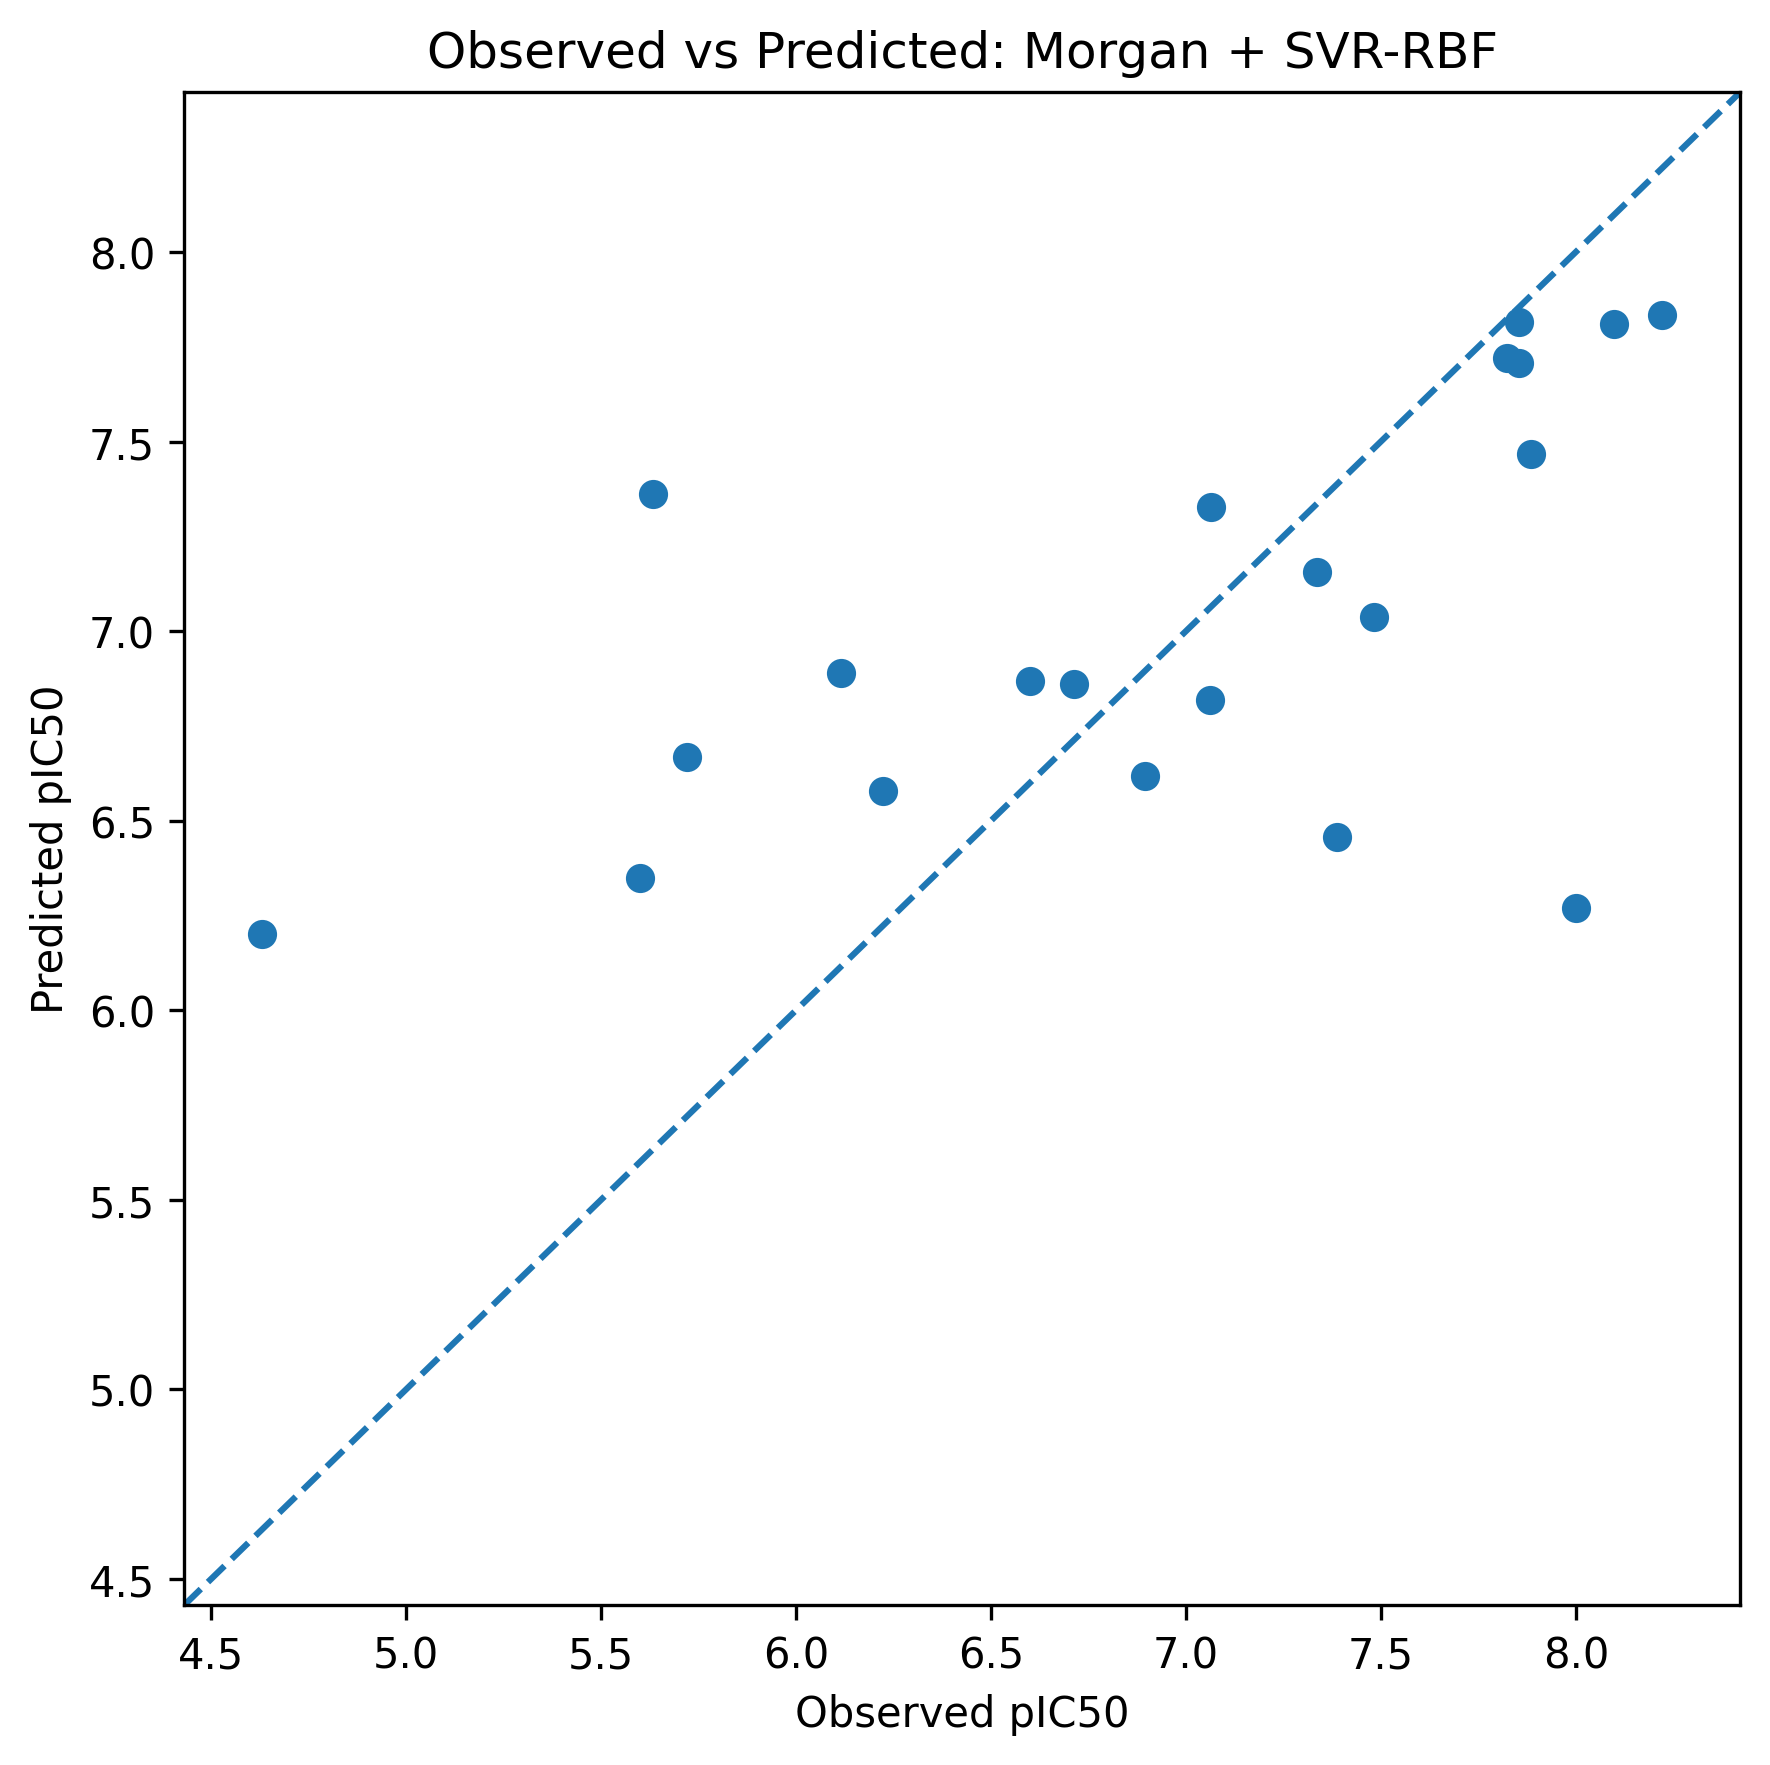


FIGURE: 05_RESIDUAL_VS_PREDICTED.png


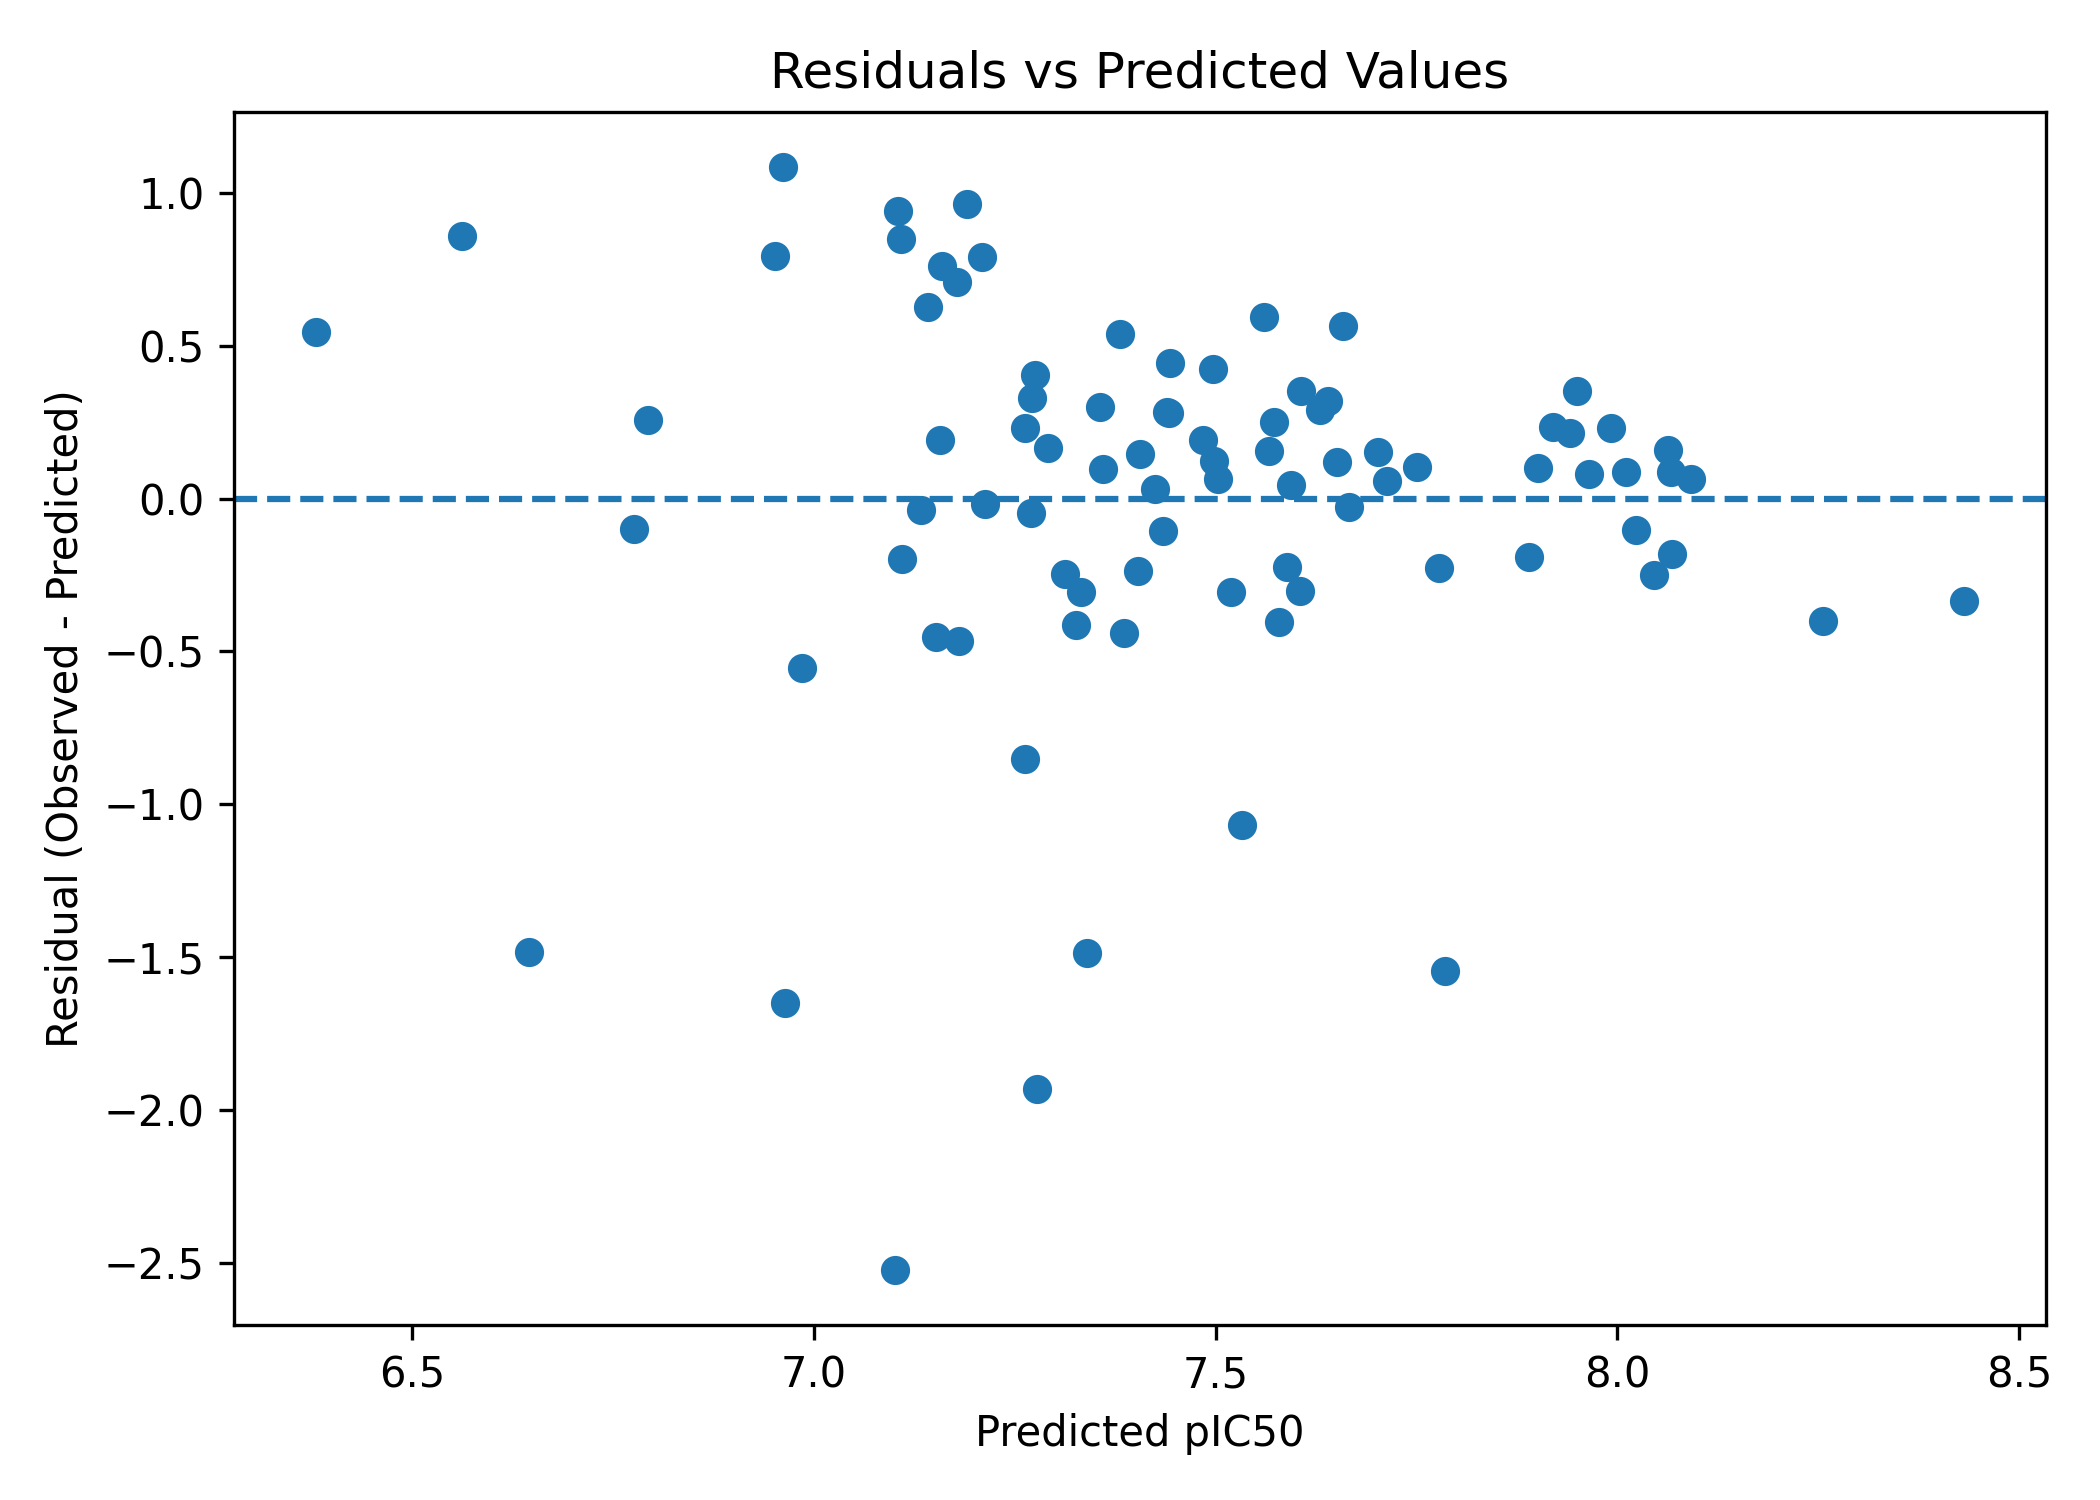


FIGURE: 04_APPLICABILITY_DOMAIN.png


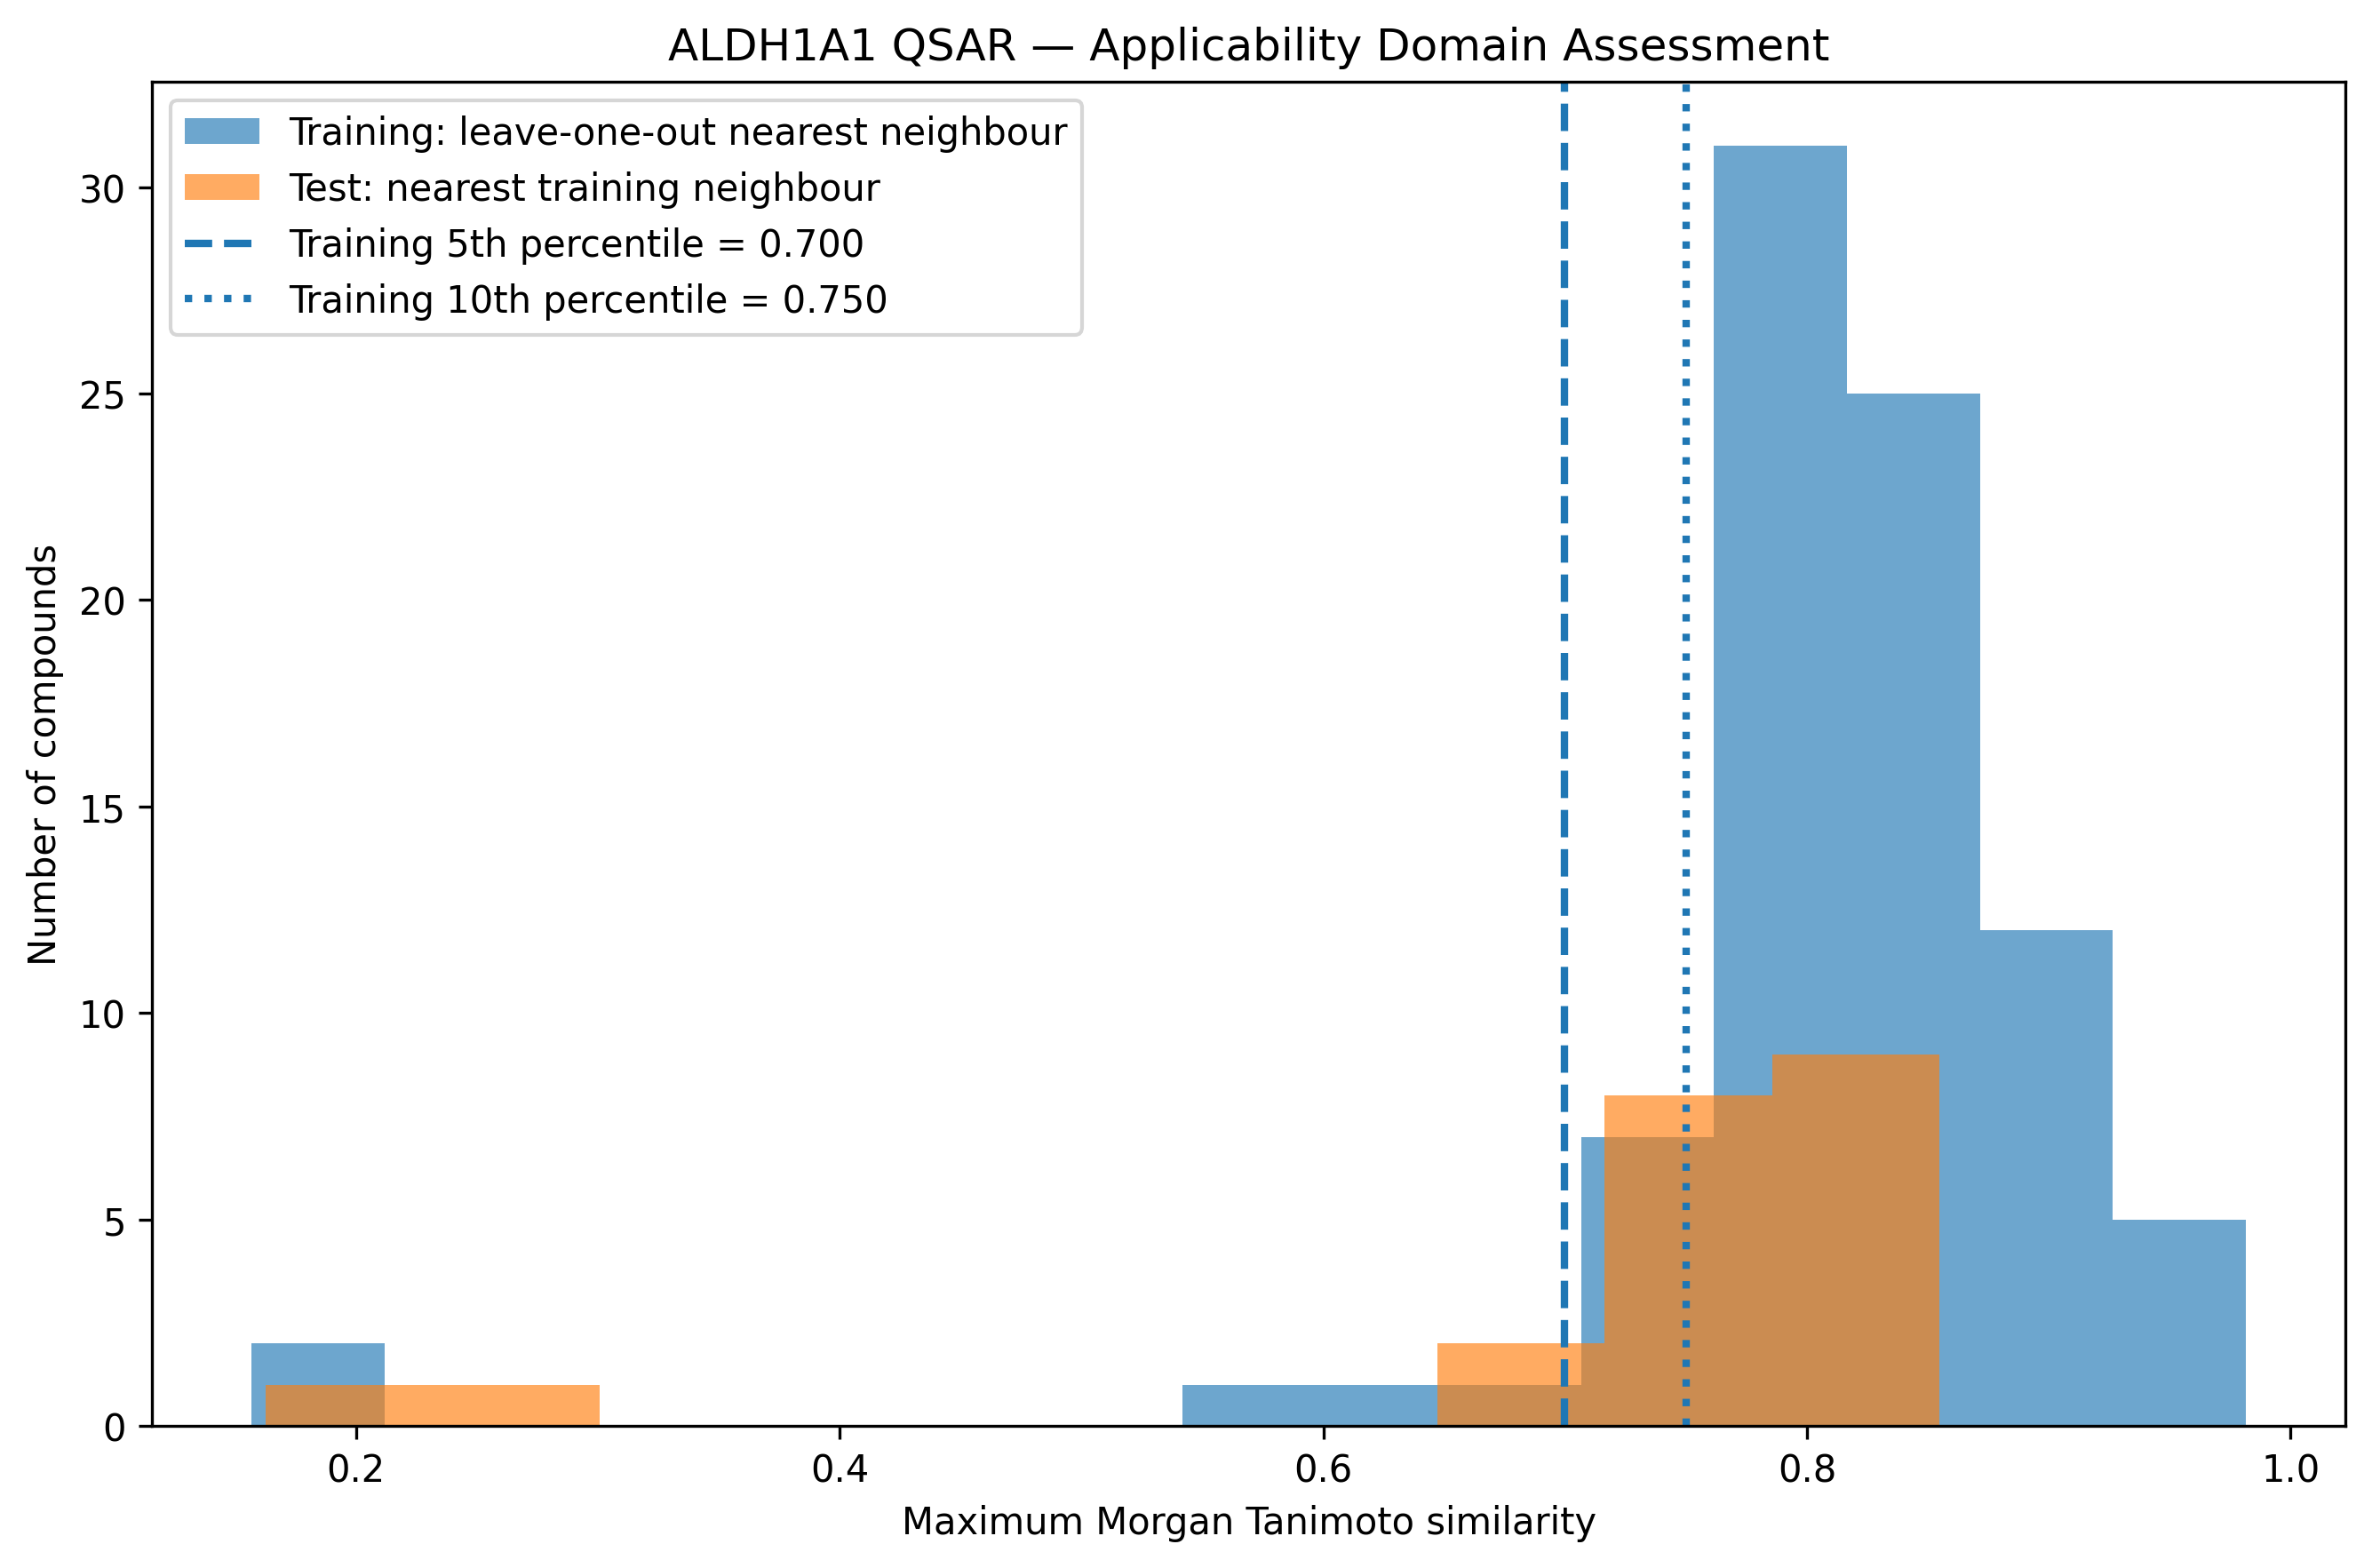


SI MATCH STATUS COUNTS


,Count
SI_match_status,
MATCHED,103
NOT_MATCHED,3



SI-only compounds


,SI_Cpd,Suffix,Source_line
0,43,NaN,43 0.211 ± 0.053 11.7 ± 0.01 15.6 ± 7.34 10.3 ...
1,51,NaN,51 > 57 > 57 > 57 > 57
2,70,NaN,70 0.251 ± 0.017 15.6 ± 7.34 23.4 ± 0.01 20.8 ...
3,72,NaN,72 0.193 ± 0.022 5.44 ± 0.37 13.8 ± 2.48 2.34 ...



PERMUTATION PROGRESS
Shape: (100, 6)
Columns: ['Permutation', 'Best_Model', 'Best_Representation', 'Best_RMSE', 'Candidate_RMSEs_JSON', 'Runtime_Minutes']


,Permutation,Best_Model,Best_Representation,Best_RMSE,Candidate_RMSEs_JSON,Runtime_Minutes
0,1,Ridge,Morgan,0.731951,"[{""Representation"": ""Morgan"", ""Model"": ""Ridge""...",10.378726
1,2,Ridge,Morgan,0.743299,"[{""Representation"": ""Morgan"", ""Model"": ""Ridge""...",10.583590
2,3,SVR_RBF,Descriptor,0.731046,"[{""Representation"": ""Descriptor"", ""Model"": ""SV...",9.674605
3,4,SVR_RBF,Morgan,0.710182,"[{""Representation"": ""Morgan"", ""Model"": ""SVR_RB...",9.713448
4,5,Ridge,Morgan,0.709272,"[{""Representation"": ""Morgan"", ""Model"": ""Ridge""...",9.652953


,Permutation,Best_Model,Best_Representation,Best_RMSE,Candidate_RMSEs_JSON,Runtime_Minutes
95,96,Ridge,Morgan,0.739347,"[{""Representation"": ""Morgan"", ""Model"": ""Ridge""...",11.370814
96,97,GradientBoosting,Morgan,0.724998,"[{""Representation"": ""Morgan"", ""Model"": ""Gradie...",10.319640
97,98,RandomForest,Morgan,0.651099,"[{""Representation"": ""Morgan"", ""Model"": ""Random...",10.174107
98,99,SVR_RBF,Descriptor,0.729791,"[{""Representation"": ""Descriptor"", ""Model"": ""SV...",10.188065
99,100,GradientBoosting,Descriptor,0.737275,"[{""Representation"": ""Descriptor"", ""Model"": ""Gr...",10.379494



DESCRIPTOR SHIFT EVIDENCE FILES
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP08_MANUSCRIPT_READINESS_AUDIT/STEP08_12_DESCRIPTOR_DISTRIBUTION_SHIFT.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP08_MANUSCRIPT_READINESS_AUDIT/STEP08_13_UNDEFINED_SMD_INVESTIGATION.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP08_MANUSCRIPT_READINESS_AUDIT/STEP08_14_TARGET_SMD.csv

PRIMARY DATASET CANDIDATES
02_CURATED_DATA/01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv
02_CURATED_DATA/STEP11_1_SI_PRIMARY_RECONCILIATION.c

In [110]:
# STEP 10.03 — FIGURE EVIDENCE AND VISUAL INSPECTION

import pandas as pd
from pathlib import Path
from PIL import Image
from IPython.display import display

# 1. Inspect the three main reusable figures
figure_dir = PACKAGE / "03_PUBLICATION_FIGURES"

reuse_figures = [
    "01_TEST_MORGAN_SVR_OBSERVED_PREDICTED.png",
    "05_RESIDUAL_VS_PREDICTED.png",
    "04_APPLICABILITY_DOMAIN.png"
]

for filename in reuse_figures:
    path = figure_dir / filename
    print("\nFIGURE:", filename)
    assert path.exists(), f"Missing figure: {path}"
    display(Image.open(path))

# 2. SI reconciliation counts
si = pd.read_csv(
    PACKAGE / "02_CURATED_DATA/STEP11_1_SI_PRIMARY_RECONCILIATION.csv"
)

print("\nSI MATCH STATUS COUNTS")
display(si["SI_match_status"].value_counts(dropna=False).to_frame("Count"))

print("\nSI-only compounds")
si_only = pd.read_csv(
    PACKAGE / "02_CURATED_DATA/STEP06_27_SI_ONLY_COMPOUNDS.csv"
)
display(si_only)

# 3. Inspect permutation progress data
perm_path = (
    PACKAGE / "04_VALIDATION/SELECTION_AWARE_10_MODEL/"
    "STEP14Q_PERMUTATION_PROGRESS.csv"
)

print("\nPERMUTATION PROGRESS")
if perm_path.exists():
    perm = pd.read_csv(perm_path)
    print("Shape:", perm.shape)
    print("Columns:", perm.columns.tolist())
    display(perm.head())
    display(perm.tail())
else:
    print("Permutation progress file not found.")

# 4. Locate descriptor-shift evidence in package AND audit directory
print("\nDESCRIPTOR SHIFT EVIDENCE FILES")

search_roots = [PACKAGE, AUDIT, PHASE09]
matches = []

for root in search_roots:
    if root.exists():
        for p in root.rglob("*"):
            if p.is_file() and any(
                term in p.name.lower()
                for term in [
                    "smd", "descriptor_distribution",
                    "distribution_shift", "08_12"
                ]
            ):
                matches.append(p)

for p in matches:
    print(p)

# 5. Locate primary dataset source
print("\nPRIMARY DATASET CANDIDATES")
for p in PACKAGE.rglob("*.csv"):
    if any(term in p.name.lower() for term in ["primary", "curated", "activity"]):
        print(p.relative_to(PACKAGE))

print("\nSTEP 10.03 COMPLETE")

In [114]:

# ================================================================
# STEP 10.07 — COMPLETE ALDH1A1 QSAR PUBLICATION FIGURE GENERATION
# 6 MAIN FIGURES + 6 SUPPLEMENTARY FIGURES
# 600 DPI | PNG + TIFF + VECTOR PDF
# 1332 x 1200 PX PREVIEW | CONSISTENT PUBLICATION STYLE
# ================================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch
from PIL import Image

# ------------------------------------------------
# 1. OUTPUT DIRECTORY AND PUBLICATION SETTINGS
# ------------------------------------------------

FIG_DIR = FINAL / "03_MANUSCRIPT_FIGURES"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Physical size: 6.66 x 6 inches
# Preview: 200 DPI = 1332 x 1200 px
# Publication raster: 600 DPI = 3996 x 3600 px

FIG_W, FIG_H = 6.66, 6.0
PREVIEW_DPI = 200
PUBLICATION_DPI = 600

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.linewidth": 0.9,
    "lines.linewidth": 1.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white",
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

C = {
    "training": "#0072B2",
    "test": "#D55E00",
    "morgan": "#009E73",
    "descriptor": "#CC79A7",
    "baseline": "#666666",
    "reference": "#333333",
    "grid": "#D9D9D9",
    "gold": "#E69F00"
}

def export_figure(fig, name):
    """Overwrite all exports for one figure."""
    fig.set_size_inches(FIG_W, FIG_H)

    fig.savefig(
        FIG_DIR / f"{name}.png",
        dpi=PUBLICATION_DPI,
        facecolor="white"
    )
    fig.savefig(
        FIG_DIR / f"{name}.tiff",
        dpi=PUBLICATION_DPI,
        facecolor="white",
        pil_kwargs={"compression": "tiff_lzw"}
    )
    fig.savefig(
        FIG_DIR / f"{name}.pdf",
        format="pdf",
        facecolor="white"
    )
    fig.savefig(
        FIG_DIR / f"{name}_PREVIEW.png",
        dpi=PREVIEW_DPI,
        facecolor="white"
    )
    plt.close(fig)

def style_axis(ax):
    ax.grid(axis="y", color=C["grid"], alpha=0.65, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

def finish(fig, title=None):
    if title:
        fig.suptitle(title, fontsize=12, fontweight="bold", y=0.98)
    fig.tight_layout(rect=[0.04, 0.04, 0.96, 0.94])

# ------------------------------------------------
# 2. LOAD VERIFIED SOURCE FILES
# ------------------------------------------------

primary = pd.read_csv(
    PACKAGE / "02_CURATED_DATA/01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv"
)

scaffold = pd.read_csv(
    PACKAGE / "03_MODEL_DEVELOPMENT/07_scaffold_split_assignment.csv"
)

folds = pd.read_csv(
    PACKAGE / "03_MODEL_DEVELOPMENT/01_nested_CV_fold_results.csv"
)

cv_summary = pd.read_csv(
    PACKAGE / "03_MODEL_DEVELOPMENT/02_nested_CV_model_comparison.csv"
)

pred = pd.read_csv(
    PACKAGE / "04_VALIDATION/STEP05_8_TRACEABLE_TEST_SET_PREDICTIONS.csv"
)

train_ad = pd.read_csv(
    PACKAGE / "04_VALIDATION/APPLICABILITY_DOMAIN/02_training_LOO_similarity_reference.csv"
)

test_ad = pd.read_csv(
    PACKAGE / "04_VALIDATION/APPLICABILITY_DOMAIN/05_test_nearest_training_similarity.csv"
)

perm = pd.read_csv(
    PACKAGE / "04_VALIDATION/SELECTION_AWARE_10_MODEL/STEP14Q_PERMUTATION_PROGRESS.csv"
)

perm_summary = pd.read_csv(
    PACKAGE / "04_VALIDATION/SELECTION_AWARE_10_MODEL/STEP14Q_PERMUTATION_SUMMARY.csv"
)

si = pd.read_csv(
    PACKAGE / "02_CURATED_DATA/STEP11_1_SI_PRIMARY_RECONCILIATION.csv"
)

si_only = pd.read_csv(
    PACKAGE / "02_CURATED_DATA/STEP06_27_SI_ONLY_COMPOUNDS.csv"
)

smd_path = AUDIT / "STEP08_12_DESCRIPTOR_DISTRIBUTION_SHIFT.csv"
smd = pd.read_csv(smd_path)

# Integrity checks
assert len(primary) == 106
assert len(scaffold) == 106
assert len(folds) == 50
assert len(cv_summary) == 10
assert len(pred) == 21
assert len(perm) == 100
assert len(si_only) == 4

data = scaffold[["InChIKey", "Split", "Murcko_scaffold"]].merge(
    primary[["InChIKey", "pIC50"]],
    on="InChIKey",
    validate="one_to_one"
)

assert len(data) == 106
assert data["Split"].value_counts()["TRAIN"] == 85
assert data["Split"].value_counts()["TEST"] == 21

# Model configuration labels
folds["Configuration"] = (
    folds["Representation"].str.title() + " — " + folds["Model"]
)
cv_summary["Configuration"] = (
    cv_summary["Representation"].str.title() + " — " + cv_summary["Model"]
)

cv_summary = cv_summary.sort_values(
    "Nested_CV_RMSE_Mean"
).reset_index(drop=True)

config_order = cv_summary["Configuration"].tolist()

# Applicability-domain similarity columns
def find_similarity_column(df):
    candidates = [
        col for col in df.columns
        if "tanimoto" in col.lower() or "similarity" in col.lower()
    ]
    for col in candidates:
        if pd.api.types.is_numeric_dtype(df[col]):
            return col
    raise ValueError(
        f"No numeric similarity column found. Columns: {df.columns.tolist()}"
    )

train_sim_col = find_similarity_column(train_ad)
test_sim_col = find_similarity_column(test_ad)

training_similarity = train_ad[train_sim_col].dropna().astype(float)
test_similarity = test_ad[test_sim_col].dropna().astype(float)

AD_THRESHOLD = float(np.percentile(training_similarity, 5))

# Test predictions
observed = pred["pIC50"].astype(float)
predicted = pred["Morgan_plus_SVR-RBF"].astype(float)
residual = observed - predicted

# Training-derived IQR outlier limits
train_values = data.loc[data["Split"] == "TRAIN", "pIC50"]
test_values = data.loc[data["Split"] == "TEST", "pIC50"]

q1, q3 = train_values.quantile([0.25, 0.75])
iqr = q3 - q1
LOWER_IQR = q1 - 1.5 * iqr
UPPER_IQR = q3 + 1.5 * iqr

# ------------------------------------------------
# FIGURE 1 — STUDY WORKFLOW
# ------------------------------------------------

fig, ax = plt.subplots()
ax.set_xlim(0, 10)
ax.set_ylim(0, 12)
ax.axis("off")

def workflow_box(x, y, w, h, label, color):
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.12",
        edgecolor=color,
        facecolor="white",
        linewidth=1.5
    )
    ax.add_patch(patch)
    ax.text(
        x+w/2, y+h/2, label,
        ha="center", va="center", fontsize=8.5
    )

def arrow(x1, y1, x2, y2):
    ax.annotate(
        "", xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="-|>",
            color=C["reference"],
            lw=1.3
        )
    )

workflow_box(1.2, 10.3, 7.6, 1.0,
             "106 exact biochemical human ALDH1A1 IC50 records",
             C["training"])

workflow_box(1.2, 8.5, 7.6, 1.0,
             "Data curation and structure standardisation\nCHEMBL3577 | IC50 endpoint",
             C["training"])

workflow_box(1.2, 6.7, 7.6, 1.0,
             "Scaffold-based split\n85 training compounds | 21 test compounds",
             C["training"])

workflow_box(0.3, 4.5, 4.2, 1.1,
             "Molecular descriptors\n169 features", C["descriptor"])

workflow_box(5.5, 4.5, 4.2, 1.1,
             "Morgan fingerprints\n2048 bits | Radius 2", C["morgan"])

workflow_box(1.2, 2.5, 7.6, 1.0,
             "Nested cross-validation\n5 outer folds | 4 inner folds",
             C["gold"])

workflow_box(1.2, 0.5, 7.6, 1.0,
             "Held-out evaluation, residual analysis\nand applicability-domain assessment",
             C["test"])

arrow(5, 10.3, 5, 9.5)
arrow(5, 8.5, 5, 7.7)
arrow(5, 6.7, 2.4, 5.6)
arrow(5, 6.7, 7.6, 5.6)
arrow(2.4, 4.5, 4.2, 3.5)
arrow(7.6, 4.5, 5.8, 3.5)
arrow(5, 2.5, 5, 1.5)

finish(fig, "ALDH1A1 QSAR study workflow")
export_figure(fig, "Figure_1_Study_Workflow")

# ------------------------------------------------
# FIGURE 2 — DATASET PROFILE
# ------------------------------------------------

fig, axes = plt.subplots(1, 2)

axes[0].hist(
    train_values, bins=12, alpha=0.78,
    color=C["training"], label="Training (n=85)"
)
axes[0].hist(
    test_values, bins=12, alpha=0.78,
    color=C["test"], label="Test (n=21)"
)
axes[0].set_xlabel("pIC50")
axes[0].set_ylabel("Number of compounds")
axes[0].set_title("Activity distribution")
axes[0].legend(frameon=False)
style_axis(axes[0])

bp = axes[1].boxplot(
    [train_values, test_values],
    labels=["Training\n(n=85)", "Test\n(n=21)"],
    patch_artist=True,
    showfliers=False
)

for box, color in zip(bp["boxes"], [C["training"], C["test"]]):
    box.set_facecolor(color)
    box.set_alpha(0.3)

for i, values in enumerate([train_values, test_values], 1):
    axes[1].scatter(
        np.full(len(values), i), values,
        color=[C["training"], C["test"]][i-1],
        s=17, alpha=0.8, edgecolor="white", linewidth=0.3
    )

axes[1].set_ylabel("pIC50")
axes[1].set_title("Training–test comparison")
style_axis(axes[1])

finish(fig, "ALDH1A1 dataset activity profile")
export_figure(fig, "Figure_2_Dataset_Profile")

# ------------------------------------------------
# FIGURE 3 — NESTED CV MODEL COMPARISON
# ------------------------------------------------

fig, axes = plt.subplots(1, 2)
y = np.arange(len(cv_summary))

for ax, mean_col, sd_col, label in [
    (axes[0], "Nested_CV_RMSE_Mean", "Nested_CV_RMSE_SD", "RMSE"),
    (axes[1], "Nested_CV_MAE_Mean", "Nested_CV_MAE_SD", "MAE")
]:
    for i, row in cv_summary.iterrows():
        color = (
            C["training"]
            if row["Representation"] == "DESCRIPTORS"
            else C["morgan"]
        )
        ax.errorbar(
            row[mean_col], i,
            xerr=row[sd_col],
            fmt="o", color=color,
            capsize=3, markersize=5
        )

    ax.set_yticks(y)
    ax.set_yticklabels(config_order, fontsize=7)
    ax.invert_yaxis()
    ax.set_xlabel(f"Nested-CV {label} (pIC50 units)")
    ax.set_title(label)
    style_axis(ax)

finish(fig, "Nested cross-validation model comparison")
export_figure(fig, "Figure_3_Nested_CV_Model_Comparison")

# ------------------------------------------------
# FIGURE 4 — HELD-OUT TEST PARITY PLOT
# ------------------------------------------------

fig, ax = plt.subplots()

ax.scatter(
    observed, predicted,
    color=C["morgan"], edgecolor="white",
    linewidth=0.6, s=43, alpha=0.9
)

lims = [
    min(observed.min(), predicted.min()) - 0.2,
    max(observed.max(), predicted.max()) + 0.2
]

ax.plot(lims, lims, "--", color=C["reference"],
        label="Identity line")

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Observed pIC50")
ax.set_ylabel("Predicted pIC50")
ax.set_title("Morgan SVR — held-out test set")
ax.legend(frameon=False)
style_axis(ax)

finish(fig, "Held-out test-set prediction performance")
export_figure(fig, "Figure_4_Morgan_SVR_Test_Parity")

# ------------------------------------------------
# FIGURE 5 — TEST RESIDUAL DIAGNOSTICS
# ------------------------------------------------

fig, axes = plt.subplots(1, 2)

axes[0].scatter(
    predicted, residual,
    color=C["morgan"], edgecolor="white",
    linewidth=0.5, s=40
)
axes[0].axhline(0, color=C["reference"], linestyle="--")
axes[0].set_xlabel("Predicted pIC50")
axes[0].set_ylabel("Residual (observed − predicted)")
axes[0].set_title("Residuals versus predictions")
style_axis(axes[0])

axes[1].hist(
    residual, bins=9,
    color=C["morgan"], alpha=0.8,
    edgecolor="white"
)
axes[1].axvline(0, color=C["reference"], linestyle="--")
axes[1].set_xlabel("Residual (pIC50 units)")
axes[1].set_ylabel("Number of compounds")
axes[1].set_title("Residual distribution")
style_axis(axes[1])

finish(fig, "Morgan SVR held-out test residual diagnostics")
export_figure(fig, "Figure_5_Test_Residual_Diagnostics")

# ------------------------------------------------
# FIGURE 6 — APPLICABILITY DOMAIN
# ------------------------------------------------

fig, ax = plt.subplots()

ax.hist(
    training_similarity, bins=16,
    color=C["training"], alpha=0.65,
    density=True, label="Training leave-one-out"
)

ax.hist(
    test_similarity, bins=12,
    color=C["test"], alpha=0.65,
    density=True, label="Test nearest-training similarity"
)

ax.axvline(
    AD_THRESHOLD,
    color=C["reference"],
    linestyle="--",
    linewidth=1.5,
    label=f"Training 5th percentile = {AD_THRESHOLD:.3f}"
)

ax.set_xlabel("Nearest-training-neighbour Morgan Tanimoto similarity")
ax.set_ylabel("Density")
ax.set_title("Fingerprint-based applicability domain")
ax.legend(frameon=False, fontsize=7)
style_axis(ax)

finish(fig, "Morgan fingerprint applicability-domain assessment")
export_figure(fig, "Figure_6_Applicability_Domain")

# ------------------------------------------------
# FIGURE S1 — NESTED CV RMSE BY FOLD
# ------------------------------------------------

rmse_matrix = (
    folds.pivot(
        index="Configuration",
        columns="Outer_Fold",
        values="RMSE"
    )
    .reindex(config_order)
)

fig, ax = plt.subplots()

im = ax.imshow(
    rmse_matrix.values,
    aspect="auto",
    cmap="viridis"
)

ax.set_xticks(np.arange(len(rmse_matrix.columns)))
ax.set_xticklabels([f"Fold {x}" for x in rmse_matrix.columns])
ax.set_yticks(np.arange(len(config_order)))
ax.set_yticklabels(config_order, fontsize=7)

for i in range(rmse_matrix.shape[0]):
    for j in range(rmse_matrix.shape[1]):
        ax.text(
            j, i, f"{rmse_matrix.iloc[i, j]:.2f}",
            ha="center", va="center",
            color="white", fontsize=7
        )

ax.set_xlabel("Outer fold")
ax.set_title("Fold-wise nested-CV RMSE")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("RMSE (pIC50 units)")

finish(fig)
export_figure(fig, "Figure_S1_Nested_CV_RMSE_By_Fold")

# ------------------------------------------------
# FIGURE S2 — NESTED CV MAE AND R2 BY FOLD
# ------------------------------------------------

fig, axes = plt.subplots(1, 2)

markers = {1: "o", 2: "s", 3: "^", 4: "D", 5: "P"}

for ax, metric, xlabel in [
    (axes[0], "MAE", "Outer-fold MAE"),
    (axes[1], "R2", "Outer-fold R²")
]:
    for i, config in enumerate(config_order):
        sub = folds[folds["Configuration"] == config]
        color = (
            C["training"]
            if sub["Representation"].iloc[0] == "DESCRIPTORS"
            else C["morgan"]
        )

        for _, row in sub.iterrows():
            ax.scatter(
                row[metric], i,
                marker=markers[int(row["Outer_Fold"])],
                color=color, s=28,
                edgecolor="white", linewidth=0.3
            )

    ax.set_yticks(np.arange(len(config_order)))
    ax.set_yticklabels(config_order, fontsize=7)
    ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    style_axis(ax)

axes[0].set_title("Fold-wise MAE")
axes[1].set_title("Fold-wise R²")
axes[1].axvline(0, color=C["reference"], linestyle="--")

finish(fig, "Nested cross-validation fold-level diagnostics")
export_figure(fig, "Figure_S2_Nested_CV_MAE_R2_By_Fold")

# ------------------------------------------------
# FIGURE S3 — ACTIVITY DISTRIBUTION AND IQR FLAGS
# ------------------------------------------------

fig, axes = plt.subplots(1, 2)

for values, color, label in [
    (train_values, C["training"], "Training"),
    (test_values, C["test"], "Test")
]:
    axes[0].hist(
        values, bins=12, alpha=0.65,
        color=color, label=label
    )

axes[0].axvline(LOWER_IQR, color=C["reference"],
                linestyle="--", label="Training IQR lower bound")
axes[0].set_xlabel("pIC50")
axes[0].set_ylabel("Number of compounds")
axes[0].set_title("Activity distribution")
axes[0].legend(frameon=False, fontsize=7)
style_axis(axes[0])

for split, color, xpos in [
    ("TRAIN", C["training"], 1),
    ("TEST", C["test"], 2)
]:
    vals = data.loc[data["Split"] == split, "pIC50"]
    flagged = vals[(vals < LOWER_IQR) | (vals > UPPER_IQR)]
    normal = vals[(vals >= LOWER_IQR) & (vals <= UPPER_IQR)]

    axes[1].scatter(
        np.full(len(normal), xpos), normal,
        color=color, s=18, alpha=0.65
    )
    axes[1].scatter(
        np.full(len(flagged), xpos), flagged,
        facecolors="none", edgecolors=C["gold"],
        s=65, linewidth=1.4,
        label=f"{split.title()} IQR flags"
    )

axes[1].axhline(LOWER_IQR, color=C["reference"], linestyle="--")
axes[1].axhline(UPPER_IQR, color=C["reference"], linestyle=":")
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(["Training (85)", "Test (21)"])
axes[1].set_ylabel("pIC50")
axes[1].set_title("Training-derived IQR flags")
axes[1].legend(frameon=False, fontsize=7)
style_axis(axes[1])

finish(fig, "Activity distribution and statistical outlier flags")
export_figure(fig, "Figure_S3_Activity_Distribution_Outliers")

# ------------------------------------------------
# FIGURE S4 — DESCRIPTOR DISTRIBUTION SHIFT
# ------------------------------------------------

smd_col = next(
    (c for c in smd.columns if "smd" in c.lower()),
    None
)

descriptor_col = next(
    (c for c in smd.columns
     if c != smd_col and
     any(x in c.lower() for x in ["descriptor", "feature", "name"])),
    None
)

if smd_col is None or descriptor_col is None:
    raise ValueError(
        "Could not identify descriptor and SMD columns. "
        f"Available columns: {smd.columns.tolist()}"
    )

smd_plot = smd[[descriptor_col, smd_col]].copy()
smd_plot[smd_col] = pd.to_numeric(smd_plot[smd_col], errors="coerce")
smd_plot = smd_plot.dropna()
smd_plot["Abs_SMD"] = smd_plot[smd_col].abs()
smd_plot = smd_plot.sort_values("Abs_SMD").tail(20)

fig, ax = plt.subplots()

colors = [
    C["test"] if value >= 0 else C["training"]
    for value in smd_plot[smd_col]
]

ax.barh(
    smd_plot[descriptor_col].astype(str),
    smd_plot[smd_col],
    color=colors, alpha=0.85
)

ax.axvline(0, color=C["reference"], linewidth=0.9)
ax.set_xlabel("Standardised mean difference (SMD)")
ax.set_ylabel("Molecular descriptor")
ax.set_title("Twenty descriptors with largest absolute SMD")
style_axis(ax)

finish(fig, "Descriptor distribution shift between training and test sets")
export_figure(fig, "Figure_S4_Descriptor_Distribution_Shift")

# ------------------------------------------------
# FIGURE S5 — SELECTION-AWARE Y-RANDOMISATION
# ------------------------------------------------

observed_rmse = float(
    perm_summary["Observed_BestOf10_RMSE"].iloc[0]
)
null_mean = float(
    perm_summary["Null_Mean_BestOf10_RMSE"].iloc[0]
)
null_sd = float(
    perm_summary["Null_SD_BestOf10_RMSE"].iloc[0]
)
empirical_p = float(
    perm_summary["Empirical_P_Value"].iloc[0]
)

fig, ax = plt.subplots()

ax.hist(
    perm["Best_RMSE"].astype(float),
    bins=14,
    color=C["descriptor"],
    edgecolor="white",
    alpha=0.85
)

ax.axvline(
    observed_rmse, color=C["test"],
    linewidth=2, linestyle="--",
    label=f"Observed best RMSE = {observed_rmse:.3f}"
)

ax.axvline(
    null_mean, color=C["reference"],
    linewidth=1.5, linestyle=":",
    label=f"Null mean = {null_mean:.3f}"
)

ax.set_xlabel("Best-of-10 permutation RMSE (pIC50 units)")
ax.set_ylabel("Number of permutations")
ax.set_title(
    f"Selection-aware Y-randomisation\n"
    f"100 permutations | Empirical p = {empirical_p:.4f}"
)
ax.legend(frameon=False, fontsize=7)
style_axis(ax)

finish(fig)
export_figure(fig, "Figure_S5_Selection_Aware_Y_Randomisation")

# ------------------------------------------------
# FIGURE S6 — SI STRUCTURE RECONCILIATION
# ------------------------------------------------

matched = int((si["SI_match_status"] == "MATCHED").sum())
unmatched_primary = int((si["SI_match_status"] == "NOT_MATCHED").sum())
si_only_count = len(si_only)

fig, ax = plt.subplots()

labels = [
    "Exact primary–SI\nstructure matches",
    "Unmatched primary\ncompounds",
    "SI-only\ncompounds"
]
values = [matched, unmatched_primary, si_only_count]
bar_colors = [C["training"], C["test"], C["gold"]]

bars = ax.bar(labels, values, color=bar_colors, width=0.62)

for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        str(value),
        ha="center", va="bottom",
        fontsize=10, fontweight="bold"
    )

ax.set_ylabel("Number of compounds")
ax.set_title("Primary dataset and supplementary information reconciliation")
ax.set_ylim(0, max(values) * 1.2)
style_axis(ax)

finish(fig)
export_figure(fig, "Figure_S6_SI_Structure_Reconciliation")

# ------------------------------------------------
# 3. VERIFY ALL EXPORTS AND CREATE MANIFEST
# ------------------------------------------------

figure_names = [
    "Figure_1_Study_Workflow",
    "Figure_2_Dataset_Profile",
    "Figure_3_Nested_CV_Model_Comparison",
    "Figure_4_Morgan_SVR_Test_Parity",
    "Figure_5_Test_Residual_Diagnostics",
    "Figure_6_Applicability_Domain",
    "Figure_S1_Nested_CV_RMSE_By_Fold",
    "Figure_S2_Nested_CV_MAE_R2_By_Fold",
    "Figure_S3_Activity_Distribution_Outliers",
    "Figure_S4_Descriptor_Distribution_Shift",
    "Figure_S5_Selection_Aware_Y_Randomisation",
    "Figure_S6_SI_Structure_Reconciliation"
]

manifest = []

for name in figure_names:
    for ext in [".png", ".tiff", ".pdf", "_PREVIEW.png"]:
        path = FIG_DIR / f"{name}{ext}"
        assert path.exists(), f"Missing export: {path}"

        row = {
            "Figure": name,
            "File": path.name,
            "Size_MB": round(path.stat().st_size / 1024**2, 3),
            "Format": ext
        }

        if ext == "_PREVIEW.png":
            with Image.open(path) as im:
                row["Width_px"] = im.width
                row["Height_px"] = im.height
                assert im.size == (1332, 1200)
        else:
            row["Width_px"] = None
            row["Height_px"] = None

        manifest.append(row)

manifest_df = pd.DataFrame(manifest)
manifest_path = FIG_DIR / "FIGURE_EXPORT_MANIFEST.csv"
manifest_df.to_csv(manifest_path, index=False)

print("=" * 65)
print("ALDH1A1 QSAR PUBLICATION FIGURES — COMPLETE")
print("=" * 65)
print("Main figures: 6")
print("Supplementary figures: 6")
print("Total figures: 12")
print("Files per figure: 4")
print("Total exports: 48")
print("Preview dimensions: 1332 x 1200 px")
print("Publication raster: 600 DPI")
print("Publication raster dimensions: 3996 x 3600 px")
print("Formats: PNG, TIFF, PDF + preview PNG")
print("All preview dimensions verified: PASS")
print("Output directory:", FIG_DIR)
print("Manifest:", manifest_path)
print("\nSTEP 10.07 COMPLETE")


/tmp/ipykernel_2803/3103934705.py:311: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(


AssertionError: 

In [115]:
# STEP 10.08 — REPAIR PREVIEW DIMENSIONS AND VERIFY ALL FIGURES

from PIL import Image, ImageOps
import pandas as pd

TARGET_SIZE = (1332, 1200)

figure_names = [
    "Figure_1_Study_Workflow",
    "Figure_2_Dataset_Profile",
    "Figure_3_Nested_CV_Model_Comparison",
    "Figure_4_Morgan_SVR_Test_Parity",
    "Figure_5_Test_Residual_Diagnostics",
    "Figure_6_Applicability_Domain",
    "Figure_S1_Nested_CV_RMSE_By_Fold",
    "Figure_S2_Nested_CV_MAE_R2_By_Fold",
    "Figure_S3_Activity_Distribution_Outliers",
    "Figure_S4_Descriptor_Distribution_Shift",
    "Figure_S5_Selection_Aware_Y_Randomisation",
    "Figure_S6_SI_Structure_Reconciliation"
]

manifest = []

for name in figure_names:
    preview = FIG_DIR / f"{name}_PREVIEW.png"

    assert preview.exists(), f"Missing preview: {preview}"

    with Image.open(preview) as im:
        im = im.convert("RGB")
        fixed = ImageOps.pad(
            im,
            TARGET_SIZE,
            method=Image.Resampling.LANCZOS,
            color="white",
            centering=(0.5, 0.5)
        )
        fixed.save(preview, dpi=(200, 200))

    with Image.open(preview) as check:
        assert check.size == TARGET_SIZE

    for ext in [".png", ".tiff", ".pdf"]:
        path = FIG_DIR / f"{name}{ext}"
        assert path.exists(), f"Missing publication export: {path}"

        if ext in [".png", ".tiff"]:
            with Image.open(path) as im:
                width, height = im.size
        else:
            width, height = None, None

        manifest.append({
            "Figure": name,
            "File": path.name,
            "Width_px": width,
            "Height_px": height,
            "Format": ext
        })

    manifest.append({
        "Figure": name,
        "File": preview.name,
        "Width_px": TARGET_SIZE[0],
        "Height_px": TARGET_SIZE[1],
        "Format": "Preview PNG"
    })

manifest_df = pd.DataFrame(manifest)

manifest_path = FIG_DIR / "FIGURE_EXPORT_MANIFEST.csv"
manifest_df.to_csv(manifest_path, index=False)

print("FIGURES VERIFIED:", len(figure_names))
print("TOTAL EXPORT FILES:", len(manifest_df))
print("Preview dimensions: 1332 × 1200 px")
print("Publication raster: 600 DPI")
print("Formats: PNG, TIFF, PDF")
print("Missing files: 0")
print("Dimension verification: PASS")
print("Manifest:", manifest_path)
print("STEP 10.08 COMPLETE")

FIGURES VERIFIED: 12
TOTAL EXPORT FILES: 48
Preview dimensions: 1332 × 1200 px
Publication raster: 600 DPI
Formats: PNG, TIFF, PDF
Missing files: 0
Dimension verification: PASS
Manifest: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/03_MANUSCRIPT_FIGURES/FIGURE_EXPORT_MANIFEST.csv
STEP 10.08 COMPLETE


In [116]:

# ================================================================
# STEP 10.09 — ALDH1A1 QSAR SUPERVISOR REVIEW PACKAGE
# REVIEW HANDOFF ONLY — NOT FINAL MANUSCRIPT SUBMISSION
# ================================================================

import shutil
import zipfile
import hashlib
import json
import pandas as pd

from pathlib import Path
from datetime import datetime

# ------------------------------------------------
# 1. DEFINE OUTPUT
# ------------------------------------------------

REVIEW_DIR = FINAL / "ALDH1A1_QSAR_SUPERVISOR_REVIEW"
REVIEW_ZIP = FINAL / "ALDH1A1_QSAR_SUPERVISOR_REVIEW.zip"

if REVIEW_DIR.exists():
    shutil.rmtree(REVIEW_DIR)

REVIEW_DIR.mkdir(parents=True)

FOLDERS = {
    "readme": REVIEW_DIR / "00_READ_ME_FIRST",
    "primary": REVIEW_DIR / "01_PRIMARY_DATA",
    "models": REVIEW_DIR / "02_MODEL_RESULTS",
    "validation": REVIEW_DIR / "03_VALIDATION_AND_APPLICABILITY",
    "supplement": REVIEW_DIR / "04_SUPPLEMENTARY_DATA",
    "figures": REVIEW_DIR / "05_PUBLICATION_FIGURES",
    "audit": REVIEW_DIR / "06_AUDIT_AND_LIMITATIONS"
}

for folder in FOLDERS.values():
    folder.mkdir(parents=True, exist_ok=True)

copied = []
missing = []

def add_file(source, destination_folder, new_name=None):
    source = Path(source)

    if not source.exists() or not source.is_file():
        missing.append(str(source))
        return False

    destination = destination_folder / (
        new_name if new_name else source.name
    )

    shutil.copy2(source, destination)
    copied.append(destination)
    return True

def add_package_file(relative_path, folder, new_name=None):
    add_file(PACKAGE / relative_path, folder, new_name)

# ------------------------------------------------
# 2. README — REVIEW INSTRUCTIONS
# ------------------------------------------------

readme = """
# ALDH1A1 QSAR — SUPERVISOR REVIEW PACKAGE

## Purpose

This package is prepared for preliminary scientific review
of the ALDH1A1 QSAR research.

It is intended for the supervisor to examine the dataset,
modelling methodology, validation results, supplementary
evidence, figures and documented limitations.

THIS IS NOT A FINAL MANUSCRIPT OR PUBLICATION PACKAGE.

## Research overview

Target: Human aldehyde dehydrogenase 1 family member A1
Target identifier: CHEMBL3577
UniProt: P00352

Primary endpoint: Biochemical IC50
Primary assay: CHEMBL4189991
Primary document: CHEMBL4184337

Primary curated dataset: 106 compounds.

Scaffold-based partition:
- Training: 85 compounds
- Held-out test: 21 compounds

Molecular representations:
- 169 molecular descriptors
- Morgan fingerprints: radius 2, 2048 bits

Model development:
- Five model families
- Ten representation/model configurations
- Nested cross-validation: five outer folds and four inner folds

## Important results for review

Original nested-CV best configuration:
Morgan fingerprint SVR-RBF.

Mean nested-CV RMSE: 0.636888
Mean nested-CV MAE: 0.450840
Mean nested-CV R2: -0.166139

Held-out test Morgan SVR:
RMSE: 0.770259
MAE: 0.570997
R2: 0.370904
Pearson correlation: 0.618466
Spearman correlation: 0.594349

These are different evaluation procedures and must not
be treated as interchangeable.

## Scientific limitations

1. The 21-compound test set is an internal scaffold-based
   holdout, not independent external validation.

2. All ten configurations had negative mean outer-fold R2
   in the original nested-CV analysis.

3. Independent experimental validation has not been performed.

4. Original cross-validation training code was not recovered.
   Fold-specific preprocessing could not be independently
   verified. This does not establish that data leakage occurred.

5. Applicability-domain limitations must be considered when
   interpreting predictions.

6. This study should currently be interpreted as exploratory
   retrospective QSAR research.

## Folder guide

01_PRIMARY_DATA:
Curated activity dataset and scaffold assignments.

02_MODEL_RESULTS:
Nested-CV fold results and model comparison summaries.

03_VALIDATION_AND_APPLICABILITY:
Held-out test predictions, applicability-domain evidence
and selection-aware Y-randomisation results.

04_SUPPLEMENTARY_DATA:
SI reconciliation, descriptor distribution audits,
permutation records and supporting data.

05_PUBLICATION_FIGURES:
Available main and supplementary figures.

06_AUDIT_AND_LIMITATIONS:
Manuscript-readiness report, audit status register
and documented methodological limitations.

## Review requested

Please review:
- Dataset suitability and activity curation.
- Endpoint and assay consistency.
- Scaffold split and model selection.
- Nested-CV and held-out test performance.
- Applicability domain.
- Randomisation analysis.
- Scientific interpretation and limitations.
- Suitability of figures and supplementary data.

No further model refitting or scientific finalisation
is implied by this handoff.

Prepared: """ + datetime.now().strftime("%Y-%m-%d") + "\n"

(FOLDERS["readme"] / "README_FIRST.md").write_text(
    readme, encoding="utf-8"
)

# ------------------------------------------------
# 3. PRIMARY DATA
# ------------------------------------------------

primary_files = [
    "02_CURATED_DATA/01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv",
    "03_MODEL_DEVELOPMENT/07_scaffold_split_assignment.csv",
    "04_VALIDATION/STEP05_8_TRACEABLE_TEST_SET_PREDICTIONS.csv"
]

for f in primary_files:
    add_package_file(f, FOLDERS["primary"])

# ------------------------------------------------
# 4. MODEL RESULTS
# ------------------------------------------------

model_files = [
    "03_MODEL_DEVELOPMENT/01_nested_CV_fold_results.csv",
    "03_MODEL_DEVELOPMENT/02_nested_CV_model_comparison.csv",
    "04_VALIDATION/STEP05_4_NESTED_CV_STRUCTURE_AUDIT.csv",
    "04_VALIDATION/STEP05_4_NESTED_VS_FINAL_CV_COMPARISON.csv"
]

for f in model_files:
    add_package_file(f, FOLDERS["models"])

# ------------------------------------------------
# 5. VALIDATION AND APPLICABILITY
# ------------------------------------------------

validation_files = [
    "04_VALIDATION/APPLICABILITY_DOMAIN/02_training_LOO_similarity_reference.csv",
    "04_VALIDATION/APPLICABILITY_DOMAIN/05_test_nearest_training_similarity.csv",
    "04_VALIDATION/SELECTION_AWARE_10_MODEL/STEP14Q_PERMUTATION_SUMMARY.csv",
    "04_VALIDATION/SELECTION_AWARE_10_MODEL/STEP14Q_PERMUTATION_PROGRESS.csv",
    "04_VALIDATION/DEDICATED_MORGAN_SVR/Y_RANDOMISATION_100_PROGRESS.csv"
]

for f in validation_files:
    add_package_file(f, FOLDERS["validation"])

# ------------------------------------------------
# 6. SUPPLEMENTARY DATA
# ------------------------------------------------

supplement_files = [
    "02_CURATED_DATA/STEP11_1_SI_PRIMARY_RECONCILIATION.csv",
    "02_CURATED_DATA/STEP11_2_SI_ACTIVITY_AGREEMENT_AUDIT.csv",
    "02_CURATED_DATA/STEP11_3_UNMATCHED_PRIMARY_COMPOUNDS.csv",
    "02_CURATED_DATA/STEP06_27_SI_ONLY_COMPOUNDS.csv",
    "05_CHEMICAL_INTERPRETATION/10_global_activity_cliff_candidates.csv",
    "05_CHEMICAL_INTERPRETATION/11_activity_cliff_source_audit.csv",
    "05_CHEMICAL_INTERPRETATION/12_activity_cliff_assay_provenance_audit.csv"
]

for f in supplement_files:
    add_package_file(f, FOLDERS["supplement"])

audit_files = [
    "STEP08_03_MISSING_VALUE_AUDIT.csv",
    "STEP08_03_DUPLICATE_STRUCTURE_AUDIT.csv",
    "STEP08_04_ENDPOINT_CONSISTENCY_CHECKS.csv",
    "STEP08_05_FEATURE_INTEGRITY_CHECKS.csv",
    "STEP08_12_DESCRIPTOR_DISTRIBUTION_SHIFT.csv",
    "STEP08_13_UNDEFINED_SMD_INVESTIGATION.csv",
    "STEP08_14_TARGET_SMD.csv",
    "STEP08_15_TARGET_IQR_OUTLIER_AUDIT.csv",
    "STEP08_16_FLAGGED_COMPOUND_TRACEABILITY.csv",
    "STEP08_19_TEST_RESIDUAL_BIAS_AUDIT.csv",
    "STEP08_20_TEST_METRICS_RECALCULATED.csv",
    "STEP08_25_FINAL_AUDIT_STATUS_REGISTER.csv",
    "STEP08_27_PREPROCESSING_PROVENANCE_LIMITATION.json",
    "STEP08_27_PREPROCESSING_PROVENANCE_LIMITATION.csv",
    "STEP08_28_PHASE08_CLOSURE.json"
]

for f in audit_files:
    add_file(AUDIT / f, FOLDERS["audit"])

# Include the manuscript-readiness report
add_file(
    PHASE09 / "STEP09_02_MANUSCRIPT_READINESS_REPORT.md",
    FOLDERS["audit"]
)

# ------------------------------------------------
# 7. FIGURES — PREFER NEW FIGURES
# ------------------------------------------------

figure_names = [
    "Figure_1_Study_Workflow",
    "Figure_2_Dataset_Profile",
    "Figure_3_Nested_CV_Model_Comparison",
    "Figure_4_Morgan_SVR_Test_Parity",
    "Figure_5_Test_Residual_Diagnostics",
    "Figure_6_Applicability_Domain",
    "Figure_S1_Nested_CV_RMSE_By_Fold",
    "Figure_S2_Nested_CV_MAE_R2_By_Fold",
    "Figure_S3_Activity_Distribution_Outliers",
    "Figure_S4_Descriptor_Distribution_Shift",
    "Figure_S5_Selection_Aware_Y_Randomisation",
    "Figure_S6_SI_Structure_Reconciliation"
]

for name in figure_names:
    for ext in [".pdf", ".tiff", ".png"]:
        source = FIG_DIR / f"{name}{ext}"
        if source.exists():
            add_file(source, FOLDERS["figures"])

# Include existing legacy publication plots if no equivalent
# newly generated main figure is available.
legacy_figures = {
    "Figure_4_Morgan_SVR_Test_Parity": [
        "01_TEST_MORGAN_SVR_OBSERVED_PREDICTED.png"
    ],
    "Figure_5_Test_Residual_Diagnostics": [
        "05_RESIDUAL_VS_PREDICTED.png",
        "07_RESIDUAL_DISTRIBUTION.png"
    ],
    "Figure_6_Applicability_Domain": [
        "04_APPLICABILITY_DOMAIN.png"
    ]
}

for new_name, old_names in legacy_figures.items():
    if not any(
        (FOLDERS["figures"] / f"{new_name}{ext}").exists()
        for ext in [".pdf", ".tiff", ".png"]
    ):
        for old_name in old_names:
            add_file(
                PACKAGE / "03_PUBLICATION_FIGURES" / old_name,
                FOLDERS["figures"]
            )

# ------------------------------------------------
# 8. BUILD FILE MANIFEST
# ------------------------------------------------

manifest = []

for path in sorted(REVIEW_DIR.rglob("*")):
    if path.is_file():
        digest = hashlib.sha256(path.read_bytes()).hexdigest()

        manifest.append({
            "Relative_path": str(path.relative_to(REVIEW_DIR)),
            "Size_KB": round(path.stat().st_size / 1024, 2),
            "SHA256": digest
        })

manifest_df = pd.DataFrame(manifest)

manifest_df.to_csv(
    REVIEW_DIR / "FILE_MANIFEST_SHA256.csv",
    index=False
)

# ------------------------------------------------
# 9. CREATE ZIP
# ------------------------------------------------

if REVIEW_ZIP.exists():
    REVIEW_ZIP.unlink()

with zipfile.ZipFile(
    REVIEW_ZIP, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for path in sorted(REVIEW_DIR.rglob("*")):
        if path.is_file():
            zf.write(
                path,
                arcname=str(
                    Path(REVIEW_DIR.name) / path.relative_to(REVIEW_DIR)
                )
            )

# ------------------------------------------------
# 10. VERIFY ZIP CONTENTS AND CHECKSUMS
# ------------------------------------------------

with zipfile.ZipFile(REVIEW_ZIP, "r") as zf:
    assert zf.testzip() is None

    archived = set(zf.namelist())

    expected = {
        str(Path(REVIEW_DIR.name) / p.relative_to(REVIEW_DIR))
        for p in REVIEW_DIR.rglob("*")
        if p.is_file()
    }

    assert archived == expected

    failures = []

    for path in REVIEW_DIR.rglob("*"):
        if path.is_file():
            arcname = str(
                Path(REVIEW_DIR.name) / path.relative_to(REVIEW_DIR)
            )
            actual = hashlib.sha256(zf.read(arcname)).hexdigest()
            original = hashlib.sha256(path.read_bytes()).hexdigest()

            if actual != original:
                failures.append(arcname)

    assert not failures

print("=" * 60)
print("SUPERVISOR REVIEW PACKAGE CREATED")
print("=" * 60)
print("Folder:", REVIEW_DIR)
print("ZIP:", REVIEW_ZIP)
print("Files:", len(expected))
print("ZIP size MB:", round(REVIEW_ZIP.stat().st_size / 1024**2, 2))
print("Missing source files:", len(missing))
print("Checksum failures:", len(failures))
print("ZIP integrity: PASS")
print("\nFiles not found (if any):")
for f in missing:
    print(f)
print("\nSTEP 10.09 COMPLETE")


SUPERVISOR REVIEW PACKAGE CREATED
Folder: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/ALDH1A1_QSAR_SUPERVISOR_REVIEW
ZIP: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/ALDH1A1_QSAR_SUPERVISOR_REVIEW.zip
Files: 70
ZIP size MB: 8.95
Missing source files: 3
Checksum failures: 0
ZIP integrity: PASS

Files not found (if any):
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/STEP08_MANUSCRIPT_READINESS_AUDIT/STEP08_05_FEATURE_INTEGRITY_CHECKS.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CR

In [118]:
from google.colab import files
files.download(str(REVIEW_ZIP))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [119]:

# ================================================================
# STEP 10.10 — LITERATURE EVIDENCE AND REFERENCE DOCUMENTATION
# Add to supervisor-review package and rebuild ZIP
# ================================================================

import pandas as pd
import zipfile
import hashlib
import shutil
from pathlib import Path
from datetime import datetime

LIT_DIR = REVIEW_DIR / "07_LITERATURE_EVIDENCE_AND_REFERENCES"
LIT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------
# 1. REFERENCE REGISTER
# ------------------------------------------------

references = [
    {
        "ID": "R01",
        "Reference": "Tropsha A. (2010). Best Practices for QSAR Model Development, Validation, and Exploitation. Molecular Informatics, 29, 476–488.",
        "DOI": "10.1002/minf.201000061",
        "URL": "https://doi.org/10.1002/minf.201000061",
        "Use": "QSAR workflow, data preparation, validation, applicability domain"
    },
    {
        "ID": "R02",
        "Reference": "OECD (2014). Guidance Document on the Validation of (Quantitative) Structure-Activity Relationship [(Q)SAR] Models. OECD Series on Testing and Assessment No. 69.",
        "DOI": "10.1787/9789264085442-en",
        "URL": "https://doi.org/10.1787/9789264085442-en",
        "Use": "Defined endpoint, algorithm, applicability domain, validation and reporting principles"
    },
    {
        "ID": "R03",
        "Reference": "Piir G, Kahn I, García-Sosa AT, Sild S, Ahte P, Maran U. (2018). Best Practices for QSAR Model Reporting: Physical and Chemical Properties, Ecotoxicity, Environmental Fate, Human Health, and Toxicokinetics Endpoints. Environmental Health Perspectives, 126(12), 126001.",
        "DOI": "10.1289/EHP3264",
        "URL": "https://doi.org/10.1289/EHP3264",
        "Use": "Reproducibility, reporting of structures, endpoint values, descriptors, models and predictions"
    },
    {
        "ID": "R04",
        "Reference": "Rogers D, Hahn M. (2010). Extended-connectivity fingerprints. Journal of Chemical Information and Modeling, 50(5), 742–754.",
        "DOI": "10.1021/ci100050t",
        "URL": "https://doi.org/10.1021/ci100050t",
        "Use": "Morgan/ECFP circular molecular fingerprint representation"
    },
    {
        "ID": "R05",
        "Reference": "Rücker C, Rücker G, Meringer M. (2007). y-Randomization and its variants in QSPR/QSAR. Journal of Chemical Information and Modeling, 47(6), 2345–2357.",
        "DOI": "10.1021/ci700157b",
        "URL": "https://doi.org/10.1021/ci700157b",
        "Use": "Response randomisation and chance-correlation assessment"
    },
    {
        "ID": "R06",
        "Reference": "Gramatica P. (2013). On the development and validation of QSAR models. Methods in Molecular Biology, 930, 499–526.",
        "DOI": "10.1007/978-1-62703-059-5_21",
        "URL": "https://doi.org/10.1007/978-1-62703-059-5_21",
        "Use": "QSAR validation, statistical performance and applicability domain"
    },
    {
        "ID": "R07",
        "Reference": "Bemis GW, Murcko MA. (1996). The properties of known drugs. 1. Molecular frameworks. Journal of Medicinal Chemistry, 39(15), 2887–2893.",
        "DOI": "10.1021/jm9602928",
        "URL": "https://doi.org/10.1021/jm9602928",
        "Use": "Molecular framework and scaffold concept"
    },
    {
        "ID": "R08",
        "Reference": "Varma S, Simon R. (2006). Bias in error estimation when using cross-validation for model selection. BMC Bioinformatics, 7, 91.",
        "DOI": "10.1186/1471-2105-7-91",
        "URL": "https://doi.org/10.1186/1471-2105-7-91",
        "Use": "Bias from model selection and rationale for nested validation"
    }
]

ref_df = pd.DataFrame(references)
ref_df.to_csv(LIT_DIR / "02_Reference_List.csv", index=False)

# ------------------------------------------------
# 2. STEP-TO-REFERENCE MAPPING
# ------------------------------------------------

mapping = [
    ["Target and endpoint definition",
     "Define human ALDH1A1 biochemical IC50 as the prediction endpoint.",
     "R01; R02; R03",
     "General methodological support; assay-specific endpoint evidence is Yang et al. 2018 and ChEMBL records."],

    ["Data retrieval and activity curation",
     "Curate chemical structures, biological activity values, endpoint units and provenance.",
     "R01; R03",
     "Yang et al. 2018 supplementary information provides primary study evidence."],

    ["Structure standardisation",
     "Reduce avoidable structural inconsistencies before descriptor and fingerprint calculation.",
     "R01; R03",
     "Reference support is general; exact standardisation settings must be reported from the actual workflow."],

    ["Molecular descriptors",
     "Represent molecular properties numerically for descriptor-based regression.",
     "R01; R03",
     "The 169 descriptors are the actual features in this study."],

    ["Morgan fingerprints",
     "Represent circular local molecular environments for structure-based modelling.",
     "R04",
     "Actual configuration: radius 2 and 2048 bits."],

    ["Scaffold partition",
     "Separate compounds by molecular scaffold to reduce close scaffold overlap between training and test sets.",
     "R01; R07",
     "Actual split: 85 training and 21 test compounds; 40 training and 10 test scaffolds."],

    ["Model comparison",
     "Compare different regression algorithms and molecular representations.",
     "R01; R03",
     "The specific five model families and ten configurations are study-specific choices."],

    ["Nested cross-validation",
     "Separate inner model selection from outer performance estimation.",
     "R01; R08",
     "Actual design: five outer folds and four inner folds."],

    ["Held-out test evaluation",
     "Evaluate the selected model on compounds withheld from model development.",
     "R01; R02; R06",
     "This is an internal scaffold-based test set, not independent external validation."],

    ["Applicability domain",
     "Assess structural similarity between test compounds and training chemistry.",
     "R01; R02; R06",
     "This study uses nearest-training Morgan Tanimoto similarity and a training-derived fifth-percentile reference."],

    ["Y-randomisation",
     "Test whether observed model performance may arise from chance association.",
     "R05; R01",
     "Selection-aware procedure evaluates the best of ten configurations across 100 permutations."],

    ["Residual and outlier analysis",
     "Inspect prediction errors and identify potentially influential observations without automatically deleting them.",
     "R01; R06",
     "Statistical flags do not establish erroneous experimental measurements."],

    ["SI reconciliation",
     "Check primary activity records against the original study supplementary information.",
     "R03",
     "This is direct source verification, not a general QSAR methodological rule."],

    ["Reproducible reporting",
     "Provide structures, endpoints, features, models, predictions, validation results and limitations.",
     "R02; R03",
     "Supports transparent supervisor and future manuscript review."]
]

map_df = pd.DataFrame(
    mapping,
    columns=[
        "Research_step",
        "Why_performed",
        "Supporting_references",
        "Study_specific_qualification"
    ]
)

map_df.to_csv(
    LIT_DIR / "03_Step_to_Reference_Mapping.csv",
    index=False
)

# ------------------------------------------------
# 3. METHODOLOGICAL RATIONALE DOCUMENT
# ------------------------------------------------

rationale = """
# ALDH1A1 QSAR — Methodological Rationale and Literature Evidence

## Purpose

This document explains why each major stage of the ALDH1A1 QSAR
workflow was performed and identifies literature supporting the
general methodological choices.

A citation supporting a general method does not necessarily mean
that the cited paper used the exact settings in this study.

## 1. Target and endpoint

The study focuses on human aldehyde dehydrogenase 1 family member A1
(ALDH1A1; UniProt P00352; ChEMBL target CHEMBL3577).

The primary endpoint is biochemical IC50, represented as pIC50.

A defined endpoint is essential for interpretable QSAR modelling.
OECD guidance emphasises an unambiguous endpoint definition.
Tropsha (2010) discusses biological data preparation and endpoint
quality in predictive QSAR workflows.

References: R01, R02, R03.

## 2. Activity data retrieval and curation

The primary dataset contains 106 exact biochemical IC50 records
from assay CHEMBL4189991 and document CHEMBL4184337.

Curation and provenance checks are important because inconsistent
chemical structures, endpoints, units and experimental sources
can compromise model development.

References: R01, R03.

## 3. Structure standardisation

Chemical structures were processed before descriptor and fingerprint
calculation to provide a consistent representation.

The exact operations and software settings should be reported from
the original structure-processing records.

References: R01, R03.

## 4. Molecular representations

Two representations were investigated:

- 169 molecular descriptors.
- Morgan fingerprints with radius 2 and 2048 bits.

Descriptors provide numerical molecular-property representations.
Morgan fingerprints encode local circular structural environments.

Rogers and Hahn (2010) describe extended-connectivity fingerprints
and their use in structure-activity modelling.

References: R01, R04.

## 5. Scaffold-based data partition

The primary dataset was divided into 85 training compounds and
21 held-out test compounds.

The partition was scaffold-based, with 40 training scaffolds and
10 test scaffolds and no scaffold overlap.

The rationale is to make evaluation more demanding than a random
compound split by separating structural frameworks.

Bemis and Murcko (1996) provide the molecular-framework basis.
Tropsha (2010) discusses training/test selection and validation.

This test set remains an internal holdout, not independent external
experimental validation.

References: R01, R07.

## 6. Model comparison

Five regression model families were evaluated using the two
molecular representations, producing ten configurations.

The comparison was designed to assess whether different algorithms
and representations capture activity relationships differently.

The exact model families and hyperparameter search spaces are
study-specific and should be reported from the saved results.

References: R01, R03.

## 7. Nested cross-validation

The original model-selection procedure used five outer folds and
four inner folds.

The inner loop supports model selection; the outer loop estimates
performance after that selection process.

Nested validation helps address optimistic bias caused by using
the same cross-validation results for both tuning and performance
reporting.

References: R01, R08.

## 8. Held-out test evaluation

The held-out 21-compound test set was evaluated after model
development.

For the original Morgan SVR analysis:

RMSE = 0.770259
MAE = 0.570997
R2 = 0.370904
Pearson r = 0.618466
Spearman rho = 0.594349

These values describe this internal test set only.

References: R01, R02, R06.

## 9. Applicability domain

Nearest-training Morgan Tanimoto similarity was used to assess
structural proximity to the training chemistry.

The reference threshold was derived from the fifth percentile
of the training leave-one-out similarity distribution.

Applicability-domain assessment is important because model
predictions should be interpreted in relation to the chemical
space represented during model development.

References: R01, R02, R06.

## 10. Y-randomisation

A selection-aware Y-randomisation analysis was performed using
100 permutations and the best-of-ten model-selection procedure.

The observed best-of-ten RMSE was 0.636888.
The permutation null mean was 0.719192.
The empirical p-value was 0.019802.

Y-randomisation tests whether model performance may be explained
by chance association between structures and response values.

The selection-aware result must not be conflated with the separate
Morgan-SVR-only randomisation analysis.

Reference: R05.

## 11. Residuals and statistical outlier flags

Residual diagnostics were used to examine prediction errors.
Training-derived IQR limits were used to flag unusual activity
values for inspection.

These flags are statistical indicators, not proof of erroneous
experimental measurements. Flagged test compounds were retained
in the reported test-set metrics.

References: R01, R06.

## 12. SI reconciliation and source evidence

The primary dataset was reconciled against the Yang et al. 2018
supplementary information.

The audit identified:
- 103 exact structure matches.
- 3 unmatched primary compounds.
- 4 SI-only compounds.

This source reconciliation supports traceability. The unmatched
records and SI-only records must not be silently merged into the
primary modelling dataset.

Primary study evidence is included separately from general
methodological references.

## 13. Reproducibility and limitations

The study package provides the primary dataset, model results,
predictions, validation outputs, supplementary analyses and
methodological audit records.

The original cross-validation training code was not recovered.
Fold-specific preprocessing could not therefore be independently
verified. This does not establish that data leakage occurred.

The 21-compound test set is internal scaffold-based validation.
No independent external experimental validation has been performed.

The model should currently be interpreted as exploratory
retrospective QSAR research.

## References

R01. Tropsha A. (2010). Best Practices for QSAR Model Development,
Validation, and Exploitation. Molecular Informatics, 29, 476–488.
https://doi.org/10.1002/minf.201000061

R02. OECD (2014). Guidance Document on the Validation of
(Quantitative) Structure-Activity Relationship [(Q)SAR] Models.
OECD Series on Testing and Assessment No. 69.
https://doi.org/10.1787/9789264085442-en

R03. Piir G, Kahn I, García-Sosa AT, Sild S, Ahte P, Maran U. (2018).
Best Practices for QSAR Model Reporting. Environmental Health
Perspectives, 126(12), 126001.
https://doi.org/10.1289/EHP3264

R04. Rogers D, Hahn M. (2010). Extended-connectivity fingerprints.
Journal of Chemical Information and Modeling, 50(5), 742–754.
https://doi.org/10.1021/ci100050t

R05. Rücker C, Rücker G, Meringer M. (2007). y-Randomization and
its variants in QSPR/QSAR. Journal of Chemical Information and
Modeling, 47(6), 2345–2357.
https://doi.org/10.1021/ci700157b

R06. Gramatica P. (2013). On the development and validation of
QSAR models. Methods in Molecular Biology, 930, 499–526.
https://doi.org/10.1007/978-1-62703-059-5_21

R07. Bemis GW, Murcko MA. (1996). The properties of known drugs.
1. Molecular frameworks. Journal of Medicinal Chemistry,
39(15), 2887–2893.
https://doi.org/10.1021/jm9602928

R08. Varma S, Simon R. (2006). Bias in error estimation when using
cross-validation for model selection. BMC Bioinformatics, 7, 91.
https://doi.org/10.1186/1471-2105-7-91
"""

(LIT_DIR / "01_Methodological_Rationale.md").write_text(
    rationale, encoding="utf-8"
)

# ------------------------------------------------
# 4. PRIMARY STUDY EVIDENCE
# ------------------------------------------------

primary_evidence = """
# Primary Study Evidence — Yang et al. (2018)

The primary ALDH1A1 dataset is linked to:

Assay: CHEMBL4189991
Document: CHEMBL4184337
Target: CHEMBL3577
Endpoint: Human ALDH1A1 biochemical IC50

The original supplementary-information PDF is included in this
folder when available.

The SI reconciliation found 103 exact structure matches,
3 unmatched primary compounds and 4 SI-only compounds.

The SI-only compounds are not automatically part of the
106-record primary modelling dataset.

The structure-level ambiguity around SI compound 43 remains
unresolved. Do not claim that it matches a primary record.

The assay-specific source and its supplementary information
should be consulted when writing the experimental data section.
"""

(LIT_DIR / "04_Primary_Study_Evidence.md").write_text(
    primary_evidence, encoding="utf-8"
)

# Copy original Yang supplementary information
yang_pdf = (
    PACKAGE / "06_ORIGINAL_SOURCE_MATERIAL/"
    "YANG_2018_SUPPLEMENTARY_INFORMATION.pdf"
)

if yang_pdf.exists():
    shutil.copy2(
        yang_pdf,
        LIT_DIR / "Yang_2018_Supplementary_Information.pdf"
    )
else:
    print("WARNING: Yang supplementary PDF not found at expected path.")

# ------------------------------------------------
# 5. REFERENCE VERIFICATION RECORD
# ------------------------------------------------

verification = ref_df[["ID", "DOI", "URL", "Use"]].copy()
verification["DOI_link_format"] = verification["URL"]
verification["Status"] = "Bibliographic record assembled; verify against publisher before citation"
verification.to_csv(
    LIT_DIR / "05_Reference_Verification.csv",
    index=False
)

# ------------------------------------------------
# 6. UPDATE README
# ------------------------------------------------

readme_path = REVIEW_DIR / "00_READ_ME_FIRST" / "README_FIRST.md"

with readme_path.open("a", encoding="utf-8") as f:
    f.write("""

## Additional literature folder

07_LITERATURE_EVIDENCE_AND_REFERENCES:
Contains the methodological rationale, step-to-reference mapping,
reference list, primary study evidence and DOI verification record.

The references support general methods. They do not imply that
every cited paper used the exact settings in this study.
""")

# ------------------------------------------------
# 7. REBUILD PACKAGE MANIFEST AND ZIP
# ------------------------------------------------

manifest_path = REVIEW_DIR / "FILE_MANIFEST_SHA256.csv"

if manifest_path.exists():
    manifest_path.unlink()

manifest_rows = []

for p in sorted(REVIEW_DIR.rglob("*")):
    if p.is_file() and p != manifest_path:
        manifest_rows.append({
            "Relative_path": str(p.relative_to(REVIEW_DIR)),
            "Size_KB": round(p.stat().st_size / 1024, 2),
            "SHA256": hashlib.sha256(p.read_bytes()).hexdigest()
        })

pd.DataFrame(manifest_rows).to_csv(manifest_path, index=False)

if REVIEW_ZIP.exists():
    REVIEW_ZIP.unlink()

with zipfile.ZipFile(
    REVIEW_ZIP, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for p in sorted(REVIEW_DIR.rglob("*")):
        if p.is_file():
            zf.write(
                p,
                arcname=str(
                    Path(REVIEW_DIR.name) / p.relative_to(REVIEW_DIR)
                )
            )

# Verify archive and checksums
with zipfile.ZipFile(REVIEW_ZIP, "r") as zf:
    assert zf.testzip() is None

    failures = []
    for p in REVIEW_DIR.rglob("*"):
        if p.is_file() and p != manifest_path:
            arc = str(
                Path(REVIEW_DIR.name) / p.relative_to(REVIEW_DIR)
            )
            expected = hashlib.sha256(p.read_bytes()).hexdigest()
            actual = hashlib.sha256(zf.read(arc)).hexdigest()
            if actual != expected:
                failures.append(arc)

    assert not failures

print("=" * 60)
print("LITERATURE DOCUMENTATION ADDED")
print("=" * 60)
print("Literature folder:", LIT_DIR)
print("References:", len(ref_df))
print("Research steps mapped:", len(map_df))
print("Literature files:", len(list(LIT_DIR.iterdir())))
print("Updated ZIP:", REVIEW_ZIP)
print("ZIP size MB:", round(REVIEW_ZIP.stat().st_size / 1024**2, 2))
print("Checksum failures:", len(failures))
print("ZIP integrity: PASS")
print("STEP 10.10 COMPLETE")


LITERATURE DOCUMENTATION ADDED
Literature folder: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/ALDH1A1_QSAR_SUPERVISOR_REVIEW/07_LITERATURE_EVIDENCE_AND_REFERENCES
References: 8
Research steps mapped: 14
Literature files: 6
Updated ZIP: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP00_FINAL_AUDIT_AND_PACKAGING_20261124/ALDH1A1_QSAR_SUPERVISOR_REVIEW.zip
ZIP size MB: 11.04
Checksum failures: 0
ZIP integrity: PASS
STEP 10.10 COMPLETE


In [121]:
from google.colab import files

files.download(str(REVIEW_ZIP))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>